## Imports

In [ ]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

# This example imports functions from the DemoReadSGLXData module to read
# digital data. The metadata file must be present in the same directory as the binary file.
# Works with both imec and nidq digital channels.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
from scipy.interpolate import interp1d
from scipy.signal import savgol_filter
from scipy import stats
from scipy.stats import linregress, spearmanr, kendalltau, pearsonr, circstd
from statsmodels.stats.multitest import multipletests
from pathlib import Path
from tkinter import Tk
from tkinter import filedialog
# from DemoReadSGLXData.readSGLX import readMeta, SampRate, makeMemMapRaw, ExtractDigital
from datetime import datetime
from scipy.io import savemat, loadmat
from sklearn.manifold import Isomap
import mat73, time, itertools
from ripser import ripser as tda
import matplotlib.gridspec as gridspec
from matplotlib_venn import venn2, venn3
import dill as pickle
mpl.rcParams['pdf.fonttype'] = 42 
mpl.rcParams['font.sans-serif']=['Arial', 'Helvetica','Bitstream Vera Sans', 'DejaVu Sans', 'Lucida Grande', 
                                 'Verdana', 'Geneva', 'Lucid', 'Avant Garde', 'sans-serif']  

# for publication quality plots
def set_pub_plots(pal=sns.blend_palette(["gray","crimson", 'cyan', 'magenta', 'purple'  ],5)):
    sns.set_style("white")
    sns.set_palette('pastel')
    sns.set_context("poster", font_scale=1.5, rc={"lines.linewidth": 2.5, "axes.linewidth":2.5, 'figure.facecolor': 'white'}) 
    sns.set_style("ticks", {"xtick.major.size": 8, "ytick.major.size": 8})
    # optional, makes markers bigger, too, axes.linewidth doesn't seem to work
    plt.rcParams['axes.linewidth'] = 2.5

rc_pub={'font.size': 25, 'axes.labelsize': 25, 'legend.fontsize': 25.0, 
    'axes.titlesize': 25, 'xtick.labelsize': 25, 'ytick.labelsize': 25, 
    #'axes.color_cycle':pal, # image.cmap - rewritesd the default colormap
    'axes.linewidth':2.5, 'lines.linewidth': 2.5,
    'xtick.color': 'black', 'ytick.color': 'black', 'axes.edgecolor': 'black','axes.labelcolor':'black','text.color':'black'}
# to restore the defaults, call plt.rcdefaults() 

#set_pub_bargraphs()
set_pub_plots()
sns.set_context('poster')
mpl.rcParams['axes.spines.right'] = False
mpl.rcParams['axes.spines.top'] = False


# % 1 = position
# % 2 = linear velocity
# % 3 = Angular velocity
# % 4 = HD
# % 5 = theta phase
# % 8 = HD + postion
# % 11 = HD + linear velocity
# % 13 = HD + angular velocity
# % 15 = HD + theta phase
# % 17 = HD + position + linear velocity
# % 19 = HD + position + angular velocity
# % 21 = HD + position + theta phase
# % 22 = HD + Linear velocity + angular velocty
# % 24 = HD + Linear velocity + theta phase
# % 25 = HD + Angular velocity + theta phase
# % 26 = HD + Position + Linear velocity + Angular velocity
# % 28 = HD + Position + Linear velocity + Theta Phase
# % 29 = HD + Position + Angular velocity + Theta Phase
# % 30 = HD + Linear Velocity + Angular velocity + Theta Phase
# % 31 = HD + Position + Linear Velocity +Angular velocity + Theta Phase

## Functions

In [6]:
def bin_smooth_spk(df, binSize):
    binSize = 0.02
    trace_length = round(df.spk.max())
    boxcar = np.ones(int(1/binSize))
    edges = np.arange(0, trace_length, binSize)
    ls_df = [] 
    for unit in df.cid.unique():
        spkt = df[df.cid == unit].spk
        hist, bins = np.histogram(spkt, bins = edges)
        spkd = np.convolve(hist, boxcar, mode = 'same')
        df_tmp = pd.DataFrame({'cid': unit, 'hz': spkd, 'times': bins[:-1]})
        ls_df.append(df_tmp)
    #     print(spkt)
    df_out = pd.concat(ls_df)
    return df_out

In [7]:
def adjust_offset_emb(y, dec):
    yerr = ((y[:] - dec[:]) + 180)%360 - 180
    offset = np.mean((yerr))
    # adjust offset
    dec = (dec + offset) % 360 
    return dec

def decode_az_isomap(x, y, yaw):
    dec_err = 0
    yaw_dec = 0
    yaw_dec_xy = np.arctan2(x, y)*180/np.pi
    yaw_dec_yx = np.arctan2(y, x)*180/np.pi
        
    yaw_dec_xy1 = yaw_dec_xy + 180
    yaw_dec_yx1 = yaw_dec_yx + 180
    
    yaw_dec_xy2 = yaw_dec_xy
    yaw_dec_xy2[yaw_dec_xy2 < 0] = yaw_dec_xy2[yaw_dec_xy2 < 0] + 360
    
    yaw_dec_yx2 = yaw_dec_yx
    yaw_dec_yx2[yaw_dec_yx2 < 0] = yaw_dec_yx2[yaw_dec_yx2 < 0] + 360
    
    yaw_dec_xy1 = adjust_offset_emb(yaw, yaw_dec_xy1)
    yaw_dec_xy2 = adjust_offset_emb(yaw, yaw_dec_xy2)
    yaw_dec_yx1 = adjust_offset_emb(yaw, yaw_dec_yx1)
    yaw_dec_yx2 = adjust_offset_emb(yaw, yaw_dec_yx2)
    
    dec_err1 = np.mean(abs(((yaw[:] - yaw_dec_xy1[:]) + 180)%360 - 180))
    dec_err2 = np.mean(abs(((yaw[:] - yaw_dec_xy2[:]) + 180)%360 - 180))
    dec_err3 = np.mean(abs(((yaw[:] - yaw_dec_yx1[:]) + 180)%360 - 180))
    dec_err4 = np.mean(abs(((yaw[:] - yaw_dec_yx2[:]) + 180)%360 - 180))
    
    dec_arr = np.array((dec_err1, dec_err2, dec_err3, dec_err4))
    idx = dec_arr.argmin()
    if idx == 0:
        yaw_dec = yaw_dec_xy1
    elif idx == 1:
        yaw_dec = yaw_dec_xy2
    elif idx == 2:
        yaw_dec = yaw_dec_yx1
    elif idx == 3:
        yaw_dec = yaw_dec_yx2
        
    return yaw_dec, dec_arr[idx], idx

In [8]:
def get_stat_run_epochs(speed, window_size = 25, speed_thr = 4):
    speed = abs(speed)
    speed = speed[:speed.size//window_size*window_size]
    speed_bin_mean = np.nanmean(speed.reshape(-1, window_size), 1)  
    speed_idx = np.concatenate([np.arange(pair[0]*window_size, pair[0]*window_size + window_size) for 
                            pair in enumerate(speed_bin_mean) if pair[1] > speed_thr])[:]
    stat_idx = np.concatenate([np.arange(pair[0]*window_size, pair[0]*window_size + window_size) for 
                            pair in enumerate(speed_bin_mean) if pair[1] <= speed_thr])[:]
    return stat_idx, speed_idx


In [9]:
def get_shank_from_ch(ch, probe_conf):
    sh = -1
    if ch in d_probe_conf[probe_conf]['shank0']:
        sh = 0
    elif ch in d_probe_conf[probe_conf]['shank1']:
        sh = 1
    elif ch in d_probe_conf[probe_conf]['shank2']:
        sh = 2
    elif ch in d_probe_conf[probe_conf]['shank3']:
        sh = 3
    return sh

In [10]:
def consecutive(data, stepsize=1):
    return np.split(data, np.where(np.diff(data) != stepsize)[0]+1)

a = np.array([0, 47, 48, 49, 50, 97, 98, 99])
b = consecutive(a)

def ang_diff(a1, a2):
    a1 = np.array(a1)
    a2 = np.array(a2)
    return 180 - abs(abs(a1 - a2) - 180)

ang_diff(300, 45)


105

In [176]:
# def get_long_bettibars(h0, h1, h2):
#     h0[~np.isfinite(h0)] = 60
#     plot_prcnt = [95, 50, 50] # order is h0, h1, h2
#     to_plot = []
#     for curr_h, cutoff in zip([h0, h1, h2], plot_prcnt):
# #         print(curr_h.shape)
#         if curr_h.shape[0] < 100:
#             plot_h = curr_h
#         else:
#             bar_lens = curr_h[:,1] - curr_h[:,0]
#             plot_h = curr_h[bar_lens > np.percentile(bar_lens, cutoff)]
#         if cutoff == plot_prcnt[1]: 
#             long_bar = sorted(plot_h[:, 1] - plot_h[:, 0])[-1]
#         #         print(long_bar)
#         to_plot.append(plot_h)
        
#     return to_plot, long_bar

def compute_dYaw(yaw):

    dYaw = np.gradient(yaw)            
    idx_pos = np.where((dYaw > 180))[0]
    idx_neg = np.where((dYaw < -180))[0]

    dYaw[idx_pos] = dYaw[idx_pos] - 360
    dYaw[idx_neg] = dYaw[idx_neg] + 360
    
#     deltaYaw_filt = savgol_filter(dYaw, window_length=11, polyorder=2)
    # max 250 deg/s
    dYaw[abs(dYaw) > 5] = 0

    return dYaw

def compute_ringness(inp):
 
    dist_tmp = []
    vis_dist = []
    x = inp[:,0]
    y = inp[:,1]
    n_samples10 = x.size//4
    centroid = np.mean(inp, axis = 0)
    
    xmin, xmax = x.min(), x.max()
    ymin, ymax = y.min(), y.max()
    viscenter = (xmin + xmax)/2, (ymin + ymax)/2
    
    for idx in range(inp.shape[0]):
#         dist_tmp.append(math.dist(centroid[:],data[idx,:]))
        dist_tmp.append(np.linalg.norm(centroid-inp[idx, :])) 
        vis_dist.append(np.linalg.norm(viscenter-inp[idx, :]))
        
#     dist_tmp.sort(reverse = True)
    vis_dist_out = vis_dist.copy()
    vis_dist.sort()
    bot10 = vis_dist[:n_samples10]
    vis_dist.sort(reverse = True)
    top10 = vis_dist[:n_samples10]
    
    radius = np.mean(dist_tmp[:])
#     vis_radius = np.mean(vis_dist[:])
    ringness = np.mean(bot10)/np.mean(top10)*radius
#     for idx in range(data.shape[0]):
#         ringness.append(np.abs(np.sqrt((data[idx,0]-centroid[0])**2+(data[idx,1]-centroid[1])**2)-radius))
    
    return radius, centroid, ringness, vis_dist_out

def compute_radius_runmask(x, y, run_mask):
    # Instead of true min/max, use robust extremes
    cx = (np.percentile(x[run_mask], 2) + np.percentile(x[run_mask], 98)) / 2
    cy = (np.percentile(y[run_mask], 2) + np.percentile(y[run_mask], 98)) / 2
    
    # Apply to all epochs
    radius = np.sqrt((x[:] - cx)**2 + (y[:] - cy)**2)
    return (cx,cy), radius

def compute_radius_old (x, y):
    xmin, xmax = x.min(), x.max()
    ymin, ymax = y.min(), y.max()
    viscenter = (xmin + xmax)/2, (ymin + ymax)/2
    
    vis_r = np.sqrt((x - viscenter[0])**2 + (y - viscenter[1])**2)
    r = np.sqrt(x**2 + y**2)
    return r, vis_r

In [12]:
def compute_betti(isomap_emb):
    H1_rates = isomap_emb
    barcodes = tda(H1_rates, maxdim=1, coeff=2)['dgms']
    h0 = barcodes[0]
    h1 = barcodes[1]

    # H2. Need to subsample points for computational tractability if 
    # number of points is large (can go higher but very slow)
    if len(H1_rates) > 1500:
        idx = np.random.choice(np.arange(len(H1_rates)), 1500, replace=False)
        H2_rates = H1_rates[idx]
    else:
        H2_rates = H1_rates
    barcodes = tda(H2_rates, maxdim=2, coeff=2)['dgms']
    h2 = barcodes[2]
    return h0, h1, h2

def get_long_bettibars(h0, h1, h2):
    h0[~np.isfinite(h0)] = 60
    plot_prcnt = [95, 90, 50] # order is h0, h1, h2
    to_plot = []
    for curr_h, cutoff in zip([h0, h1, h2], plot_prcnt):
#         print(curr_h.shape)
        top_indices  = np.argsort(curr_h[:, 1] - curr_h[:, 0])[-20:]
#         if curr_h.shape[0] < 100:
        plot_h = curr_h
#         else:
#             bar_lens = curr_h[:,1] - curr_h[:,0]
#             plot_h = curr_h[bar_lens > np.percentile(bar_lens, cutoff)]
        if cutoff == plot_prcnt[1]: 
            long_bar = sorted(curr_h[:, 1] - curr_h[:, 0])[-2:]
        to_plot.append(curr_h[top_indices])
        
    return to_plot, long_bar

In [8]:
a = [1, 2, 3, 4, 5]
a[:-2]

[1, 2, 3]

In [9]:
d_probe_conf = {}
# h1
d_probe_conf['h1'] = {
    'shank0': np.concatenate((np.arange(48), np.arange(96, 144))),
    'shank1': np.concatenate((np.arange(48, 96), np.arange(144, 192))),
    'shank2': np.concatenate((np.arange(192, 240), np.arange(288, 336))),
    'shank3': np.concatenate((np.arange(240, 288), np.arange(336, 384)))
}
# h2
d_probe_conf['h2'] = {
    'shank0': np.concatenate((np.arange(192, 240), np.arange(288, 336))),
    'shank1': np.concatenate((np.arange(240, 288), np.arange(336, 384))),
    'shank2': np.concatenate((np.arange(48), np.arange(96, 144))),
    'shank3': np.concatenate((np.arange(48, 96), np.arange(144, 192))),

}

In [ ]:
path = r'z:\Users\Alex\Data Analysis\Matlab\Kilosort\configFiles\hStripe_bottom_second_kilosortChanMap.mat'
# path = r'z:\Users\Alex\Data Analysis\Matlab\Kilosort\configFiles\hStripe_bottom_row_kilosortChanMap.mat'
# path = r"z:\Users\Alex\Data Analysis\Matlab\Kilosort\configFiles\hStripe_96_bottom_3_kilosortChanMap.mat"
# path = r"z:\Users\Alex\Data Analysis\Matlab\Kilosort\configFiles\hStripe_142_bottom_4_kilosortChanMap.mat"
mat = loadmat(path)
mat.keys()

In [ ]:
ch_coord = np.array(list(zip(mat['xcoords'].flatten(), mat['ycoords'].flatten())))
probe_bank = 'h2'
for idx, ch in enumerate(ch_coord[:]):
#     print(ch)
    if idx in d_probe_conf[probe_bank]['shank0']:
        plt.plot(ch[0], ch[1], '.', c = 'g')
    if idx in d_probe_conf[probe_bank]['shank1']:
        plt.plot(ch[0], ch[1], '.', c = 'y')
    if idx in d_probe_conf[probe_bank]['shank2']:
        plt.plot(ch[0], ch[1], '.', c = 'r')
    if idx in d_probe_conf[probe_bank]['shank3']:
        plt.plot(ch[0], ch[1], '.', c = 'b')

In [13]:
# both arena and hr present
good_sess = ['JA0144_20211212',  'JA0153_20220209', 'JA0162_20220302', 'JA0164_20220419',
             'JA0178_20220819', 'JA0181_20220812', 'JA0181_20220815', 'JA0181_20220818',
             'MC022_20220712', 'JA0153_20220126' ]

## Load processed data

In [14]:
# path = r'y:\Users\Alex\Data Analysis\df_hrtun_run.pkl'
# df_hrtun_run = pd.read_pickle(path)
# df_hrtun_run.head()

In [15]:
path = r"C:\Users\01\Desktop\ATN HD VR data\HR_processed_data\df_hr_taucorr5.pkl"

df_hr_taucorr = pd.read_pickle(path)
df_hr_taucorr.head()

,pair,tau,pval,rec_id,dts,cond,hdc_pair,run,animal_name,n_hdc,rec_sess,abstau
0,"(25.0, 51.0)",-0.200876,8.440973e-277,20211207_JA0144_dark1,20211207,dark1,1_1,all,JA0144,8,JA0144_20211207,0.200876
0,"(25.0, 51.0)",-0.239519,1.527409e-141,20211207_JA0144_dark1,20211207,dark1,1_1,stat,JA0144,8,JA0144_20211207,0.239519
0,"(25.0, 51.0)",-0.183297,6.661943e-149,20211207_JA0144_dark1,20211207,dark1,1_1,run,JA0144,8,JA0144_20211207,0.183297
0,"(25.0, 62.0)",-0.014558,6.474542e-03,20211207_JA0144_dark1,20211207,dark1,1_1,all,JA0144,8,JA0144_20211207,0.014558
0,"(25.0, 62.0)",-0.042756,1.093612e-06,20211207_JA0144_dark1,20211207,dark1,1_1,stat,JA0144,8,JA0144_20211207,0.042756


In [16]:
path = r"C:\Users\01\Desktop\ATN HD VR data\HR_processed_data\d_hr_data.p"
d_hr_data = pd.read_pickle(path)
d_hr_data.keys()

dict_keys(['20211207_JA0144_dark1', '20211207_JA0144_darkHR1', '20211207_JA0144_light1', '20211207_JA0144_lightHR1', '20220126_JA0153_dark1', '20220126_JA0153_darkHR1', '20220126_JA0153_light1', '20220126_JA0153_lightHR1', '20220302_JA0162_dark1', '20220302_JA0162_darkHR1', '20220302_JA0162_light1', '20220302_JA0162_lightHR1', '20220419_JA0164_dark1', '20220419_JA0164_darkHR1', '20220419_JA0164_light1', '20220419_JA0164_lightHR1', '20220819_JA0178_dark1', '20220819_JA0178_darkHR1', '20220819_JA0178_light1', '20220819_JA0178_lightHR1', '20220822_JA0178_dark1', '20220822_JA0178_darkHR1', '20220822_JA0178_light1', '20220822_JA0178_lightHR1', '20220824_JA0178_dark1', '20220824_JA0178_darkHR1', '20220824_JA0178_light1', '20220824_JA0178_lightHR1', '20220906_JA0178_dark1', '20220906_JA0178_darkHR1', '20220906_JA0178_light1', '20220906_JA0178_lightHR1', '20220812_JA0181_dark1', '20220812_JA0181_darkHR1', '20220812_JA0181_light1', '20220812_JA0181_lightHR1', '20220815_JA0181_dark1', '20220815_

In [17]:
path = r"C:\Users\01\Desktop\ATN HD VR data\HR_processed_data\d_hr_emb5.p"
# with open(path, 'rb') as handle:
#     d_hr_emb = pickle.load(handle)
d_hr_emb = pd.read_pickle(path)
d_hr_emb.keys()

dict_keys(['20211207_JA0144_light1', '20220126_JA0153_light1', '20220126_JA0153_lightHR1', '20220302_JA0162_light1', '20220302_JA0162_lightHR1', '20220419_JA0164_light1', '20220419_JA0164_lightHR1', '20220819_JA0178_light1', '20220819_JA0178_lightHR1', '20220822_JA0178_light1', '20220822_JA0178_lightHR1', '20220906_JA0178_light1', '20220812_JA0181_light1', '20220812_JA0181_lightHR1', '20220815_JA0181_light1', '20220815_JA0181_lightHR1', '20220818_JA0181_light1', '20220818_JA0181_lightHR1', '20220712_MC022_light1', '20220712_MC022_lightHR1', '20220126_JA0153_dark1', '20220126_JA0153_darkHR1', '20220302_JA0162_dark1', '20220302_JA0162_darkHR1', '20220419_JA0164_dark1', '20220419_JA0164_darkHR1', '20220819_JA0178_dark1', '20220819_JA0178_darkHR1', '20220822_JA0178_dark1', '20220822_JA0178_darkHR1', '20220906_JA0178_dark1', '20220906_JA0178_darkHR1', '20220812_JA0181_dark1', '20220812_JA0181_darkHR1', '20220815_JA0181_dark1', '20220815_JA0181_darkHR1', '20220818_JA0181_dark1', '20220818_JA

In [18]:
path = r"C:\Users\01\Desktop\ATN HD VR data\HR_processed_data\df_hr_betti5.pkl"
df_hr_betti = pd.read_pickle(path)
df_hr_betti.head()

,rec_id,cond,dts,animal_name,az_occ,run,h1_bar,dec_err,rec_session,stat_off_manifold,run_ratio
0,20211207_JA0144_light1,light1,20211207,JA0144,0.916667,stat,5.956747,27.552,JA0144_20211207,0.155352,0.659375
0,20211207_JA0144_light1,light1,20211207,JA0144,1.000000,locom,6.397861,24.376,JA0144_20211207,0.155352,0.659375
0,20220126_JA0153_light1,light1,20220126,JA0153,0.916667,stat,14.210236,22.769,JA0153_20220126,0.179570,0.612500
0,20220126_JA0153_light1,light1,20220126,JA0153,1.000000,locom,15.542182,27.529,JA0153_20220126,0.179570,0.612500
0,20220126_JA0153_lightHR1,lightHR1,20220126,JA0153,0.944444,stat,5.941467,28.507,JA0153_20220126,0.625000,0.433333


In [19]:
path = r"C:\Users\01\Desktop\ATN HD VR data\HR_processed_data\df_hrtun_run5.pkl"
df_hrtun_run = pd.read_pickle(path)
df_hrtun_run.head()

,hz,dir,cids,animal_name,r,p_val,rec_id,date_name,run,cond,rec_session,cuid
0,0.302632,0.0,25.0,JA0144,0.351392,0.0,20211207_JA0144_dark1,20211207,stat,dark1,JA0144_20211207,25.0_20220829_MC038_lightHR1
1,0.896024,20.0,25.0,JA0144,0.351392,0.0,20211207_JA0144_dark1,20211207,stat,dark1,JA0144_20211207,25.0_20220829_MC038_lightHR1
2,1.610294,40.0,25.0,JA0144,0.351392,0.0,20211207_JA0144_dark1,20211207,stat,dark1,JA0144_20211207,25.0_20220829_MC038_lightHR1
3,0.875433,60.0,25.0,JA0144,0.351392,0.0,20211207_JA0144_dark1,20211207,stat,dark1,JA0144_20211207,25.0_20220829_MC038_lightHR1
4,0.877301,80.0,25.0,JA0144,0.351392,0.0,20211207_JA0144_dark1,20211207,stat,dark1,JA0144_20211207,25.0_20220829_MC038_lightHR1


### Load cluster info files

In [16]:
path = Path(r'z:\Data\Mice\VR\Alex\Head_restrainer\HR') 
cluster_files = list(path.glob('**/*info.tsv'))
print(len(cluster_files[:]))

0


In [21]:
cluster_files

[WindowsPath('z:/Data/Mice/VR/Alex/Head_restrainer/HR/bad JA0179/08_08_bad/conc/cluster_info.tsv'),
 WindowsPath('z:/Data/Mice/VR/Alex/Head_restrainer/HR/bad_JA0180/08_09/conc/cluster_info.tsv'),
 WindowsPath('z:/Data/Mice/VR/Alex/Head_restrainer/HR/JA0153/20220126/conc/cluster_info.tsv'),
 WindowsPath('z:/Data/Mice/VR/Alex/Head_restrainer/HR/JA0178/20220819/conc/cluster_info.tsv'),
 WindowsPath('z:/Data/Mice/VR/Alex/Head_restrainer/HR/JA0178/20220822/conc/cluster_info.tsv'),
 WindowsPath('z:/Data/Mice/VR/Alex/Head_restrainer/HR/JA0178/20220824/conc/cluster_info.tsv'),
 WindowsPath('z:/Data/Mice/VR/Alex/Head_restrainer/HR/JA0178/20220829/conc/cluster_info.tsv'),
 WindowsPath('z:/Data/Mice/VR/Alex/Head_restrainer/HR/JA0178/20220906/conc/cluster_info.tsv'),
 WindowsPath('z:/Data/Mice/VR/Alex/Head_restrainer/HR/JA0181/20220812/conc/cluster_info.tsv'),
 WindowsPath('z:/Data/Mice/VR/Alex/Head_restrainer/HR/JA0181/20220815/conc/cluster_info.tsv'),
 WindowsPath('z:/Data/Mice/VR/Alex/Head_rest

### Load dvt files

In [22]:
cond_d = {'light1': 'light1', 'dark': 'dark1', 'dark_hr': 'darkHR1', 'light_hr': 'lightHR1' } 
dvt_files = [r"y:\Data\Mice\VR\Janna\DATA_CHRONIC\JA0100\20210420\001\LIGHT1\20210420_JA0100_LIGHT1.DVT",
             r"y:\Data\Mice\VR\Janna\DATA_CHRONIC\JA0100\20210420\001\DARK\20210420_JA0100_DARK.DVT",
             r"y:\Data\Mice\VR\Janna\DATA_CHRONIC\JA0100\20210421\001\LIGHT1\20210421_JA0100_LIGHT1.DVT",
             r"y:\Data\Mice\VR\Janna\DATA_CHRONIC\JA0100\20210421\001\DARK\20210421_JA0100_DARK.DVT",
             
             r"y:\Data\Mice\VR\Janna\DATA_CHRONIC\JA0144\20211212\001\DARK_HR\20211207_JA0144_DARKHR.DVT",
             r"y:\Data\Mice\VR\Janna\DATA_CHRONIC\JA0144\20211212\001\LIGHT_HR\20211207_JA0144_LIGHTHR.DVT",
             r"y:\Data\Mice\VR\Janna\DATA_CHRONIC\JA0144\20211212\001\LIGHT1\20211207_JA0144_LIGHT1.DVT",
             r"y:\Data\Mice\VR\Janna\DATA_CHRONIC\JA0144\20211212\001\DARK\20211207_JA0144_DARK.DVT",
             
             r"y:\Data\Mice\VR\Janna\DATA_CHRONIC\JA0153\20220209\001\LIGHT1\20220126_JA0153_LIGHT1.DVT",
             r"y:\Data\Mice\VR\Janna\DATA_CHRONIC\JA0153\20220209\001\DARK\20220126_JA0153_DARK.DVT",
             r"y:\Data\Mice\VR\Janna\DATA_CHRONIC\JA0153\20220209\001\LIGHT_HR\20220126_JA0153_LIGHTHR_hstripe1.DVT",
             r"y:\Data\Mice\VR\Janna\DATA_CHRONIC\JA0153\20220209\001\DARK_HR\20220126_JA0153_DARKHR_hstripe1.DVT",
             
             r"y:\Data\Mice\VR\Janna\DATA_CHRONIC\JA0162\20220302\001\DARK\20220302_JA0162_DARK_hstripe1.DVT",
             r"y:\Data\Mice\VR\Janna\DATA_CHRONIC\JA0162\20220302\001\DARK_HR\20220302_JA0162_DARK_HR_hstripe1.DVT",
             r"y:\Data\Mice\VR\Janna\DATA_CHRONIC\JA0162\20220302\001\LIGHT_HR\20220302_JA0162_LIGHT1_HR_hstripe1.DVT",
             r"y:\Data\Mice\VR\Janna\DATA_CHRONIC\JA0162\20220302\001\LIGHT1\20220302_JA0162_LIGHT1_hstripe1.DVT",
             
             r'y:\Data\Mice\VR\Janna\DATA_CHRONIC\JA0164\20220419\001\DARK_HR\20220419_JA0164_lADN_hstripe2_DARK_HR.DVT',
             r'y:\Data\Mice\VR\Janna\DATA_CHRONIC\JA0164\20220419\001\LIGHT_HR\20220419_JA0164_lADN_hstripe2_LIGHT_HR.DVT',
             r'y:\Data\Mice\VR\Janna\DATA_CHRONIC\JA0164\20220419\001\DARK\20220419_JA0164_lADN_hstripe2_DARK.DVT',
             r'y:\Data\Mice\VR\Janna\DATA_CHRONIC\JA0164\20220419\001\LIGHT1\20220419_JA0164_lADN_hstripe2_LIGHT1.DVT',
             
             r'y:\Data\Mice\VR\Janna\DATA_CHRONIC\JA0164\20220426\001\DARK_HR\20220426_JA0164_hstripe2_DARK_HR.DVT',
             r'y:\Data\Mice\VR\Janna\DATA_CHRONIC\JA0164\20220426\001\LIGHT_HR\20220426_JA0164_hstripe2_LIGHT_HR.DVT',
             r'y:\Data\Mice\VR\Janna\DATA_CHRONIC\JA0164\20220426\001\DARK\20220426_JA0164_hstripe2_DARK.DVT',
             r'y:\Data\Mice\VR\Janna\DATA_CHRONIC\JA0164\20220426\001\LIGHT1\20220426_JA0164_hstripe2_LIGHT1.DVT'
             
]

path = Path(r'z:\Data\Mice\VR\Alex\Head_restrainer\HR')
dvt_files_2 = list(path.glob('**/*.dvt'))
dvt_files_2 = [str(fn) for fn in dvt_files_2]
dvt_files_3 = dvt_files + dvt_files_2



In [23]:
dvt_files

['y:\\Data\\Mice\\VR\\Janna\\DATA_CHRONIC\\JA0100\\20210420\\001\\LIGHT1\\20210420_JA0100_LIGHT1.DVT',
 'y:\\Data\\Mice\\VR\\Janna\\DATA_CHRONIC\\JA0100\\20210420\\001\\DARK\\20210420_JA0100_DARK.DVT',
 'y:\\Data\\Mice\\VR\\Janna\\DATA_CHRONIC\\JA0100\\20210421\\001\\LIGHT1\\20210421_JA0100_LIGHT1.DVT',
 'y:\\Data\\Mice\\VR\\Janna\\DATA_CHRONIC\\JA0100\\20210421\\001\\DARK\\20210421_JA0100_DARK.DVT',
 'y:\\Data\\Mice\\VR\\Janna\\DATA_CHRONIC\\JA0144\\20211212\\001\\DARK_HR\\20211207_JA0144_DARKHR.DVT',
 'y:\\Data\\Mice\\VR\\Janna\\DATA_CHRONIC\\JA0144\\20211212\\001\\LIGHT_HR\\20211207_JA0144_LIGHTHR.DVT',
 'y:\\Data\\Mice\\VR\\Janna\\DATA_CHRONIC\\JA0144\\20211212\\001\\LIGHT1\\20211207_JA0144_LIGHT1.DVT',
 'y:\\Data\\Mice\\VR\\Janna\\DATA_CHRONIC\\JA0144\\20211212\\001\\DARK\\20211207_JA0144_DARK.DVT',
 'y:\\Data\\Mice\\VR\\Janna\\DATA_CHRONIC\\JA0153\\20220209\\001\\LIGHT1\\20220126_JA0153_LIGHT1.DVT',
 'y:\\Data\\Mice\\VR\\Janna\\DATA_CHRONIC\\JA0153\\20220209\\001\\DARK\\20220126_

In [14]:
def interpolate_nan(array):
    array_cp = array.copy()
    nan_indices = np.isnan(array_cp)
    non_nan_indices = ~nan_indices
    array_cp[nan_indices] = np.interp(np.flatnonzero(nan_indices), np.flatnonzero(non_nan_indices), array_cp[non_nan_indices])
    return array_cp

In [15]:
ls_dvt = []
dt = 0.0333333

for fn in dvt_files_3:
    print(fn)
    mouse_name = fn.split("\\")[-1].split('_')[1]
    date_name = fn.split("\\")[-1].split('_')[0]
    cond = fn.split("\\")[9].lower()
    
    tmp_dvt = pd.read_csv(fn, header = None)
    tmp_dvt.columns = ['sample', 'times', 'left_x', 'left_y', 'right_x', 'right_y']
    tmp_dvt.loc[:, 'mouse_name'] = mouse_name
    tmp_dvt.loc[:, 'date_name'] = date_name
    tmp_dvt.loc[:, 'cond'] = cond
    
    nd_idx = tmp_dvt[(tmp_dvt.left_x == 0) | (tmp_dvt.right_x == 0)].index
    tmp_dvt.loc[nd_idx, ['left_x', 'left_y', 'right_x', 'right_y']] = np.nan
    tmp_dvt.loc[:, 'posX'] = (tmp_dvt.left_x + tmp_dvt.right_x)/2
    tmp_dvt.loc[:, 'posY'] = (tmp_dvt.left_y + tmp_dvt.right_y)/2
    dx = np.diff(tmp_dvt.posX)/dt
    dy = np.diff(tmp_dvt.posY)/dt
    tmp_dvt.loc[1:, 'lin_vel'] = np.sqrt(dx**2 + dy**2)/9.4 # pix to cm
    tmp_dvt.loc[:, 'lin_vel_interp'] = interpolate_nan(tmp_dvt['lin_vel'].values)
#     tmp_dvt.loc[1:, 'lin_vel'] = tmp_dvt['lin_vel'].fillna(method='ffill').fillna(method='bfill')
    
#     tmp_dvt.loc[:,'med_vel'] = tmp_dvt['lin_vel_interp'].rolling(10).median().values
    # savgol filter with 0.5s window
    tmp_dvt.loc[:,'lin_vel_savgol'] = savgol_filter(tmp_dvt['lin_vel_interp'].values, window_length=15, polyorder=2)

    ls_dvt.append(tmp_dvt)
#     break
#     print(mouse_name, date_name, cond)
df_dvt = pd.concat(ls_dvt)
df_dvt = df_dvt.reset_index(drop = True)
df_dvt['condition'] = df_dvt.cond.map(cond_d)
df_dvt['rec_id'] = df_dvt['date_name'] + '_' + df_dvt['mouse_name'] + '_' + df_dvt['condition']
df_dvt.head()

NameError: name 'dvt_files_3' is not defined

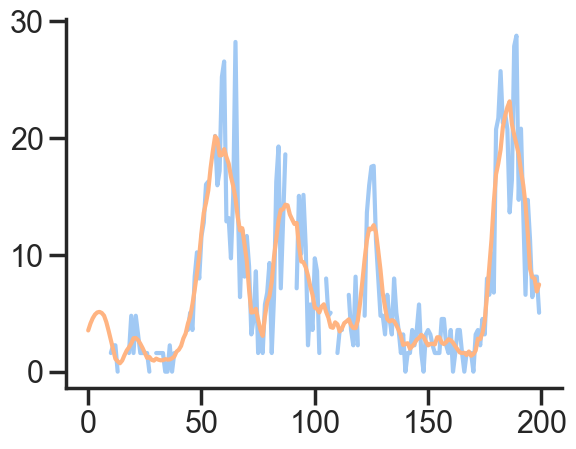

In [839]:
plt.plot(tmp_dvt.loc[:,'lin_vel'][:200])
plt.plot(tmp_dvt.loc[:,'lin_vel_savgol'][:200])
# plt.plot(tmp_dvt.loc[:,'med_vel'][:100])

In [393]:
lin_vel_interp.size, tmp_dvt['lin_vel'].values.size

(14387, 14387)

## Process raw data

In [398]:
path = Path(r"z:\Data\Mice\VR\Alex\Head_restrainer\Results\SESSIONS_NOMODEL_GOODLFP")
file_ls = list(path.glob('**/*.mat'))
print(file_ls[:2])

[WindowsPath('z:/Data/Mice/VR/Alex/Head_restrainer/Results/SESSIONS_NOMODEL_GOODLFP/JA0144_20211207_lADN_h1_all_neurons.mat'), WindowsPath('z:/Data/Mice/VR/Alex/Head_restrainer/Results/SESSIONS_NOMODEL_GOODLFP/JA0153_20220126_lADN_h1_all_neurons.mat')]


In [399]:
data_dict = {}
for i in range(len(file_ls)):
    print (i, file_ls[i])
    data_dict[i] = mat73.loadmat(file_ls[i])

0 z:\Data\Mice\VR\Alex\Head_restrainer\Results\SESSIONS_NOMODEL_GOODLFP\JA0144_20211207_lADN_h1_all_neurons.mat
1 z:\Data\Mice\VR\Alex\Head_restrainer\Results\SESSIONS_NOMODEL_GOODLFP\JA0153_20220126_lADN_h1_all_neurons.mat
2 z:\Data\Mice\VR\Alex\Head_restrainer\Results\SESSIONS_NOMODEL_GOODLFP\JA0162_20220302_lADN_h1_all_neurons.mat
3 z:\Data\Mice\VR\Alex\Head_restrainer\Results\SESSIONS_NOMODEL_GOODLFP\JA0164_20220419_lADN_h2_all_neurons.mat
4 z:\Data\Mice\VR\Alex\Head_restrainer\Results\SESSIONS_NOMODEL_GOODLFP\JA0178_20220819_lADN_h2_all_neurons.mat
5 z:\Data\Mice\VR\Alex\Head_restrainer\Results\SESSIONS_NOMODEL_GOODLFP\JA0178_20220822_lADN_h2_all_neurons.mat
6 z:\Data\Mice\VR\Alex\Head_restrainer\Results\SESSIONS_NOMODEL_GOODLFP\JA0178_20220824_lADN_h1_all_neurons.mat
7 z:\Data\Mice\VR\Alex\Head_restrainer\Results\SESSIONS_NOMODEL_GOODLFP\JA0178_20220906_rADN_h2_all_neurons.mat
8 z:\Data\Mice\VR\Alex\Head_restrainer\Results\SESSIONS_NOMODEL_GOODLFP\JA0181_20220812_lADN_h2_all_neur

In [400]:
for i in range(10):
    print(file_ls[i].name.split('_')[1])

20211207
20220126
20220302
20220419
20220819
20220822
20220824
20220906
20220812
20220815


In [28]:
data_dict[i]['neurons']['dark1'][0]['LFP']

array([-1.49898136, -8.49846979, 11.74888519, ..., 19.90949317,
       15.34811066, 27.85502811])

### Load one file

In [27]:
path = r'z:\Data\Mice\VR\Alex\Head_restrainer\Results\JA0178_20220824__all_neurons.mat'
data_rec = mat73.loadmat(path)

AssertionError: z:\Data\Mice\VR\Alex\Head_restrainer\Results\JA0178_20220824__all_neurons.mat does not exist

In [128]:
data_rec['neurons'].keys(), data_rec['neurons']['light1'][0].keys(), len(data_rec['neurons']['dark1'])

(dict_keys(['QMatrix', 'acronym', 'animal_name', 'cids', 'dark1', 'darkHR1', 'date_name', 'depth', 'is_sua', 'label', 'light1', 'lightHR1', 'session_name', 'site']),
 dict_keys(['Az', 'LFP', 'Omega', 'cluster_spikes', 'p_val', 'r', 'sites', 'tunning', 'velocity', 'x_tunning']),
 2)

In [129]:
print(data_rec['neurons']['light1'][0]['LFP'])
print(data_rec['neurons']['lightHR1'][0]['LFP'])
print(data_rec['neurons']['dark1'][0]['LFP'])
print(data_rec['neurons']['darkHR1'][0]['LFP'])

[-15. -34. -36. ... -38. -33. -41.]
[-282. -164. -309. ...  -25.   58.   38.]
[-94. -81. -79. ...  52.  -2.  -1.]
[ 38.  64.  17. ... 149. 116.  69.]


In [183]:
d_hr_data.keys()

dict_keys(['20211212_JA0144_dark1', '20211212_JA0144_darkHR1', '20211212_JA0144_light1', '20211212_JA0144_lightHR1', '20220126_JA0153_dark1', '20220126_JA0153_darkHR1', '20220126_JA0153_light1', '20220126_JA0153_lightHR1', '20220209_JA0153_dark1', '20220209_JA0153_darkHR1', '20220209_JA0153_light1', '20220209_JA0153_lightHR1', '20220302_JA0162_dark1', '20220302_JA0162_darkHR1', '20220302_JA0162_light1', '20220302_JA0162_lightHR1', '20220419_JA0164_dark1', '20220419_JA0164_darkHR1', '20220419_JA0164_light1', '20220419_JA0164_lightHR1', '20220819_JA0178_dark1', '20220819_JA0178_darkHR1', '20220819_JA0178_light1', '20220819_JA0178_lightHR1', '20220822_JA0178_dark1', '20220822_JA0178_darkHR1', '20220822_JA0178_light1', '20220822_JA0178_lightHR1', '20220824_JA0178_dark1', '20220824_JA0178_darkHR1', '20220824_JA0178_light1', '20220824_JA0178_lightHR1', '20220906_JA0178_dark1', '20220906_JA0178_darkHR1', '20220906_JA0178_light1', '20220906_JA0178_lightHR1', '20220812_JA0181_dark1', '20220812_

In [182]:
df_dvt.rec_id.unique()

array(['20210420_JA0100_light1', '20210420_JA0100_dark1',
       '20210421_JA0100_light1', '20210421_JA0100_dark1',
       '20211207_JA0144_darkHR1', '20211207_JA0144_lightHR1',
       '20211207_JA0144_light1', '20211207_JA0144_dark1',
       '20220126_JA0153_light1', '20220126_JA0153_dark1',
       '20220126_JA0153_lightHR1', '20220126_JA0153_darkHR1',
       '20220302_JA0162_dark1', '20220302_JA0162_darkHR1',
       '20220302_JA0162_lightHR1', '20220302_JA0162_light1',
       '20220419_JA0164_darkHR1', '20220419_JA0164_lightHR1',
       '20220419_JA0164_dark1', '20220419_JA0164_light1',
       '20220426_JA0164_darkHR1', '20220426_JA0164_lightHR1',
       '20220426_JA0164_dark1', '20220426_JA0164_light1',
       '20220808_JA0179_darkHR1', '20220808_JA0179_light1',
       '20220808_JA0179_lightHR1', '20220815_JA0179_dark1',
       '20220815_JA0179_darkHR1', '20220815_JA0179_light1',
       '20220815_JA0179_lightHR1', '20220816_JA0179_dark1',
       '20220816_JA0179_darkHR1', '20220816_

In [510]:
d_hr_data = {}

In [418]:
d_hr_data.keys()

dict_keys([])

In [841]:
# data_tmp = data_rec['neurons']

binSize = 0.02
boxcar = np.ones(int(1/binSize))
trace_length = 480
edges = np.arange(0, trace_length + binSize, binSize)
cond_ls = ['dark1', 'darkHR1', 'light1', 'lightHR1']

for i in range(len(file_ls[:])):
    print(file_ls[i])
    data_tmp = data_dict[i]['neurons']
    if 'lightHR1' not in data_tmp.keys():
        continue
    #exp info
    cids = data_tmp['cids']
    animal_name = data_tmp['animal_name'][0]
        
    date_name = file_ls[i].name.split('_')[1]
    hem = file_ls[i].name.split('_')[2]
    ch_map = file_ls[i].name.split('_')[3]
    depth = data_tmp['depth']
    is_sua = (data_tmp['is_sua'])
    session_name = data_tmp['session_name'][0]
    site = data_tmp['site']
    label = data_tmp['label']
    rec_session = animal_name + '_' + date_name
 
    for cond in cond_ls:
        ls_arena, ls_tuning = [], []
        rec_id = date_name + '_' + animal_name + '_' + cond
#         if rec_id in d_hr_data.keys():
#             continue
#         d_hr_data[rec_id] = {}
#         d_hr_data[rec_id]['ephys'] = {}
#         d_hr_data[rec_id]['beh'] = {}
        
        print(rec_id)
        for idx, unit in enumerate(cids):

            tmp = data_tmp[cond][idx]
            this_depth = depth[idx]
            if this_depth.size > 1:
                this_depth = False
            hdc_flag, hd_model = False, False
            try:
                _ =  tmp['Az'].size
            except:
                print(f"None in {unit}")
                continue
                
            if tmp['cluster_spikes'].size < 100:
                print(f'<100 spks in {cond} {unit}')
                continue

            # arena tuning
#             try:
#                 bm = tmp['models']['bestmodel']
#             except:
#                 bm = -1
                
            r = tmp['r']
            p_val = tmp['p_val']
            if r > 0.3 and p_val < 0.05:
                hdc_flag = True
#             if bm == 4:
#                 hd_model = True
            cuid = str(cids[idx]) + '_' + rec_id
            tuning = tmp['tunning']
            x_tuning = tmp['x_tunning']
            block_tun = pd.DataFrame({'animal_name': animal_name, 'cids':cids[idx], 'date_name':date_name, 'cuid':cuid,
                          'is_sua':is_sua[idx],   'depth':this_depth, 'session_name':session_name, 'site':site[idx], 
                          'r':r, 'p_val':p_val, 'cids':cids[idx], 'tuning':tuning, 'x_tuning':x_tuning, 
                                  'condition': cond, 'rec_id': rec_id, 'hdc_flag':hdc_flag, 'rec_session':rec_session,
                                      'hem':hem, 'ch_map':ch_map,
                            })
            ls_tuning.append(block_tun)
        
            arena_vel = df_dvt[(df_dvt.rec_id == rec_id)]['lin_vel_savgol']
            arena_vel_res = samplerate.resample(arena_vel, 50 * 1.0 / 30, 'sinc_best')
        
            hist = 0
            # from 100 to 50hz
            yaw = tmp['Az']
            if yaw.size > 30000:
                yaw = yaw[::2]
            # 250 hz for 2nd batch, 50hz for 1st batch
            lfp = tmp['LFP']
            if lfp.size > yaw.size*2:
                lfp_dwn = lfp[::5][:yaw.size]
            else:
                lfp_dwn = lfp[:][:yaw.size]
            
            omega = tmp['Omega']
            hist, bins = np.histogram(tmp['cluster_spikes'], bins = edges)
            spd_arena = np.convolve(hist, boxcar, mode = 'same')
            n_samples =  yaw.size
            spd_arena, bins = spd_arena[:n_samples], bins[:n_samples]
            arena_vel_res = arena_vel_res[:n_samples]
            arena_vel_res = np.pad(arena_vel_res, (0, spd_arena.size - arena_vel_res.size), 'constant')
            
            # lin vel is over smooth from fit_glm, so I use recompute from dvt files 
#             matlab_lin_speed = tmp['velocity']/100
            
            tmp_df = pd.DataFrame({'animal_name': animal_name, 'cids':cids[idx], 'date_name':date_name, 
                                  'is_sua':is_sua[idx], 'depth':this_depth, 'cuid':cuid, 'hem':hem, 'ch_map':ch_map,
                                'session_name':session_name, 'site':site[idx], 'rec_id':rec_id,
                                 'condition': cond, 'hz': spd_arena, 'times': bins[:], 'lfp':lfp_dwn,
                                 'hdc_flag':hdc_flag, 'rec_session':rec_session
                                    })
            ls_arena.append(tmp_df)
            break
        ephys_df = pd.concat(ls_arena)
        tuning_df = pd.concat(ls_tuning)
        beh_df = pd.DataFrame({'animal_name': animal_name,  'date_name':date_name, 'hem':hem, 'ch_map':ch_map,
                  'rec_id':rec_id, 'condition': cond, 'times': bins[:], 'yaw':yaw, 
                  'omega':omega, 'lin_vel': arena_vel_res, 'rec_session':rec_session
                    })
                
#         d_hr_data[rec_id]['ephys'] = ephys_df
        d_hr_data[rec_id]['beh'] = beh_df
#         d_hr_data[rec_id]['tuning'] = tuning_df
    
# df_tmp_tun = pd.concat(ls_tuning)
# df_tmp_ephys = pd.concat(ls_arena)

# df_hr_master_2 = pd.concat(ls_arena)
# df_hr_tuning_2 = pd.concat(ls_tuning)
# df_hr_master_2.head()

# df_hr_master = pd.concat(ls_arena)
# df_hr_tuning = pd.concat(ls_tuning)
# df_hr_master.head()

z:\Data\Mice\VR\Alex\Head_restrainer\Results\SESSIONS_NOMODEL_GOODLFP\JA0144_20211207_lADN_h1_all_neurons.mat
20211207_JA0144_dark1
20211207_JA0144_darkHR1
20211207_JA0144_light1
20211207_JA0144_lightHR1
z:\Data\Mice\VR\Alex\Head_restrainer\Results\SESSIONS_NOMODEL_GOODLFP\JA0153_20220126_lADN_h1_all_neurons.mat
20220126_JA0153_dark1
20220126_JA0153_darkHR1
<100 spks in darkHR1 2.0
<100 spks in darkHR1 3.0
20220126_JA0153_light1
20220126_JA0153_lightHR1
<100 spks in lightHR1 2.0
<100 spks in lightHR1 3.0
<100 spks in lightHR1 9.0
z:\Data\Mice\VR\Alex\Head_restrainer\Results\SESSIONS_NOMODEL_GOODLFP\JA0162_20220302_lADN_h1_all_neurons.mat
20220302_JA0162_dark1
20220302_JA0162_darkHR1
20220302_JA0162_light1
20220302_JA0162_lightHR1
z:\Data\Mice\VR\Alex\Head_restrainer\Results\SESSIONS_NOMODEL_GOODLFP\JA0164_20220419_lADN_h2_all_neurons.mat
20220419_JA0164_dark1
20220419_JA0164_darkHR1
20220419_JA0164_light1
20220419_JA0164_lightHR1
z:\Data\Mice\VR\Alex\Head_restrainer\Results\SESSIONS_NO

,animal_name,cids,date_name,is_sua,depth,cuid,hem,ch_map,session_name,site,rec_id,condition,hz,times,lfp,hdc_flag,rec_session
0,JA0144,0.0,20211207,1.0,False,0.0_20211207_JA0144_dark1,lADN,h1,001,88,20211207_JA0144_dark1,dark1,20.0,0.00,-43.510810,False,JA0144_20211207
1,JA0144,0.0,20211207,1.0,False,0.0_20211207_JA0144_dark1,lADN,h1,001,88,20211207_JA0144_dark1,dark1,21.0,0.02,-191.480190,False,JA0144_20211207
2,JA0144,0.0,20211207,1.0,False,0.0_20211207_JA0144_dark1,lADN,h1,001,88,20211207_JA0144_dark1,dark1,21.0,0.04,-69.425906,False,JA0144_20211207
3,JA0144,0.0,20211207,1.0,False,0.0_20211207_JA0144_dark1,lADN,h1,001,88,20211207_JA0144_dark1,dark1,22.0,0.06,223.288240,False,JA0144_20211207
4,JA0144,0.0,20211207,1.0,False,0.0_20211207_JA0144_dark1,lADN,h1,001,88,20211207_JA0144_dark1,dark1,25.0,0.08,289.989786,False,JA0144_20211207
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23995,JA0144,103.0,20211207,0.0,False,103.0_20211207_JA0144_dark1,lADN,h1,001,44,20211207_JA0144_dark1,dark1,1.0,479.90,-41.158844,False,JA0144_20211207
23996,JA0144,103.0,20211207,0.0,False,103.0_20211207_JA0144_dark1,lADN,h1,001,44,20211207_JA0144_dark1,dark1,1.0,479.92,-25.612050,False,JA0144_20211207
23997,JA0144,103.0,20211207,0.0,False,103.0_20211207_JA0144_dark1,lADN,h1,001,44,20211207_JA0144_dark1,dark1,1.0,479.94,20.131250,False,JA0144_20211207
23998,JA0144,103.0,20211207,0.0,False,103.0_20211207_JA0144_dark1,lADN,h1,001,44,20211207_JA0144_dark1,dark1,1.0,479.96,51.963446,False,JA0144_20211207


In [313]:
spd_arena.size, lfp.size, lfp_dwn.size, arena_vel_res.size

(24000, 24000, 24000, 24000)

In [1031]:
# with open('d_hr_data.p', 'wb') as handle:
#     pickle.dump(d_hr_data, handle, protocol=pickle.HIGHEST_PROTOCOL)

In [23]:
# df_hr_master_2.to_pickle('df_hr_master_b2.pkl')
# df_hr_tuning_2.to_pickle('df_hr_tuning_b2.pkl')

In [440]:
df_hr_master = pd.concat([df_hr_master_1, df_hr_master_2])
df_hr_master.head()

,animal_name,cids,date_name,is_sua,acronym,bm,session_name,site,rec_id,condition,...,times,yaw,lfp,omega,vel,hd_model,hdc_flag,depth,cuid,rec_session
0,JA0144,0.0,20211212,1.0,NaN,0.0,001,88,20211212_JA0144_dark1,dark1,...,0.00,-132.0,-43.510810,-100.000000,26.020397,False,False,NaN,NaN,NaN
1,JA0144,0.0,20211212,1.0,NaN,0.0,001,88,20211212_JA0144_dark1,dark1,...,0.02,-132.0,-191.480190,-100.000000,29.655931,False,False,NaN,NaN,NaN
2,JA0144,0.0,20211212,1.0,NaN,0.0,001,88,20211212_JA0144_dark1,dark1,...,0.04,-127.0,-69.425906,-114.583333,25.184610,False,False,NaN,NaN,NaN
3,JA0144,0.0,20211212,1.0,NaN,0.0,001,88,20211212_JA0144_dark1,dark1,...,0.06,-127.0,223.288240,-117.307692,25.026758,False,False,NaN,NaN,NaN
4,JA0144,0.0,20211212,1.0,NaN,0.0,001,88,20211212_JA0144_dark1,dark1,...,0.08,-132.0,289.989786,-119.642857,27.647388,False,False,NaN,NaN,NaN


### Load data into df

In [414]:
# ls_arena, ls_tuning = [], []
# binSize = 0.02
# boxcar = np.ones(int(1/binSize))
# trace_length = 480
# edges = np.arange(0, trace_length + binSize, binSize)
# cond_ls = ['dark1', 'darkHR1', 'light1', 'lightHR1']

# for i in range(len(file_ls[:])):
#     if 'lightHR1' not in data_dict[i]['neurons'].keys():
#         continue
#     print(file_ls[i])
#     data_tmp = data_dict[i]['neurons']
#     #exp info
#     cids = data_tmp['cids']
#     animal_name = data_tmp['animal_name'][i]
#     cids = data_tmp['cids']
#     date_name = data_tmp['date_name'][i]
#     depth = data_tmp['depth']
#     is_sua = (data_tmp['is_sua'])
#     session_name = data_tmp['session_name'][i]
#     site = data_tmp['site']
#     label = data_tmp['label']
    

#     for cond in cond_ls:
#         rec_id = date_name + '_' + animal_name + '_' + cond
#         for idx, unit in enumerate(cids):
#             hdc_flag, hd_model = False, False
#             if type(label[idx]) != str:
#                 acronym = np.nan
#             else:
#                 acronym = label[idx]
#             try:
#                 bm = data_dict[i]['neurons'][cond][idx]['models']['bestmodel']
#             except:
#                 bm = -1
            
#             tmp = data_tmp[cond][idx]
#             try:
#                 _ =  tmp['Az'].size
#             except:
#                 print(f"None in {unit}")
#                 continue
                
#             if tmp['cluster_spikes'].size < 100:
#                 print(f'<100 spks in {cond} {unit}')
#                 continue

#             # arena tuning
#             r = tmp['r']
#             p_val = tmp['p_val']
#             if r > 0.3 and p_val < 0.05:
#                 hdc_flag = True
#             if bm == 4:
#                 hd_model = True
#             tuning = tmp['tunning']
#             x_tuning = tmp['x_tunning']
#             block_tun = pd.DataFrame({'animal_name': animal_name, 'cids':cids[idx], 'date_name':date_name, 
#                            'is_sua':is_sua[idx], 'acronym': acronym, 'bm': bm, 'acronym':acronym, 'hdc_flag':hdc_flag,
#                             'session_name':session_name, 'site':site[idx], 'r':r, 'p_val':p_val, 'cids':cids[idx],
#                           'tuning':tuning, 'x_tuning':x_tuning, 'condition': cond, 'rec_id': rec_id, 'hd_model': hd_model                 
#                             })
#             ls_tuning.append(block_tun)


#             tmp_speed = df_dvt[(df_dvt.date_name == date_name) & (df_dvt.condition == cond)]
#             arena_vel = tmp_speed.med_vel.fillna(method='ffill').fillna(method='bfill')
#             arena_vel_res = samplerate.resample(arena_vel, 50 * 1.0 / 30, 'sinc_best')/9.4 # pix to cm
        
#             hist = 0
#             yaw = tmp['Az']
#             lfp = tmp['LFP']
#             omega = tmp['Omega']
#             hist, bins = np.histogram(tmp['cluster_spikes'], bins = edges)
#             spd_arena = np.convolve(hist, boxcar, mode = 'same')
#             n_samples =  yaw.size
#             spd_arena, bins = spd_arena[:n_samples], bins[:n_samples]
#             arena_vel_res = arena_vel_res[:n_samples]
#             arena_vel_res = np.pad(arena_vel_res, (0, spd_arena.size - arena_vel_res.size), 'constant')
# #             lin_speed = tmp['velocity']/100
#             block_l1 = pd.DataFrame({'animal_name': animal_name, 'cids':cids[idx], 'date_name':date_name, 
#                           'is_sua':is_sua[idx], 'acronym': acronym, 'cids':cids[idx], 'bm': bm,
#                         'session_name':session_name, 'site':site[idx], 'rec_id':rec_id,
#                          'condition': cond, 'hz': spd_arena, 'times': bins[:], 'yaw':yaw, 
#                          'lfp':lfp, 'omega':omega, 'vel': arena_vel_res, 'hd_model': hd_model, 'hdc_flag':hdc_flag
#                                     })
#             ls_arena.append(block_l1)
    
# df_hr_master = pd.concat(ls_arena)
# df_hr_tuning = pd.concat(ls_tuning)
# df_hr_master.head()

y:\Data\Mice\VR\Janna\RESULTS_ADN_HD_CELLS\SESSIONS\004\JA0144_20211212_001_all_neurons.mat
<100 spks in dark1 18.0
<100 spks in dark1 59.0
<100 spks in dark1 65.0
None in 69.0
<100 spks in dark1 75.0
<100 spks in dark1 84.0
<100 spks in dark1 89.0
<100 spks in dark1 99.0
<100 spks in darkHR1 18.0
<100 spks in darkHR1 60.0
<100 spks in darkHR1 65.0
None in 69.0
<100 spks in darkHR1 71.0
<100 spks in darkHR1 73.0
<100 spks in darkHR1 75.0
None in 84.0
<100 spks in darkHR1 89.0
<100 spks in darkHR1 99.0
<100 spks in light1 60.0
<100 spks in light1 65.0
<100 spks in light1 69.0
<100 spks in light1 84.0
<100 spks in light1 99.0
<100 spks in lightHR1 65.0
<100 spks in lightHR1 69.0
<100 spks in lightHR1 75.0
<100 spks in lightHR1 84.0
<100 spks in lightHR1 89.0
<100 spks in lightHR1 99.0
y:\Data\Mice\VR\Janna\RESULTS_ADN_HD_CELLS\SESSIONS\005\JA0153_20220209_001_all_neurons.mat
<100 spks in dark1 80.0
<100 spks in dark1 86.0
None in 207.0
<100 spks in dark1 269.0
<100 spks in dark1 290.0
<1

<100 spks in lightHR1 196.0


,animal_name,cids,date_name,is_sua,acronym,bm,session_name,site,rec_id,condition,hz,times,yaw,lfp,omega,vel,hd_model,hdc_flag
0,JA0144,0.0,20211212,1.0,NaN,0.0,001,88,20211212_JA0144_dark1,dark1,20.0,0.00,-132.0,-43.510810,-100.000000,26.020397,False,False
1,JA0144,0.0,20211212,1.0,NaN,0.0,001,88,20211212_JA0144_dark1,dark1,21.0,0.02,-132.0,-191.480190,-100.000000,29.655931,False,False
2,JA0144,0.0,20211212,1.0,NaN,0.0,001,88,20211212_JA0144_dark1,dark1,21.0,0.04,-127.0,-69.425906,-114.583333,25.184610,False,False
3,JA0144,0.0,20211212,1.0,NaN,0.0,001,88,20211212_JA0144_dark1,dark1,22.0,0.06,-127.0,223.288240,-117.307692,25.026758,False,False
4,JA0144,0.0,20211212,1.0,NaN,0.0,001,88,20211212_JA0144_dark1,dark1,25.0,0.08,-132.0,289.989786,-119.642857,27.647388,False,False


In [482]:
df_hr_tuning.condition.unique()

array(['dark1', 'darkHR1', 'light1', 'lightHR1'], dtype=object)

In [769]:
df_hr_master.head()

,animal_name,cids,date_name,is_sua,acronym,bm,session_name,site,rec_id,condition,hz,times,yaw,lfp,omega,vel,hd_model,hdc_flag
0,JA0144,0.0,20211212,1.0,NaN,0.0,001,88,20211212_JA0144_dark1,dark1,20.0,0.00,-132.0,-43.510810,-100.000000,26.020397,False,False
1,JA0144,0.0,20211212,1.0,NaN,0.0,001,88,20211212_JA0144_dark1,dark1,21.0,0.02,-132.0,-191.480190,-100.000000,29.655931,False,False
2,JA0144,0.0,20211212,1.0,NaN,0.0,001,88,20211212_JA0144_dark1,dark1,21.0,0.04,-127.0,-69.425906,-114.583333,25.184610,False,False
3,JA0144,0.0,20211212,1.0,NaN,0.0,001,88,20211212_JA0144_dark1,dark1,22.0,0.06,-127.0,223.288240,-117.307692,25.026758,False,False
4,JA0144,0.0,20211212,1.0,NaN,0.0,001,88,20211212_JA0144_dark1,dark1,25.0,0.08,-132.0,289.989786,-119.642857,27.647388,False,False


y:\Data\Mice\VR\Janna\RESULTS_ADN_HD_CELLS\SESSIONS\001\JA0100_20210420_001_all_neurons.mat
y:\Data\Mice\VR\Janna\RESULTS_ADN_HD_CELLS\SESSIONS\002\JA0100_20210421_001_all_neurons.mat
y:\Data\Mice\VR\Janna\RESULTS_ADN_HD_CELLS\SESSIONS\003\JA0104_20210427_001_all_neurons.mat
y:\Data\Mice\VR\Janna\RESULTS_ADN_HD_CELLS\SESSIONS\004\JA0144_20211212_001_all_neurons.mat


In [28]:
d_hr_data.keys()

dict_keys(['20211212_JA0144_dark1', '20211212_JA0144_darkHR1', '20211212_JA0144_light1', '20211212_JA0144_lightHR1', '20220126_JA0153_dark1', '20220126_JA0153_darkHR1', '20220126_JA0153_light1', '20220126_JA0153_lightHR1', '20220209_JA0153_dark1', '20220209_JA0153_darkHR1', '20220209_JA0153_light1', '20220209_JA0153_lightHR1', '20220302_JA0162_dark1', '20220302_JA0162_darkHR1', '20220302_JA0162_light1', '20220302_JA0162_lightHR1', '20220419_JA0164_dark1', '20220419_JA0164_darkHR1', '20220419_JA0164_light1', '20220419_JA0164_lightHR1', '20220819_JA0178_dark1', '20220819_JA0178_darkHR1', '20220819_JA0178_light1', '20220819_JA0178_lightHR1', '20220822_JA0178_dark1', '20220822_JA0178_darkHR1', '20220822_JA0178_light1', '20220822_JA0178_lightHR1', '20220824_JA0178_dark1', '20220824_JA0178_darkHR1', '20220824_JA0178_light1', '20220824_JA0178_lightHR1', '20220906_JA0178_dark1', '20220906_JA0178_darkHR1', '20220906_JA0178_light1', '20220906_JA0178_lightHR1', '20220812_JA0181_dark1', '20220812_

In [26]:
d_hr_data['20211212_JA0144_light1']['ephys']

,animal_name,cids,date_name,is_sua,depth,cuid,session_name,site,rec_id,condition,hz,times,lfp,hdc_flag,rec_session
0,JA0144,0.0,20211212,1.0,False,0.0_20211212_JA0144_light1,001,88,20211212_JA0144_light1,light1,2.0,0.00,-13.635219,False,JA0144_20211212
1,JA0144,0.0,20211212,1.0,False,0.0_20211212_JA0144_light1,001,88,20211212_JA0144_light1,light1,2.0,0.02,-58.236623,False,JA0144_20211212
2,JA0144,0.0,20211212,1.0,False,0.0_20211212_JA0144_light1,001,88,20211212_JA0144_light1,light1,2.0,0.04,-48.965603,False,JA0144_20211212
3,JA0144,0.0,20211212,1.0,False,0.0_20211212_JA0144_light1,001,88,20211212_JA0144_light1,light1,2.0,0.06,26.225148,False,JA0144_20211212
4,JA0144,0.0,20211212,1.0,False,0.0_20211212_JA0144_light1,001,88,20211212_JA0144_light1,light1,2.0,0.08,132.100921,False,JA0144_20211212
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23995,JA0144,103.0,20211212,0.0,False,103.0_20211212_JA0144_light1,001,44,20211212_JA0144_light1,light1,1.0,479.90,-13.235274,False,JA0144_20211212
23996,JA0144,103.0,20211212,0.0,False,103.0_20211212_JA0144_light1,001,44,20211212_JA0144_light1,light1,1.0,479.92,6.912814,False,JA0144_20211212
23997,JA0144,103.0,20211212,0.0,False,103.0_20211212_JA0144_light1,001,44,20211212_JA0144_light1,light1,1.0,479.94,34.895030,False,JA0144_20211212
23998,JA0144,103.0,20211212,0.0,False,103.0_20211212_JA0144_light1,001,44,20211212_JA0144_light1,light1,1.0,479.96,58.631039,False,JA0144_20211212


In [130]:
df_tuning.loc[0].groupby(['date_name', 'condition', 'hd']).cids.count().reset_index()

,date_name,condition,hd,cids
0,20210420,dark,False,87
1,20210420,dark,True,28
2,20210420,light1,False,85
3,20210420,light1,True,30
4,20210421,dark,False,2
5,20210421,dark,True,10
6,20210421,light1,False,2
7,20210421,light1,True,10
8,20210427,dark,False,95
9,20210427,dark,True,26


### Load HR data

In [28]:
# ls_tuning = []
# ls_arena = []
# ls_frun = []

# binSize = 0.02
# boxcar = np.ones(int(1/binSize))
# trace_length = 480
# edges = np.arange(0, trace_length + binSize, binSize)

# for i in range(len(file_ls[:])):
#     if 'lightHR1' in data_dict[i]['neurons'].keys() or 'darkHR1' in data_dict[i]['neurons'].keys():
        
#         print(file_ls[i])
#         # meta info
#         animal_name = data_dict[i]['neurons']['animal_name'][0]
#         cids = (data_dict[i]['neurons']['cids'])
#         date_name = data_dict[i]['neurons']['date_name'][0]
#         depth = data_dict[i]['neurons']['depth']
#         is_sua = (data_dict[i]['neurons']['is_sua'])
#         session_name = data_dict[i]['neurons']['session_name'][0]
#         site = (data_dict[i]['neurons']['site'])
#         label = data_dict[i]['neurons']['label']
        
#         if 'is_critical' in data_dict[i]['neurons'].keys():
#             is_critical = data_dict[i]['neurons']['is_critical']
#         else:
#             is_critical = data_dict[i]['neurons']['is_model']

#         for idx, unit in enumerate(cids):
#     #         print(idx, unit, is_sua[idx])
# #             if is_sua[idx] == 0:
# #                 continue
#             if type(label[idx]) != str:
#                 acronym = np.nan
#             else:
#                 acronym = label[idx]
#             bm_light = data_dict[i]['neurons']['light1'][idx]['models']['bestmodel']
#             try:
#                 bm_dark = data_dict[i]['neurons']['dark1'][idx]['models']['bestmodel']
#             except:
#                 bm_dark = np.nan
            
#             # exp conditions
#             tmp = data_dict[i]['neurons']['lightHR1'][idx]
#             tmp_dark = data_dict[i]['neurons']['darkHR1'][idx]
            
#             try:
#                 _, _ =  tmp['Az'].size, tmp_dark['Az'].size
#             except:
#                 print(f"None in {unit}")
#                 continue
    

#             if tmp['cluster_spikes'].size < 100 or tmp_dark['cluster_spikes'].size < 100:
#                 print(f'<100 spks in {unit}')
#                 continue

#             # arena tuning
#             r = tmp['r']
#             p_val = tmp['p_val']
#             tuning = tmp['tunning']
#             x_tuning = tmp['x_tunning']
#             block_tun = pd.DataFrame({'animal_name': animal_name, 'cids':cids[idx], 'date_name':date_name, 
#                                        'is_sua':is_sua[idx], 'acronym': acronym, 'bm': bm_light,
#                                     'session_name':session_name, 'site':site[idx], 'r':r, 'p_val':p_val, 'cids':cids[idx],
#                                   'tuning':tuning, 'x_tuning':x_tuning, 'condition': 'lightHR1', 'is_critical': is_critical[idx]                  
#                             })
#             ls_tuning.append(block_tun)

#             # arena dark tuning
#             r_dark = tmp_dark['r']
#             p_val_dark = tmp_dark['p_val']
#             tuning = tmp_dark['tunning']
#             x_tuning = tmp_dark['x_tunning']
#             block_tun_dark = pd.DataFrame({'animal_name': animal_name, 'cids':cids[idx], 'date_name':date_name, 
#                                             'is_sua':is_sua[idx], 'acronym': acronym, 'bm': bm_dark,
#                 'session_name':session_name, 'site':site[idx], 'r':r_dark, 'p_val':p_val_dark, 'tuning':tuning, 'cids':cids[idx],
#                                            'x_tuning':x_tuning, 'condition': 'darkHR1',  'is_critical': is_critical[idx] 
#                             })
#             ls_tuning.append(block_tun_dark)

#             # arena light spikes
#             tmp_speed = df_dvt[(df_dvt.date_name == date_name) & (df_dvt.condition == 'light_hr')]
#             arena_vel = tmp_speed.med_vel.fillna(method='ffill').fillna(method='bfill')
#             arena_vel_res = samplerate.resample(arena_vel, 50 * 1.0 / 30, 'sinc_best')/9.4 # pix to cm


#             hist = 0
#             yaw = tmp['Az']
#             lfp = tmp['LFP']
#             omega = tmp['Omega']
#             hist, bins = np.histogram(tmp['cluster_spikes'], bins = edges)
#             n_samples =  yaw.size
#             hist, bins = hist[:n_samples], bins[:n_samples]
#             arena_vel_res = arena_vel_res[:n_samples]
#             spd_arena = np.convolve(hist, boxcar, mode = 'same')
#             arena_vel_res = np.pad(arena_vel_res, (0, spd_arena.size - arena_vel_res.size), 'constant')
#             block_l1 = pd.DataFrame({'animal_name': animal_name, 'cids':cids[idx], 'date_name':date_name, 
#                                       'is_sua':is_sua[idx], 'acronym': acronym, 'cids':cids[idx], 'bm': bm_light,
#                                     'session_name':session_name, 'site':site[idx], 'r':r, 'p_val':p_val, 
#                                      'condition': 'lightHR1', 'hz': spd_arena, 'times': bins[:], 'yaw':yaw, 
#                                      'lfp':lfp, 'omega':omega, 'vel': arena_vel_res, 'is_critical': is_critical[idx] 
#                                     })
#             ls_arena.append(block_l1)

#             # arena dark spikes
#             tmp_speed_dark = df_dvt[(df_dvt.date_name == date_name) & (df_dvt.condition == 'dark_hr')]
#             arena_vel = tmp_speed_dark.med_vel.fillna(method='ffill').fillna(method='bfill')
#             arena_vel_res = samplerate.resample(arena_vel, 50 * 1.0 / 30, 'sinc_best')/9.4 # pix to cm

#             hist = 0
#             yaw = tmp_dark['Az']
#             lfp = tmp_dark['LFP']
#             omega = tmp_dark['Omega']
#             hist, bins = np.histogram(tmp_dark['cluster_spikes'], bins = edges)
#             n_samples =  yaw.size
#             hist, bins = hist[:n_samples], bins[:n_samples]
#             arena_vel_res = arena_vel_res[:n_samples]
#             spd_arena = np.convolve(hist, boxcar, mode = 'same')
#             arena_vel_res = np.pad(arena_vel_res, (0, spd_arena.size - arena_vel_res.size), 'constant')
#             block_d1 = pd.DataFrame({'animal_name': animal_name, 'cids':cids[idx], 'date_name':date_name, 
#                                     'is_sua':is_sua[idx], 'acronym': acronym, 'bm': bm_dark,
#                                     'session_name':session_name, 'site':site[idx], 'r':r_dark, 'p_val':p_val_dark, 
#                                      'condition': 'darkHR1',
#                                     'hz': spd_arena, 'times': bins[:], 'yaw':yaw, 'lfp':lfp, 'cids':cids[idx],
#                                      'omega':omega, 'vel': arena_vel_res, 'is_critical': is_critical[idx] 
#                                     })
#             ls_arena.append(block_d1)



# df_hr_tuning = pd.concat(ls_tuning)
# df_hr_arena = pd.concat(ls_arena)
# df_hr_arena.head()

y:\Data\Mice\VR\Janna\RESULTS_ADN_HD_CELLS\SESSIONS\004\JA0144_20211212_001_all_neurons.mat
<100 spks in 18.0
<100 spks in 60.0
<100 spks in 65.0
None in 69.0
<100 spks in 71.0
<100 spks in 73.0
<100 spks in 75.0
None in 84.0
<100 spks in 89.0
<100 spks in 99.0
y:\Data\Mice\VR\Janna\RESULTS_ADN_HD_CELLS\SESSIONS\005\JA0153_20220209_001_all_neurons.mat
<100 spks in 64.0
<100 spks in 143.0
None in 259.0
<100 spks in 269.0
<100 spks in 281.0
<100 spks in 282.0
<100 spks in 293.0
y:\Data\Mice\VR\Janna\RESULTS_ADN_HD_CELLS\SESSIONS\006\JA0162_20220302_001_all_neurons.mat
<100 spks in 28.0
None in 37.0
<100 spks in 44.0
<100 spks in 55.0
<100 spks in 56.0
<100 spks in 59.0
<100 spks in 74.0
<100 spks in 78.0
<100 spks in 80.0
<100 spks in 98.0
<100 spks in 108.0
<100 spks in 119.0
<100 spks in 124.0
None in 125.0
<100 spks in 147.0
<100 spks in 213.0
<100 spks in 215.0
<100 spks in 216.0
<100 spks in 218.0
<100 spks in 252.0
<100 spks in 264.0
<100 spks in 271.0
<100 spks in 275.0
<100 spks 

,animal_name,cids,date_name,is_sua,acronym,bm,session_name,site,r,p_val,condition,hz,times,yaw,lfp,omega,vel,is_critical
0,JA0144,0.0,20211212,1.0,NaN,0.0,001,88,0.300874,0.08,lightHR1,0.0,0.00,-129.0,-13.635219,-15.000000,-0.186153,0.0
1,JA0144,0.0,20211212,1.0,NaN,0.0,001,88,0.300874,0.08,lightHR1,0.0,0.02,-129.0,-58.236623,-15.000000,-0.451826,0.0
2,JA0144,0.0,20211212,1.0,NaN,0.0,001,88,0.300874,0.08,lightHR1,0.0,0.04,-127.0,-48.965603,-13.636364,0.555326,0.0
3,JA0144,0.0,20211212,1.0,NaN,0.0,001,88,0.300874,0.08,lightHR1,0.0,0.06,-127.0,26.225148,-13.636364,0.382275,0.0
4,JA0144,0.0,20211212,1.0,NaN,0.0,001,88,0.300874,0.08,lightHR1,0.0,0.08,-127.0,132.100921,-13.636364,-1.336164,0.0


In [ ]:
plt.plot(arena_vel)

In [121]:
spd_arena.size, yaw.size, lfp.size, arena_vel_res.size

(23700, 23700, 23700, 23978, 14387)

In [59]:
bins.size

24001

In [79]:
df_hr_arena.head()

,animal_name,cids,date_name,is_sua,acronym,bm,session_name,site,r,p_val,condition,hz,times,yaw,lfp,omega,vel,is_critical
0,JA0144,0.0,20211212,1.0,NaN,0.0,001,88,0.215167,0.842,light_hr,0.0,0.00,-129.0,-13.635219,-15.000000,-0.186153,0.0
1,JA0144,0.0,20211212,1.0,NaN,0.0,001,88,0.215167,0.842,light_hr,0.0,0.02,-129.0,-58.236623,-15.000000,-0.451826,0.0
2,JA0144,0.0,20211212,1.0,NaN,0.0,001,88,0.215167,0.842,light_hr,0.0,0.04,-127.0,-48.965603,-13.636364,0.555326,0.0
3,JA0144,0.0,20211212,1.0,NaN,0.0,001,88,0.215167,0.842,light_hr,0.0,0.06,-127.0,26.225148,-13.636364,0.382275,0.0
4,JA0144,0.0,20211212,1.0,NaN,0.0,001,88,0.215167,0.842,light_hr,0.0,0.08,-127.0,132.100921,-13.636364,-1.336164,0.0


KeyError: 'data'

In [21]:
df_hr_tuning.head()

NameError: name 'df_hr_tuning' is not defined

In [21]:
tmp_df = df_hr_tuning_master[(df_hr_tuning_master.hdc_flag == True) 
         & (df_hr_tuning_master.x_tuning > 339)].groupby(['animal_name', 'date_name', 'condition']).cids.count()
with pd.option_context('display.max_rows', None,):
    print(tmp_df)


animal_name  date_name  condition
JA0144       20211212   dark1         8
                        darkHR1       6
                        light1        8
                        lightHR1      6
JA0153       20220209   dark1         8
                        darkHR1      16
                        light1       15
                        lightHR1     18
JA0162       20220302   dark1         4
                        darkHR1       1
                        light1        8
                        lightHR1      9
JA0164       20220419   dark1         7
                        darkHR1       6
                        light1        8
                        lightHR1     10
             20220426   dark1        18
                        darkHR1       3
                        light1       16
                        lightHR1      2
JA0178       08_29      darkHR1       5
                        light1        5
                        lightHR1      5
             20220819   dark1        29
      

In [661]:
# df_tuning.to_pickle("df_tuning.pkl")  
# df_arena.to_pickle("df_arena.pkl")  
# df_frun.to_pickle("df_frun.pkl")  

## Plot behavior

In [18]:
d_hr_data.keys()

dict_keys(['20211207_JA0144_dark1', '20211207_JA0144_darkHR1', '20211207_JA0144_light1', '20211207_JA0144_lightHR1', '20220126_JA0153_dark1', '20220126_JA0153_darkHR1', '20220126_JA0153_light1', '20220126_JA0153_lightHR1', '20220302_JA0162_dark1', '20220302_JA0162_darkHR1', '20220302_JA0162_light1', '20220302_JA0162_lightHR1', '20220419_JA0164_dark1', '20220419_JA0164_darkHR1', '20220419_JA0164_light1', '20220419_JA0164_lightHR1', '20220819_JA0178_dark1', '20220819_JA0178_darkHR1', '20220819_JA0178_light1', '20220819_JA0178_lightHR1', '20220822_JA0178_dark1', '20220822_JA0178_darkHR1', '20220822_JA0178_light1', '20220822_JA0178_lightHR1', '20220824_JA0178_dark1', '20220824_JA0178_darkHR1', '20220824_JA0178_light1', '20220824_JA0178_lightHR1', '20220906_JA0178_dark1', '20220906_JA0178_darkHR1', '20220906_JA0178_light1', '20220906_JA0178_lightHR1', '20220812_JA0181_dark1', '20220812_JA0181_darkHR1', '20220812_JA0181_light1', '20220812_JA0181_lightHR1', '20220815_JA0181_dark1', '20220815_

In [25]:
angles = np.arange(0, 380, 20)

ls = []
for k in d_hr_data.keys():
    dts, animal_name, cond = k.split('_')[-3:]
    rec_session = animal_name + '_' + dts
    tmp = d_hr_data[k]['beh']
    print (k)
 
    # to 0, 360 range
    yaw_sm = tmp['yaw'].values
    if np.min(yaw_sm) < 0:
        yaw_sm = yaw_sm + 180
    omega = tmp['omega'].values 
    dYaw = compute_dYaw(yaw_sm)
    # convert to deg/s, 50 HZ sampling rate
    ang_vel = dYaw*50
    lin_speed = tmp['lin_vel'].values
    
    stat_idx, run_idx = get_stat_run_epochs(lin_speed, window_size=25, speed_thr = 4)
    _, rot_idx = get_stat_run_epochs(ang_vel, window_size=25, speed_thr = 20)

    stat_rot_ratio = (np.intersect1d(stat_idx, rot_idx).size/stat_idx.size) 
    run_rot_ratio = (np.intersect1d(run_idx, rot_idx).size/run_idx.size) 

    occup, _ = np.histogram(yaw_sm, bins = angles)
    locom_ratio = run_idx.size/lin_speed.size
    # at least 5s
    az_occ = occup[occup > 100].size/occup.size
    if az_occ < 0.7:
        print ('not covered well')
#         sns.displot(yaw, bins = 18)
#         plt.show()
    tmp_df = pd.DataFrame({'az_occ': az_occ, 'locom_ratio':locom_ratio ,'rec_id': k, 'rec_session':rec_session,
                          'cond': cond, 'stat_rot_ratio': stat_rot_ratio, 'run_rot_ratio': run_rot_ratio}, index = [0])
    ls.append(tmp_df)
    
df_beh = pd.concat(ls)
df_beh.head()

20211207_JA0144_dark1
20211207_JA0144_darkHR1
not covered well
20211207_JA0144_light1
20211207_JA0144_lightHR1
20220126_JA0153_dark1
20220126_JA0153_darkHR1
20220126_JA0153_light1
20220126_JA0153_lightHR1
20220302_JA0162_dark1
20220302_JA0162_darkHR1
20220302_JA0162_light1
20220302_JA0162_lightHR1
20220419_JA0164_dark1
20220419_JA0164_darkHR1
20220419_JA0164_light1
20220419_JA0164_lightHR1
20220819_JA0178_dark1
20220819_JA0178_darkHR1
not covered well
20220819_JA0178_light1
20220819_JA0178_lightHR1
20220822_JA0178_dark1
20220822_JA0178_darkHR1
20220822_JA0178_light1
20220822_JA0178_lightHR1
20220824_JA0178_dark1
20220824_JA0178_darkHR1
20220824_JA0178_light1
20220824_JA0178_lightHR1
20220906_JA0178_dark1
20220906_JA0178_darkHR1
20220906_JA0178_light1
20220906_JA0178_lightHR1
20220812_JA0181_dark1
20220812_JA0181_darkHR1
20220812_JA0181_light1
20220812_JA0181_lightHR1
20220815_JA0181_dark1
20220815_JA0181_darkHR1
20220815_JA0181_light1
20220815_JA0181_lightHR1
20220818_JA0181_dark1
2022

,az_occ,locom_ratio,rec_id,rec_session,cond,stat_rot_ratio,run_rot_ratio
0,1.000000,0.782292,20211207_JA0144_dark1,JA0144_20211207,dark1,0.794258,0.992011
0,0.611111,0.086458,20211207_JA0144_darkHR1,JA0144_20211207,darkHR1,0.117446,0.963855
0,1.000000,0.908333,20211207_JA0144_light1,JA0144_20211207,light1,0.943182,0.963303
0,1.000000,0.222917,20211207_JA0144_lightHR1,JA0144_20211207,lightHR1,0.097855,0.901869
0,1.000000,0.703125,20220126_JA0153_dark1,JA0153_20220126,dark1,0.947368,0.989630


In [31]:
coi = [ 'light1', 'lightHR1']
good_beh_sess = df_beh[(df_beh.cond.isin(coi)) & (df_beh.az_occ > 0.8)].rec_session.unique()

(0.0, 1.1)

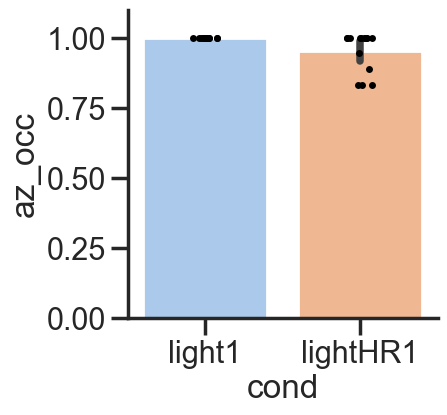

In [42]:
f, ax = plt.subplots(figsize = (4, 4))
coi = [ 'light1', 'lightHR1']
y = 'az_occ'
_inp_plot = df_beh[(df_beh.az_occ > 0.8) & (df_beh.cond.isin(coi))]

sns.stripplot(data = _inp_plot, x = 'cond', y = y, color = 'k')
sns.barplot(data = _inp_plot, x = 'cond', y = y, order = coi)

plt.ylim(0, 1.1)
# plt.savefig(f'bar_{y}_{coi}.pdf', transparent = True)


In [43]:
df_beh[(df_beh.cond == 'lightHR1') & (df_beh.az_occ > 0.8)]

,az_occ,locom_ratio,rec_id,rec_session,cond,stat_rot_ratio,run_rot_ratio
0,1.000000,0.222917,20211207_JA0144_lightHR1,JA0144_20211207,lightHR1,0.097855,0.901869
0,1.000000,0.490625,20220126_JA0153_lightHR1,JA0153_20220126,lightHR1,0.331288,0.985138
0,1.000000,0.307292,20220302_JA0162_lightHR1,JA0162_20220302,lightHR1,0.315789,0.983051
0,0.888889,0.362869,20220419_JA0164_lightHR1,JA0164_20220419,lightHR1,0.062914,0.305233
0,1.000000,0.145833,20220819_JA0178_lightHR1,JA0178_20220819,lightHR1,0.203659,1.000000
0,1.000000,0.445402,20220822_JA0178_lightHR1,JA0178_20220822,lightHR1,0.227979,0.580645
0,0.833333,0.104167,20220824_JA0178_lightHR1,JA0178_20220824,lightHR1,0.106977,1.000000
0,0.833333,0.077083,20220906_JA0178_lightHR1,JA0178_20220906,lightHR1,0.188488,1.000000
0,1.000000,0.191667,20220812_JA0181_lightHR1,JA0181_20220812,lightHR1,0.100515,0.994565
0,1.000000,0.172917,20220815_JA0181_lightHR1,JA0181_20220815,lightHR1,0.112091,1.000000


In [44]:
_inp_plot.groupby('cond')[y].describe()

,count,mean,std,min,25%,50%,75%,max
cond,,,,,,,,
light1,14.0,1.000000,0.000000,1.000000,1.000000,1.0,1.0,1.0
lightHR1,14.0,0.952381,0.071801,0.833333,0.902778,1.0,1.0,1.0


In [45]:
a1 = _inp_plot[_inp_plot.cond == coi[0]][y].values
b1 = _inp_plot[_inp_plot.cond == coi[1]][y].values
# c1 = _inp_plot[_inp_plot.cond == coi[2]][y].values

print(stats.mannwhitneyu(a1, b1))

14 14
MannwhitneyuResult(statistic=133.0, pvalue=0.017485833950010393)


In [199]:
df_hr_betti.head()

,rec_id,cond,dts,animal_name,az_occ,run,h1_bar,dec_err,stat_off_manifold,run_ratio
0,20211212_JA0144_dark1,dark1,20211212,JA0144,0.944444,stat,1.355,26.319,0.310460,0.751042
0,20211212_JA0144_dark1,dark1,20211212,JA0144,1.000000,locom,5.685,25.625,0.310460,0.751042
0,20211212_JA0144_darkHR1,darkHR1,20211212,JA0144,0.500000,stat,0.588,71.072,0.466364,0.083333
0,20211212_JA0144_darkHR1,darkHR1,20211212,JA0144,0.833333,locom,1.801,88.993,0.466364,0.083333
0,20211212_JA0144_light1,light1,20211212,JA0144,0.722222,stat,2.603,28.721,0.188764,0.907292


## Tuning curves

In [20]:
def bin_tuning_permute(yaw, fr):
    # yaw in deg, fr in hz
    n_sim = 500
    if np.min(yaw) < -1:
#         print('converto 10 0 360')
        yaw += 180
    ls_r = []
    hd_tuning = bin_tuning(yaw, fr)
    angles = hd_tuning[0]
    bin_fr = hd_tuning[1]
    r = circ_r(angles, bin_fr) 
    for i in range(n_sim):
        offset = int(np.floor(np.random.random()*yaw.size))
        yaw_fake = np.concatenate((yaw[offset:], yaw[:offset]))
        tun_fake = bin_tuning(yaw_fake, fr)
        angles = tun_fake[0]
        bin_fr_fake = tun_fake[1]
        r_fake = circ_r(angles, bin_fr_fake) 
#         print(r_fake)
        ls_r.append(r_fake)
#         print(i, r_fake)
    p_val = np.sum(r<ls_r)/n_sim
    return r, hd_tuning, p_val

def bin_tuning(yaw, sp_counts):
    out = np.zeros((2, 18))
    for i in range(18):
        bin_idx = [(yaw >= i*20) & (yaw < i*20 + 20)]
#         print(np.sum(bin_idx[0]))
        if len(bin_idx) > 0:
            total_count = np.nanmean(sp_counts[tuple(bin_idx)])
        else:
            total_count = 0
        out[1,i] = total_count
        out[0, i] = i*20
    return out

def circ_r(angle, fr):
    # angle [0 360]
    a = np.deg2rad(angle - 180)
    # compute weighted sum of cos and sin of angles
    r = np.nansum(fr*np.exp(1j*a))
    # obtain length 
    r = abs(r)/np.nansum(fr)
    return r

In [49]:
len(d_hr_data.keys())/4

14.0

### dPref direction

In [165]:
ls = []
for k in d_hr_data.keys():
    ls.append(d_hr_data[k]['tuning'])
df_hrtun_master = pd.concat(ls)
df_hrtun_master.head()

,animal_name,cids,date_name,cuid,is_sua,depth,session_name,site,r,p_val,tuning,x_tuning,condition,rec_id,hdc_flag,rec_session,hem,ch_map
0,JA0144,0.0,20211207,0.0_20211207_JA0144_dark1,1.0,0.0,001,88,0.082941,0.656,31.002028,3.0,dark1,20211207_JA0144_dark1,False,JA0144_20211207,lADN,h1
1,JA0144,0.0,20211207,0.0_20211207_JA0144_dark1,1.0,0.0,001,88,0.082941,0.656,26.494761,23.0,dark1,20211207_JA0144_dark1,False,JA0144_20211207,lADN,h1
2,JA0144,0.0,20211207,0.0_20211207_JA0144_dark1,1.0,0.0,001,88,0.082941,0.656,29.836700,43.0,dark1,20211207_JA0144_dark1,False,JA0144_20211207,lADN,h1
3,JA0144,0.0,20211207,0.0_20211207_JA0144_dark1,1.0,0.0,001,88,0.082941,0.656,25.480159,63.0,dark1,20211207_JA0144_dark1,False,JA0144_20211207,lADN,h1
4,JA0144,0.0,20211207,0.0_20211207_JA0144_dark1,1.0,0.0,001,88,0.082941,0.656,31.546377,83.0,dark1,20211207_JA0144_dark1,False,JA0144_20211207,lADN,h1


In [124]:
df_hrtun_run.head()

,hz,dir,cids,animal_name,r,p_val,rec_id,date_name,run,cond,rec_session,cuid,cond_run
0,0.302632,0.0,25.0,JA0144,0.351392,0.0,20211207_JA0144_dark1,20211207,stat,dark1,JA0144_20211207,25.0_20220829_MC038_lightHR1,dark1_stat
1,0.896024,20.0,25.0,JA0144,0.351392,0.0,20211207_JA0144_dark1,20211207,stat,dark1,JA0144_20211207,25.0_20220829_MC038_lightHR1,dark1_stat
2,1.610294,40.0,25.0,JA0144,0.351392,0.0,20211207_JA0144_dark1,20211207,stat,dark1,JA0144_20211207,25.0_20220829_MC038_lightHR1,dark1_stat
3,0.875433,60.0,25.0,JA0144,0.351392,0.0,20211207_JA0144_dark1,20211207,stat,dark1,JA0144_20211207,25.0_20220829_MC038_lightHR1,dark1_stat
4,0.877301,80.0,25.0,JA0144,0.351392,0.0,20211207_JA0144_dark1,20211207,stat,dark1,JA0144_20211207,25.0_20220829_MC038_lightHR1,dark1_stat


In [699]:
cond1 = 'light1'
cond2 = 'dark1'

data = df_hrtun_master
_inp = data[ (data.hdc_flag > 0)
#             &(df_tun_proc.rec_unit.isin(hdc_rec_units))
            & (data.x_tuning < 5)
            & ((data.condition == cond1) | (data.condition == cond2))
            ].groupby([ 'condition', 'rec_session']).cids.apply(list).reset_index()
# _inp = data[data.dir == 0].groupby([ 'cond', 'rec_session']).cids.apply(list).reset_index()

In [700]:
_inp.head()

,condition,rec_session,cids
0,dark1,JA0144_20211207,"[25.0, 51.0, 62.0, 66.0, 67.0, 68.0, 91.0, 102.0]"
1,dark1,JA0153_20220126,"[155.0, 156.0, 161.0, 162.0, 297.0, 346.0, 350..."
2,dark1,JA0162_20220302,"[322.0, 332.0, 442.0, 452.0]"
3,dark1,JA0164_20220419,"[9.0, 15.0, 18.0, 19.0, 67.0, 70.0, 71.0]"
4,dark1,JA0178_20220819,"[2.0, 5.0, 7.0, 9.0, 10.0, 11.0, 12.0, 13.0, 1..."


In [701]:
ls_n1, ls_n2, ls_n3 = [], [], []

ls_df = []

for rec in _inp.rec_session.unique()[:]:

    comval = np.empty(0)
    tmp = _inp[_inp.rec_session == rec]
    try:
        ar1 = np.array(tmp[tmp.condition == cond1].cids.values[0])
        ls_n1.append(ar1.size)
    except:
        ls_n1.append(0)
        print(f'{cond1} no hdc')
        

    try:
        ar2 = np.array(tmp[tmp.condition == cond2].cids.values[0])
        ls_n2.append(ar2.size)
    except:
        ls_n2.append(0)
        print(f'{cond2} no hdc')
        

    # common units
    comval = np.intersect1d(ar1, ar2)
    print(rec, ar1.size, ar2.size, comval.size)
    ls_n3.append(comval.size)
    
# venn2(subsets = (ar1.size, ar2.size, comval.size), set_labels = ('R', 'VR'))
# plt.show()


JA0144_20211207 8 8 7
JA0153_20220126 13 10 10
JA0162_20220302 8 4 4
JA0164_20220419 8 7 7
JA0178_20220819 29 29 29
JA0178_20220822 24 24 23
JA0178_20220824 5 5 5
JA0178_20220906 10 11 10
JA0181_20220812 13 11 10
JA0181_20220815 15 15 15
JA0181_20220818 14 14 14
MC022_20220712 39 39 39
MC022_20220722 1 1 1


In [702]:
save_dir = Path(r"C:\Users\01\Documents")
filepath = save_dir / f'out.xlsx'

In [703]:
len(ls_n1), len(ls_n2)

(13, 13)

In [704]:
pd.DataFrame({cond1:ls_n1, cond2: ls_n2}).to_excel(filepath, index = True)

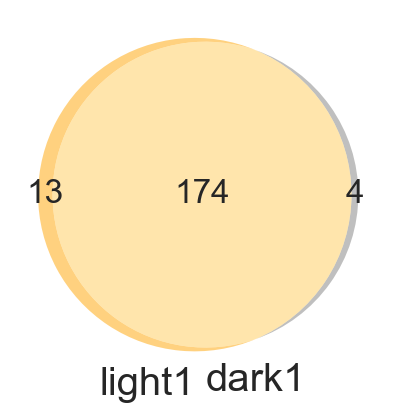

In [705]:
v = venn2(subsets = (np.sum(ls_n1) - np.sum(ls_n3) , np.sum(ls_n2) - np.sum(ls_n3), np.sum(ls_n3)), 
          set_labels = (cond1, cond2), 
          set_colors = ('orange', 'grey'), alpha = 0.5)

filepath = save_dir / f'venn2_{cond1}_{cond2}.pdf'
plt.savefig(filepath, transparent=True)

### HD tuning stat vs run

In [22]:
d_hr_data.keys()

dict_keys(['20211207_JA0144_dark1', '20211207_JA0144_darkHR1', '20211207_JA0144_light1', '20211207_JA0144_lightHR1', '20220126_JA0153_dark1', '20220126_JA0153_darkHR1', '20220126_JA0153_light1', '20220126_JA0153_lightHR1', '20220302_JA0162_dark1', '20220302_JA0162_darkHR1', '20220302_JA0162_light1', '20220302_JA0162_lightHR1', '20220419_JA0164_dark1', '20220419_JA0164_darkHR1', '20220419_JA0164_light1', '20220419_JA0164_lightHR1', '20220819_JA0178_dark1', '20220819_JA0178_darkHR1', '20220819_JA0178_light1', '20220819_JA0178_lightHR1', '20220822_JA0178_dark1', '20220822_JA0178_darkHR1', '20220822_JA0178_light1', '20220822_JA0178_lightHR1', '20220824_JA0178_dark1', '20220824_JA0178_darkHR1', '20220824_JA0178_light1', '20220824_JA0178_lightHR1', '20220906_JA0178_dark1', '20220906_JA0178_darkHR1', '20220906_JA0178_light1', '20220906_JA0178_lightHR1', '20220812_JA0181_dark1', '20220812_JA0181_darkHR1', '20220812_JA0181_light1', '20220812_JA0181_lightHR1', '20220815_JA0181_dark1', '20220815_

array([ 23.,  27.,  34.,  56., 123.])

In [470]:
ls_tuning = []
speed_thr = 5
for k in d_hr_data.keys():
    dts, animal_name, cond = k.split('_')[-3:]
    rec_session = animal_name + '_' + dts
    tmp_ephys = d_hr_data[k]['ephys']
    tmp_beh = d_hr_data[k]['beh']
    units_in = tmp_ephys[tmp_ephys.hdc_flag == True].cids.unique()
    yaw = tmp_beh['yaw'].values
    lin_speed = tmp_beh['lin_vel'].values
    
    stat_idx, run_idx = get_stat_run_epochs(lin_speed, window_size=25, speed_thr = speed_thr)
    # at least 10 s data
    if stat_idx.size < 500 or run_idx.size < 500:
        continue
        
    print(f'{k}, stat {stat_idx.size}, run {run_idx.size}, # of HDC {units_in.size}')
    for unit in sorted(units_in):
#         print(unit)
        tmp_fr = tmp_ephys[tmp_ephys.cids == unit].iloc[stat_idx]
        r_fr, hd_tuning_fr, p_val_fr = bin_tuning_permute(yaw[stat_idx], tmp_fr.hz.values)
        cuid = str(unit) + '_' + rec
        angles = hd_tuning_fr[0]
        a = np.deg2rad(angles)
        fr_fr = hd_tuning_fr[1]
        if fr_fr.max() < 1:
            continue
    
        ls_tuning.append(pd.DataFrame({'hz': fr_fr, 'dir': angles, 'cids':unit, 'animal_name': animal_name,
                                       'r': r_fr, 'p_val': p_val_fr, 'rec_id': k, 'date_name': dts, 'run':'stat',
                                      'cond': cond, 'rec_session':rec_session, 'cuid':cuid }))
        
        # second half of the recording
        tmp_fr = tmp_ephys[tmp_ephys.cids == unit].iloc[run_idx]
        r_fr, hd_tuning_fr, p_val_fr = bin_tuning_permute(yaw[run_idx], tmp_fr.hz.values)

        angles = hd_tuning_fr[0]
        a = np.deg2rad(angles)
        fr_fr = hd_tuning_fr[1]
        if fr_fr.max() < 1:
            continue
            
        ls_tuning.append(pd.DataFrame({'hz': fr_fr, 'dir': angles, 'cids':unit, 'animal_name': animal_name,
                                       'r': r_fr, 'p_val': p_val_fr, 'rec_id': k, 'date_name': dts, 'run':'run',
                                      'cond': cond , 'rec_session':rec_session, 'cuid':cuid }))
        
#         fr_fr = np.append(fr_fr, fr_fr[0])
#         a = np.append(a, a[0])
    #     ax = plt.subplot(111, projection='polar')
    #         ax.set_theta_zero_location("N")
    #         ax.set_theta_direction(-1)
    #     ax.plot(a, fr_fr, label = 'head free', c = 'magenta')
    #     ax.plot(a, fr_fx, label = 'head fixed', c = 'cyan')
    #     ax.legend(loc='best', bbox_to_anchor=(1.5, 0.5, 0.5, 0.5))
    #     plt.show()
    
        break
    break
# df_hrtun_run = pd.concat(ls_tuning)
# df_hrtun_run.head()

20211207_JA0144_dark1, stat 7450, run 16550, # of HDC 8


,animal_name,cids,date_name,cuid,is_sua,depth,session_name,site,r,p_val,tuning,x_tuning,condition,rec_id,hdc_flag,rec_session,hem,ch_map
0,JA0144,0.0,20211207,0.0_20211207_JA0144_dark1,1.0,False,001,88,0.082941,0.656,31.002028,3.0,dark1,20211207_JA0144_dark1,False,JA0144_20211207,lADN,h1
1,JA0144,0.0,20211207,0.0_20211207_JA0144_dark1,1.0,False,001,88,0.082941,0.656,26.494761,23.0,dark1,20211207_JA0144_dark1,False,JA0144_20211207,lADN,h1
2,JA0144,0.0,20211207,0.0_20211207_JA0144_dark1,1.0,False,001,88,0.082941,0.656,29.836700,43.0,dark1,20211207_JA0144_dark1,False,JA0144_20211207,lADN,h1
3,JA0144,0.0,20211207,0.0_20211207_JA0144_dark1,1.0,False,001,88,0.082941,0.656,25.480159,63.0,dark1,20211207_JA0144_dark1,False,JA0144_20211207,lADN,h1
4,JA0144,0.0,20211207,0.0_20211207_JA0144_dark1,1.0,False,001,88,0.082941,0.656,31.546377,83.0,dark1,20211207_JA0144_dark1,False,JA0144_20211207,lADN,h1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13,JA0144,103.0,20211207,103.0_20211207_JA0144_dark1,0.0,False,001,44,0.154089,0.014,2.774627,263.0,dark1,20211207_JA0144_dark1,False,JA0144_20211207,lADN,h1
14,JA0144,103.0,20211207,103.0_20211207_JA0144_dark1,0.0,False,001,44,0.154089,0.014,3.058394,283.0,dark1,20211207_JA0144_dark1,False,JA0144_20211207,lADN,h1
15,JA0144,103.0,20211207,103.0_20211207_JA0144_dark1,0.0,False,001,44,0.154089,0.014,2.466867,303.0,dark1,20211207_JA0144_dark1,False,JA0144_20211207,lADN,h1
16,JA0144,103.0,20211207,103.0_20211207_JA0144_dark1,0.0,False,001,44,0.154089,0.014,2.694323,323.0,dark1,20211207_JA0144_dark1,False,JA0144_20211207,lADN,h1


In [1035]:
# df_hrtun_run.to_pickle('df_hrtun_run.pkl')

In [23]:
df_hrtun_run.head()

,hz,dir,cids,animal_name,r,p_val,rec_id,date_name,run,cond,rec_session,cuid
0,0.302632,0.0,25.0,JA0144,0.351392,0.0,20211207_JA0144_dark1,20211207,stat,dark1,JA0144_20211207,25.0_20220829_MC038_lightHR1
1,0.896024,20.0,25.0,JA0144,0.351392,0.0,20211207_JA0144_dark1,20211207,stat,dark1,JA0144_20211207,25.0_20220829_MC038_lightHR1
2,1.610294,40.0,25.0,JA0144,0.351392,0.0,20211207_JA0144_dark1,20211207,stat,dark1,JA0144_20211207,25.0_20220829_MC038_lightHR1
3,0.875433,60.0,25.0,JA0144,0.351392,0.0,20211207_JA0144_dark1,20211207,stat,dark1,JA0144_20211207,25.0_20220829_MC038_lightHR1
4,0.877301,80.0,25.0,JA0144,0.351392,0.0,20211207_JA0144_dark1,20211207,stat,dark1,JA0144_20211207,25.0_20220829_MC038_lightHR1


In [28]:
# df_hrtun_run_master.to_pickle('df_hrtun_run_master')

### Plot tuning curves

In [25]:
df_hrtun_run.head()

,hz,dir,cids,animal_name,r,p_val,rec_id,date_name,run,cond,rec_session,cuid
0,0.302632,0.0,25.0,JA0144,0.351392,0.0,20211207_JA0144_dark1,20211207,stat,dark1,JA0144_20211207,25.0_20220829_MC038_lightHR1
1,0.896024,20.0,25.0,JA0144,0.351392,0.0,20211207_JA0144_dark1,20211207,stat,dark1,JA0144_20211207,25.0_20220829_MC038_lightHR1
2,1.610294,40.0,25.0,JA0144,0.351392,0.0,20211207_JA0144_dark1,20211207,stat,dark1,JA0144_20211207,25.0_20220829_MC038_lightHR1
3,0.875433,60.0,25.0,JA0144,0.351392,0.0,20211207_JA0144_dark1,20211207,stat,dark1,JA0144_20211207,25.0_20220829_MC038_lightHR1
4,0.877301,80.0,25.0,JA0144,0.351392,0.0,20211207_JA0144_dark1,20211207,stat,dark1,JA0144_20211207,25.0_20220829_MC038_lightHR1


In [122]:
df_hr_tuning_master.date_name.unique()

array(['20211212', '20220209', '20220302', '20220419', '20220426',
       '08_29', '20220819', '20220822', '20220824', '20220906',
       '20220812', '20220815', '20220818', '01_26', '07_12', '07_22'],
      dtype=object)

20220819 ['JA0178']
2.0
2.0


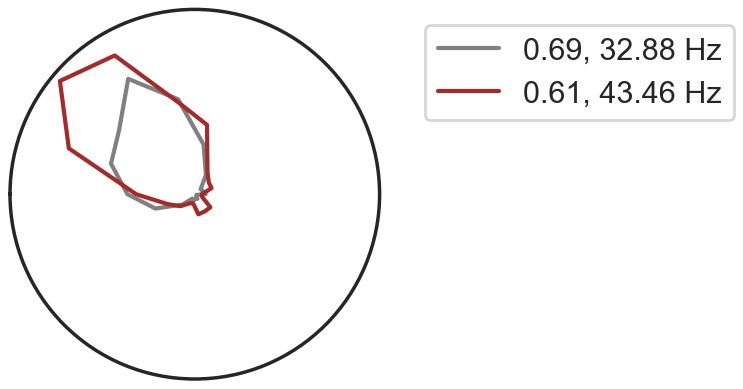

5.0
5.0


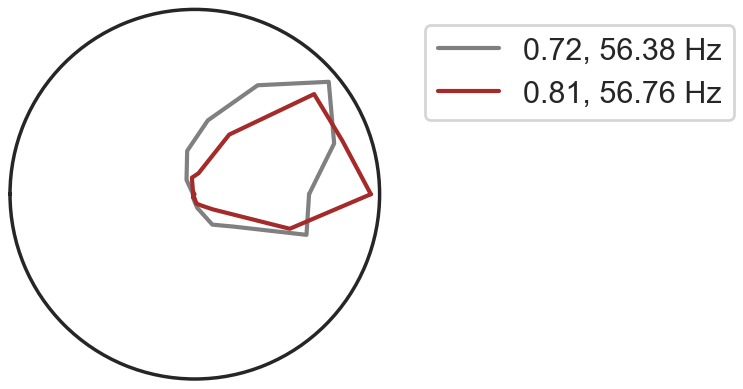

7.0
7.0


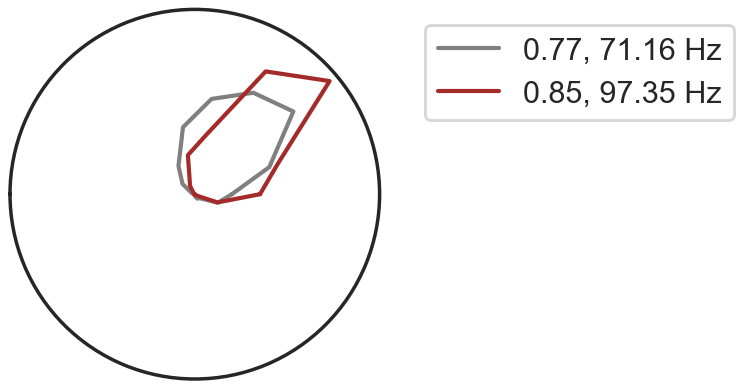

9.0
9.0


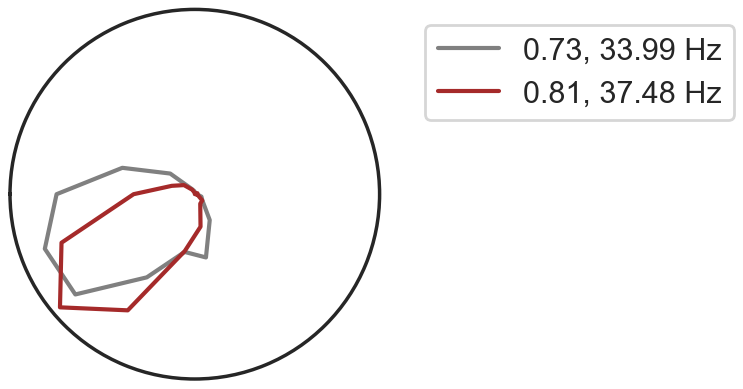

10.0
10.0


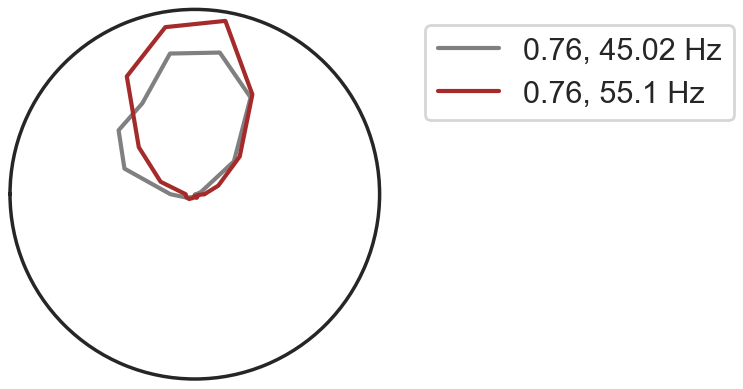

11.0
11.0


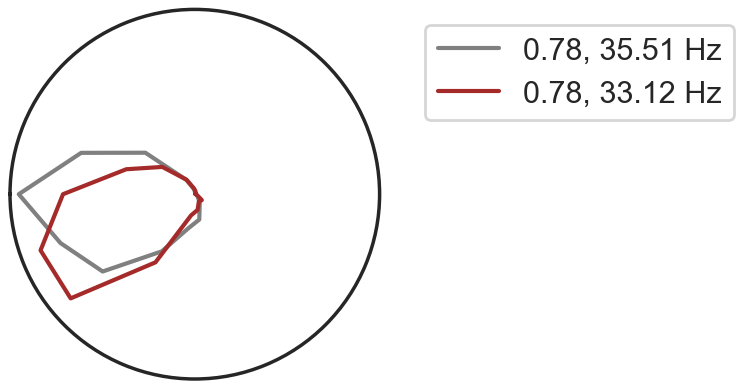

12.0
12.0


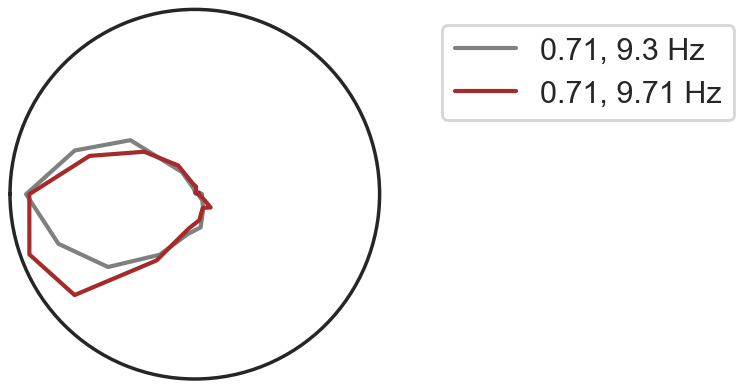

13.0
13.0


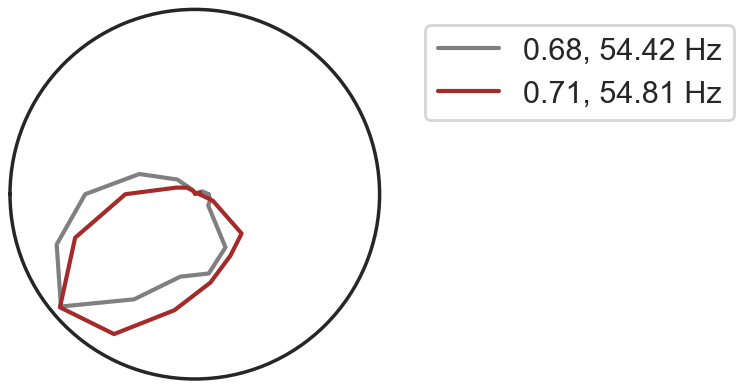

14.0
14.0


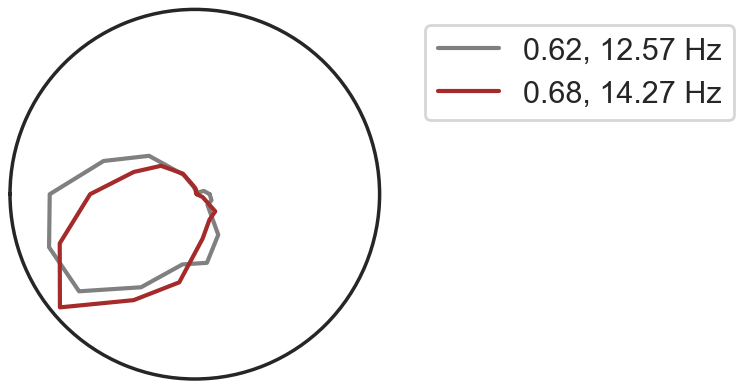

15.0
15.0


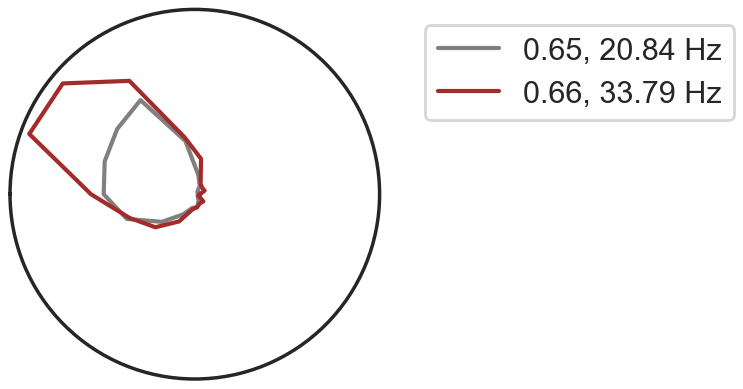

17.0
17.0


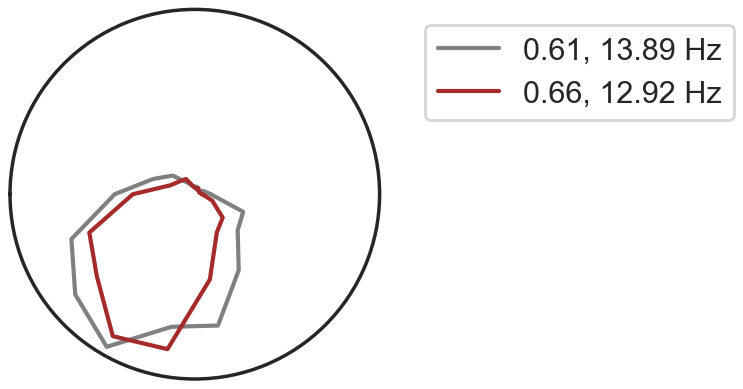

18.0
18.0


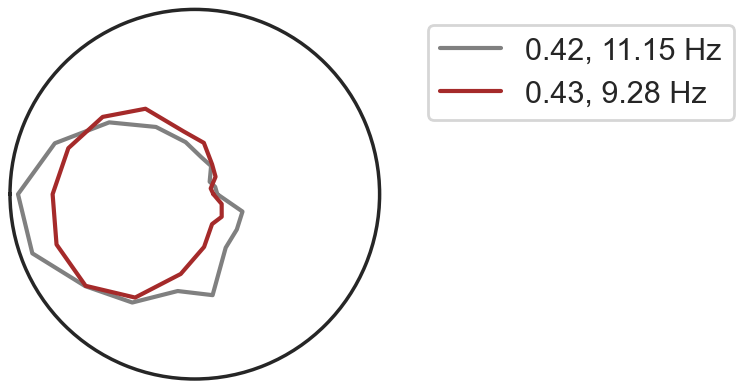

19.0
19.0


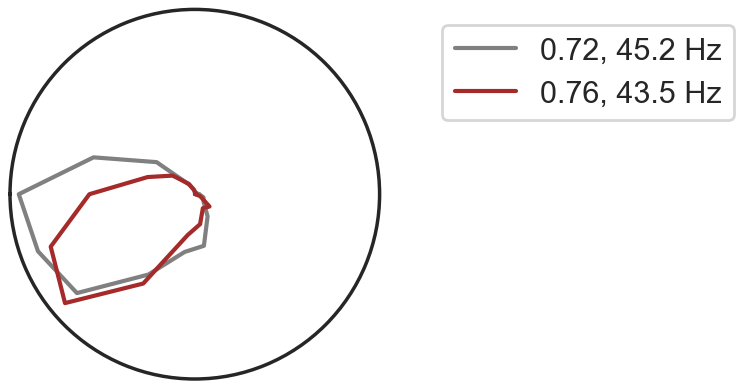

21.0
21.0


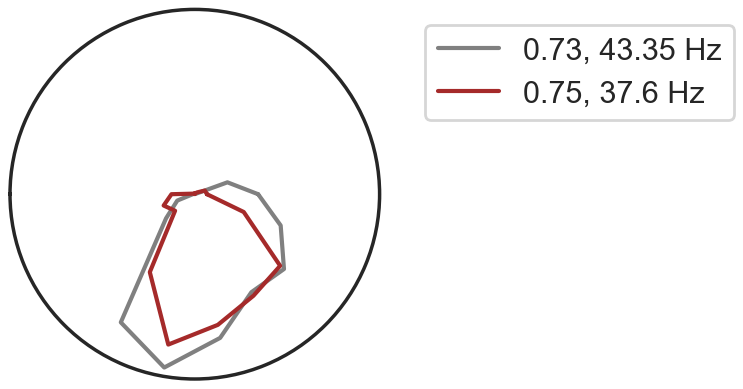

22.0
22.0


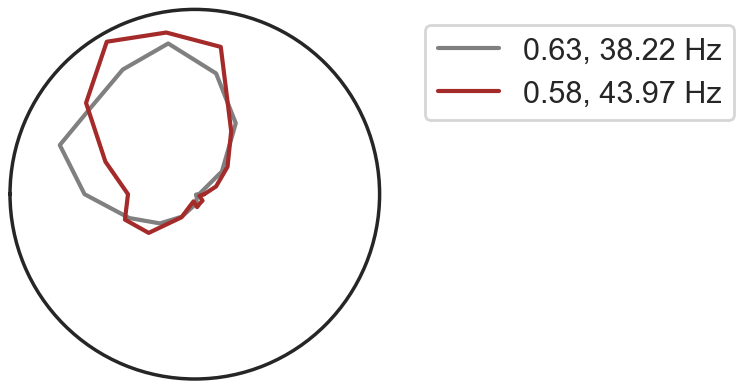

23.0
23.0


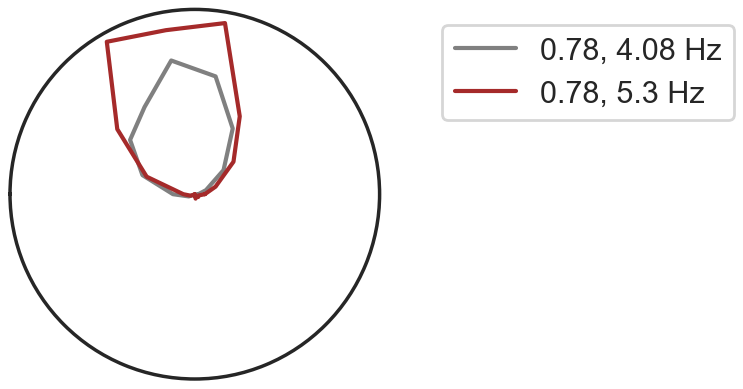

24.0
24.0


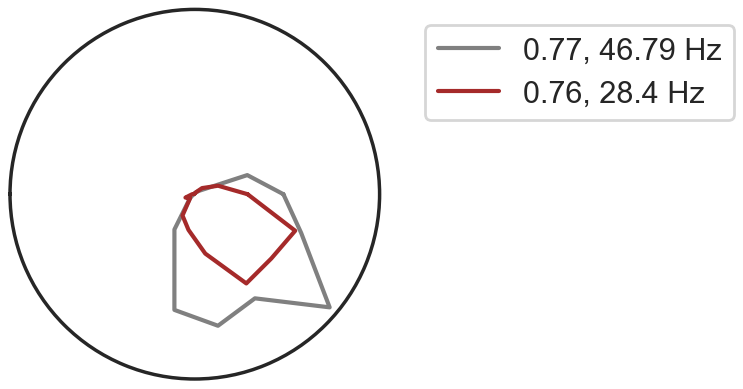

25.0
25.0


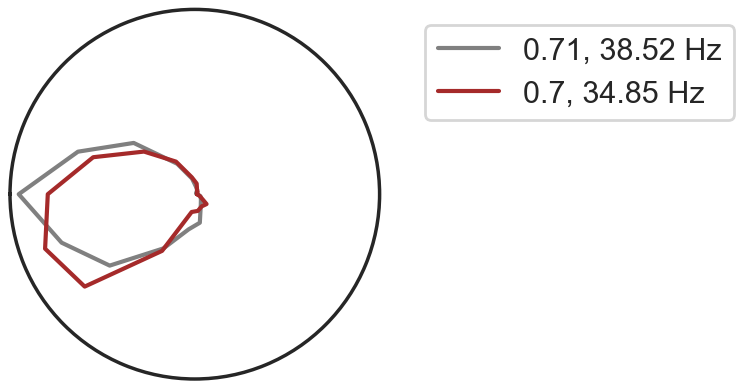

44.0
44.0


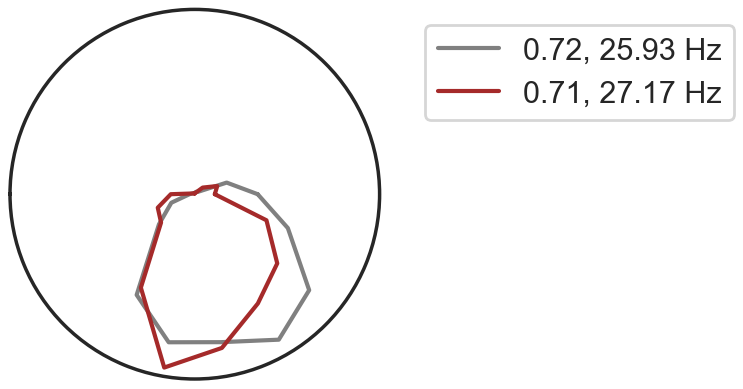

91.0
91.0


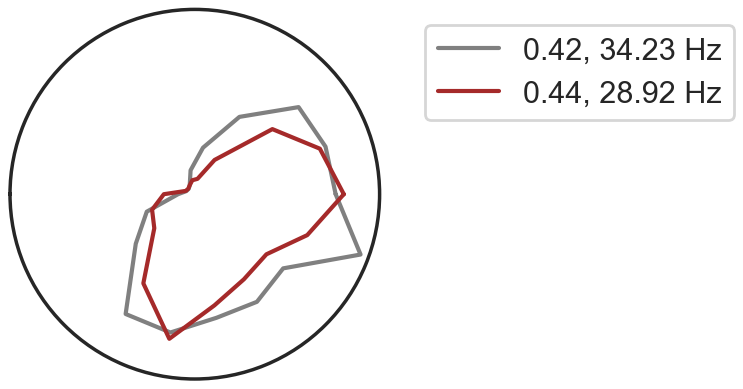

94.0
94.0


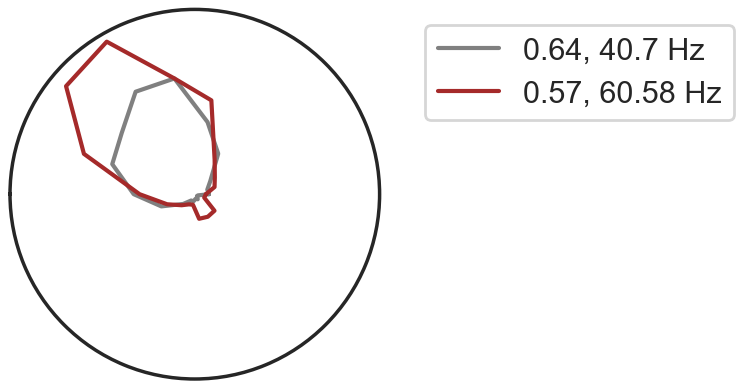

95.0
95.0


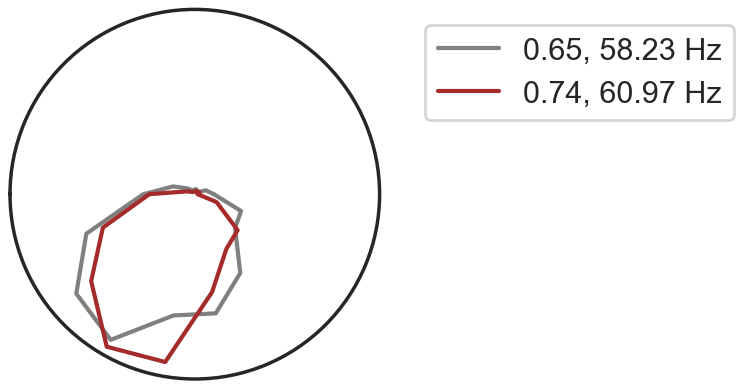

96.0
96.0


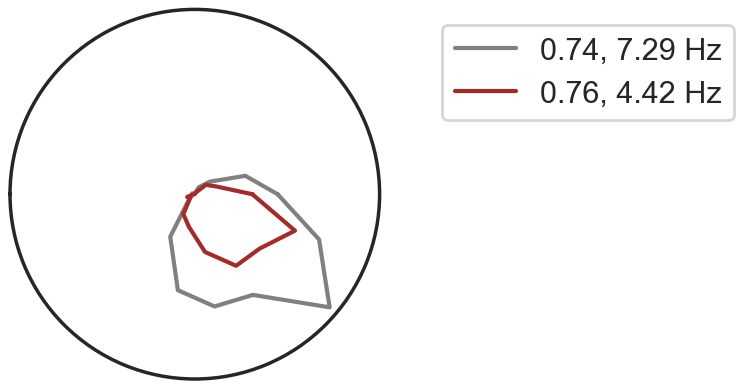

97.0
97.0


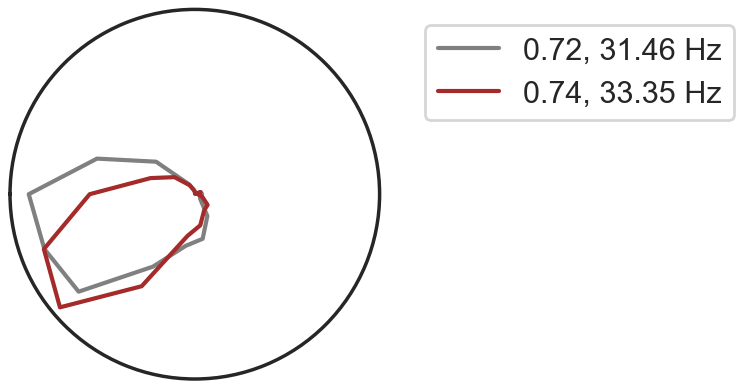

99.0
99.0


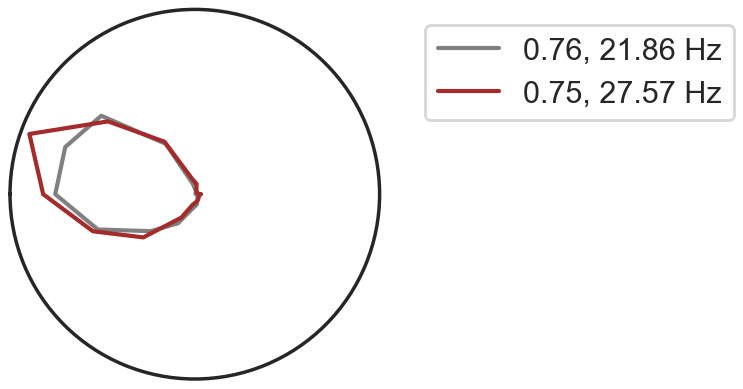

100.0
100.0


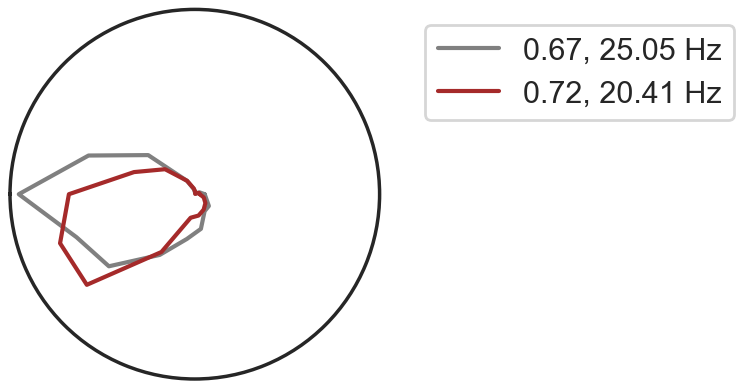

103.0
103.0


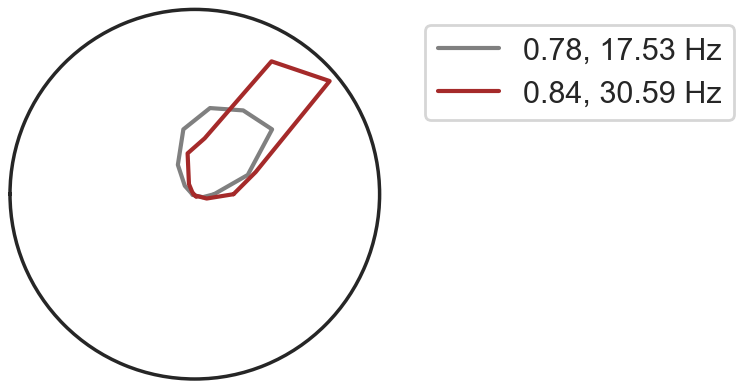

122.0
122.0


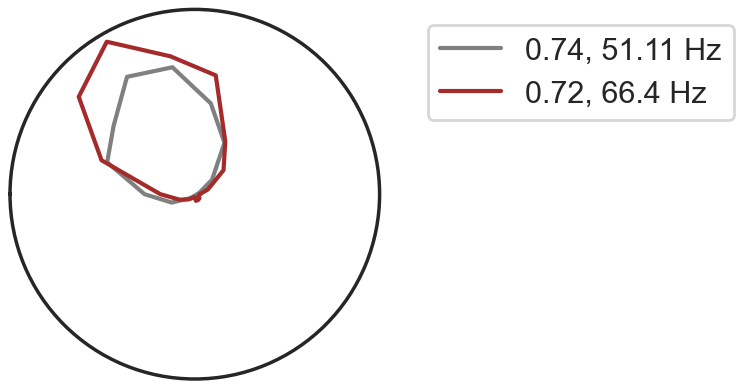

134.0
134.0


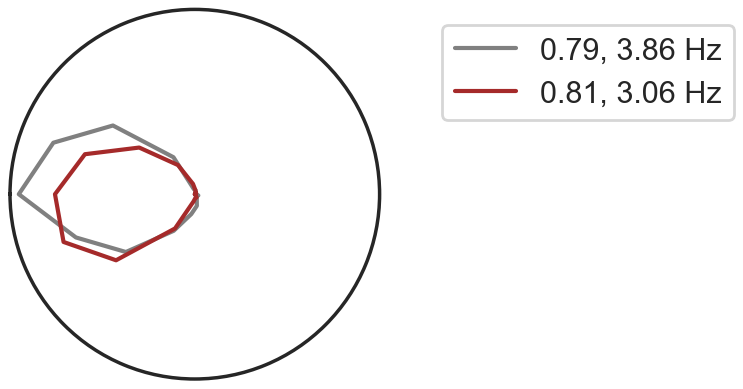

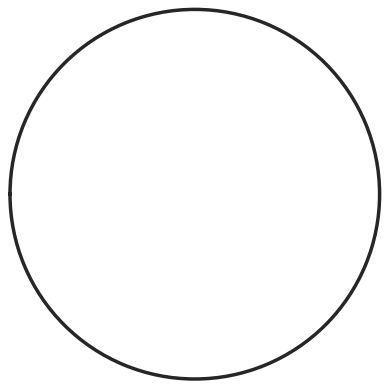

In [64]:
data = df_hrtun_master[df_hrtun_master.hdc_flag == True]

angles = np.arange(0, 360, 20)
a = np.deg2rad(angles)
a = np.append(a, a[0])

for rec in data.date_name.unique()[:]:
    if '20220819' not in rec:
        continue
    tmp = data[data.date_name == rec]
    print(rec, tmp.animal_name.unique())
    for unit in tmp.cids.unique()[:]:
        
        ax = plt.subplot(111, projection = 'polar')
#         ax.yaxis.grid(linewidth=0)
#         ax.xaxis.grid(linewidth=6)
        ax.set_yticklabels([])
        ax.set_xticklabels([])
        ax.grid(False)
    #         ax.set_theta_zero_location("N")
    #         ax.set_theta_direction(-1)
        fr1 = tmp[(tmp.cids == unit) & (tmp.condition == 'light1')].tuning
        fr2 = tmp[(tmp.cids == unit) & (tmp.condition == 'dark1')].tuning
        r_r = np.round(tmp[(tmp.cids == unit) & (tmp.condition == 'light1')].r.min(), 2)
        r_vr = np.round(tmp[(tmp.cids == unit) & (tmp.condition == 'dark1')].r.min(), 2)

        if fr1.size > 1 and r_r > 0.3:
            print(unit)
            if sum(np.isnan(fr1)) > 3:
                continue
            fr1 = np.append(fr1, fr1[0])
            max_fr1 = round(fr1[~np.isnan(fr1)].max(), 2)
            
            # angles were reflected in arena code
            ax.plot(a, fr1, label = f'{r_r}, {max_fr1} Hz', c = 'grey')
            ax.legend(loc='best', bbox_to_anchor=(1.5, 0.5, 0.5, 0.5))
        
        if fr2.size > 1 and r_vr > 0.3:
            print(unit)
            if sum(np.isnan(fr2)) > 3:
                continue
            fr2 = np.append(fr2, fr2[0])
            max_fr2 = round(fr2[~np.isnan(fr2)].max(), 2)
            
            ax.plot(a, fr2, label = f'{r_vr}, {max_fr2} Hz',  c = 'brown')
            ax.legend(loc='best', bbox_to_anchor=(1.5, 0.5, 0.5, 0.5))
#         fr_resam, results_half = hd_tuning_width(fr2)
#         plt.plot(fr_resam)
#         plt.hlines(*results_half[1:])
        ax.set_xticks(np.pi/180. * np.linspace(180,  -180, 8, endpoint=False))
        ax.set_thetalim(-np.pi, np.pi)
        plt.show()
#         time.sleep(1)
#         plt.savefig(f'{rec}_{unit}_hr_tuning.pdf', transparent=True)
#         plt.clf()
    break
        

In [687]:
tmp.groupby()

array([13., 19., 35., 39., 44., 55., 69., 75., 77., 79., 84.])

In [29]:
df_hrtun_run_master.head()

,hz,dir,cids,animal_name,r,p_val,rec_id,date_name,run,cond,rec_session,cuid
0,0.142857,0.0,25.0,JA0144,0.314194,0.0,20211212_JA0144_dark1,20211212,stat,dark1,JA0144_20211212,25.0_20211212_JA0144_dark1
1,1.484848,20.0,25.0,JA0144,0.314194,0.0,20211212_JA0144_dark1,20211212,stat,dark1,JA0144_20211212,25.0_20211212_JA0144_dark1
2,1.703125,40.0,25.0,JA0144,0.314194,0.0,20211212_JA0144_dark1,20211212,stat,dark1,JA0144_20211212,25.0_20211212_JA0144_dark1
3,1.327273,60.0,25.0,JA0144,0.314194,0.0,20211212_JA0144_dark1,20211212,stat,dark1,JA0144_20211212,25.0_20211212_JA0144_dark1
4,0.691525,80.0,25.0,JA0144,0.314194,0.0,20211212_JA0144_dark1,20211212,stat,dark1,JA0144_20211212,25.0_20211212_JA0144_dark1


### Plot tuning curves stat vs run

In [66]:
df_hrtun_run.head()

,hz,dir,cids,animal_name,r,p_val,rec_id,date_name,run,cond,rec_session,cuid
0,0.302632,0.0,25.0,JA0144,0.351392,0.0,20211207_JA0144_dark1,20211207,stat,dark1,JA0144_20211207,25.0_20220829_MC038_lightHR1
1,0.896024,20.0,25.0,JA0144,0.351392,0.0,20211207_JA0144_dark1,20211207,stat,dark1,JA0144_20211207,25.0_20220829_MC038_lightHR1
2,1.610294,40.0,25.0,JA0144,0.351392,0.0,20211207_JA0144_dark1,20211207,stat,dark1,JA0144_20211207,25.0_20220829_MC038_lightHR1
3,0.875433,60.0,25.0,JA0144,0.351392,0.0,20211207_JA0144_dark1,20211207,stat,dark1,JA0144_20211207,25.0_20220829_MC038_lightHR1
4,0.877301,80.0,25.0,JA0144,0.351392,0.0,20211207_JA0144_dark1,20211207,stat,dark1,JA0144_20211207,25.0_20220829_MC038_lightHR1


In [156]:
data = df_hrtun_run[df_hrtun_run.cond == 'lightHR1']

angles = np.arange(0, 360, 20)
a = np.deg2rad(angles)
a = np.append(a, a[0])

for rec in data.rec_id.unique()[:]:
    if '20220302_JA0162' not in rec:
        continue
    tmp = data[data.rec_id == rec]
    print(rec, tmp.animal_name.unique())
    for unit in uoi[:]:
        
        ax = plt.subplot(111, projection = 'polar')
#         ax.yaxis.grid(linewidth=0)
#         ax.xaxis.grid(linewidth=6)
        ax.set_yticklabels([])
        ax.set_xticklabels([])
        ax.grid(False)
    #         ax.set_theta_zero_location("N")
    #         ax.set_theta_direction(-1)
        fr1 = tmp[(tmp.cids == unit) & (tmp.run == 'stat')].hz
        fr2 = tmp[(tmp.cids == unit) & (tmp.run == 'run')].hz
        r_r = np.round(tmp[(tmp.cids == unit) & (tmp.run == 'stat')].r.min(), 2)
        r_vr = np.round(tmp[(tmp.cids == unit) & (tmp.run == 'run')].r.min(), 2)

        if fr1.size > 1 or r_r > 0.5:
            print(unit)
            if sum(np.isnan(fr1)) > 3:
                continue
            fr1 = np.append(fr1, fr1[0])
            max_fr1 = round(fr1[~np.isnan(fr1)].max(), 2)
            
            # angles were reflected in arena code
            ax.plot(a, fr1, label = f'{r_r}, {max_fr1} Hz', c = 'lightgray')
            ax.legend(loc='best', bbox_to_anchor=(1.5, 0.5, 0.5, 0.5))
        
        if fr2.size > 1 or r_vr > 0.5:
            print(unit)
            if sum(np.isnan(fr2)) > 3:
                continue
            fr2 = np.append(fr2, fr2[0])
            max_fr2 = round(fr2[~np.isnan(fr2)].max(), 2)
            
            ax.plot(a, fr2, label = f'{r_vr}, {max_fr2} Hz',  c = 'gray')
            ax.legend(loc='best', bbox_to_anchor=(1.5, 0.5, 0.5, 0.5))
#         fr_resam, results_half = hd_tuning_width(fr2)
#         plt.plot(fr_resam)
#         plt.hlines(*results_half[1:])
        ax.set_xticks(np.pi/180. * np.linspace(180,  -180, 8, endpoint=False))
        ax.set_thetalim(-np.pi, np.pi)
      
        plt.show()
        time.sleep(0.1)
        
        # filepath = save_dir / f'polar_HD_tuning_{rec}_{unit}.pdf'
        # plt.savefig(filepath, transparent = True)
        plt.clf()
        
    # break

20220302_JA0162_lightHR1 ['JA0162']
332.0
332.0
424.0
424.0


<Figure size 640x480 with 0 Axes>

In [158]:
uoi = [332.0, 424.0]
filepath = save_dir / f'out.xlsx'
tmp[(tmp.cids.isin(uoi))][['cids', 'dir',  'hz', 'cond', 'run']].pivot(index = ['cond', 'cids', 'run'] , columns = 'dir', values = 'hz').to_excel(filepath, index=True)

### Summary plots

In [561]:
df_hrtun_run.head()

,hz,dir,cids,animal_name,r,p_val,rec_id,date_name,run,cond,rec_session,cuid,cond_run
0,0.302632,0.0,25.0,JA0144,0.351392,0.0,20211207_JA0144_dark1,20211207,stat,dark1,JA0144_20211207,25.0_20220829_MC038_lightHR1,dark1_stat
1,0.896024,20.0,25.0,JA0144,0.351392,0.0,20211207_JA0144_dark1,20211207,stat,dark1,JA0144_20211207,25.0_20220829_MC038_lightHR1,dark1_stat
2,1.610294,40.0,25.0,JA0144,0.351392,0.0,20211207_JA0144_dark1,20211207,stat,dark1,JA0144_20211207,25.0_20220829_MC038_lightHR1,dark1_stat
3,0.875433,60.0,25.0,JA0144,0.351392,0.0,20211207_JA0144_dark1,20211207,stat,dark1,JA0144_20211207,25.0_20220829_MC038_lightHR1,dark1_stat
4,0.877301,80.0,25.0,JA0144,0.351392,0.0,20211207_JA0144_dark1,20211207,stat,dark1,JA0144_20211207,25.0_20220829_MC038_lightHR1,dark1_stat


In [562]:
_inp_plot = df_hrtun_run[df_hrtun_run.cond == 'lightHR1'].groupby([ 'rec_id', 'cuid', 'run' ])['hz'].max().reset_index()
_inp_plot.pivot(index = ['rec_id', 'cuid'], columns = 'run', values = 'hz').dropna()


run                                                           run       stat
rec_id                   cuid                                               
20211207_JA0144_lightHR1 102.0_20220829_MC038_lightHR1  86.874644  90.090909
                         103.0_20220829_MC038_lightHR1   5.361702   7.866667
                         25.0_20220829_MC038_lightHR1    3.052326   2.597315
                         51.0_20220829_MC038_lightHR1   25.572519  35.803279
                         62.0_20220829_MC038_lightHR1   22.012048  22.259259
...                                                           ...        ...
20220829_MC038_lightHR1  23.0_20220829_MC038_lightHR1   26.133858  57.781250
                         27.0_20220829_MC038_lightHR1   27.433071  77.562500
                         34.0_20220829_MC038_lightHR1   22.700787  64.750000
                         56.0_20220829_MC038_lightHR1    4.031546   9.446886
20220906_JA0178_lightHR1 39.0_20220829_MC038_lightHR1   12.190476  24.794118

[197 rows x 2 columns]

In [563]:
cond1 = 'dark1'
cond2 = 'darkHR1'
data = df_hr_tuning_master[df_hr_tuning_master.hdc_flag == True]
cond = 'condition'
y = 'r'
# vis_rec_sess = df_tun_proc[(df_tun_proc.head_fixation == 'VIS') & (df_tun_proc.dir == 0)].rec_session.unique()
# sessions_in = df_betti[(df_betti.cond == 'TS6-HF') & (df_betti.stat_off_manifold > 0.5)].rec_session.unique()

pal = ('grey', 'brown')
# pal = ('darkgreen', 'lightgreen')
_inp_plot = data[ ((data.condition == cond1) | (data.condition == cond2))
#             & (data.rec_session.isin(sessions_in))
            ].groupby([ 'animal_name', 'cids', cond])[y].max().reset_index()


sns.kdeplot(x = y, data = _inp_plot, hue = cond,  fill=False, 
            cumulative=False, common_grid=True,
           common_norm = False, legend = True, 
#             cut = 0,
            palette = pal)


# plt.xlim(0, 1)
# fname = f'kde_{y}_{cond1}_run_stat.pdf'
# plt.savefig(f'kde_{y}_{cond1}_{cond2}.pdf', transparent=True)

NameError: name 'df_hr_tuning_master' is not defined

In [114]:
_inp_plot.groupby(cond)[y].describe()

,count,mean,std,min,25%,50%,75%,max
condition,,,,,,,,
dark1,178.0,0.690354,0.153759,0.303416,0.604029,0.740459,0.811487,0.883000
darkHR1,143.0,0.509599,0.126228,0.306197,0.421283,0.500556,0.588719,0.957612


In [115]:
a = _inp_plot[_inp_plot[cond] == cond1][y].values
b = _inp_plot[_inp_plot[cond] == cond2][y].values
print(f'test for {y}')
print(f'# of units in {cond1} {a.size}')
print(f'# of units in {cond2} {b.size}')
print(f'median {y} {cond1} {np.median(a)}')
print(f'median {y} {cond2} {np.median(b)}')

print(stats.mannwhitneyu(a, b))

test for r
# of units in dark1 178
# of units in darkHR1 143
median r dark1 0.7404588535584706
median r darkHR1 0.5005559203965796
MannwhitneyuResult(statistic=20706.0, pvalue=4.728902475799938e-22)


In [427]:
df_hrtun_run_master.head()

,hz,dir,cids,animal_name,r,p_val,rec_id,date_name,run,cond,rec_session,cuid,cond_run
0,0.142857,0.0,25.0,JA0144,0.314194,0.0,20211212_JA0144_dark1,20211212,stat,dark1,JA0144_20211212,25.0_20211212_JA0144_dark1,dark1_stat
1,1.484848,20.0,25.0,JA0144,0.314194,0.0,20211212_JA0144_dark1,20211212,stat,dark1,JA0144_20211212,25.0_20211212_JA0144_dark1,dark1_stat
2,1.703125,40.0,25.0,JA0144,0.314194,0.0,20211212_JA0144_dark1,20211212,stat,dark1,JA0144_20211212,25.0_20211212_JA0144_dark1,dark1_stat
3,1.327273,60.0,25.0,JA0144,0.314194,0.0,20211212_JA0144_dark1,20211212,stat,dark1,JA0144_20211212,25.0_20211212_JA0144_dark1,dark1_stat
4,0.691525,80.0,25.0,JA0144,0.314194,0.0,20211212_JA0144_dark1,20211212,stat,dark1,JA0144_20211212,25.0_20211212_JA0144_dark1,dark1_stat


In [564]:
df_hrtun_run['cond_run'] = df_hrtun_run['cond'] + '_' + df_hrtun_run['run']

<Axes: xlabel='r', ylabel='Density'>

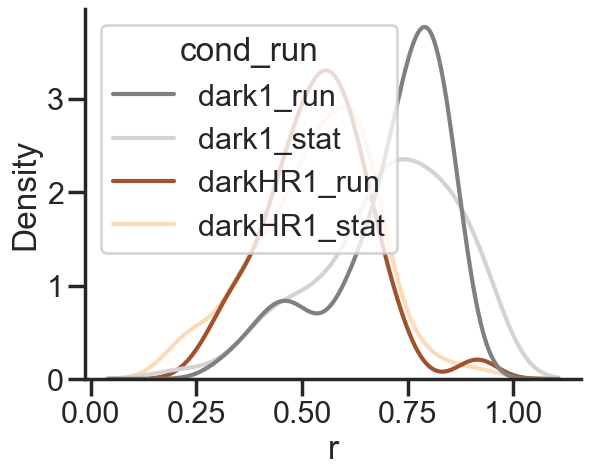

In [673]:
y = 'r'
cond1 = 'stat'
cond2 = 'run'
# coi = ['light1', 'lightHR1']; pal = ('darkorange', 'gold', 'darkgreen', 'lightgreen')
coi = ['dark1', 'darkHR1']; pal = ('gray', 'lightgray', 'sienna', 'peachpuff' )
data = df_hrtun_run[(df_hrtun_run.cond.isin(coi) )
                       ]

# vis_rec_sess = df_tun_proc[(df_tun_proc.head_fixation == 'VIS') & (df_tun_proc.dir == 0)].rec_session.unique()
# sessions_in = df_betti[(df_betti.cond == 'TS6-HF') & (df_betti.stat_off_manifold > 0.5)].rec_session.unique()


# _inp_plot = df_tun_proc[ (df_tun_proc.hdc == 1)
#             & (df_tun_proc.rec_session.isin(sessions_in))
#             & ((df_tun_proc.cond == cond1) | (df_tun_proc.cond == cond2))
#             ].groupby([ 'implant', 'cond', 'rec_session','cids' , 'cuid'])[y].max().reset_index()

_inp_plot = data.groupby([ 'cond_run', 'rec_id', 'rec_session', 'run', 'cids'])[y].max().reset_index()
_inp_plot2 = _inp_plot.pivot(index = ['cond_run', 'rec_id', 'cids'], columns = 'run', values = y).dropna().reset_index()
_inp_plot3 = pd.melt(_inp_plot2, id_vars = ['cond_run', 'rec_id', 'cids'], value_vars = ['stat', 'run'])


sns.kdeplot(x = y, data = _inp_plot, hue = 'cond_run',  fill=False, 
            cumulative=False, common_grid=True,
           common_norm = False, legend = True, 
#             cut = 0,
            palette = pal)


# plt.xlim(0, 1)
# fname = f'kde_TS6-HF_{y}_{cond1}_{cond2}.pdf'
# plt.savefig(f'kde_hr_tunrun_{coi}_{y}.pdf', transparent=True)

<Axes: xlabel='cond', ylabel='r'>

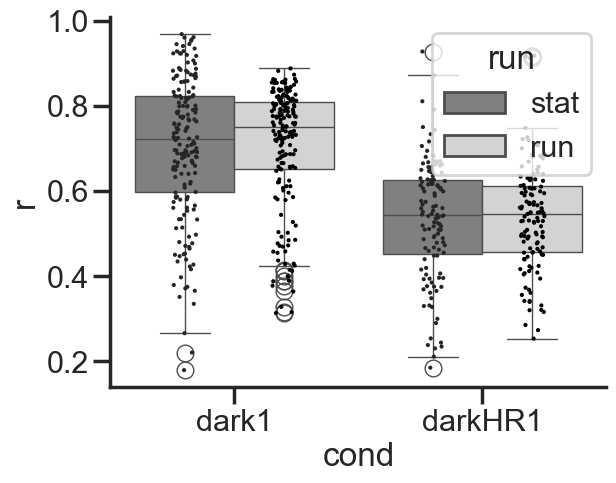

In [674]:
cond1 = 'stat'
cond2 = 'run'

# vis_rec_sess = df_tun_proc[(df_tun_proc.head_fixation == 'VIS') & (df_tun_proc.dir == 0)].rec_session.unique()
# sessions_in = df_betti[(df_betti.cond == 'TS6-HF') & (df_betti.stat_off_manifold > 0.5)].rec_session.unique()
data = df_hrtun_run

# _inp_plot = df_tun_proc[ (df_tun_proc.hdc == 1)
#             & (df_tun_proc.rec_session.isin(sessions_in))
#             & ((df_tun_proc.cond == cond1) | (df_tun_proc.cond == cond2))
#             ].groupby([ 'implant', 'cond', 'rec_session','cids' , 'cuid'])[y].max().reset_index()

_inp_plot = data[data.cond.isin(coi)].groupby([ 'cond', 'rec_id', 'run', 'cids'])[y].max().reset_index()
_inp_plot2 = _inp_plot.pivot(index = ['cond', 'rec_id', 'cids'], columns = 'run', values = y).dropna().reset_index()
_inp_plot3 = pd.melt(_inp_plot2, id_vars = ['cond', 'rec_id', 'cids'], value_vars = ['stat', 'run'], value_name=y)

sns.boxplot(data=_inp_plot3, x ='cond', y = y, hue = 'run', palette = pal)
sns.stripplot(data=_inp_plot3, x ='cond', y = y, hue = 'run', size = 3,
              dodge = True, palette='dark:black', legend = None)

# plt.xlim(0, 1)
# fname = f'kde_TS6-HF_{y}_{cond1}_{cond2}.pdf'
# plt.savefig(f'boxplot_hr_tunrun_{coi}_{y}.pdf', transparent=True)

In [675]:
_inp_plot3.groupby(['cond', 'run'])[y].describe()

count      mean       std       min       25%       50%  \
cond    run                                                             
dark1   run   178.0  0.707423  0.139421  0.313530  0.652571  0.751476   
        stat  178.0  0.702191  0.166380  0.179547  0.596854  0.722386   
darkHR1 run   123.0  0.537708  0.123324  0.253495  0.457475  0.546315   
        stat  123.0  0.534647  0.140313  0.185260  0.451801  0.544784   

                   75%       max  
cond    run                       
dark1   run   0.809237  0.887854  
        stat  0.822949  0.968440  
darkHR1 run   0.611200  0.917750  
        stat  0.627009  0.927531

In [676]:
a1 = _inp_plot3[(_inp_plot3.cond == coi[0]) & (_inp_plot3.run == 'stat')][y].values
a2 = _inp_plot3[(_inp_plot3.cond == coi[0]) & (_inp_plot3.run == 'run')][y].values
b1 = _inp_plot3[(_inp_plot3.cond == coi[1]) & (_inp_plot3.run == 'stat')][y].values
b2 = _inp_plot3[(_inp_plot3.cond == coi[1]) & (_inp_plot3.run == 'run')][y].values


print(f'test for {y}')
# print(f'# of implntations {_inp_plot.implant.unique().size}')
print(f'# of sessions {coi[0]} {_inp_plot3[_inp_plot3.cond == coi[0]].rec_id.unique().size}')
print(f'# of sessions {coi[1]} {_inp_plot3[_inp_plot3.cond == coi[1]].rec_id.unique().size}')


stat1, pval1 = stats.wilcoxon(a1, a2)
print(f'{coi[0]} stat vs run {stat1} {pval1}')
stat2, pval2 = stats.wilcoxon(b1, b2)
print(f'{coi[1]} stat vs run {stat2} {pval2}')
stat3, pval3 = stats.mannwhitneyu(a1, b1)
print(f'stat  {stat3} {pval3}')
stat4, pval4 = stats.mannwhitneyu(a2, b2)
print(f'run {stat4} {pval4}')
pvals = [pval1, pval2, pval3, pval4]  
print('Benjamini/Hochberg (non-negative)')
print(multipletests(pvals, alpha=0.05, method='fdr_bh'))


test for r
# of sessions dark1 13
# of sessions darkHR1 12
dark1 stat vs run 7881.0 0.9023117376878079
darkHR1 stat vs run 3631.0 0.6459665857187903
stat  17264.0 1.7477201752564274e-17
run 18024.0 1.5236628385113152e-21
Benjamini/Hochberg (non-negative)
(array([False, False,  True,  True]), array([9.02311738e-01, 8.61288781e-01, 3.49544035e-17, 6.09465135e-21]), 0.012741455098566168, 0.0125)


In [677]:
_inp_plot3.head()

,cond,rec_id,cids,run,r
0,dark1,20211207_JA0144_dark1,25.0,stat,0.351392
1,dark1,20211207_JA0144_dark1,51.0,stat,0.882516
2,dark1,20211207_JA0144_dark1,62.0,stat,0.906481
3,dark1,20211207_JA0144_dark1,66.0,stat,0.514387
4,dark1,20211207_JA0144_dark1,67.0,stat,0.952870


In [170]:
# filepath = save_dir / f'out.xlsx'
# _inp_plot3['cond'] = _inp_plot3['cond'].replace({'light1': 'RL', 'lightHR1': 'RL-Hfix'})
# _inp_plot3.to_excel(filepath, index = True)

<Axes: xlabel='hz', ylabel='Density'>

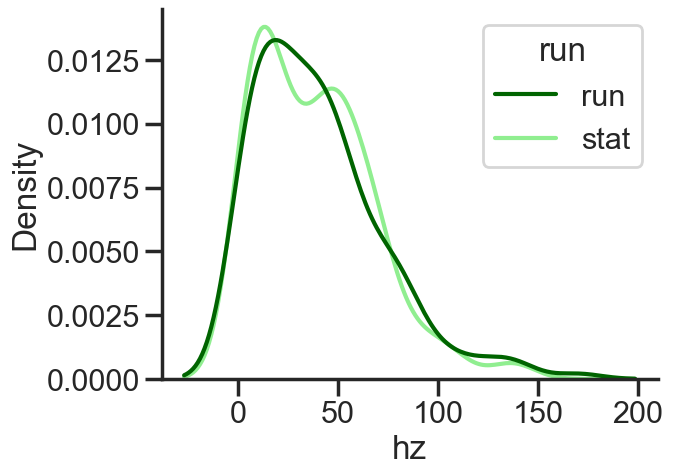

In [97]:
y = 'hz'
cond = 'lightHR1'
data = df_hrtun_run


# vis_rec_sess = df_tun_proc[(df_tun_proc.head_fixation == 'VIS') & (df_tun_proc.dir == 0)].rec_session.unique()
# sessions_in = df_betti[(df_betti.cond == 'TS6-HF') & (df_betti.stat_off_manifold > 0.5)].rec_session.unique()

pal = ('darkgreen', 'lightgreen')
# pal = ('darkorange', 'orange')
_inp_plot = data[ (data.cond == cond)
#             & (data.rec_session.isin(sessions_in))
#             & ((data.condition == cond1) | (data.condition == cond2))
            ].groupby([ 'animal_name', 'cond', 'cids', 'run'])[y].max().reset_index()


sns.kdeplot(x = y, data = _inp_plot, hue = 'run',  fill=False, 
            cumulative=False, common_grid=True,
           common_norm = False, legend = True, 
#             cut = 0,
            palette = pal)


# plt.xlim(0, 1)
# fname = f'kde_{y}_{cond}_run_stat.pdf'
# plt.savefig(f'kde_hr_{cond}_{y}.pdf', transparent=True)

In [98]:
_inp_plot.groupby('run')[y].describe()

,count,mean,std,min,25%,50%,75%,max
run,,,,,,,,
run,176.0,39.967267,31.826010,1.283044,14.910967,36.128125,55.726446,170.267857
stat,176.0,38.557099,29.237313,1.401460,13.597655,36.123862,56.021339,139.977654


In [99]:
a = _inp_plot[_inp_plot['run'] == 'stat'][y].values
b = _inp_plot[_inp_plot['run'] == 'run'][y].values
print(f'test for {y}')
print(f'# of units in {cond1} {a.size}')
print(f'# of units in {cond2} {b.size}')
print(f'median {y} {cond1} {np.median(a)}')
print(f'median {y} {cond2} {np.median(b)}')

print(stats.ks_2samp(a, b))

test for hz
# of units in stat 176
# of units in run 176
median hz stat 36.12386156648452
median hz run 36.128125
KstestResult(statistic=0.056818181818181816, pvalue=0.9398986758878779, statistic_location=73.80555555555556, statistic_sign=1)


In [49]:
df_hr_tuning_master.head()

,animal_name,cids,date_name,is_sua,acronym,bm,hdc_flag,session_name,site,r,p_val,tuning,x_tuning,condition,rec_id,hd_model,cuid,depth
0,JA0144,0.0,20211212,1.0,NaN,0.0,False,001,88,0.082941,0.656,31.002028,3.0,dark1,20211212_JA0144_dark1,False,0.0_20211212_JA0144_dark1,NaN
1,JA0144,0.0,20211212,1.0,NaN,0.0,False,001,88,0.082941,0.656,26.494761,23.0,dark1,20211212_JA0144_dark1,False,0.0_20211212_JA0144_dark1,NaN
2,JA0144,0.0,20211212,1.0,NaN,0.0,False,001,88,0.082941,0.656,29.836700,43.0,dark1,20211212_JA0144_dark1,False,0.0_20211212_JA0144_dark1,NaN
3,JA0144,0.0,20211212,1.0,NaN,0.0,False,001,88,0.082941,0.656,25.480159,63.0,dark1,20211212_JA0144_dark1,False,0.0_20211212_JA0144_dark1,NaN
4,JA0144,0.0,20211212,1.0,NaN,0.0,False,001,88,0.082941,0.656,31.546377,83.0,dark1,20211212_JA0144_dark1,False,0.0_20211212_JA0144_dark1,NaN


## Fit Isomap

### Arena isomap

<Axes: >

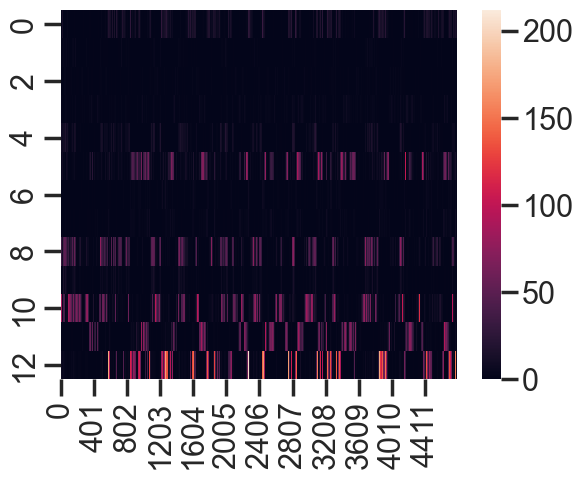

In [140]:
_inp = df_tmp[df_tmp.condition == 'dark1'].pivot(index = 'cids', columns = 'times', values = 'hz').values[:, ::5]
sns.heatmap(_inp)

In [171]:
d_ses_hdc = {}
for k in d_hr_data.keys():
    dts, animal_name, cond = k.split('_')[-3:]
    rec_session = dts + '_' + animal_name
    if rec_session not in d_ses_hdc.keys():
        d_ses_hdc[rec_session] = []
    tmp_tun = d_hr_data[k]['tuning']
    hdc = tmp_tun[(tmp_tun.hdc_flag == True) & (tmp_tun.x_tuning < 10)].cids.values
    d_ses_hdc[rec_session].append(hdc)
for k in d_ses_hdc.keys():
    d_ses_hdc[k] = set(np.concatenate(d_ses_hdc[k]))

    

In [172]:
for k in d_ses_hdc.keys():
    print(k, len(d_ses_hdc[k]))


20211207_JA0144 10
20220126_JA0153 22
20220302_JA0162 11
20220419_JA0164 11
20220819_JA0178 30
20220822_JA0178 27
20220824_JA0178 7
20220906_JA0178 11
20220812_JA0181 19
20220815_JA0181 16
20220818_JA0181 14
20220712_MC022 41
20220722_MC022 2
20220829_MC038 9


In [220]:
# d_hr_emb = {}

In [173]:
d_hr_data.keys()

dict_keys(['20211207_JA0144_dark1', '20211207_JA0144_darkHR1', '20211207_JA0144_light1', '20211207_JA0144_lightHR1', '20220126_JA0153_dark1', '20220126_JA0153_darkHR1', '20220126_JA0153_light1', '20220126_JA0153_lightHR1', '20220302_JA0162_dark1', '20220302_JA0162_darkHR1', '20220302_JA0162_light1', '20220302_JA0162_lightHR1', '20220419_JA0164_dark1', '20220419_JA0164_darkHR1', '20220419_JA0164_light1', '20220419_JA0164_lightHR1', '20220819_JA0178_dark1', '20220819_JA0178_darkHR1', '20220819_JA0178_light1', '20220819_JA0178_lightHR1', '20220822_JA0178_dark1', '20220822_JA0178_darkHR1', '20220822_JA0178_light1', '20220822_JA0178_lightHR1', '20220824_JA0178_dark1', '20220824_JA0178_darkHR1', '20220824_JA0178_light1', '20220824_JA0178_lightHR1', '20220906_JA0178_dark1', '20220906_JA0178_darkHR1', '20220906_JA0178_light1', '20220906_JA0178_lightHR1', '20220812_JA0181_dark1', '20220812_JA0181_darkHR1', '20220812_JA0181_light1', '20220812_JA0181_lightHR1', '20220815_JA0181_dark1', '20220815_

In [174]:
def get_occ(yaw_sel, n_samples = 10):
    angles = np.arange(-180, 190, 10)
    occup, _ = np.histogram(yaw_sel, bins = angles)
    az_occ = occup[occup > n_samples].size/occup.size
    return az_occ

In [115]:
# d_hr_emb = {}

9
9
10
20211207_JA0144_light1 10
using 5 cm/s as threshold
az occ stat 1.0 run 1.0
(24000, 10)


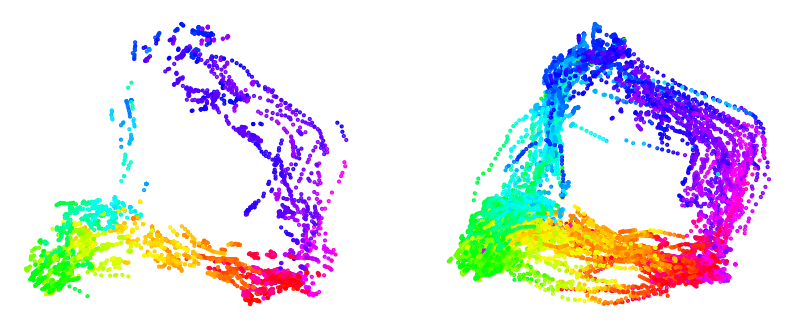

851.1429743766785
9
18
20220126_JA0153_dark1 18
using 5 cm/s as threshold
az occ stat 0.9722222222222222 run 1.0
(24000, 18)


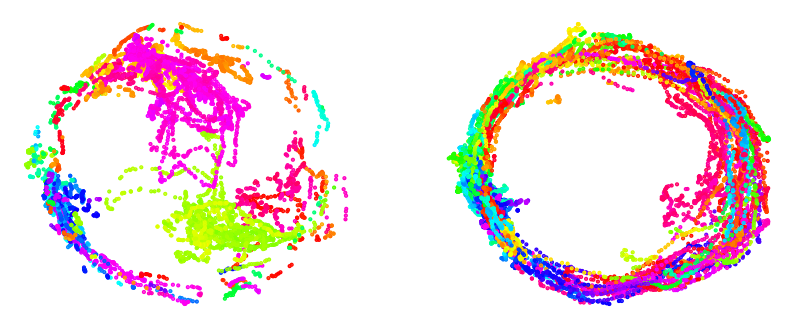

954.3668696880341
21
20220126_JA0153_darkHR1 21
using 5 cm/s as threshold
az occ stat 1.0 run 1.0
(24000, 21)



KeyboardInterrupt



In [186]:
ls_emb = []
shank_ls = ['shank0', 'shank1', 'shank2', 'shank3']
ls = []
to_plot = True
speed_thr = 5
# d_offring_idx = {}



# for animal in animal_ls:
#     tmp = data[(data.animal_name == animal)]
#     tmp_light = tmp[(tmp.condition == 'light1')
#                    & (tmp.hdc_flag == True)]
#     if tmp2.cids.unique().size < 8:
#         continue
    # include shankds with at least 3 HDC 
#     ls = [get_shank_from_ch(ch, 'h2') for ch in tmp_light.site.unique()]
#     hdc_count = np.array((ls.count(0), ls.count(1), ls.count(2), ls.count(3)))
#     shanks_in = np.where(hdc_count >= 3)[0]
#     ch_in = np.concatenate([ d_probe_conf['h2'][shank_ls[sh]] for sh in shanks_in])
#     print(f'HDC sites: {ls}')
#     print(f'shanks: {shanks_in}')
for k in d_hr_data.keys():
    start_time = time.time()
    # if 'light1' not in k:
    #     continue
    dts, animal_name, cond = k.split('_')[-3:]
    rec_session = dts + '_' + animal_name
    tmp_ephys = d_hr_data[k]['ephys']
    tmp_beh = d_hr_data[k]['beh']

    sess_hdc = d_ses_hdc[rec_session]
    tmp2 = tmp_ephys[(tmp_ephys.cids.isin(sess_hdc))]
    print(tmp2.cids.unique().size)
    if tmp2.cids.unique().size < 10:
        continue
    print(k, tmp2.cids.unique().size)

    _inp = tmp2.pivot(index = 'cids', columns = 'times', values = 'hz').values[:, :]
    yaw = tmp_beh['yaw'].values[:]
    if np.max(yaw) > 180:
        yaw = yaw - 180
        
    lin_vel = tmp_beh['lin_vel'].values[:]
    omega = tmp_beh['omega'].values[:]
#     lfp = tmp_ephys['lfp'].values[::5]
   
    try:
        stat_idx, run_idx = get_stat_run_epochs(lin_vel, window_size=5, speed_thr = speed_thr)
         # 10 samples = 1s
        stat_az_occ, run_az_occ = get_occ(yaw[stat_idx]), get_occ(yaw[run_idx])
   
        adj_threshold = 0
        while stat_az_occ < 0.9:
            adj_threshold += 0.5
            
            stat_idx, run_idx = get_stat_run_epochs(lin_vel, window_size=25, speed_thr = speed_thr + adj_threshold)
            stat_az_occ, run_az_occ = get_occ(yaw[stat_idx]), get_occ(yaw[run_idx])
            if run_az_occ < 0.9:
                break
    except Exception as e:
        print (e)
        continue 
    ls.append(speed_thr + adj_threshold)
    run_ratio = run_idx.size/lin_vel.size
    print(f'using {adj_threshold + speed_thr} cm/s as threshold')
    print(f'az occ stat {stat_az_occ} run {run_az_occ}')
    
    X = np.sqrt(_inp.T)
    print(X.shape)
    embedding = Isomap(n_neighbors = 250, n_components=6)
    isomap = embedding.fit_transform(X)
    # isomap = d_hr_emb[k]['isomap']
    # compute off manifold ratios
    # _, rad_manifold = compute_radius(isomap[:,0], isomap[:,1])
    # _, rad_manifold_stat = compute_radius(isomap[stat_idx,0], isomap[stat_idx,1])
    # _, rad_manifold_loc = compute_radius(isomap[run_idx,0], isomap[run_idx,1])

    # offmanifold_threshold = np.percentile(rad_manifold_loc, 10)
    # stat_off_manifold = np.sum(rad_manifold_stat < offmanifold_threshold)/rad_manifold_stat.size
    # d_offring_idx[k] = stat_off_manifold
    # print(f'off-manifold index {stat_off_manifold}')
    
    d_hr_emb[k] = {}
    d_hr_emb[k]['isomap'], d_hr_emb[k]['n_hdc'] = isomap, X.shape[1]
    d_hr_emb[k]['measured_yaw'], d_hr_emb[k]['lin_vel'], d_hr_emb[k]['omega'] = yaw, lin_vel, omega
    d_hr_emb[k]['dts'], d_hr_emb[k]['cond'], d_hr_emb[k]['animal_name'] = dts, cond, animal_name
    # d_hr_emb[k]['lfp_hdc'] = tmp2.groupby('times')['lfp'].mean().values
    
    d_hr_emb[k]['stat_idx'], d_hr_emb[k]['run_idx'] = stat_idx, run_idx
    d_hr_emb[k]['run_ratio'], d_hr_emb[k]['lin_vel_thr'] = run_ratio, (adj_threshold + speed_thr)
    d_hr_emb[k]['stat_az_occ'], d_hr_emb[k]['run_az_occ'] = stat_az_occ, run_az_occ
    
    if to_plot == True:
        f, ax = plt.subplots(1, 2, figsize = (10, 4))
        ax[0].scatter(isomap[stat_idx,0], isomap[stat_idx,1], s = 1, c = yaw[stat_idx], 
                                               vmin = -180, vmax = 180, cmap = 'hsv')
        ax[0].axis('off')
        ax[1].scatter(isomap[run_idx,0], isomap[run_idx,1], s = 1, c = yaw[run_idx], 
                                               vmin = -180, vmax = 180, cmap = 'hsv')
        ax[1].axis('off')
        plt.show()
    
    end_time = time.time()
    print(end_time - start_time)
    # break

In [175]:
# with open('d_hr_emb.p', 'wb') as handle:
#     pickle.dump(d_hr_emb, handle, protocol=pickle.HIGHEST_PROTOCOL)

In [15]:
d_hr_emb['20220712_MC022_darkHR1'].keys()

dict_keys(['isomap', 'n_hdc', 'stat_idx', 'run_idx', 'measured_yaw', 'lin_vel', 'omega', 'dts', 'cond', 'animal_name', 'lfp_hdc', 'run_ratio', 'lin_vel_thr', 'stat_az_occ', 'run_az_occ', 'h0', 'h1', 'h2', 'h1_bar', 'stat', 'run'])

In [16]:
# path = r'y:\Users\Alex\Data Analysis\d_hr_emb_light.p'
# with open(path, 'rb') as handle:
#     d_hr_emb_light = pickle.load(handle)
# d_hr_emb_light.keys()

### Fit betti barcodes

In [17]:
# path = r'y:\Users\Alex\Data Analysis\VR1 ATN data\Processed_paper\d_hr_manifold.p'
# with open(path, 'rb') as handle:
#     d_manifold_master = pickle.load(handle)
# d_manifold_master.keys()

In [91]:
df_emb.head()

,yaw,emb_x,emb_y,n_hdc,animal_name,rec_id,condition,date_name,vel,lfp,omega
0,28.0,2.036391,-16.645280,40,MC022,07_12_MC022_lightHR1,dark1,08_29,3.502467,11.373002,6.818182
1,31.0,4.141299,-16.550255,40,MC022,07_12_MC022_lightHR1,dark1,08_29,6.309273,52.872467,29.687500
2,31.0,5.791124,-16.204670,40,MC022,07_12_MC022_lightHR1,dark1,08_29,6.315572,-139.947304,47.500000
3,36.0,9.468758,-14.811897,40,MC022,07_12_MC022_lightHR1,dark1,08_29,6.320278,119.292150,64.473684
4,47.0,10.230874,-16.409802,40,MC022,07_12_MC022_lightHR1,dark1,08_29,6.323270,96.432532,86.842105


In [90]:
# d_manifold_master = {}
%whos DataFrame

Variable         Type         Data/Info
---------------------------------------
block_l1         DataFrame          animal_name   cids <...>[24000 rows x 17 columns]
block_tun        DataFrame       animal_name   cids dat<...>C038_lightHR1     False  
data             DataFrame           yaw      emb_x    <...>133020 rows x 11 columns]
df_emb           DataFrame           yaw      emb_x    <...>n[4800 rows x 11 columns]
df_hr_emb_2      DataFrame           yaw      emb_x    <...>133020 rows x 11 columns]
df_hr_master_1   DataFrame          animal_name   cids <...>148900 rows x 18 columns]
df_hr_master_2   DataFrame          animal_name   cids <...>690400 rows x 17 columns]
df_hr_tuning_1   DataFrame       animal_name   cids dat<...>[52788 rows x 16 columns]
df_hr_tuning_2   DataFrame       animal_name   cids dat<...>[67752 rows x 17 columns]
tmp              DataFrame           yaw      emb_x    <...>n[4800 rows x 11 columns]
tmp2             DataFrame          animal_name   cids <...>

In [94]:
for idx, k in enumerate(d_hr_emb.keys()):
    start_time = time.time()
    dts, animal_name, cond = k.split('_')[-3:]
    if 'light' not in k:
        continue
    tmp = d_hr_emb[k]
    n_hdc =  tmp['n_hdc'] 
    print(f'{k} # of HDC {n_hdc}')
    if n_hdc < 10:
        print('skipped')
        continue
    
    lin_speed = tmp['lin_vel']
    measured_yaw = tmp['measured_yaw']
    isomap_emb = tmp['isomap']
    
    isomap_yaw, dec_err, _ = decode_az_isomap(isomap_emb[:, 0], isomap_emb[:, 1], measured_yaw[:])
    stat_idx, run_idx = tmp['stat_idx'], tmp['run_idx']
    print('stat', stat_idx.size, 'run', run_idx.size)
    # at least 10s of data
    if stat_idx.size < 100 or run_idx.size < 100:
        continue
        
    stat_dec_err = round(np.mean(abs(((measured_yaw[stat_idx] - isomap_yaw[stat_idx]) + 180)%360 - 180)), 3)
    loc_dec_err = round(np.mean(abs(((measured_yaw[run_idx] - isomap_yaw[run_idx]) + 180)%360 - 180)), 3)

    # full rec
    h0, h1, h2 = compute_betti(isomap_emb)
    d_hr_emb[k]['h0'], d_hr_emb[k]['h1'], d_hr_emb[k]['h2'] = h0, h1, h2
    to_plot, h1_bar = get_long_bettibars(h0, h1, h2)
    d_hr_emb[k]['h1_bar'] = h1_bar
    
    # stat speed < 6cm/s
    h0, h1, h2 = compute_betti(isomap_emb[stat_idx, :])
    d_hr_emb[k]['stat'] = {}
    d_hr_emb[k]['stat']['h0'], d_hr_emb[k]['stat']['h1'], d_hr_emb[k]['stat']['h2'] = h0, h1, h2
    to_plot, h1_bar = get_long_bettibars(h0, h1, h2)
    d_hr_emb[k]['stat']['h1_bar'] = h1_bar
    d_hr_emb[k]['stat']['dec_err'] = stat_dec_err

    # locom
    h0, h1, h2 = compute_betti(isomap_emb[run_idx, :])
    d_hr_emb[k]['run'] = {}
    d_hr_emb[k]['run']['h0'], d_hr_emb[k]['run']['h1'], d_hr_emb[k]['run']['h2'] = h0, h1, h2
    to_plot, h1_bar = get_long_bettibars(h0, h1, h2)
    d_hr_emb[k]['run']['h1_bar'] = h1_bar
    d_hr_emb[k]['run']['dec_err'] = loc_dec_err

    end_time = time.time()
    print(end_time - start_time)
#     break

20220126_JA0153_dark1 # of HDC 18
stat 2505 run 2295
622.3612003326416
20220126_JA0153_darkHR1 # of HDC 21
stat 2355 run 2445
804.2284979820251
20220302_JA0162_dark1 # of HDC 11
stat 1715 run 3085
876.4007425308228
20220302_JA0162_darkHR1 # of HDC 10
stat 3730 run 1070
975.8693211078644
20220419_JA0164_dark1 # of HDC 11
stat 2315 run 2485
884.6525025367737
20220419_JA0164_darkHR1 # of HDC 11
stat 2640 run 2160
946.3967649936676
20220819_JA0178_dark1 # of HDC 30
stat 2055 run 2745
567.8448660373688
20220819_JA0178_darkHR1 # of HDC 28
stat 4700 run 100
867.7460281848907
20220822_JA0178_dark1 # of HDC 27
stat 2435 run 2365
763.9364230632782
20220822_JA0178_darkHR1 # of HDC 27
stat 2885 run 1915
655.8651285171509
20220906_JA0178_dark1 # of HDC 11
stat 1160 run 3640
530.3361430168152
20220906_JA0178_darkHR1 # of HDC 11
stat 3800 run 1000
794.8615484237671
20220812_JA0181_dark1 # of HDC 18
stat 1375 run 3425
791.9840106964111
20220812_JA0181_darkHR1 # of HDC 17
stat 4080 run 720
810.68189477

In [62]:
3000/60

50.0

In [255]:
# with open('d_hr_emb.p', 'wb') as handle:
#     pickle.dump(d_hr_emb, handle, protocol=pickle.HIGHEST_PROTOCOL)


### Plot betti bardcodes

20220126_JA0153_darkHR1
H1 bar length 7.624943733215332 dec err 44.606875032916896
off_manifold_index 0.39166666666666666


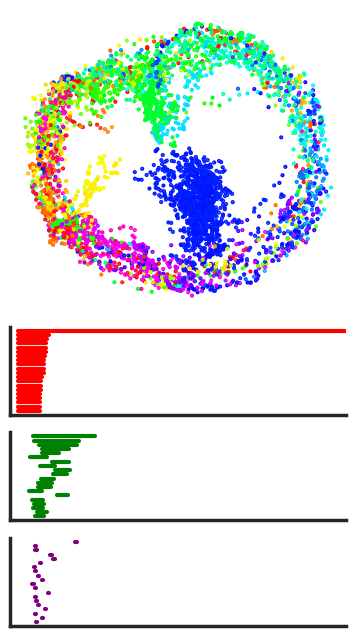

20220302_JA0162_darkHR1
H1 bar length 7.835114240646362 dec err 84.96415486232226
off_manifold_index 0.7195833333333334


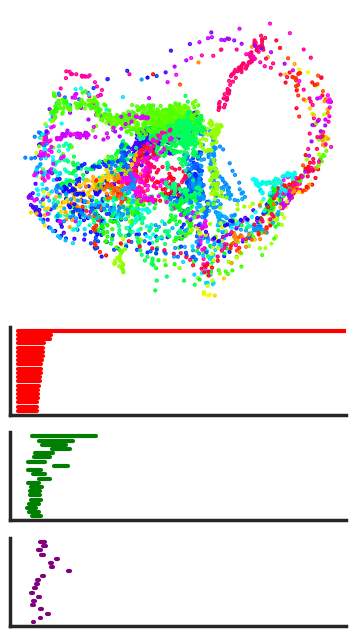

20220419_JA0164_darkHR1
H1 bar length 6.143603444099426 dec err 50.28684961874105
off_manifold_index 0.47479166666666667


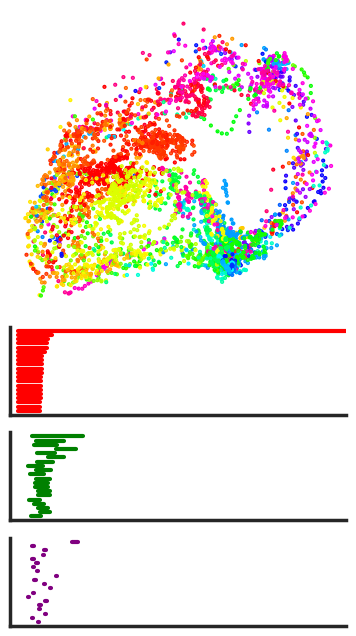

20220819_JA0178_darkHR1
H1 bar length 4.501748561859131 dec err 79.27942034056767
off_manifold_index 0.6572916666666667


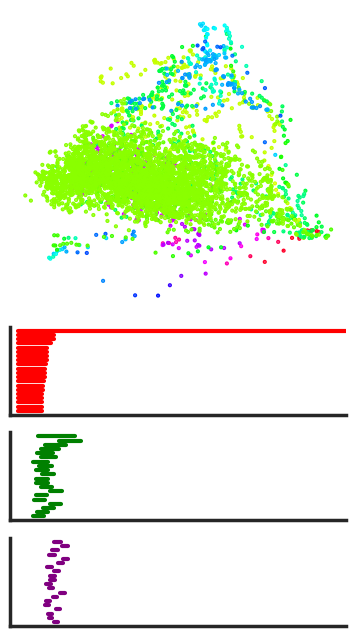

20220822_JA0178_darkHR1
H1 bar length 9.285776853561401 dec err 40.63909385192365
off_manifold_index 0.3854166666666667


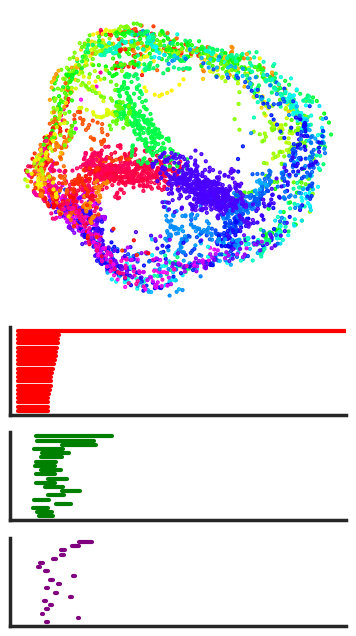

20220906_JA0178_darkHR1
H1 bar length 3.8326234817504883 dec err 64.84400874339568
off_manifold_index 0.4825


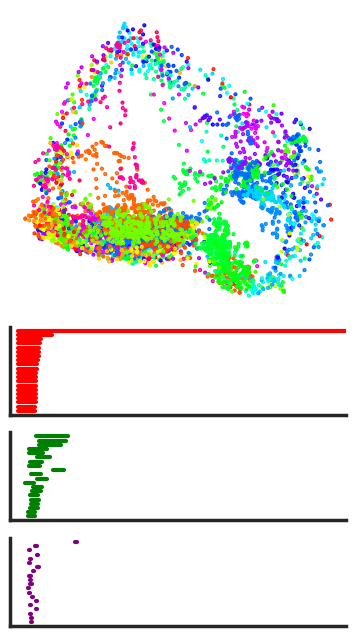

20220812_JA0181_darkHR1
H1 bar length 7.302195310592651 dec err 31.880381227295306
off_manifold_index 0.6066666666666667


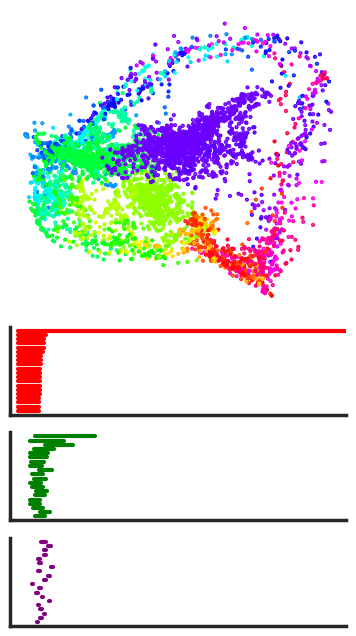

20220815_JA0181_darkHR1
H1 bar length 14.575676321983337 dec err 60.60757055117957
off_manifold_index 0.5797916666666667


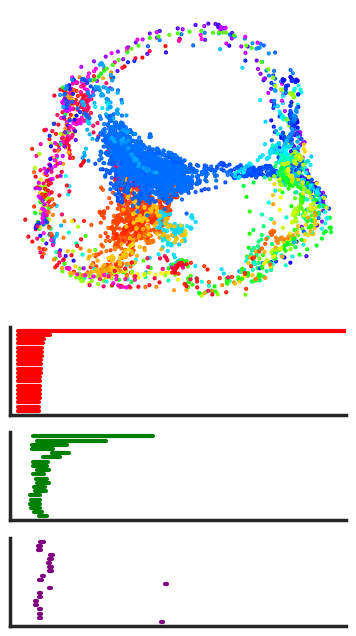

20220818_JA0181_darkHR1
H1 bar length 8.237065553665161 dec err 79.99461641615017
off_manifold_index 0.33


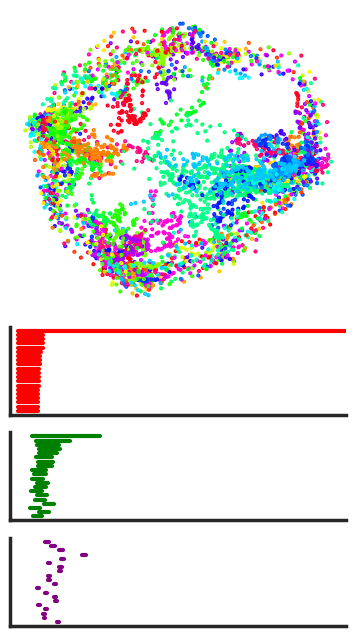

20220712_MC022_darkHR1
H1 bar length 28.083369255065918 dec err 44.626237091215465
off_manifold_index 0.486875


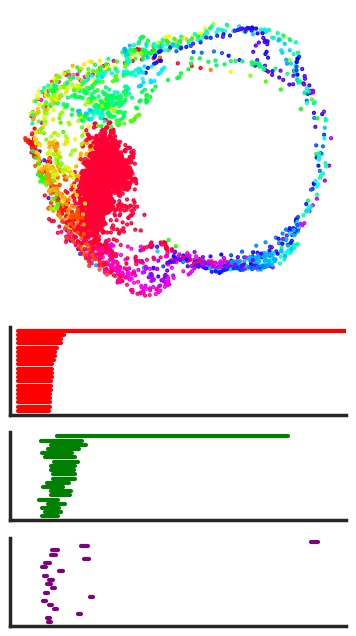

In [298]:
col_list = ['red', 'green', 'purple']
coi = ['light1', 'lightHR1']
angles = np.arange(0, 380, 20)
h1_bar_max = 40
ls = []
ls_emb, ls_h = [], []
# roi = ['20220126_JA0153_lightHR1', '20220126_JA0153_light1']

for k in d_hr_emb.keys():

    dts, mouse_id, cond = k.split('_')[-3:]
    # if k not in roi:
    #     continue

    if 'darkHR1' not in k:
        continue
    
    fig = plt.figure(figsize=(12, 8))
    gs = gridspec.GridSpec(6, 8)
    rec_session = mouse_id + '_' + dts

    tmp = d_hr_emb[k]
    isomap = tmp['isomap']
    measured_yaw = tmp['measured_yaw']
    isomap_yaw, dec_err, _ = decode_az_isomap(isomap[:, 0], isomap[:, 1], measured_yaw[:])
    lin_speed = tmp['lin_vel']
    h1_bar = tmp['h1_bar']


    try:
        stat_idx, run_idx = get_stat_run_epochs(lin_speed, window_size=5, speed_thr = 5)
        # _, rot_idx = get_stat_run_epochs(ang_vel, window_size=5, speed_thr = 2)
    except:
        continue
        
    # compute off manifold ratios
    run_mask = np.zeros(lin_speed.size, dtype=bool)
    run_mask[run_idx] = True
    # compute off manifold ratios
    # _, rad_manifold = compute_radius_runmask(isomap[:,0], isomap[:,1], run_mask)
    _, rad_manifold = compute_radius_old(isomap[:,0], isomap[:,1])
    r90  = np.percentile(rad_manifold, 90)
    # 
    threshold = (r90 - 0.3*r90)

    off_ring = rad_manifold < threshold
    off_ring_ratio = np.sum(off_ring)/rad_manifold.size
    
    print(f'{k}')
    print(f'H1 bar length {h1_bar} dec err {dec_err}')
    print(f'off_manifold_index {off_ring_ratio}')
    ax = fig.add_subplot(gs[0:3, 0:3])
    ax.scatter(isomap[:,0], isomap[:,1], s = 1, c = measured_yaw[:], 
                                           vmin = -180, vmax = 180, cmap = 'hsv')
    # ls_emb.append(pd.DataFrame({'mouse_id':mouse_id, 'isomap_x': isomap[:,0], 'isomap_y':isomap[:,1], 'yaw': measured_yaw[:], 'cond': cond, }))
    ax.axis('off')
    # ax.set_xlim(-40, 40)
    # ax.set_ylim(-40, 40)
    plt.xticks([])

    h0 = tmp['h0']
    h1 = tmp['h1']
    h2 = tmp['h2']    
    to_plot, h1_bar_run = get_long_bettibars(h0, h1, h2)
    # ls_h.append(pd.DataFrame({'mouse_id':mouse_id, 'h0': np.ndarray.flatten(to_plot[0]), 'h1':np.ndarray.flatten(to_plot[1]), 'cond': cond,
    #                           'h2':np.ndarray.flatten(to_plot[2])}))

    for curr_betti, curr_bar in enumerate(to_plot):
        ax = fig.add_subplot(gs[curr_betti +3: curr_betti + 4, :3])
        for i, interval in enumerate((curr_bar)):
            ax.plot([interval[0], interval[1]], [i, i], color=col_list[curr_betti], lw=3)
        ax.set_xlim([-1, 40])
        plt.xticks([])
        plt.yticks([])
        
    plt.show()
    
#     tmp_df = pd.DataFrame({'rec_id': k,  'cond': cond,  'dts': dts, 'mouse_id': mouse_id,
#                        'epoch': 'full', 'h1_bar': h1_bar, 'dec_err': dec_err, 'rec_session':rec_session,
#                        'off_manifold_index': off_ring_ratio}, index = [0])
#     ls.append(tmp_df)    
    
#     # break
    
    
# df_betti = pd.concat(ls)
# df_betti.head()

In [211]:
# df_out = pd.concat(ls_emb)
# df_out.to_excel(filepath, index = True)

In [210]:
df_out.head()

,mouse_id,isomap_x,isomap_y,yaw,cond
0,JA0153,15.545672,9.100823,33.730760,light1
1,JA0153,14.385785,9.247178,36.849392,light1
2,JA0153,14.455403,9.325347,33.730760,light1
3,JA0153,15.424576,8.907585,33.730760,light1
4,JA0153,15.228578,9.509756,33.730760,light1


C:\Users\01\AppData\Local\Temp\ipykernel_16696\4153377996.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data = _inp_plot, x = 'cond', y = y, palette=pal)


<Axes: xlabel='cond', ylabel='off_manifold_index'>

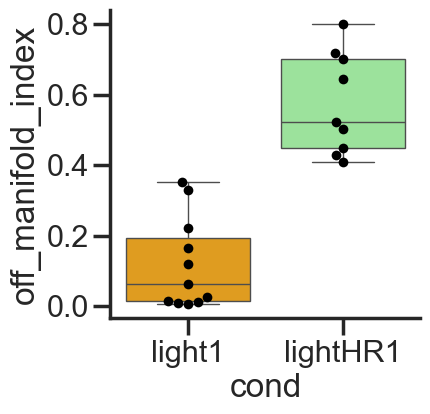

In [200]:
f, ax  = plt.subplots(figsize = (4, 4))

_inp_plot = df_betti
y = 'off_manifold_index'
pal = ['orange', 'lightgreen']
sns.boxplot(data = _inp_plot, x = 'cond', y = y, palette=pal)
sns.swarmplot(data = _inp_plot, x = 'cond', y = y, size = 7, 
              color = 'k', dodge = True, legend = False)

# plt.savefig(f'HR_boxplot_{y}_full.pdf', transparent = True)

In [201]:
_inp_plot.groupby('cond')[y].describe()

,count,mean,std,min,25%,50%,75%,max
cond,,,,,,,,
light1,11.0,0.120170,0.130621,0.006250,0.014063,0.063125,0.192917,0.353125
lightHR1,9.0,0.575796,0.143445,0.409167,0.449792,0.523750,0.701458,0.801055


In [202]:
a1 = _inp_plot[(_inp_plot.cond == 'light1')][y].values
b1 = _inp_plot[(_inp_plot.cond == 'lightHR1')][y].values

stat, pval = stats.mannwhitneyu(a1, b1)
print(f'{coi[0]} vs {coi[1]} {stat} {pval}')


light1 vs lightHR1 0.0 0.00019709416773215242


In [203]:
_inp_plot.head()

,rec_id,cond,dts,mouse_id,epoch,h1_bar,dec_err,rec_session,off_manifold_index
0,20211207_JA0144_light1,light1,20211207,JA0144,full,6.151794,25.458207,JA0144_20211207,0.353125
0,20220126_JA0153_light1,light1,20220126,JA0153,full,15.218874,25.684499,JA0153_20220126,0.165000
0,20220126_JA0153_lightHR1,lightHR1,20220126,JA0153,full,4.849484,31.401931,JA0153_20220126,0.429583
0,20220302_JA0162_light1,light1,20220302,JA0162,full,15.419246,16.881288,JA0162_20220302,0.120625
0,20220302_JA0162_lightHR1,lightHR1,20220302,JA0162,full,17.937344,15.546799,JA0162_20220302,0.523750


In [205]:
# filepath = save_dir / f'out.xlsx'
# _inp_plot['cond'] = _inp_plot['cond'].replace({'light1': 'RL', 'lightHR1': 'RL-Hfix'})
# _inp_plot.to_excel(filepath, index = True)

### Stat vs run

20211207_JA0144_light1, # of hdc 10
dec err stat:27.552, run:24.376
az occ stat:0.9166666666666666, run:1.0, off-manifold index 0.15535168195718654
stat [1.3857176303863525, 5.95674729347229]
run [1.3292574882507324, 6.397860765457153]


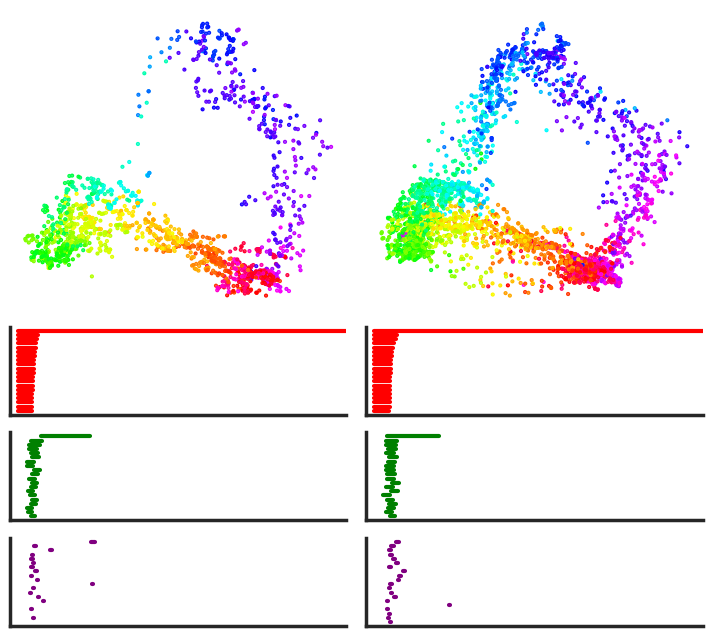

20220126_JA0153_light1, # of hdc 18
dec err stat:22.769, run:27.529
az occ stat:0.9166666666666666, run:1.0, off-manifold index 0.17956989247311828
stat [4.525405645370483, 14.210235595703125]
run [4.286016583442688, 15.542181611061096]


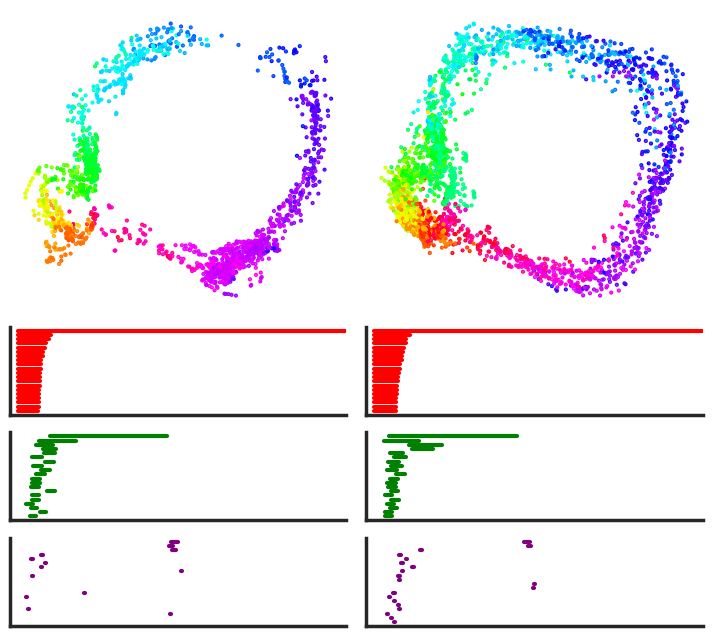

20220126_JA0153_lightHR1, # of hdc 21
dec err stat:28.507, run:35.188
az occ stat:0.9444444444444444, run:1.0, off-manifold index 0.625
stat [3.0435123443603516, 5.941466569900513]
run [5.590404033660889, 10.591240048408508]


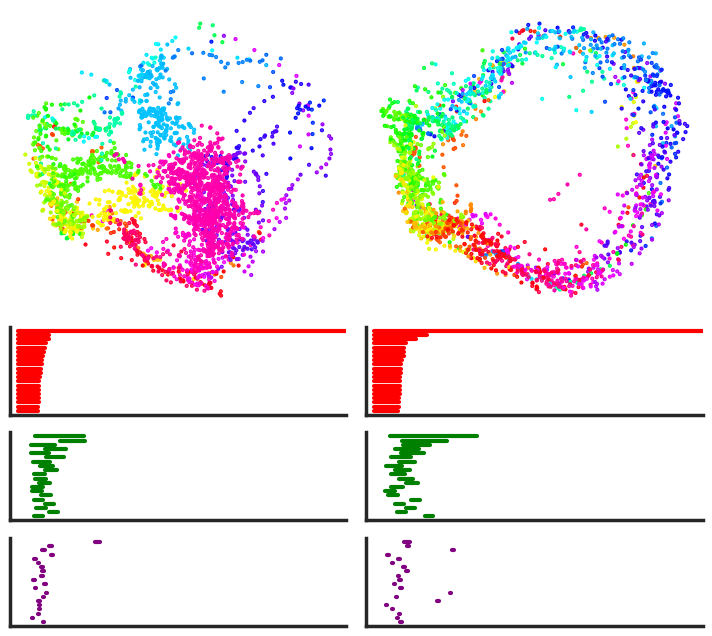

20220302_JA0162_light1, # of hdc 11
dec err stat:17.754, run:16.498
az occ stat:0.9444444444444444, run:1.0, off-manifold index 0.3679180887372014
stat [1.851778268814087, 15.150577068328857]
run [2.0431030988693237, 15.609477877616882]


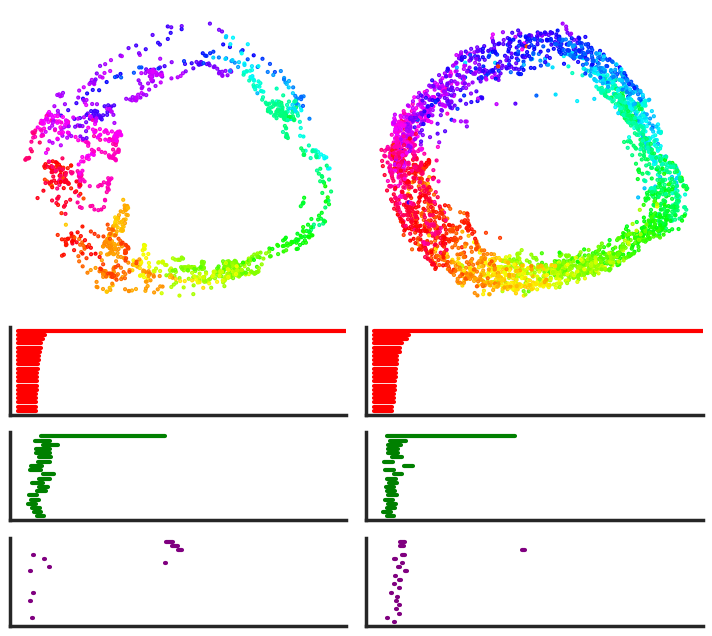

20220302_JA0162_lightHR1, # of hdc 10
dec err stat:15.916, run:14.402
az occ stat:0.9166666666666666, run:1.0, off-manifold index 0.5286501377410469
stat [8.430671572685242, 16.76536536216736]
run [2.440799832344055, 18.15315568447113]


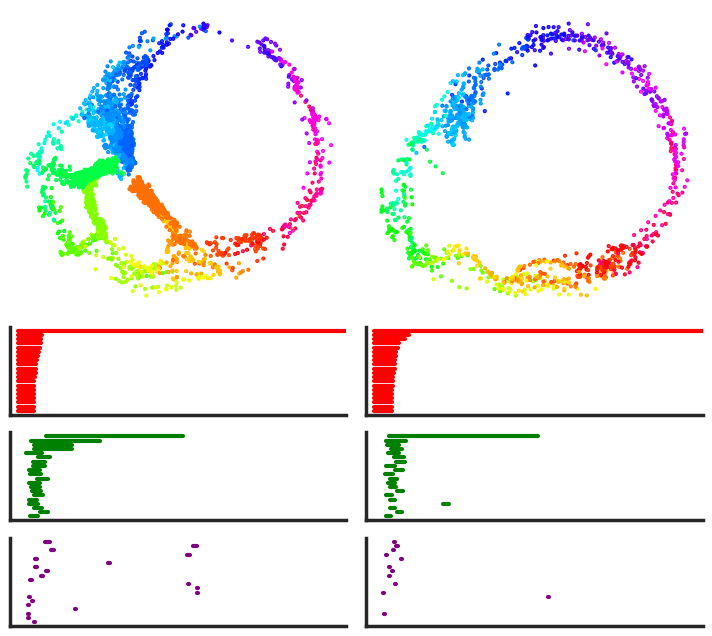

20220419_JA0164_light1, # of hdc 11
dec err stat:20.249, run:21.604
az occ stat:0.9722222222222222, run:1.0, off-manifold index 0.18181818181818182
stat [1.3991785049438477, 17.210919857025146]
run [1.5191869735717773, 16.867080807685852]


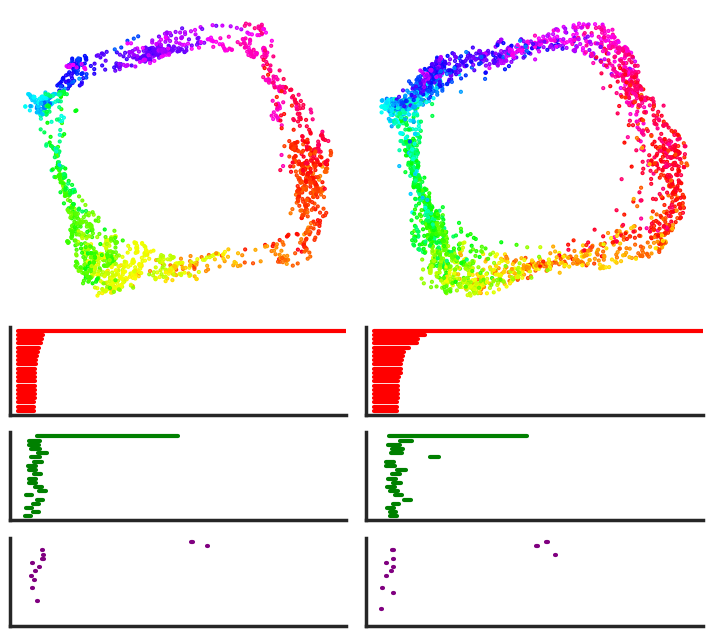

20220419_JA0164_lightHR1, # of hdc 10
dec err stat:70.698, run:82.488
az occ stat:0.2777777777777778, run:0.5, off-manifold index 0.806060606060606
stat [1.898045539855957, 2.865591526031494]
run [3.655510663986206, 7.862245559692383]


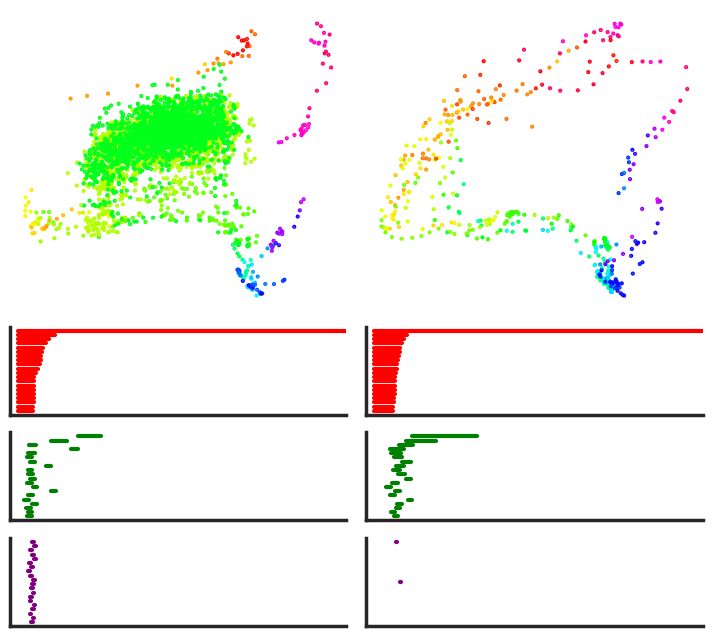

20220819_JA0178_light1, # of hdc 30
dec err stat:32.689, run:28.616
az occ stat:0.9444444444444444, run:1.0, off-manifold index 0.18125
stat [3.9183907508850098, 31.732080459594727]
run [3.3621225357055664, 32.7034330368042]


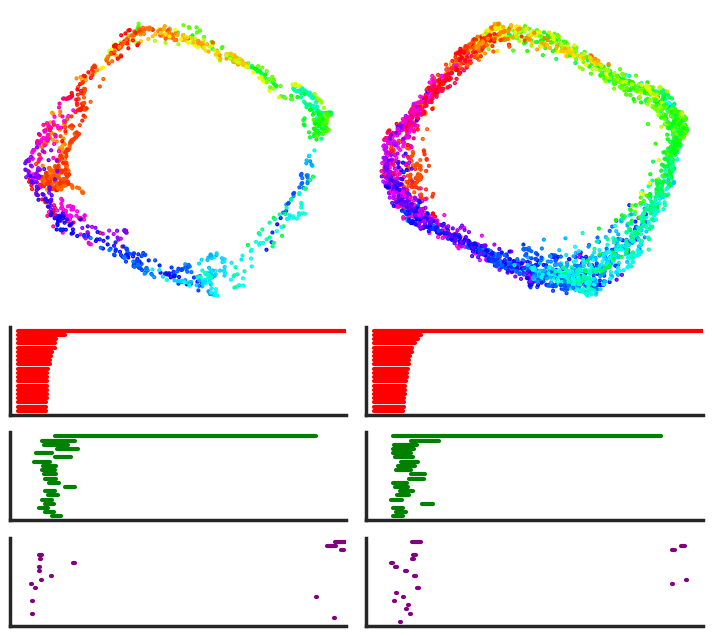

20220819_JA0178_lightHR1, # of hdc 30
dec err stat:27.747, run:20.172
az occ stat:0.8333333333333334, run:0.4166666666666667, off-manifold index 0.747105561861521
stat [10.834474086761475, 19.455692768096924]
run [2.5871095657348633, 25.71876573562622]


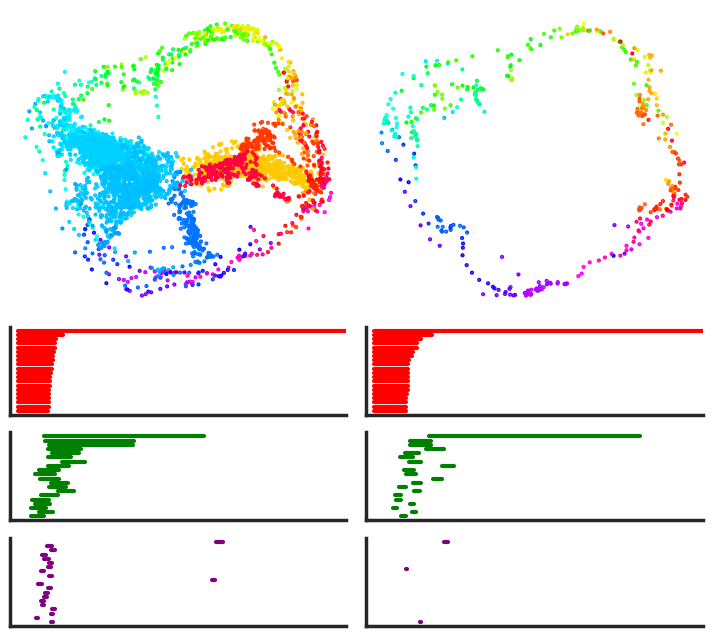

20220822_JA0178_light1, # of hdc 27
dec err stat:23.761, run:17.459
az occ stat:0.9166666666666666, run:1.0, off-manifold index 0.4818181818181818
stat [11.93638563156128, 16.46520185470581]
run [4.556717395782471, 23.243962287902832]


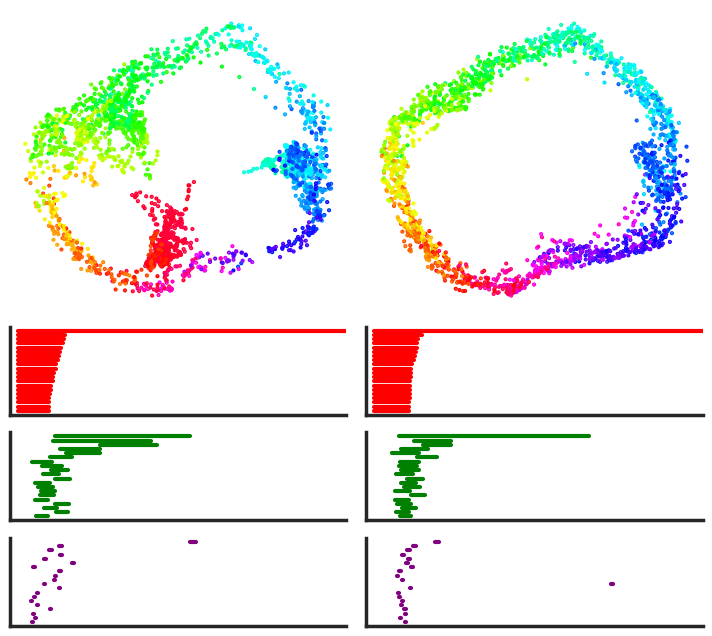

20220822_JA0178_lightHR1, # of hdc 27
dec err stat:51.179, run:33.691
az occ stat:0.8611111111111112, run:0.8888888888888888, off-manifold index 0.34164810690423164
stat [8.196605920791626, 9.951374053955078]
run [4.545161724090576, 17.439497470855713]


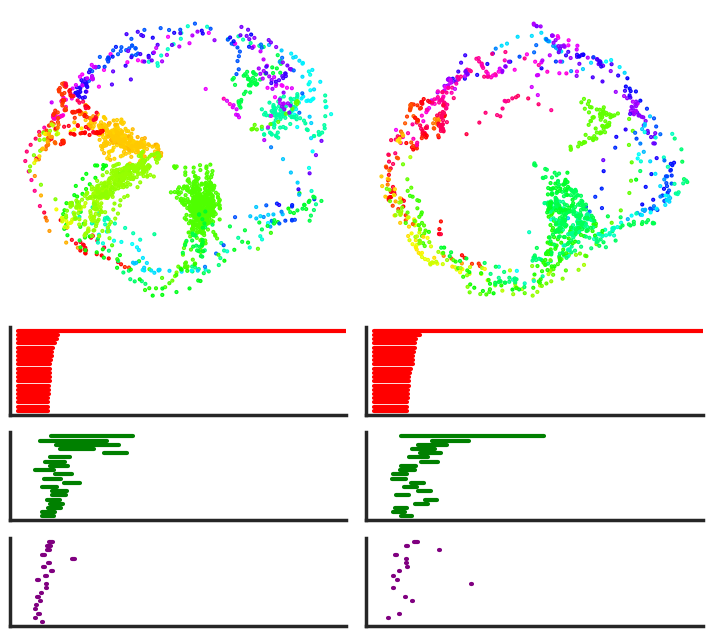

20220906_JA0178_light1, # of hdc 11
dec err stat:23.943, run:22.342
az occ stat:0.9444444444444444, run:1.0, off-manifold index 0.23013698630136986
stat [4.538190960884094, 7.4392640590667725]
run [3.1265594959259033, 9.496805310249329]


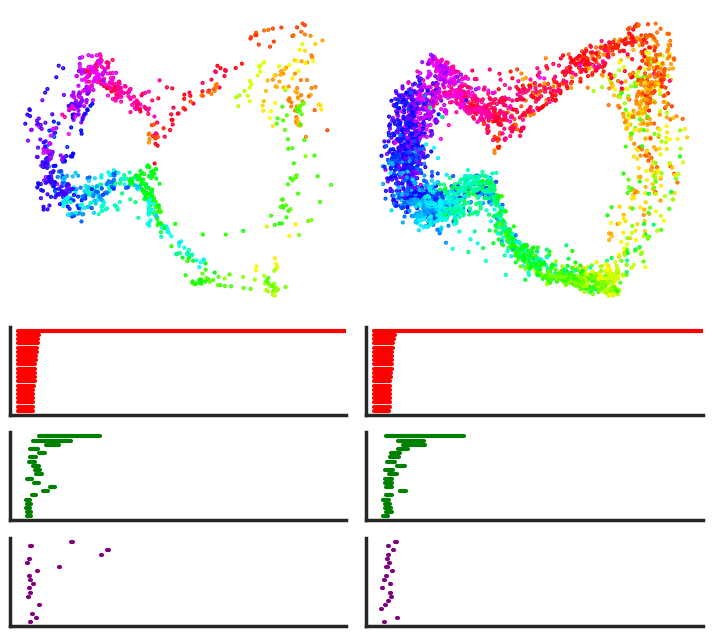

20220812_JA0181_light1, # of hdc 17
dec err stat:16.462, run:18.416
az occ stat:0.9166666666666666, run:1.0, off-manifold index 0.04611650485436893
stat [1.6732969284057617, 14.911880254745483]
run [1.7312281131744385, 14.42552900314331]


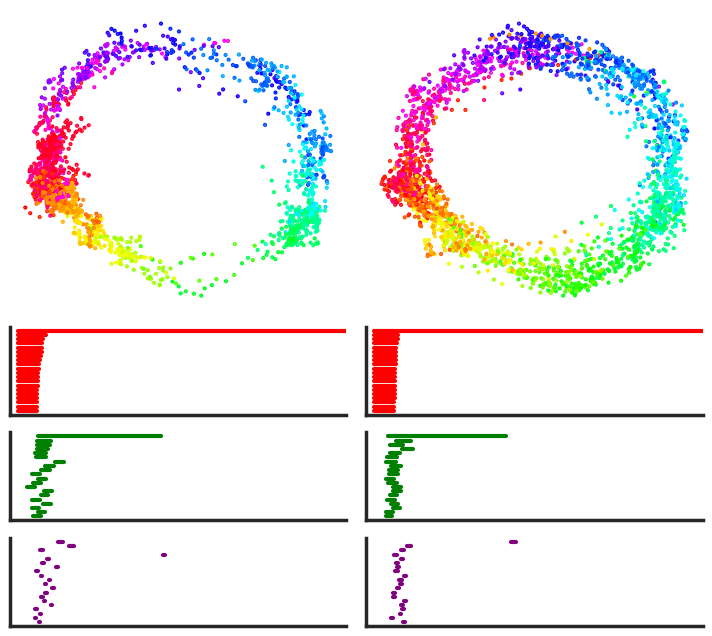

20220812_JA0181_lightHR1, # of hdc 18
dec err stat:28.738, run:47.096
az occ stat:0.7777777777777778, run:0.8888888888888888, off-manifold index 0.3709483793517407
stat [4.283714294433594, 4.545577526092529]
run [3.203655242919922, 9.392216444015503]


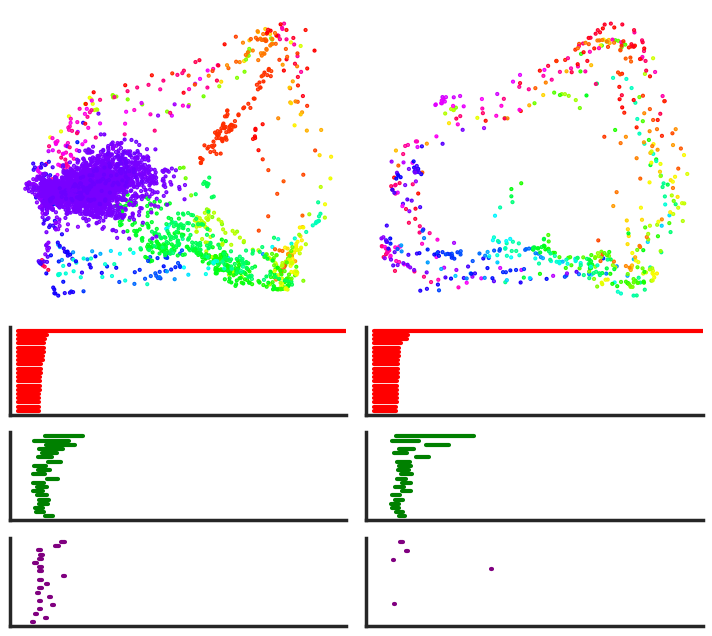

20220815_JA0181_light1, # of hdc 16
dec err stat:54.585, run:63.572
az occ stat:0.9166666666666666, run:0.9722222222222222, off-manifold index 0.05
stat [1.3007071018218994, 22.717576026916504]
run [1.5687766075134277, 21.675047039985657]


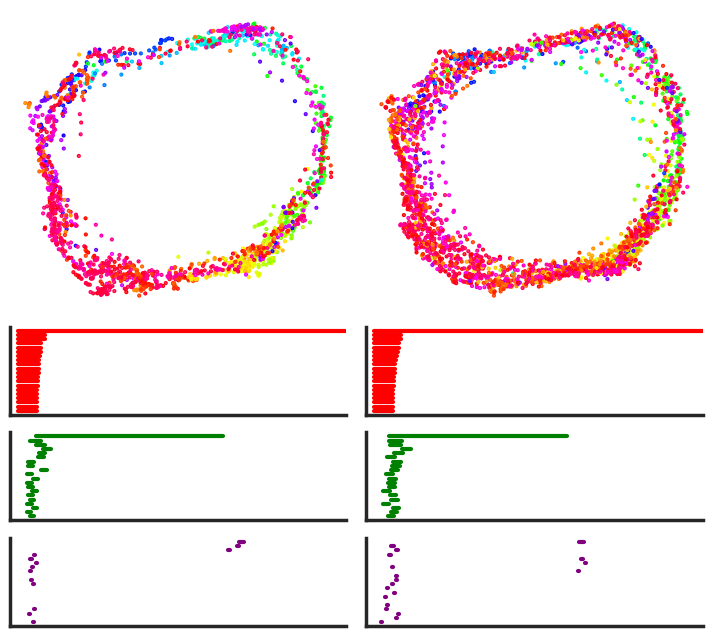

20220815_JA0181_lightHR1, # of hdc 16
dec err stat:50.819, run:31.343
az occ stat:0.5, run:0.8888888888888888, off-manifold index 0.905683192261185
stat [4.18500280380249, 9.3815336227417]
run [3.000072956085205, 17.355478525161743]


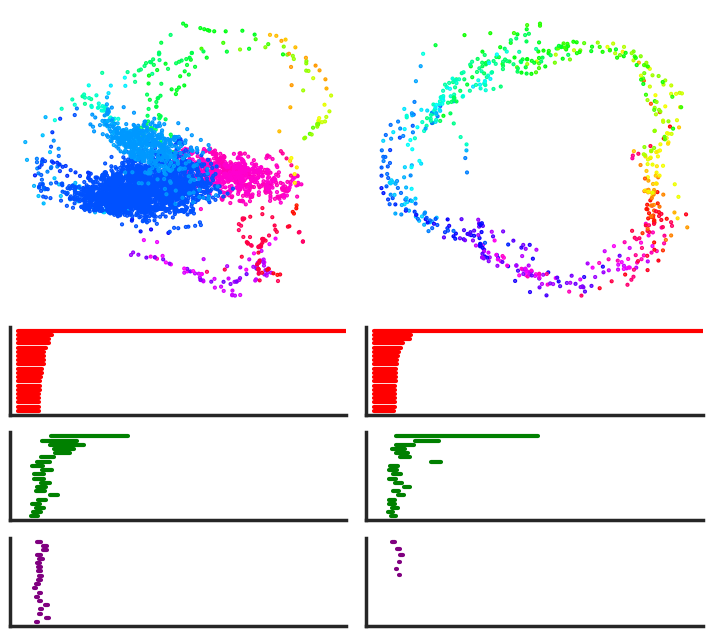

20220818_JA0181_light1, # of hdc 14
dec err stat:12.31, run:14.578
az occ stat:0.9166666666666666, run:1.0, off-manifold index 0.08284518828451883
stat [1.9741511344909668, 18.159974575042725]
run [1.2689244747161865, 20.162482380867004]


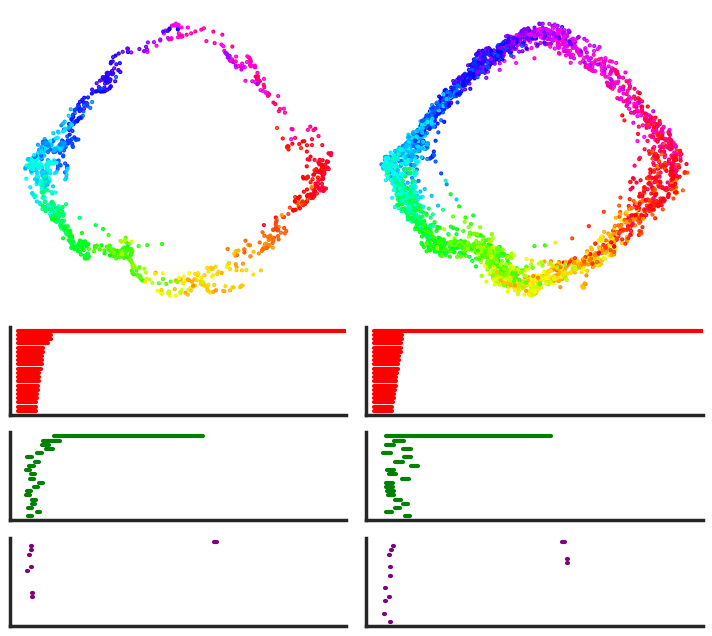

20220818_JA0181_lightHR1, # of hdc 14
dec err stat:37.536, run:17.888
az occ stat:0.6388888888888888, run:0.19444444444444445, off-manifold index 0.8404371584699454
stat [3.6835460662841797, 8.261001825332642]
run [1.3845109939575195, 13.369762420654297]


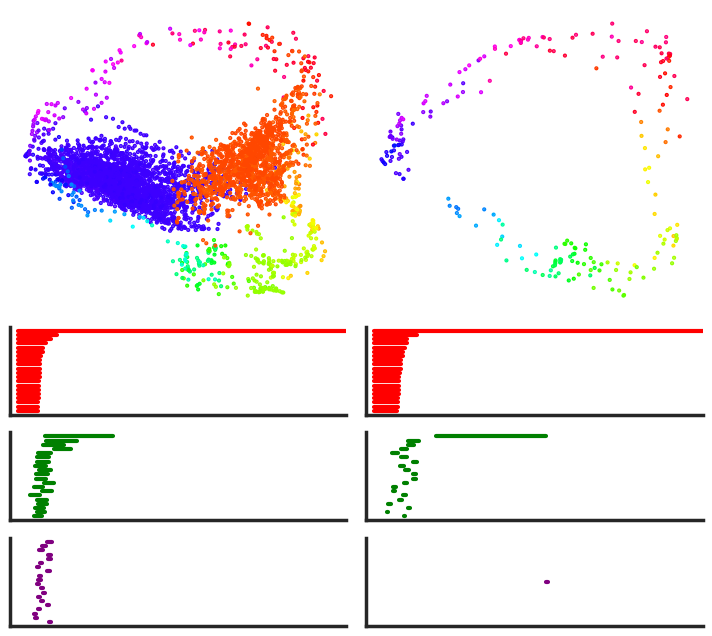

20220712_MC022_light1, # of hdc 41
dec err stat:15.321, run:18.265
az occ stat:0.9166666666666666, run:1.0, off-manifold index 0.02510460251046025
stat [2.3507261276245117, 34.39853286743164]
run [5.786808490753174, 40.50256037712097]


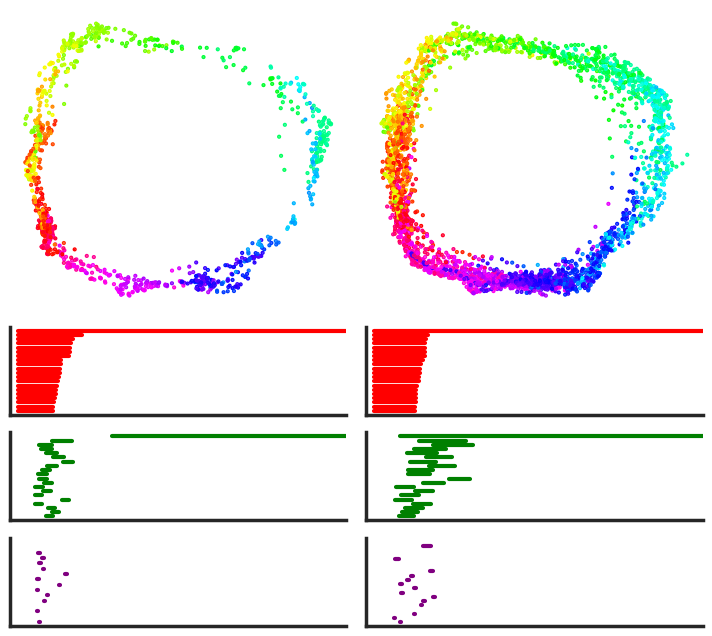

20220712_MC022_lightHR1, # of hdc 41
dec err stat:36.691, run:41.052
az occ stat:0.9166666666666666, run:0.9444444444444444, off-manifold index 0.4782945736434108
stat [6.186478614807129, 9.248993873596191]
run [7.726228713989258, 17.2743558883667]


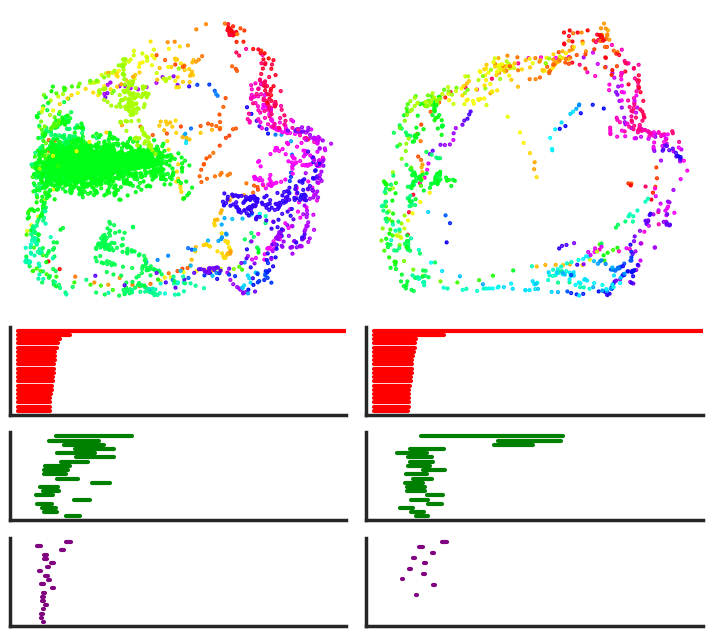

20220126_JA0153_dark1, # of hdc 18
dec err stat:78.447, run:57.038
az occ stat:0.9444444444444444, run:1.0, off-manifold index 0.564870259481038
stat [6.918473243713379, 8.241300582885742]
run [2.4111011028289795, 15.354323625564575]


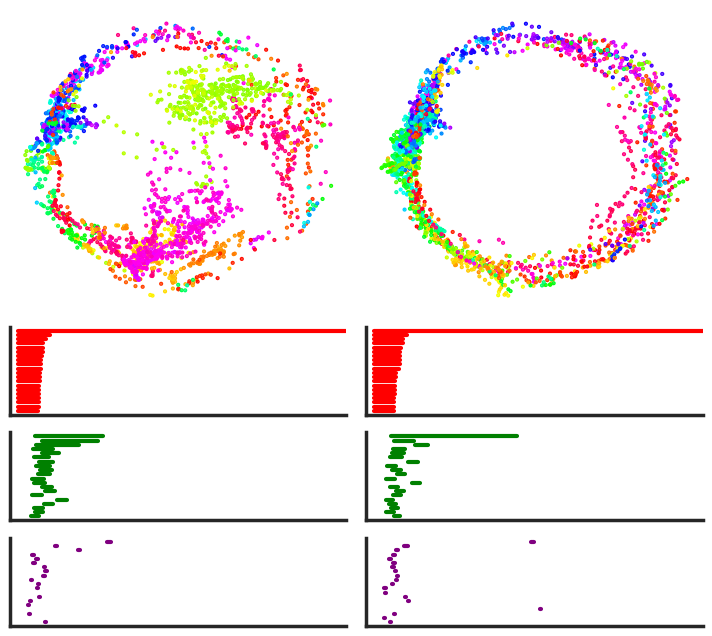

20220126_JA0153_darkHR1, # of hdc 21
dec err stat:36.301, run:52.607
az occ stat:0.9444444444444444, run:1.0, off-manifold index 0.7010615711252653
stat [4.681293725967407, 5.9382500648498535]
run [2.1332075595855713, 13.74454116821289]


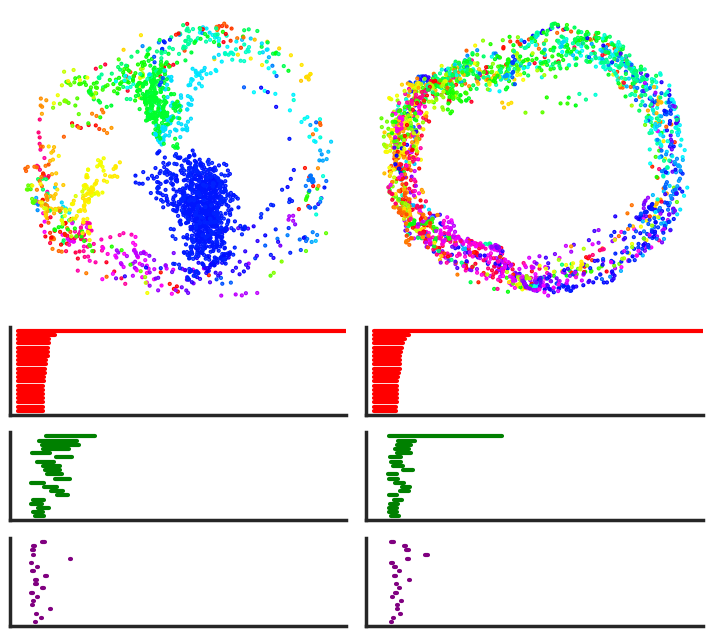

20220302_JA0162_dark1, # of hdc 11
dec err stat:50.007, run:64.498
az occ stat:0.9722222222222222, run:1.0, off-manifold index 0.5521865889212828
stat [3.206386089324951, 5.308832168579102]
run [1.9143850803375244, 9.504530906677246]


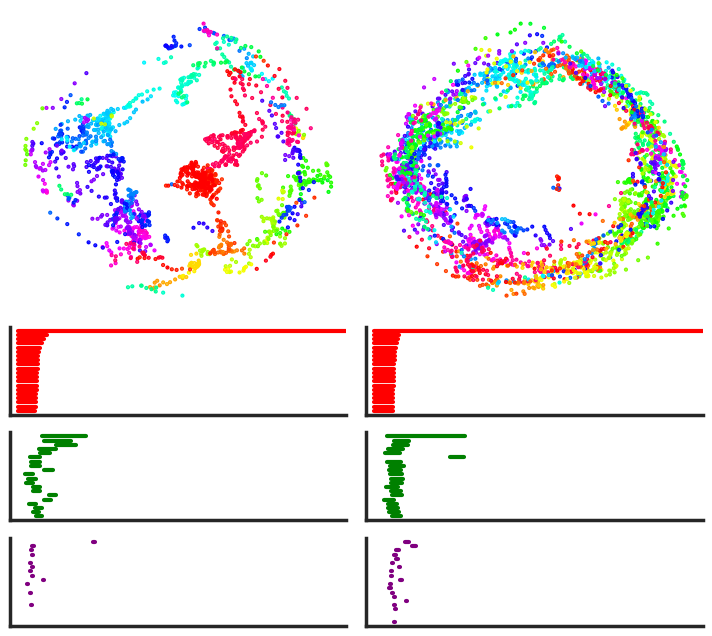

20220302_JA0162_darkHR1, # of hdc 10
dec err stat:81.896, run:95.661
az occ stat:0.9444444444444444, run:0.7777777777777778, off-manifold index 0.252991452991453
stat [3.9906888008117676, 7.580846548080444]
run [2.2783894538879395, 7.034291982650757]


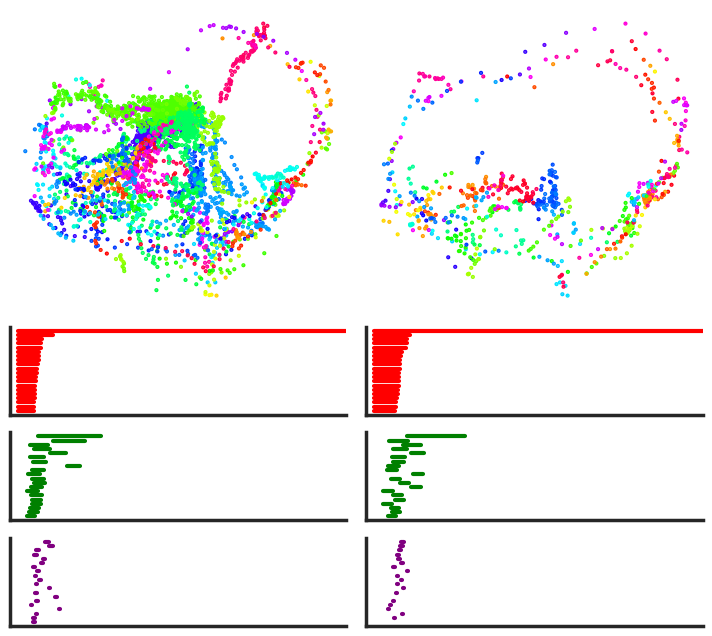

20220419_JA0164_dark1, # of hdc 11
dec err stat:26.14, run:27.902
az occ stat:0.9166666666666666, run:1.0, off-manifold index 0.3002159827213823
stat [2.3456664085388184, 6.102039575576782]
run [2.313798189163208, 8.057819128036499]


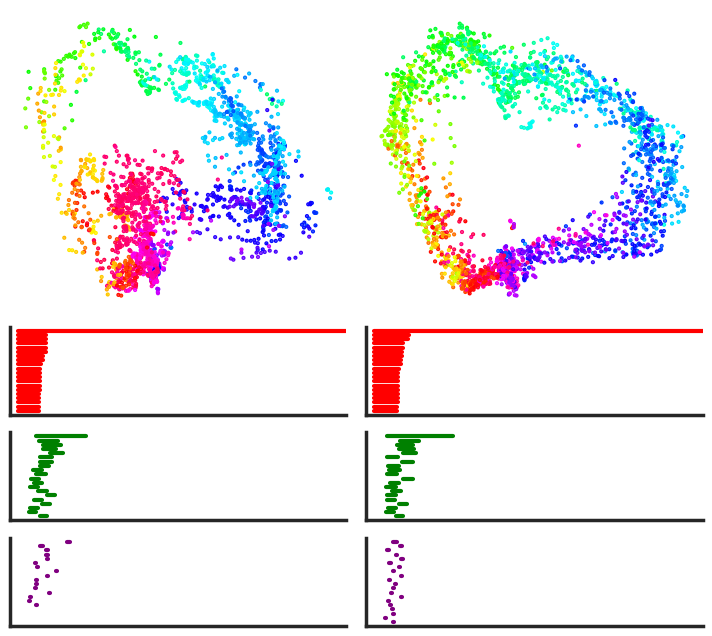

20220419_JA0164_darkHR1, # of hdc 11
dec err stat:43.694, run:58.344
az occ stat:0.9444444444444444, run:1.0, off-manifold index 0.2265151515151515
stat [2.4810194969177246, 5.29796290397644]
run [3.7647337913513184, 6.440408706665039]


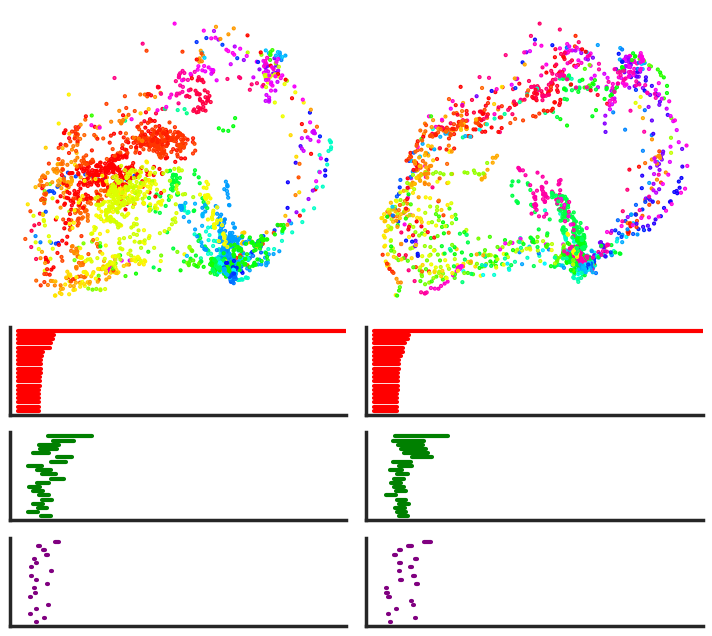

20220819_JA0178_dark1, # of hdc 30
dec err stat:30.167, run:22.859
az occ stat:0.9444444444444444, run:1.0, off-manifold index 0.48175182481751827
stat [6.071968078613281, 12.187607765197754]
run [4.070102214813232, 15.893311977386475]


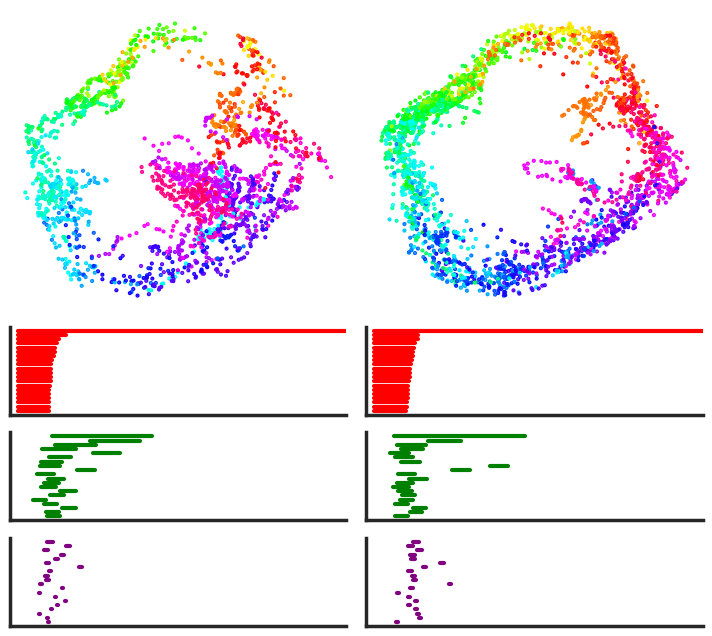

20220819_JA0178_darkHR1, # of hdc 28
dec err stat:78.519, run:115.033
az occ stat:0.4166666666666667, run:0.0, off-manifold index 0.6935991605456453
stat [2.5068347454071045, 4.46200966835022]
run [1.2199363708496094, 1.3839402198791504]


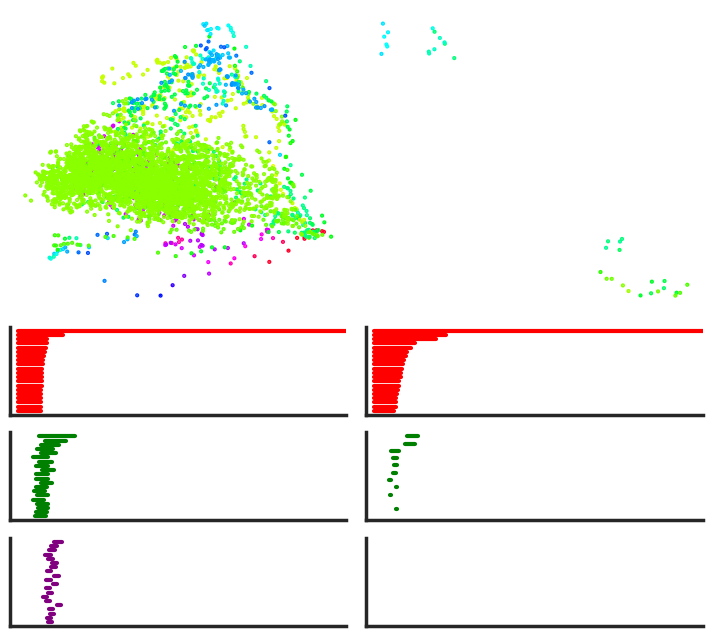

20220822_JA0178_dark1, # of hdc 27
dec err stat:23.477, run:22.655
az occ stat:0.9166666666666666, run:1.0, off-manifold index 0.6151950718685831
stat [4.99265718460083, 12.279198408126831]
run [4.714574337005615, 15.277688264846802]


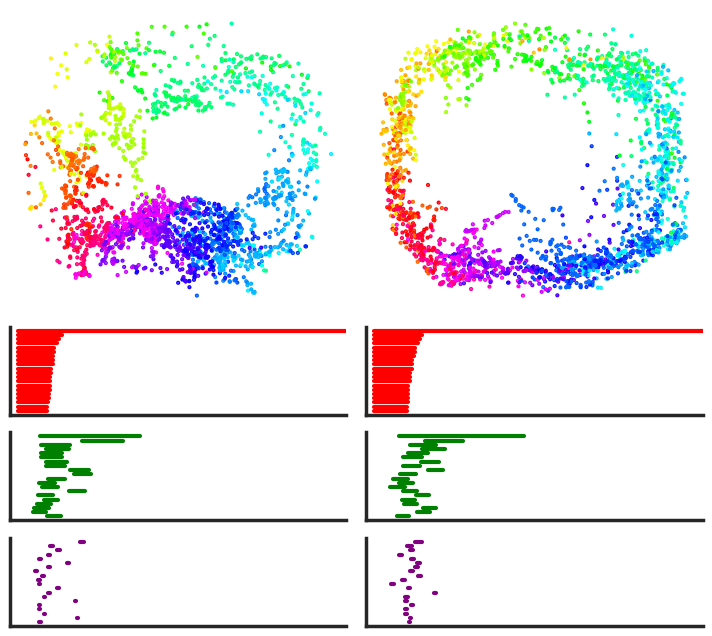

20220822_JA0178_darkHR1, # of hdc 27
dec err stat:37.908, run:44.753
az occ stat:0.9166666666666666, run:1.0, off-manifold index 0.6786828422876949
stat [7.913933277130127, 8.978397846221924]
run [3.4078989028930664, 22.157127618789673]


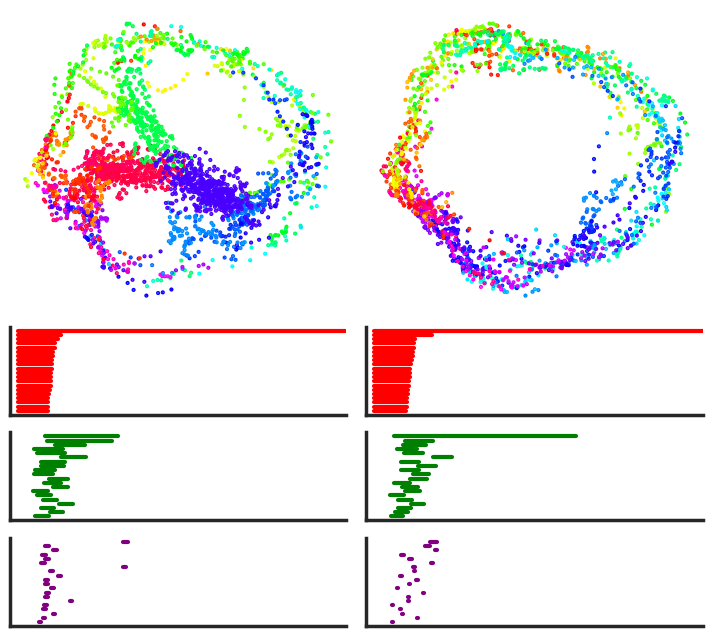

20220906_JA0178_dark1, # of hdc 11
dec err stat:32.5, run:21.908
az occ stat:0.9444444444444444, run:1.0, off-manifold index 0.33793103448275863
stat [2.043083667755127, 3.71102237701416]
run [3.6288177967071533, 6.679771304130554]


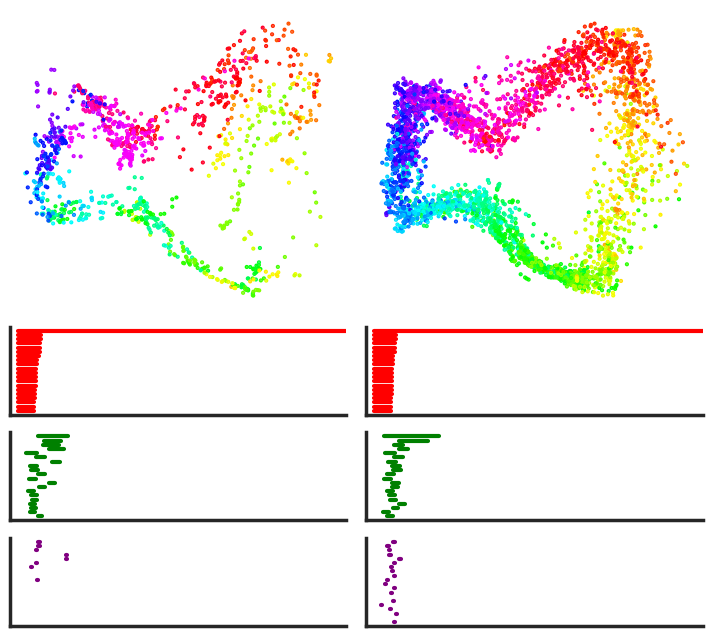

20220906_JA0178_darkHR1, # of hdc 11
dec err stat:62.029, run:75.541
az occ stat:0.9444444444444444, run:1.0, off-manifold index 0.4139473684210526
stat [3.3605873584747314, 3.733548641204834]
run [3.052410364151001, 7.995908498764038]


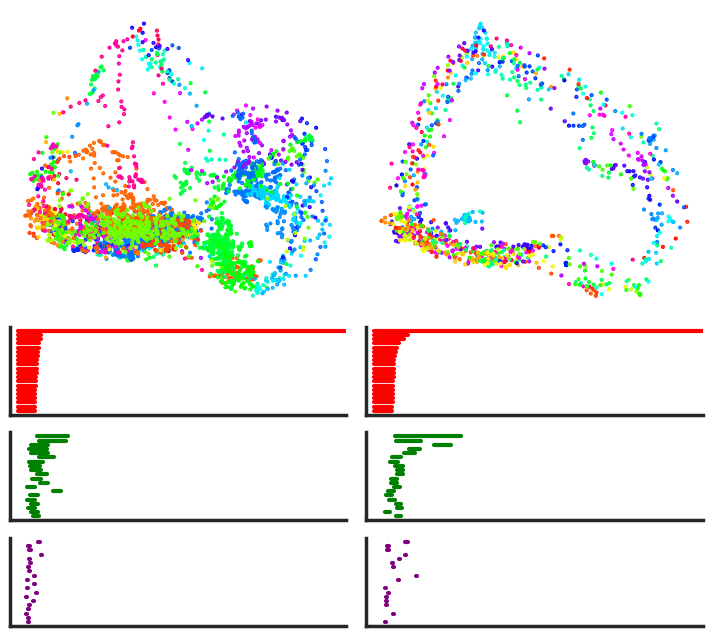

20220812_JA0181_dark1, # of hdc 18
dec err stat:30.21, run:27.079
az occ stat:0.9444444444444444, run:1.0, off-manifold index 0.2676363636363636
stat [3.4536492824554443, 11.225524187088013]
run [3.6889665126800537, 10.79997968673706]


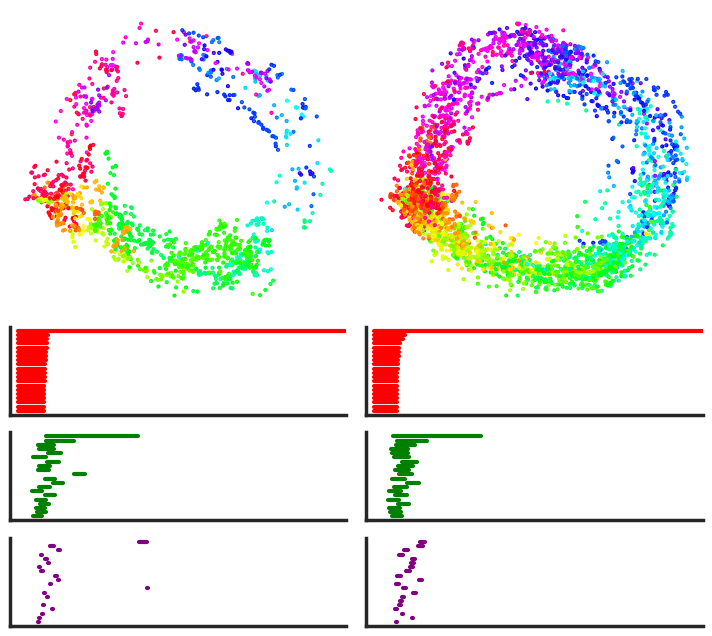

20220812_JA0181_darkHR1, # of hdc 17
dec err stat:31.787, run:32.407
az occ stat:0.9444444444444444, run:0.8888888888888888, off-manifold index 0.596078431372549
stat [3.6455979347229004, 6.729642152786255]
run [1.9053354263305664, 10.11995792388916]


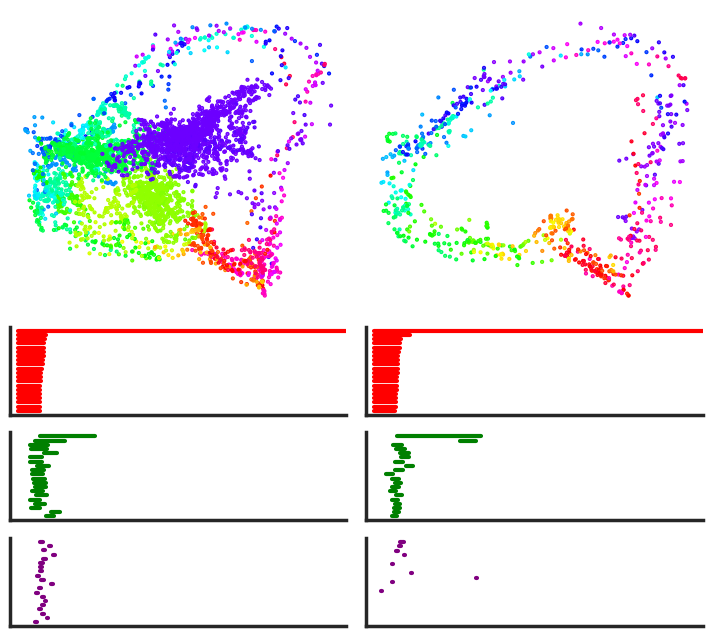

20220815_JA0181_dark1, # of hdc 16
dec err stat:32.545, run:32.917
az occ stat:0.9722222222222222, run:1.0, off-manifold index 0.16653386454183267
stat [1.3837370872497559, 22.606024265289307]
run [0.9425179958343506, 23.131717681884766]


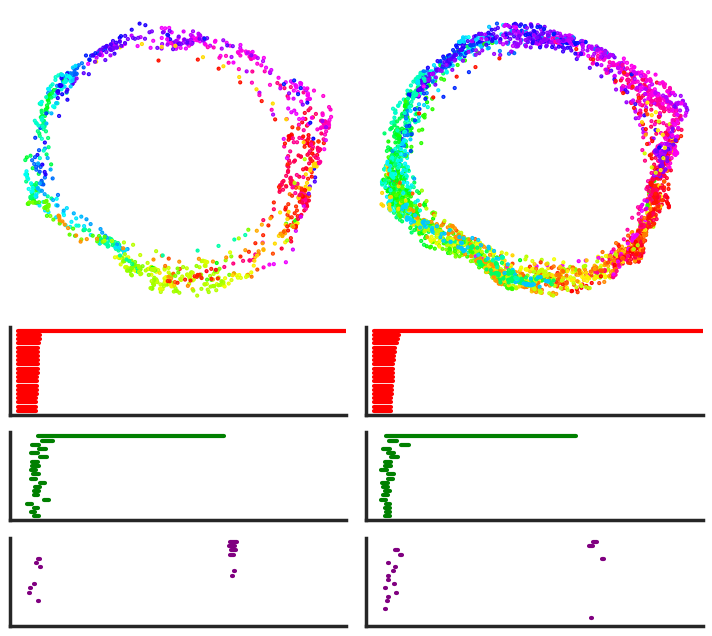

20220815_JA0181_darkHR1, # of hdc 16
dec err stat:61.593, run:56.091
az occ stat:0.9722222222222222, run:0.9722222222222222, off-manifold index 0.75
stat [9.496788024902344, 13.162697553634644]
run [2.548032760620117, 18.251432180404663]


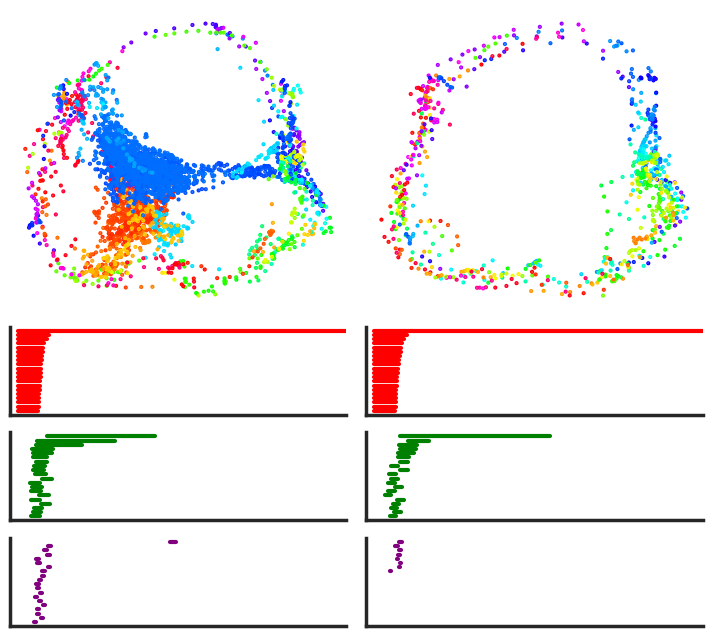

20220818_JA0181_dark1, # of hdc 14
dec err stat:17.381, run:23.663
az occ stat:0.9166666666666666, run:1.0, off-manifold index 0.01596958174904943
stat [1.3491132259368896, 21.45095992088318]
run [1.2436399459838867, 19.904239892959595]


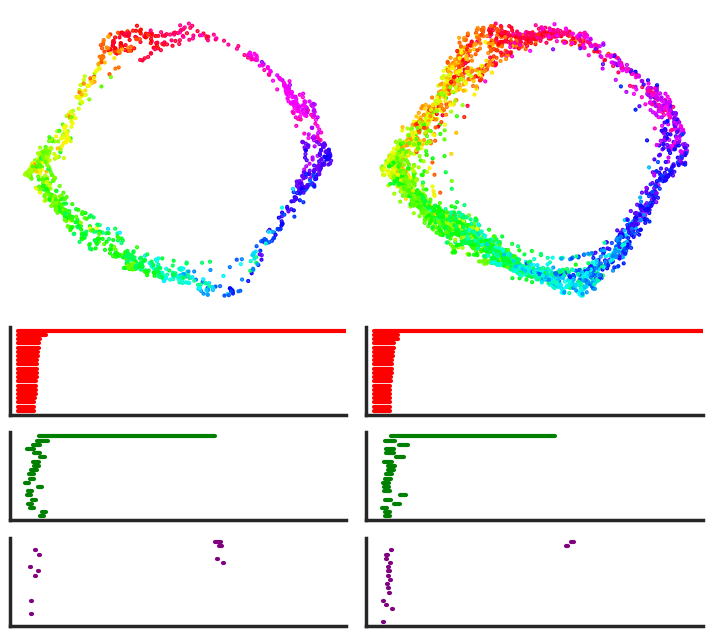

20220818_JA0181_darkHR1, # of hdc 14
dec err stat:81.031, run:78.574
az occ stat:1.0, run:1.0, off-manifold index 0.5167192429022082
stat [4.182422399520874, 7.333139419555664]
run [1.7303048372268677, 13.759909629821777]


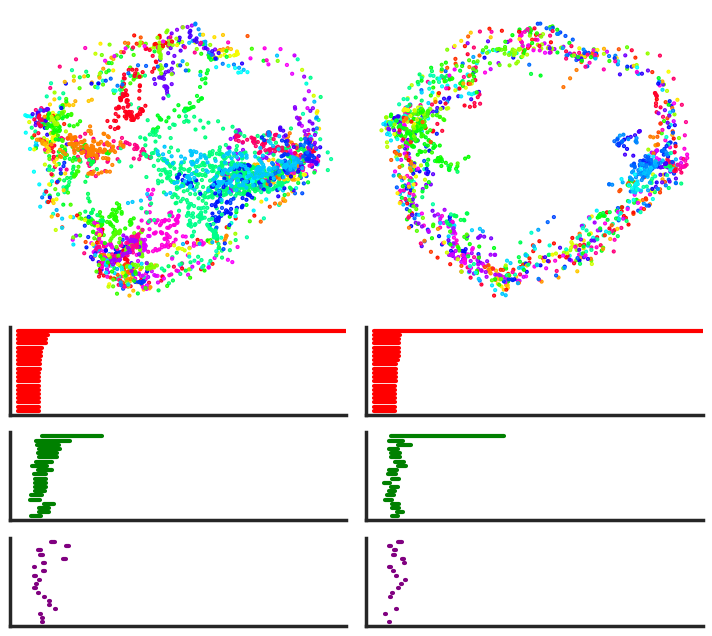

20220712_MC022_dark1, # of hdc 41
dec err stat:16.845, run:17.182
az occ stat:1.0, run:1.0, off-manifold index 0.07004608294930875
stat [2.54541015625, 34.183998107910156]
run [4.4831342697143555, 31.77495312690735]


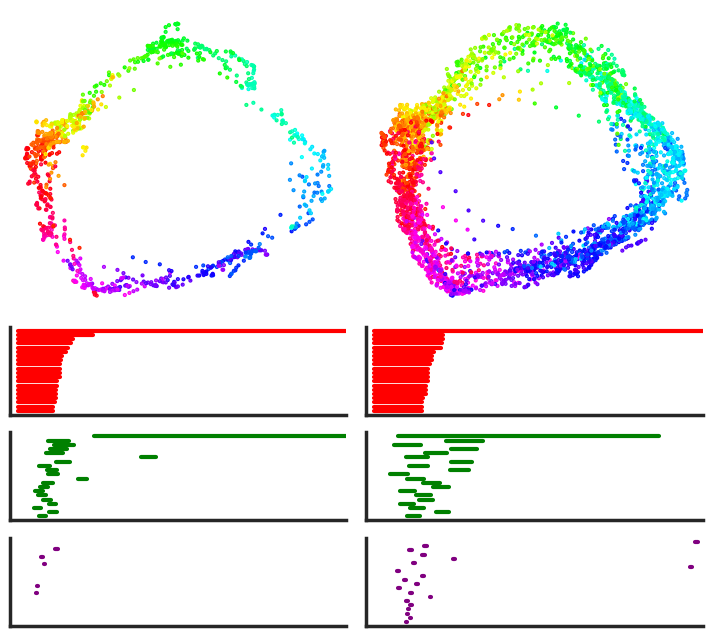

20220712_MC022_darkHR1, # of hdc 41
dec err stat:45.67, run:39.91
az occ stat:0.9166666666666666, run:0.9722222222222222, off-manifold index 0.6633587786259542
stat [4.7526984214782715, 28.851645469665527]
run [5.390548229217529, 25.16952896118164]


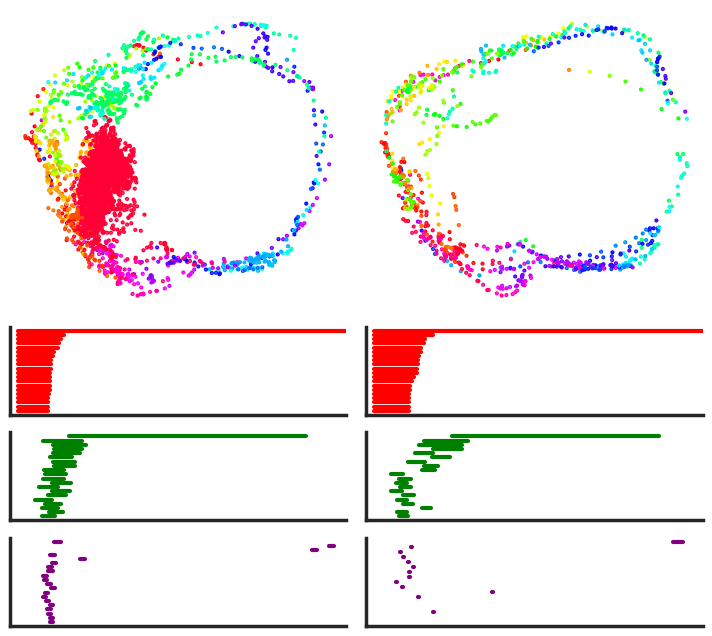

,rec_id,cond,dts,animal_name,az_occ,run,h1_bar,dec_err,rec_session,stat_off_manifold,run_ratio
0,20211207_JA0144_light1,light1,20211207,JA0144,0.916667,stat,5.956747,27.552,JA0144_20211207,0.155352,0.659375
0,20211207_JA0144_light1,light1,20211207,JA0144,1.000000,locom,6.397861,24.376,JA0144_20211207,0.155352,0.659375
0,20220126_JA0153_light1,light1,20220126,JA0153,0.916667,stat,14.210236,22.769,JA0153_20220126,0.179570,0.612500
0,20220126_JA0153_light1,light1,20220126,JA0153,1.000000,locom,15.542182,27.529,JA0153_20220126,0.179570,0.612500
0,20220126_JA0153_lightHR1,lightHR1,20220126,JA0153,0.944444,stat,5.941467,28.507,JA0153_20220126,0.625000,0.433333


In [454]:
col_list = ['red', 'green', 'purple']
angles = np.arange(-180, 200, 20)
h1_bar_max = 40
ls = []
ls_h, ls_emb = [], []
# roi = ['20220126_JA0153_lightHR1', '20220126_JA0153_light1']
# roi = ['20220419_JA0164_light1', '20220819_JA0178_light1', '20220812_JA0181_light1', '20220712_MC022_light1',
#        '20220419_JA0164_lightHR1', '20220819_JA0178_lightHR1', '20220812_JA0181_lightHR1', '20220712_MC022_lightHR1' ]

roi = ['20220822_JA0178_dark1', '20220812_JA0181_dark1', 
      '20220822_JA0178_darkHR1', '20220812_JA0181_darkHR1' ]

for k in d_hr_emb.keys():
    dts, animal_name, cond = k.split('_')[-3:]
    # if k not in roi:
    #     continue
    
    fig = plt.figure(figsize=(12, 8))
    gs = gridspec.GridSpec(6, 8)
    rec_session = animal_name + '_' + dts
    tmp = d_hr_emb[k]
    isomap = tmp['isomap']
    measured_yaw = tmp['measured_yaw']
    lin_vel = tmp['lin_vel']
    n_hdc = tmp['n_hdc']
    stat_az_occ = tmp['stat_az_occ'] 
    run_az_occ = tmp['run_az_occ'] 
    
    print(f'{k}, # of hdc {n_hdc}')
    if n_hdc < 10:
        continue
    stat_idx, run_idx = tmp['stat_idx'], tmp['run_idx']
#     try:
#         stat_idx, run_idx = get_stat_run_epochs(lin_vel, window_size=5, speed_thr = 6)
#     except Exception as e:
#         print (e)
#         continue 
        
    stat_dec_err, loc_dec_err = tmp['stat']['dec_err'], tmp['run']['dec_err']
    run_ratio = run_idx.size/lin_vel.size
    
    # 10 samples = 1s
#     occup, _ = np.histogram(measured_yaw[stat_idx], bins = angles)
#     stat_az_occ = occup[occup > 10].size/occup.size
#     occup, _ = np.histogram(measured_yaw[run_idx], bins = angles)
#     run_az_occ = occup[occup > 10].size/occup.size
    # compute off manifold ratios
    _, rad_manifold = compute_radius_old(isomap[:,0], isomap[:,1])
    _, rad_manifold_stat = compute_radius_old(isomap[stat_idx,0], isomap[stat_idx,1])
    _, rad_manifold_loc = compute_radius_old(isomap[run_idx,0], isomap[run_idx,1])
    offmanifold_threshold = np.percentile(rad_manifold_loc, 10)
    stat_off_manifold = np.sum(rad_manifold_stat < offmanifold_threshold)/rad_manifold_stat.size
    
    
    print(f'dec err stat:{stat_dec_err}, run:{loc_dec_err}')
    print(f'az occ stat:{stat_az_occ}, run:{run_az_occ}, off-manifold index {stat_off_manifold}')
    
    ax = fig.add_subplot(gs[0:3, 0:3])
    ax.scatter(isomap[stat_idx,0], isomap[stat_idx,1], s = 1, c = measured_yaw[stat_idx], 
                                           vmin = -180, vmax = 180, cmap = 'hsv')
    # ls_emb.append(pd.DataFrame({'mouse_id':animal_name, 'isomap_x': isomap[stat_idx,0], 'isomap_y':isomap[stat_idx,1], 
    #                             'yaw': measured_yaw[stat_idx], 'run': 'stat', 'cond':cond}))

    ax.axis('off')
    plt.xticks([])
    # ax.set_xlim(-40, 40)
    # ax.set_ylim(-40, 40)
    #         plt.yticks([])
    ax = fig.add_subplot(gs[0:3, 3:6])
    ax.scatter(isomap[run_idx,0], isomap[run_idx,1], s = 1, c = measured_yaw[run_idx], 
                                           vmin = -180, vmax = 180, cmap = 'hsv')
    # ls_emb.append(pd.DataFrame({'mouse_id':animal_name, 'isomap_x': isomap[run_idx,0], 'isomap_y':isomap[run_idx,1], 
    #                             'yaw': measured_yaw[run_idx], 'run': 'run', 'cond':cond}))
    
    ax.axis('off')
    plt.xticks([])
    # ax.set_xlim(-40, 40)
    # ax.set_ylim(-40, 40)
    
    h0 = tmp['stat']['h0']
    h1 = tmp['stat']['h1']
    h2 = tmp['stat']['h2']
    to_plot, h1_bar_stat = get_long_bettibars(h0, h1, h2)
    print('stat', h1_bar_stat)
    
    # ls_h.append(pd.DataFrame({'mouse_id':animal_name, 'h0': np.ndarray.flatten(to_plot[0]), 'h1':np.ndarray.flatten(to_plot[1]), 'run': 'stat', 'cond':cond,
    #                           'h2': np.pad(np.ndarray.flatten(to_plot[2]), (0, 40), constant_values=np.nan)[:40]  }))

    for curr_betti, curr_bar in enumerate(to_plot):
        ax = fig.add_subplot(gs[curr_betti +3: curr_betti + 4, :3])
        for i, interval in enumerate((curr_bar)):
            ax.plot([interval[0], interval[1]], [i, i], color=col_list[curr_betti], lw=3)
        ax.set_xlim([-1, 40])
        plt.xticks([])
        plt.yticks([])

    h0 = tmp['run']['h0']
    h1 = tmp['run']['h1']
    h2 = tmp['run']['h2']
    to_plot, h1_bar_run = get_long_bettibars(h0, h1, h2)
    print('run', h1_bar_run)

    # ls_h.append(pd.DataFrame({'mouse_id':animal_name, 'h0': np.ndarray.flatten(to_plot[0]), 'h1':np.ndarray.flatten(to_plot[1]), 'run': 'run', 'cond':cond,
    #                           'h2': np.pad(np.ndarray.flatten(to_plot[2]), (0, 40), constant_values=np.nan)[:40]  }))

    for curr_betti, curr_bar in enumerate(to_plot):
        ax = fig.add_subplot(gs[curr_betti +3: curr_betti + 4, 3:6])
        for i, interval in enumerate((curr_bar)):
            ax.plot([interval[0], interval[1]], [i, i], color=col_list[curr_betti], lw=3)
        ax.set_xlim([-1, 40])
        plt.xticks([])
        plt.yticks([])
    plt.show()
    # break
    tmp_df = pd.DataFrame({'rec_id': k,  'cond': cond,  'dts': dts, 'animal_name': animal_name, 'az_occ':stat_az_occ,
                           'run': 'stat', 'h1_bar': tmp['stat']['h1_bar'], 'dec_err': stat_dec_err, 'rec_session':rec_session,
                          'stat_off_manifold': stat_off_manifold, 'run_ratio': run_ratio}, index = [0])
    ls.append(tmp_df)

    tmp_df = pd.DataFrame({'rec_id': k, 'cond': cond, 'dts': dts, 'animal_name': animal_name, 'az_occ':run_az_occ, 
                           'run': 'locom', 'h1_bar': tmp['run']['h1_bar'], 'dec_err': loc_dec_err, 'rec_session':rec_session,
                          'stat_off_manifold': stat_off_manifold, 'run_ratio': run_ratio}, index = [0])
    ls.append(tmp_df)
    
df_hr_betti = pd.concat(ls)
df_hr_betti.head()


In [455]:
df_hr_betti.head()

,rec_id,cond,dts,animal_name,az_occ,run,h1_bar,dec_err,rec_session,stat_off_manifold,run_ratio
0,20211207_JA0144_light1,light1,20211207,JA0144,0.916667,stat,5.956747,27.552,JA0144_20211207,0.155352,0.659375
0,20211207_JA0144_light1,light1,20211207,JA0144,1.000000,locom,6.397861,24.376,JA0144_20211207,0.155352,0.659375
0,20220126_JA0153_light1,light1,20220126,JA0153,0.916667,stat,14.210236,22.769,JA0153_20220126,0.179570,0.612500
0,20220126_JA0153_light1,light1,20220126,JA0153,1.000000,locom,15.542182,27.529,JA0153_20220126,0.179570,0.612500
0,20220126_JA0153_lightHR1,lightHR1,20220126,JA0153,0.944444,stat,5.941467,28.507,JA0153_20220126,0.625000,0.433333


In [301]:
df_out = pd.concat(ls_h)
df_out.to_excel(filepath, index = True)

## Stat/Run/Rot Isomap

In [130]:
# d_emb_ang = {}

20220126_JA0153_lightHR1
stat_norot omi 0.9137546468401487
stat_rot omi 0.405607476635514
run_norot omi 0.08064516129032258
run_rot omi 0.10024096385542168


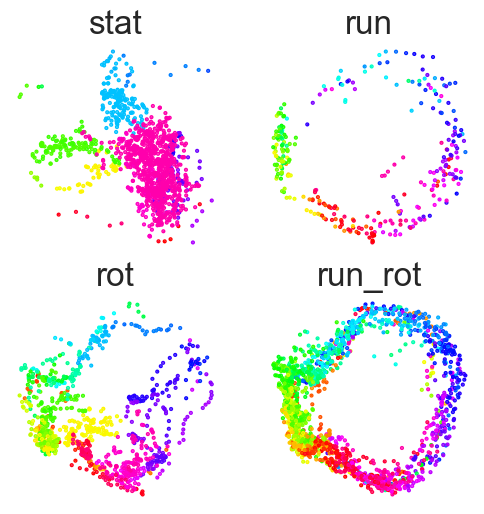

20220302_JA0162_lightHR1
stat_norot omi 0.6491315136476427
stat_rot omi 0.42093023255813955
run_norot omi 0.023529411764705882
run_rot omi 0.1


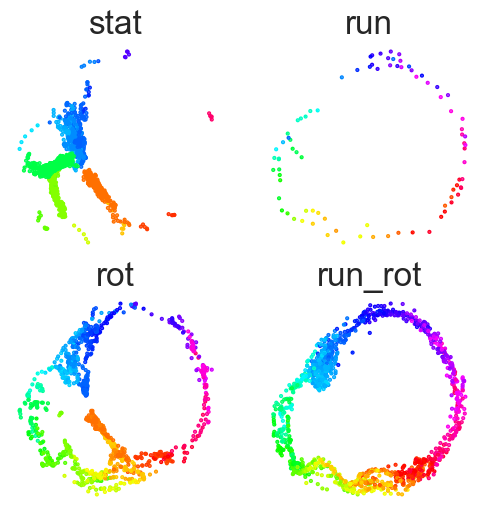

20220419_JA0164_lightHR1
stat_norot omi 0.8744186046511628
stat_rot omi 0.21666666666666667
run_norot omi 0.82265625
run_rot omi 0.1011764705882353


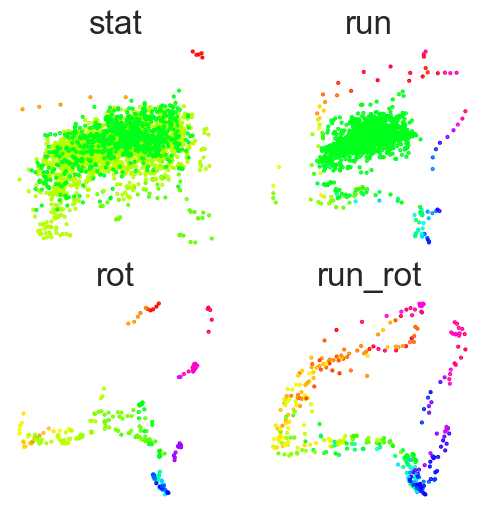

20220819_JA0178_lightHR1
stat_norot omi 0.906830122591944
stat_rot omi 0.4896
run_norot omi 0.009523809523809525
run_rot omi 0.1


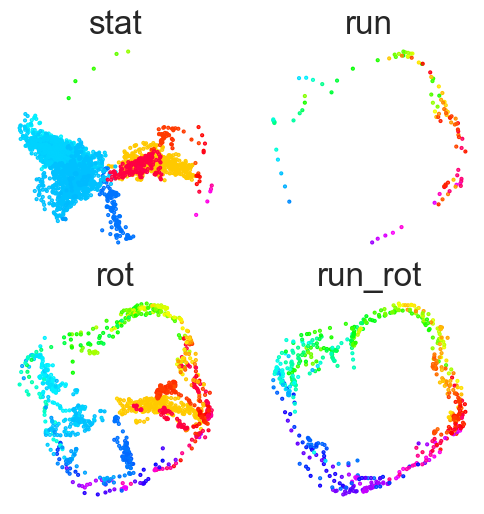

20220822_JA0178_lightHR1
stat_norot omi 0.871969696969697
stat_rot omi 0.30847457627118646
run_norot omi 0.7051851851851851
run_rot omi 0.1005586592178771


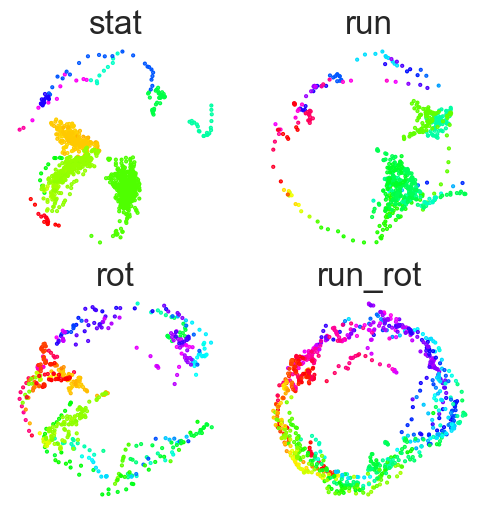

20220812_JA0181_lightHR1
stat_norot omi 0.3005970149253731
stat_rot omi 0.06792452830188679
run_norot omi 0.13333333333333333
run_rot omi 0.1


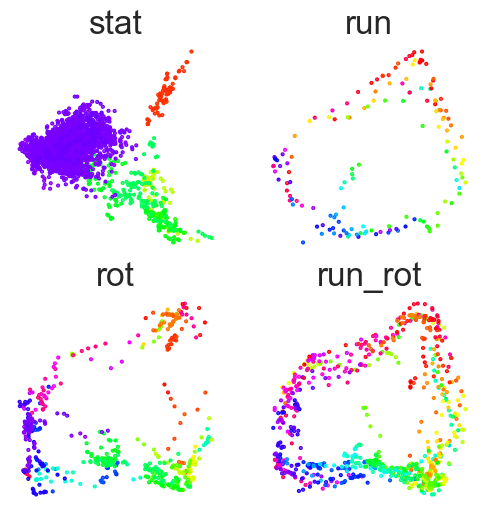

20220815_JA0181_lightHR1
stat_norot omi 0.9703703703703703
stat_rot omi 0.7238095238095238
run_norot omi 0.14
run_rot omi 0.1006896551724138


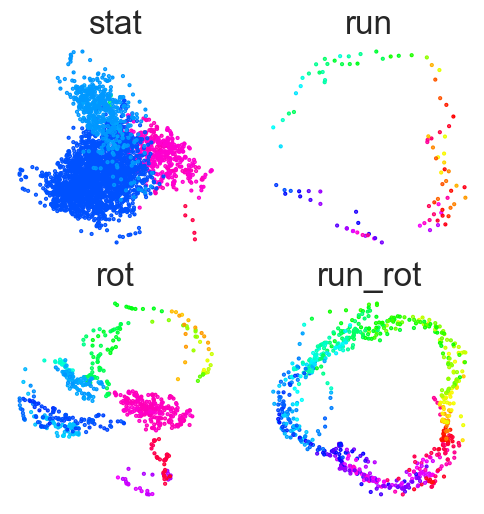

20220818_JA0181_lightHR1
stat_norot omi 0.9315716272600835
stat_rot omi 0.5468926553672316
run_norot omi 0.06
run_rot omi 0.1


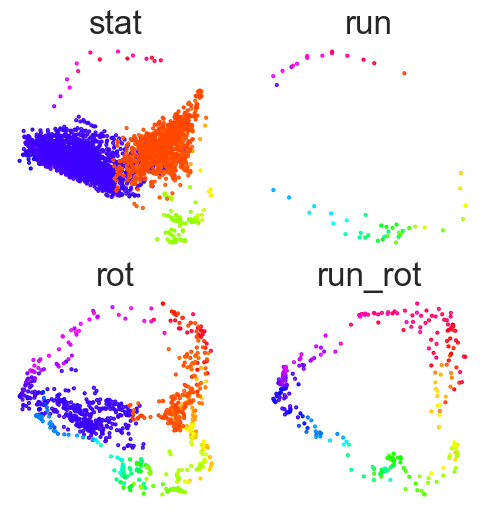

20220712_MC022_lightHR1
stat_norot omi 0.6761061946902654
stat_rot omi 0.2326797385620915
run_norot omi 0.043478260869565216
run_rot omi 0.1


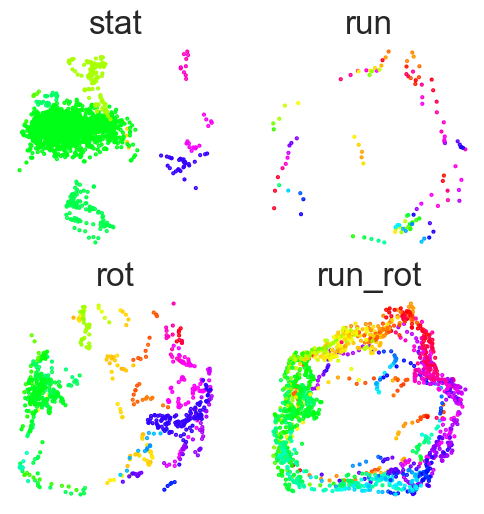

,rec_id,dec_err,omi,occ,run_cond
0,20220126_JA0153_lightHR1,32.312,0.913755,0.280208,stat_norot
0,20220126_JA0153_lightHR1,24.467,0.405607,0.222917,stat_rot
0,20220126_JA0153_lightHR1,26.776,0.080645,0.064583,run_norot
0,20220126_JA0153_lightHR1,35.079,0.100241,0.432292,run_rot
0,20220302_JA0162_lightHR1,17.038,0.649132,0.419792,stat_norot


In [186]:
col_list = ['red', 'green', 'purple']
angles = np.arange(-180, 200, 20)
h1_bar_max = 40
ls = []
lin_vel_thr = 4
ang_vel_thr = 20
ls_name = ['stat_norot', 'stat_rot', 'run_norot', 'run_rot']

for k in d_hr_emb.keys():
    if 'lightHR1' not in k:
        continue
    dts, animal_name, cond = k.split('_')[-3:]
    f,ax = plt.subplots(2, 2, figsize = (6, 6))

    rec_session = animal_name + '_' + dts
    tmp = d_hr_emb[k]
    isomap = tmp['isomap']
    measured_yaw = tmp['measured_yaw']
    isomap_yaw, dec_err, _ = decode_az_isomap(isomap[:, 0], isomap[:, 1], measured_yaw[:])
    dyaw = compute_dYaw(measured_yaw)
    # sampling 10 Hz
    ang_vel = dyaw*100
    
    stat_idx, run_idx = tmp['stat_idx'], tmp['run_idx']
    # stat_dec_err, loc_dec_err = tmp['stat_dec_err'], tmp['loc_dec_err']
    lin_speed = tmp['lin_vel']
    
    # find stat, run, rot epochs
    stat_idx, run_idx = get_stat_run_epochs(lin_speed, window_size=5, speed_thr = lin_vel_thr)
    _, rot_idx = get_stat_run_epochs(ang_vel, window_size=5, speed_thr = ang_vel_thr)

    # Finding unique elements
    stat_norot = np.setdiff1d(stat_idx, rot_idx)
    stat_rot = np.intersect1d(stat_idx, rot_idx)
    run_norot = np.setdiff1d(run_idx, rot_idx)
    run_rot = np.intersect1d(run_idx, rot_idx)
    
    stat_rot_ratio = stat_rot.size/stat_idx.size
    run_rot_ratio = run_rot.size/run_idx.size

    run_ratio = run_idx.size/lin_speed.size
    # 50 samples = 5s
    occup, _ = np.histogram(measured_yaw[stat_idx], bins = angles)
    stat_az_occ = occup[occup > 10].size/occup.size
    occup, _ = np.histogram(measured_yaw[run_idx], bins = angles)
    run_az_occ = occup[occup > 10].size/occup.size
    # compute off manifold ratios
    _, rad_manifold = compute_radius_old(isomap[:,0], isomap[:,1])
    offmanifold_threshold = np.percentile(rad_manifold[run_rot], 10)

    
    print(f'{k}')

    ls_beh_cond = [stat_norot, stat_rot, run_norot, run_rot]

    for idx, val in enumerate(ls_beh_cond):
        dec_err = round(np.mean(abs(((measured_yaw[val] - isomap_yaw[val]) + 180)%360 - 180)), 3)
        omi = np.sum(rad_manifold[val] < offmanifold_threshold)/rad_manifold[val].size 
        beh_occ = val.size/lin_speed.size
        print(f'{ls_name[idx]} omi {omi}')
        tmp_df = pd.DataFrame({'rec_id': k, 'dec_err': dec_err, 'omi': omi, 'occ': beh_occ, 'run_cond': ls_name[idx]}, index = [0])
        ls.append(tmp_df)
    
    # start_time = time.time()
    # d_emb_ang[k] = {}
    # for idx, val in enumerate(ls_beh_cond):
    #     print (ls_name[idx], val.size)
    #     d_emb_ang[k][ls_name[idx]] = {}
    #     try:
    #         # stat_norot
    #         d_emb_ang[k][ls_name[idx]]['dec_err'] = ls_decerr[idx]
    #         d_emb_ang[k][ls_name[idx]]['idx'] = val
    #         h0, h1, h2 = compute_betti(isomap[val, :])
    #         d_emb_ang[k][ls_name[idx]]['h0'], d_emb_ang[k][ls_name[idx]]['h1'], d_emb_ang[k][ls_name[idx]]['h2'] = h0, h1, h2
    #         to_plot, h1_bar = get_long_bettibars(h0, h1, h2)
    #         d_emb_ang[k][ls_name[idx]]['h1bar'] = h1_bar
    #     except:
    #         print('not def')

    # end_time = time.time()
    # print(end_time - start_time)
    
    ax[0][0].scatter(isomap[stat_norot,0], isomap[stat_norot,1], s = 1, c = measured_yaw[stat_norot], 
                                           vmin = -180, vmax = 180, cmap = 'hsv')
    ax[0][0].axis('off')
    ax[0][0].set_title('stat')
    plt.xticks([])

    ax[1][0].scatter(isomap[stat_rot,0], isomap[stat_rot,1], s = 1, c = measured_yaw[stat_rot], 
                                           vmin = -180, vmax = 180, cmap = 'hsv')
    ax[1][0].axis('off')
    ax[1][0].set_title('rot')
    plt.xticks([])
    
    ax[0][1].scatter(isomap[run_norot,0], isomap[run_norot,1], s = 1, c = measured_yaw[run_norot], 
                                           vmin = -180, vmax = 180, cmap = 'hsv')
    ax[0][1].axis('off')
    ax[0][1].set_title('run')
    plt.xticks([])
    
    ax[1][1].scatter(isomap[run_rot,0], isomap[run_rot,1], s = 1, c = measured_yaw[run_rot], 
                                           vmin = -180, vmax = 180, cmap = 'hsv')
    ax[1][1].axis('off')
    ax[1][1].set_title('run_rot')
    plt.xticks([])
    
    plt.show()
    # break

df_emb_ang = pd.concat(ls)
df_emb_ang.head()

In [51]:
measured_yaw.min()

np.float64(-180.0)

<Axes: xlabel='run_cond', ylabel='omi'>

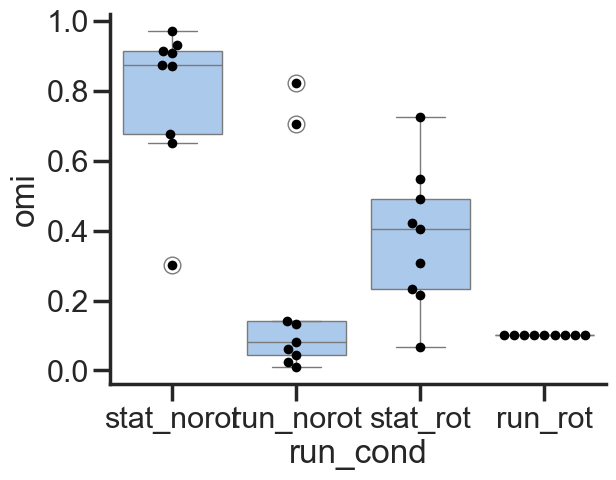

In [225]:
_inp_plot = df_emb_ang
y = 'omi'
ls_name = ['stat_norot', 'run_norot', 'stat_rot',  'run_rot']

sns.boxplot(data = _inp_plot, x = 'run_cond', y = y, order = ls_name)
sns.swarmplot(data = _inp_plot, x = 'run_cond', y = y, size = 7, color = 'k', dodge = True, legend = False)

# plt.savefig(f'boxplot_hr_{y}_lin-ang_vel.pdf', transparent = True)

In [226]:
df_emb_ang.groupby('run_cond')['omi'].describe()

,count,mean,std,min,25%,50%,75%,max
run_cond,,,,,,,,
run_norot,9.0,0.224261,0.310529,0.009524,0.043478,0.080645,0.140000,0.822656
run_rot,9.0,0.100296,0.000424,0.100000,0.100000,0.100000,0.100559,0.101176
stat_norot,9.0,0.788306,0.214386,0.300597,0.676106,0.874419,0.913755,0.970370
stat_rot,9.0,0.379176,0.197257,0.067925,0.232680,0.405607,0.489600,0.723810


In [227]:
a1 = _inp_plot[_inp_plot.run_cond == 'stat_norot'][y]
a2 = _inp_plot[_inp_plot.run_cond == 'stat_rot'][y]
a3 = _inp_plot[_inp_plot.run_cond == 'run_norot'][y]
a4 = _inp_plot[_inp_plot.run_cond == 'run_rot'][y]

print(stats.kruskal(a1, a2, a3, a4))
print('stat vs run')
print(stats.mannwhitneyu(a1, a3))

print('stat vs rot')
print(stats.mannwhitneyu(a1, a2))

print('stat vs run_rot')
print(stats.mannwhitneyu(a1, a4))

KruskalResult(statistic=20.10480286738351, pvalue=0.00016146134776434556)
stat vs run
MannwhitneyuResult(statistic=75.0, pvalue=0.0026797144168214833)
stat vs rot
MannwhitneyuResult(statistic=73.0, pvalue=0.004718198728115028)
stat vs run_rot
MannwhitneyuResult(statistic=81.0, pvalue=0.00035819428917157367)


In [228]:
_inp_plot.head()

,rec_id,dec_err,omi,occ,run_cond
0,20220126_JA0153_lightHR1,32.312,0.913755,0.280208,stat_norot
0,20220126_JA0153_lightHR1,24.467,0.405607,0.222917,stat_rot
0,20220126_JA0153_lightHR1,26.776,0.080645,0.064583,run_norot
0,20220126_JA0153_lightHR1,35.079,0.100241,0.432292,run_rot
0,20220302_JA0162_lightHR1,17.038,0.649132,0.419792,stat_norot


In [229]:
# _inp_plot.to_excel(filepath, index = True)

### Test different lin/ang velocity

In [231]:
col_list = ['red', 'green', 'purple']
angles = np.arange(-180, 200, 20)
h1_bar_max = 40
ls = []
lin_vel_thr = [1, 2, 4, 8]
ang_vel_thr = [5, 10, 20, 40]
ls_name = ['stat_norot', 'stat_rot', 'run_norot', 'run_rot']

for k in d_hr_emb.keys():

    if 'lightHR1' not in k:
        continue
    for lin_t in lin_vel_thr:
        for ang_t in ang_vel_thr:
            print(lin_t, ang_t)
            start_time = time.time()
        
            dts, animal_name, cond = k.split('_')[-3:]
            rec_session = animal_name + '_' + dts
            tmp = d_hr_emb[k]
            isomap = tmp['isomap']
            measured_yaw = tmp['measured_yaw']
            isomap_yaw, dec_err, _ = decode_az_isomap(isomap[:, 0], isomap[:, 1], measured_yaw[:])
            dyaw = compute_dYaw(measured_yaw)
            # sampling 10 Hz, 100ms
            ang_vel = dyaw*100
            lin_speed = tmp['lin_vel']
        
            # find stat, run, rot epochs
            try:
                stat_idx, run_idx = get_stat_run_epochs(lin_speed, window_size=5, speed_thr = lin_t)
                _, rot_idx = get_stat_run_epochs(ang_vel, window_size=5, speed_thr = ang_t)
            except:
                print(k)
                continue
        
            # Finding unique elements
            stat_norot = np.setdiff1d(stat_idx, rot_idx)
            stat_rot = np.intersect1d(stat_idx, rot_idx)
            run_norot = np.setdiff1d(run_idx, rot_idx)
            run_rot = np.intersect1d(run_idx, rot_idx)
        
            if stat_norot.size < 5:
                print(k)
                continue
            
            stat_ratio = stat_norot.size/lin_speed.size
            stat_rot_ratio = stat_rot.size/stat_idx.size
            run_rot_ratio = run_rot.size/run_idx.size
            run_ratio = run_idx.size/lin_speed.size
            
            # 50 samples = 5s
            occup, _ = np.histogram(measured_yaw[stat_idx], bins = angles)
            stat_az_occ = occup[occup > 10].size/occup.size
            occup, _ = np.histogram(measured_yaw[run_idx], bins = angles)
            run_az_occ = occup[occup > 10].size/occup.size
            
            # compute off manifold ratios
            # compute off manifold ratios
            _, rad_manifold = compute_radius_old(isomap[:,0], isomap[:,1])
            _, rad_manifold_stat = compute_radius_old(isomap[stat_norot,0], isomap[stat_norot,1])
            _, rad_manifold_loc = compute_radius_old(isomap[run_rot,0], isomap[run_rot,1])
        
            offmanifold_threshold = np.percentile(rad_manifold_loc, 10)
            stat_off_manifold = np.sum(rad_manifold_stat < offmanifold_threshold)/rad_manifold_stat.size
            
            tmp_df = pd.DataFrame({'rec_id': k, 'rec_session': rec_session, 'stat_ratio': stat_ratio,
                                  'lin_thr': lin_t, 'ang_thr':ang_t, 'stat_off_manifold':stat_off_manifold}, index = [0])
            ls.append(tmp_df)
            print(f'{k}')
        
        #     f,ax = plt.subplots(2, 2, figsize = (6, 6))
        #     ax[0][0].scatter(isomap[stat_norot,0], isomap[stat_norot,1], s = 1, c = measured_yaw[stat_norot], 
        #                                            vmin = 0, vmax = 360, cmap = 'hsv')
        #     ax[0][0].axis('off')
        #     plt.xticks([])
        
        #     ax[0][1].scatter(isomap[stat_rot,0], isomap[stat_rot,1], s = 1, c = measured_yaw[stat_rot], 
        #                                            vmin = 0, vmax = 360, cmap = 'hsv')
        #     ax[0][1].axis('off')
        #     plt.xticks([])
        
        #     ax[1][0].scatter(isomap[run_norot,0], isomap[run_norot,1], s = 1, c = measured_yaw[run_norot], 
        #                                            vmin = 0, vmax = 360, cmap = 'hsv')
        #     ax[1][0].axis('off')
        #     plt.xticks([])
        
        #     ax[1][1].scatter(isomap[run_rot,0], isomap[run_rot,1], s = 1, c = measured_yaw[run_rot], 
        #                                            vmin = 0, vmax = 360, cmap = 'hsv')
        #     ax[1][1].axis('off')
        #     plt.xticks([])
        #     plt.show()
        
            # end_time = time.time()
            # print(end_time - start_time)
    # break
    
df_vel = pd.concat(ls)
df_vel.head()

1 5
20220126_JA0153_lightHR1
1 10
20220126_JA0153_lightHR1
1 20
20220126_JA0153_lightHR1
1 40
20220126_JA0153_lightHR1
2 5
20220126_JA0153_lightHR1
2 10
20220126_JA0153_lightHR1
2 20
20220126_JA0153_lightHR1
2 40
20220126_JA0153_lightHR1
4 5
20220126_JA0153_lightHR1
4 10
20220126_JA0153_lightHR1
4 20
20220126_JA0153_lightHR1
4 40
20220126_JA0153_lightHR1
8 5
20220126_JA0153_lightHR1
8 10
20220126_JA0153_lightHR1
8 20
20220126_JA0153_lightHR1
8 40
20220126_JA0153_lightHR1
1 5
20220302_JA0162_lightHR1
1 10
20220302_JA0162_lightHR1
1 20
20220302_JA0162_lightHR1
1 40
20220302_JA0162_lightHR1
2 5
20220302_JA0162_lightHR1
2 10
20220302_JA0162_lightHR1
2 20
20220302_JA0162_lightHR1
2 40
20220302_JA0162_lightHR1
4 5
20220302_JA0162_lightHR1
4 10
20220302_JA0162_lightHR1
4 20
20220302_JA0162_lightHR1
4 40
20220302_JA0162_lightHR1
8 5
20220302_JA0162_lightHR1
8 10
20220302_JA0162_lightHR1
8 20
20220302_JA0162_lightHR1
8 40
20220302_JA0162_lightHR1
1 5
20220419_JA0164_lightHR1
1 10
20220419_JA016

,rec_id,rec_session,stat_ratio,lin_thr,ang_thr,stat_off_manifold
0,20220126_JA0153_lightHR1,JA0153_20220126,0.258333,1,5,0.933871
0,20220126_JA0153_lightHR1,JA0153_20220126,0.261458,1,10,0.929880
0,20220126_JA0153_lightHR1,JA0153_20220126,0.271875,1,20,0.931034
0,20220126_JA0153_lightHR1,JA0153_20220126,0.310417,1,40,0.891946
0,20220126_JA0153_lightHR1,JA0153_20220126,0.259375,2,5,0.939759


C:\Users\01\AppData\Local\Temp\ipykernel_16696\378972130.py:6: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  sns.swarmplot(data = _inp_plot, x = 'lin_thr', y = y,   hue = 'ang_thr', color = 'k', dodge = True, legend = False)


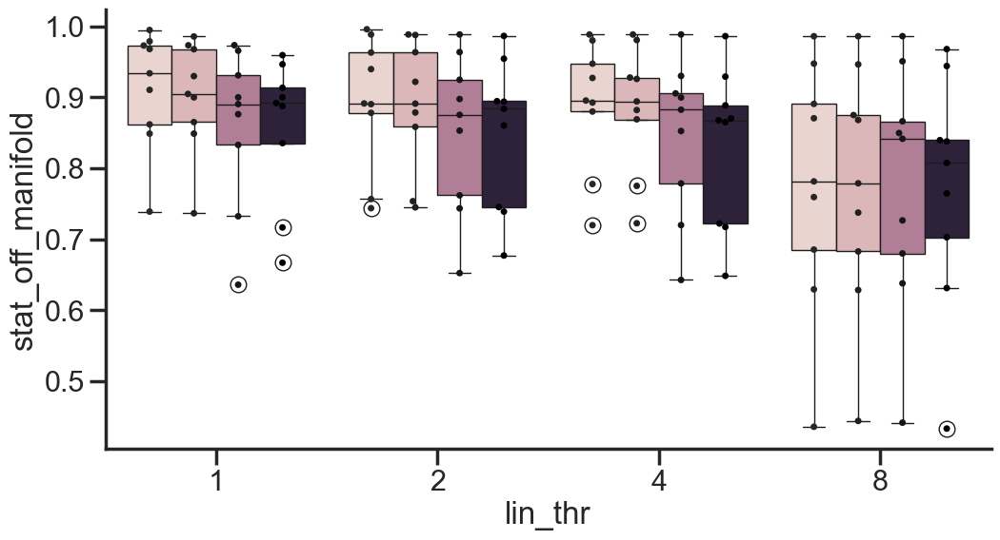

In [232]:
f, ax = plt.subplots(figsize = (12, 6))
_inp_plot = df_vel
y = 'stat_off_manifold'

sns.boxplot(data = _inp_plot, x = 'lin_thr', y = y, hue = 'ang_thr')
sns.swarmplot(data = _inp_plot, x = 'lin_thr', y = y,   hue = 'ang_thr', color = 'k', dodge = True, legend = False)
plt.legend().remove()  # This line removes the legend

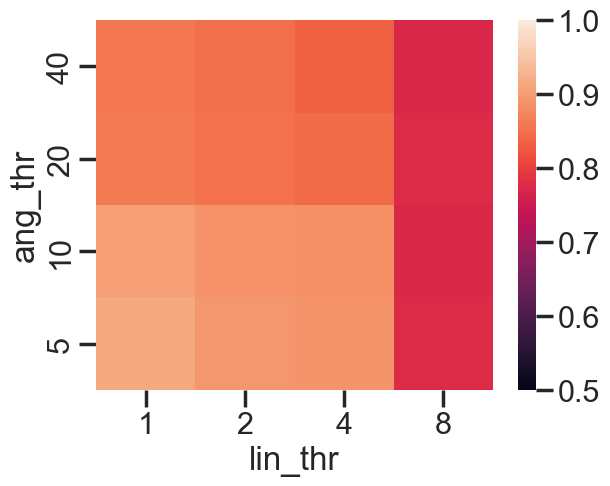

In [233]:
_inp_plot_2 = _inp_plot.groupby([ 'lin_thr', 'ang_thr'])[y].mean().reset_index()
_inp_plot_3 = _inp_plot_2.pivot(index = 'ang_thr', columns = 'lin_thr', values = 'stat_off_manifold')
ax = sns.heatmap(_inp_plot_3, vmin = 0.5, vmax  = 1, cmap = 'rocket')
ax.invert_yaxis()  # This line inverts the y-axis
# plt.savefig(f'hetamap_offmanifold_lin-ang_vel.png', dpi = 300, transparent = True)
# plt.savefig(f'hetamap_hr_omi_lin-ang_vel.pdf', transparent = True)

In [237]:
_inp_plot.to_excel(filepath, index = True)

20211212_JA0144_dark1
stat dec err 26.319, h1 5.685, az_occ 0.9444444444444444
run dec err 25.625, h1 5.685, az_occ 1.0


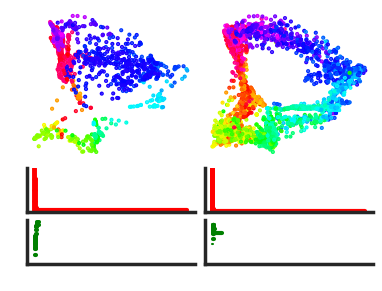

20211212_JA0144_darkHR1
stat dec err 71.072, h1 1.801, az_occ 0.5
run dec err 88.993, h1 1.801, az_occ 0.8333333333333334


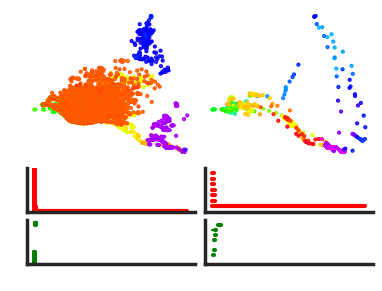

20211212_JA0144_light1
stat dec err 28.721, h1 5.802, az_occ 0.7222222222222222
run dec err 25.992, h1 5.802, az_occ 1.0


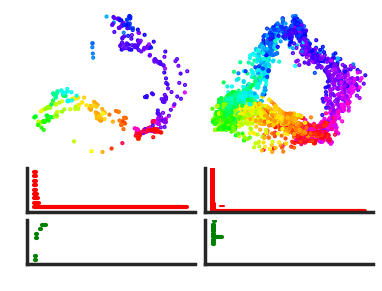

20211212_JA0144_lightHR1
stat dec err 45.864, h1 1.362, az_occ 0.6111111111111112
run dec err 64.394, h1 1.362, az_occ 1.0


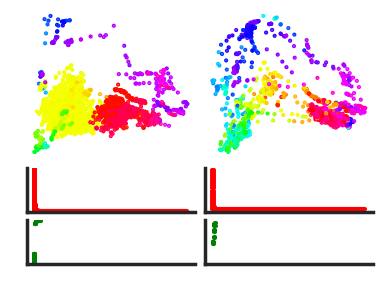

20220209_JA0153_dark1
stat dec err 86.974, h1 7.173, az_occ 0.8333333333333334
run dec err 56.432, h1 7.173, az_occ 1.0


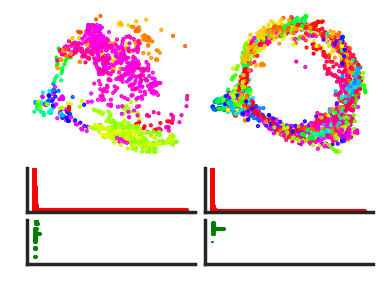

20220209_JA0153_darkHR1
stat dec err 26.829, h1 14.656, az_occ 0.7777777777777778
run dec err 49.61, h1 14.656, az_occ 1.0


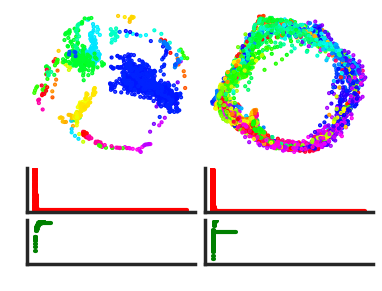

20220209_JA0153_light1
stat dec err 20.539, h1 9.067, az_occ 0.8333333333333334
run dec err 29.49, h1 9.067, az_occ 1.0


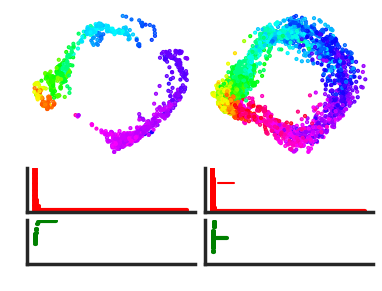

20220209_JA0153_lightHR1
stat dec err 25.2, h1 14.762, az_occ 0.9444444444444444
run dec err 32.955, h1 14.762, az_occ 1.0


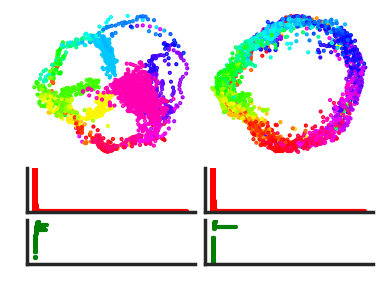

20220302_JA0162_dark1
stat dec err 46.257, h1 1.957, az_occ 0.8888888888888888
run dec err 61.136, h1 1.957, az_occ 1.0


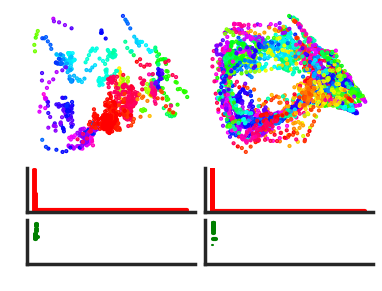

20220302_JA0162_light1
stat dec err 21.13, h1 13.84, az_occ 0.8333333333333334
run dec err 16.522, h1 13.84, az_occ 1.0


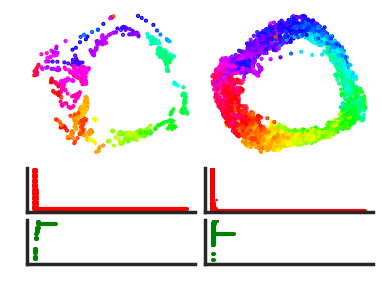

20220302_JA0162_lightHR1
stat dec err 16.277, h1 17.299, az_occ 1.0
run dec err 13.89, h1 17.299, az_occ 1.0


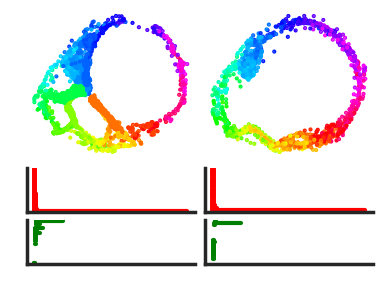

20220419_JA0164_dark1
stat dec err 24.354, h1 7.087, az_occ 0.7777777777777778
run dec err 27.123, h1 7.087, az_occ 1.0


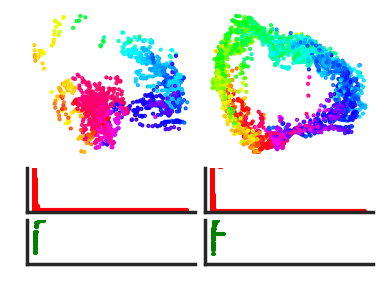

20220419_JA0164_darkHR1
stat dec err 49.825, h1 6.238, az_occ 0.8888888888888888
run dec err 49.563, h1 6.238, az_occ 1.0


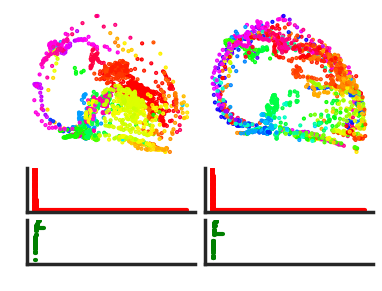

20220419_JA0164_light1
stat dec err 21.496, h1 17.545, az_occ 0.7777777777777778
run dec err 21.062, h1 17.545, az_occ 1.0


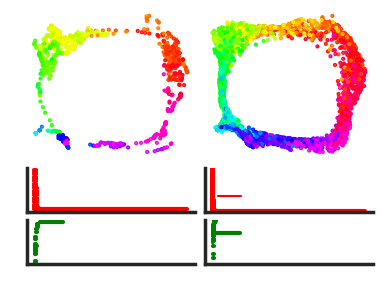

20220419_JA0164_lightHR1
stat dec err 70.618, h1 4.349, az_occ 0.5555555555555556
run dec err 81.766, h1 4.349, az_occ 0.9444444444444444


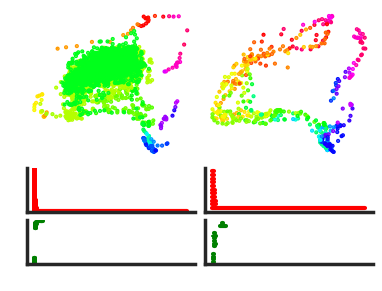

20220426_JA0164_dark1
stat dec err 27.0, h1 16.76, az_occ 0.6666666666666666
run dec err 21.738, h1 16.76, az_occ 1.0


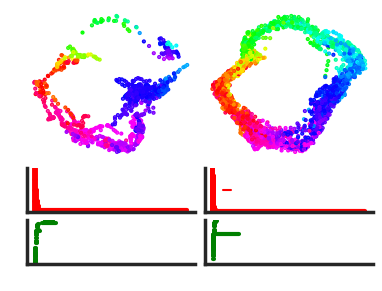

20220426_JA0164_darkHR1
stat dec err 88.436, h1 2.804, az_occ 0.7222222222222222
run dec err 82.702, h1 2.804, az_occ 1.0


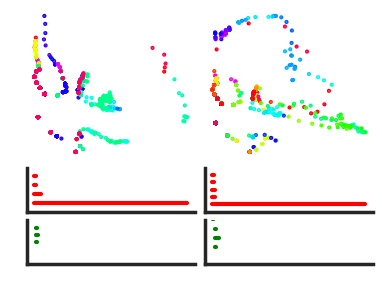

20220426_JA0164_light1
stat dec err 14.431, h1 20.39, az_occ 0.9444444444444444
run dec err 15.526, h1 20.39, az_occ 1.0


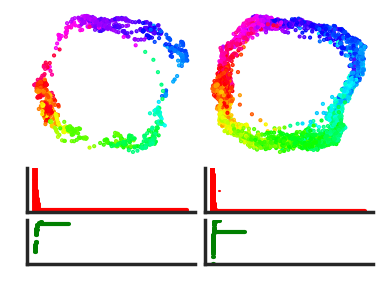

20220819_JA0178_dark1
stat dec err 26.612, h1 20.116, az_occ 1.0
run dec err 21.315, h1 20.116, az_occ 1.0


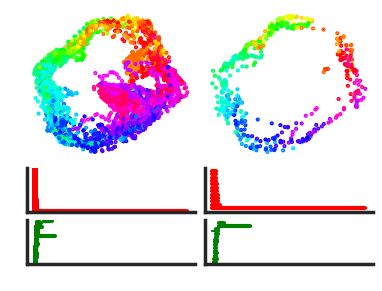

20220819_JA0178_light1
stat dec err 29.766, h1 33.355, az_occ 1.0
run dec err 29.932, h1 33.355, az_occ 1.0


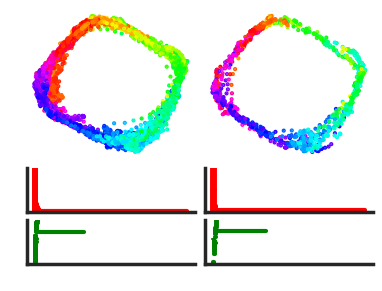

20220819_JA0178_lightHR1
stat dec err 27.782, h1 14.909, az_occ 1.0
run dec err 18.662, h1 14.909, az_occ 0.5555555555555556


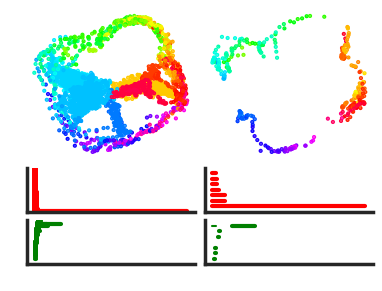

20220822_JA0178_dark1
stat dec err 23.915, h1 10.036, az_occ 1.0
run dec err 20.722, h1 10.036, az_occ 1.0


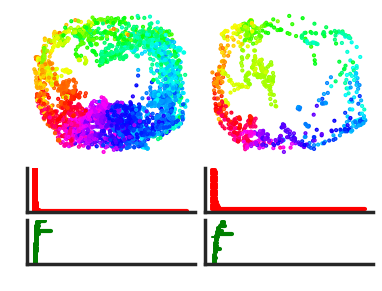

20220822_JA0178_darkHR1
stat dec err 38.688, h1 12.217, az_occ 1.0
run dec err 43.661, h1 12.217, az_occ 1.0


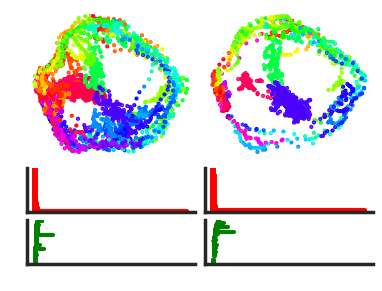

20220822_JA0178_light1
stat dec err 21.75, h1 19.332, az_occ 1.0
run dec err 18.846, h1 19.332, az_occ 1.0


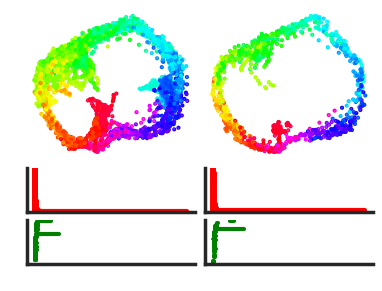

20220822_JA0178_lightHR1
stat dec err 44.455, h1 3.175, az_occ 1.0
run dec err 47.036, h1 3.175, az_occ 0.3333333333333333


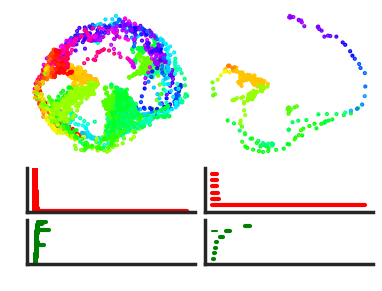

20220906_JA0178_dark1
stat dec err 24.905, h1 6.074, az_occ 1.0
run dec err 23.265, h1 6.074, az_occ 1.0


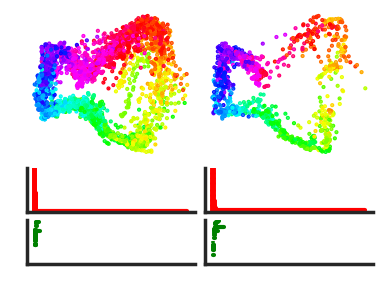

20220906_JA0178_light1
stat dec err 23.028, h1 9.443, az_occ 1.0
run dec err 21.788, h1 9.443, az_occ 1.0


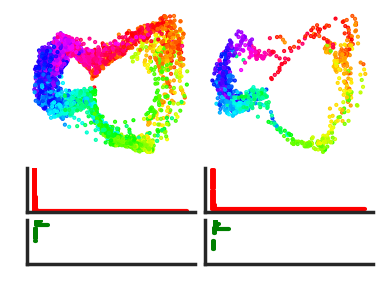

20220812_JA0181_dark1
stat dec err 30.535, h1 8.64, az_occ 1.0
run dec err 25.161, h1 8.64, az_occ 1.0


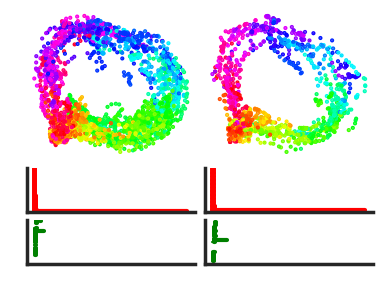

20220812_JA0181_darkHR1
stat dec err 31.605, h1 9.243, az_occ 1.0
run dec err 34.39, h1 9.243, az_occ 1.0


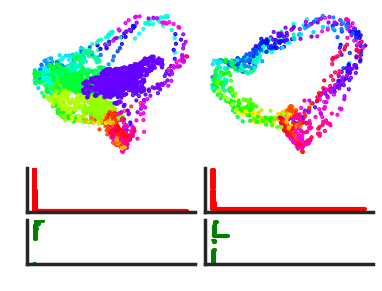

20220812_JA0181_light1
stat dec err 17.971, h1 13.319, az_occ 1.0
run dec err 18.581, h1 13.319, az_occ 1.0


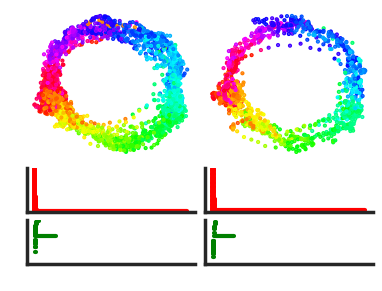

20220812_JA0181_lightHR1
stat dec err 43.714, h1 2.826, az_occ 0.8888888888888888
run dec err 49.268, h1 2.826, az_occ 1.0


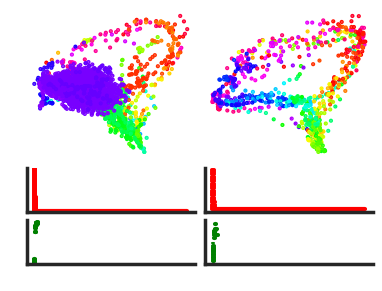

20220815_JA0181_dark1
stat dec err 33.618, h1 22.355, az_occ 1.0
run dec err 25.113, h1 22.355, az_occ 1.0


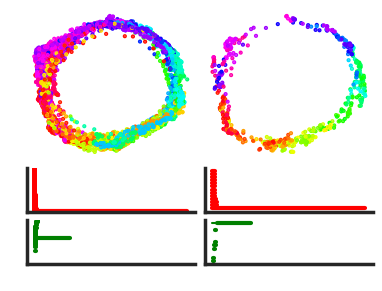

20220815_JA0181_darkHR1
stat dec err 58.955, h1 14.41, az_occ 1.0
run dec err 54.464, h1 14.41, az_occ 1.0


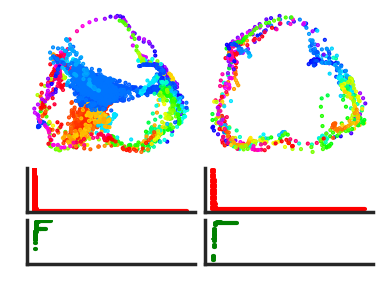

20220815_JA0181_light1
stat dec err 53.397, h1 22.263, az_occ 1.0
run dec err 59.869, h1 22.263, az_occ 1.0


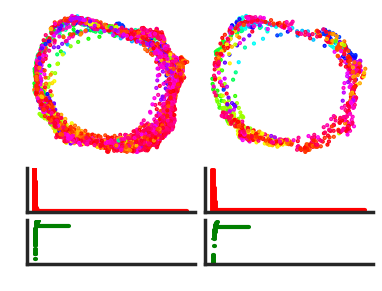

20220815_JA0181_lightHR1
stat dec err 50.986, h1 16.53, az_occ 0.7777777777777778
run dec err 32.358, h1 16.53, az_occ 1.0


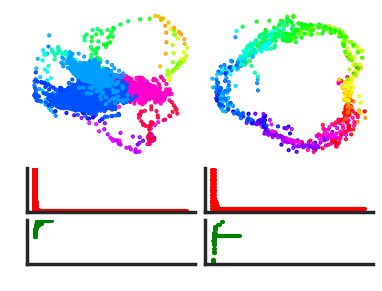

20220818_JA0181_dark1
stat dec err 22.429, h1 21.497, az_occ 1.0
run dec err 20.301, h1 21.497, az_occ 1.0


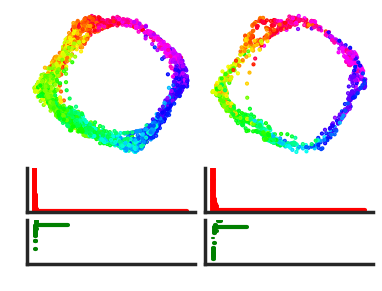

20220818_JA0181_light1
stat dec err 14.235, h1 20.644, az_occ 1.0
run dec err 13.229, h1 20.644, az_occ 1.0


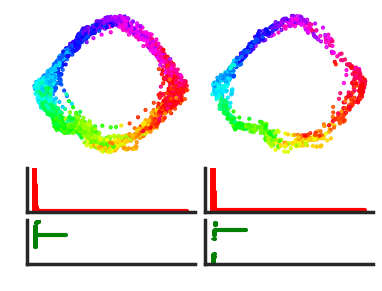

20220818_JA0181_lightHR1
stat dec err 37.962, h1 14.989, az_occ 0.8333333333333334
run dec err 16.929, h1 14.989, az_occ 0.7777777777777778


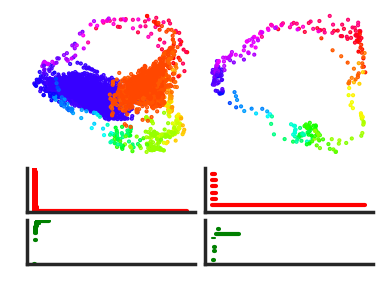

01_26_JA153_dark1
stat dec err 65.947, h1 7.954, az_occ 1.0
run dec err 57.65, h1 7.954, az_occ 1.0


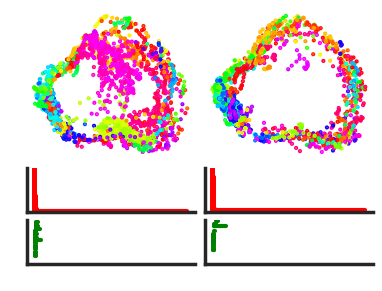

01_26_JA153_darkHR1
stat dec err 32.497, h1 9.015, az_occ 0.9444444444444444
run dec err 50.843, h1 9.015, az_occ 1.0


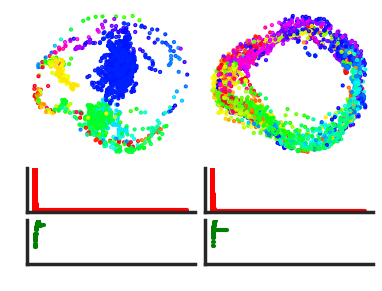

01_26_JA153_light1
stat dec err 26.297, h1 11.231, az_occ 1.0
run dec err 26.671, h1 11.231, az_occ 1.0


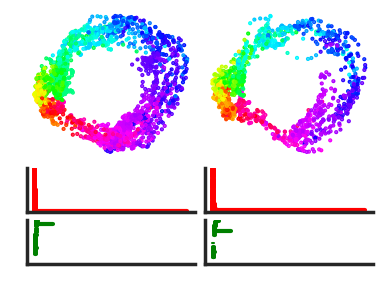

01_26_JA153_lightHR1
stat dec err 27.92, h1 10.651, az_occ 1.0
run dec err 36.136, h1 10.651, az_occ 1.0


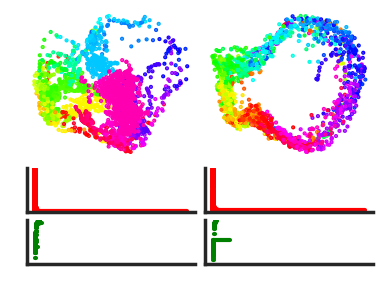

07_12_MC022_dark1
stat dec err 17.849, h1 31.58, az_occ 1.0
run dec err 16.337, h1 31.58, az_occ 1.0


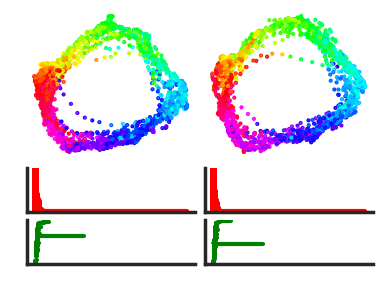

07_12_MC022_darkHR1
stat dec err 48.264, h1 29.661, az_occ 0.7777777777777778
run dec err 40.273, h1 29.661, az_occ 1.0


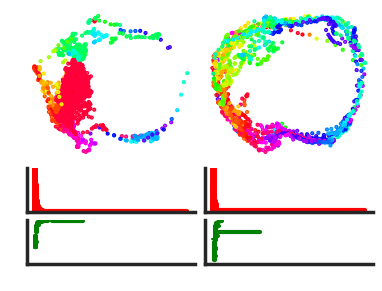

07_12_MC022_light1
stat dec err 18.707, h1 41.078, az_occ 1.0
run dec err 16.162, h1 41.078, az_occ 1.0


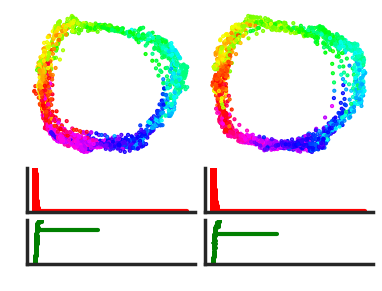

07_12_MC022_lightHR1
stat dec err 33.961, h1 15.966, az_occ 0.8333333333333334
run dec err 49.936, h1 15.966, az_occ 1.0


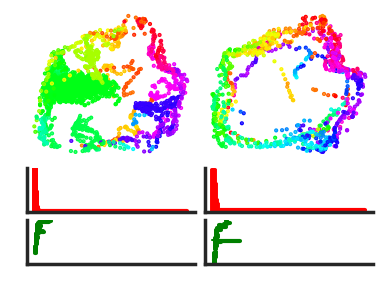

,rec_id,cond,dts,animal_name,az_occ,run,h1_bar,dec_err,stat_off_manifold,run_ratio
0,20211212_JA0144_dark1,dark1,20211212,JA0144,0.944444,stat,1.355,26.319,0.310460,0.751042
0,20211212_JA0144_dark1,dark1,20211212,JA0144,1.000000,locom,5.685,25.625,0.310460,0.751042
0,20211212_JA0144_darkHR1,darkHR1,20211212,JA0144,0.500000,stat,0.588,71.072,0.466364,0.083333
0,20211212_JA0144_darkHR1,darkHR1,20211212,JA0144,0.833333,locom,1.801,88.993,0.466364,0.083333
0,20211212_JA0144_light1,light1,20211212,JA0144,0.722222,stat,2.603,28.721,0.188764,0.907292


In [126]:
# plot_prcnt = [99, 90, 0] # order is h0, h1, h2
# to_plot = []
# corr_window = 50 # 50 samples, 1 sec
# col_list = ['r', 'g', 'm', 'c']
# ls, ls_corr, ls_r, ls_pcorr = [], [], [], []
# angles = np.arange(-180, 200, 20)

# for k in d_emb.keys():
# #     if '20220830' not in k or 'MC038' not in k:
# #         continue
# #     if 'lightHR1' not in k:
# #         continue
    
#     fig = plt.figure(figsize=(6, 4))
#     gs = gridspec.GridSpec(6, 8)
#     print(k)
#     dts, animal_name, cond = k.split('_')[-3:]
#     isomap = d_manifold_master[k]['isomap']
#     stat_idx = d_manifold_master[k]['stat_idx']
#     locom_idx = d_manifold_master[k]['locom_idx']
#     lin_speed = d_manifold_master[k]['lin_speed']

#     measured_yaw = d_manifold_master[k]['measured_yaw']
#     isomap_yaw = d_manifold_master[k]['isomap_yaw']
    
#     run_ratio = locom_idx.size/lin_speed.size
#     # 50 samples = 5s
#     occup, _ = np.histogram(measured_yaw[stat_idx], bins = angles)
#     stat_az_occ = occup[occup > 10].size/occup.size
#     occup, _ = np.histogram(measured_yaw[locom_idx], bins = angles)
#     run_az_occ = occup[occup > 10].size/occup.size
#     # compute off manifold ratios
#     _, rad_manifold = compute_radius(isomap[:,0], isomap[:,1])
#     _, rad_manifold_stat = compute_radius(isomap[stat_idx,0], isomap[stat_idx,1])
#     _, rad_manifold_loc = compute_radius(isomap[locom_idx,0], isomap[locom_idx,1])

#     offmanifold_threshold = np.percentile(rad_manifold_loc, 10)
#     stat_off_manifold = np.sum(rad_manifold_stat < offmanifold_threshold)/rad_manifold_stat.size
# #     if stat_off_manifold < 0.5:
# #         continue
        
#     ax = fig.add_subplot(gs[0:3, 0:3])
#     ax.scatter(isomap[stat_idx,0], isomap[stat_idx,1], s = 1, c = measured_yaw[stat_idx], 
#                vmin = -180, vmax = 180, cmap = 'hsv')
#     ax.axis('off')
#     plt.xticks([])
# #     ax.set_xlim(-40, 40)
# #     ax.set_ylim(-40, 40)
# #         plt.yticks([])
#     ax = fig.add_subplot(gs[0:3, 3:6])
#     ax.scatter(isomap[locom_idx,0], isomap[locom_idx,1], s = 1, c = measured_yaw[locom_idx], vmin = -180,
#                vmax = 180, cmap = 'hsv')
#     ax.axis('off')
#     plt.xticks([])
# #     ax.set_xlim(-40, 40)
# #     ax.set_ylim(-40, 40)

#     h0 = d_manifold_master[k]['h0_stat']
#     h1 = d_manifold_master[k]['h1_stat']
#     h2 = d_manifold_master[k]['h2_stat']
#     print(f'stat dec err {stat_dec_err}, h1 {h1_bar}, az_occ {stat_az_occ}')
#     to_plot, _ = get_long_bettibars(h0, h1, h2)

#     for curr_betti, curr_bar in enumerate(to_plot):
#         if curr_betti > 0:
#             ax = fig.add_subplot(gs[curr_betti +3: curr_betti + 4, :3], sharex = ax)
#         else:
#             ax = fig.add_subplot(gs[curr_betti +3: curr_betti + 4, :3])

#         for i, interval in enumerate(reversed(curr_bar)):
#             ax.plot([interval[0], interval[1]], [i, i], color=col_list[curr_betti], lw=3)
#         ax.set_ylim([-1, len(curr_bar)])
#         plt.xticks([])
#         plt.yticks([])

#     h0 = d_manifold_master[k]['h0_run']
#     h1 = d_manifold_master[k]['h1_run']
#     h2 = d_manifold_master[k]['h2_run']
#     print(f'run dec err {loc_dec_err}, h1 {h1_bar}, az_occ {run_az_occ}')
#     to_plot, _ = get_long_bettibars(h0, h1, h2)

#     for curr_betti, curr_bar in enumerate(to_plot):
#         ax = fig.add_subplot(gs[curr_betti +3: curr_betti + 4, 3:6], sharex = ax)
#         ax.plot([interval[0], interval[1]], [i, i], color=col_list[curr_betti], lw=1.5)
#         for i, interval in enumerate(reversed(curr_bar)):
#             ax.plot([interval[0], interval[1]], [i, i], color=col_list[curr_betti], lw=3)
#         ax.set_ylim([-1, len(curr_bar)])
#         plt.xticks([])
#         plt.yticks([])

# #         plt.savefig(f'heatmap_isomap_betti_{rec_session}_{cond}.png', dpi = 300, transparent = True)    

#     tmp_df = pd.DataFrame({'rec_id': k,  'cond': cond,  'dts': dts, 'animal_name': animal_name, 'az_occ':stat_az_occ,
#                            'run': 'stat', 'h1_bar': d_manifold_master[k]['stat']['h1_bar'], 'dec_err': stat_dec_err,
#                           'stat_off_manifold': stat_off_manifold, 'run_ratio': run_ratio}, index = [0])
#     ls.append(tmp_df)

#     tmp_df = pd.DataFrame({'rec_id': k, 'cond': cond, 'dts': dts, 'animal_name': animal_name, 'az_occ':run_az_occ, 
#                            'run': 'locom', 'h1_bar': d_manifold_master[k]['locom']['h1_bar'], 'dec_err': loc_dec_err,
#                           'stat_off_manifold': stat_off_manifold, 'run_ratio': run_ratio}, index = [0])
#     ls.append(tmp_df)


#     plt.show()
# #     break
# #     print('____________________')
# df_betti = pd.concat(ls)
# df_betti.head()

In [117]:
angles = np.arange(-180, 200, 20)
occup, _ = np.histogram(measured_yaw, bins = angles)
locom_ratio = locom_idx.size/lin_speed.size
# 50 samples = 5s
az_occ = occup[occup > 50].size/occup.size
az_occ

1.0

In [176]:
# df_betti.to_pickle('df_hr_betti.pkl')

In [94]:
df_hr_betti.run.unique()

array(['stat', 'locom'], dtype=object)

#### Stats

In [706]:
df_hr_taucorr[df_hr_taucorr.n_hdc > 9].rec_sess.unique()

array(['JA0153_20220126', 'JA0164_20220419', 'JA0178_20220819',
       'JA0178_20220822', 'JA0178_20220906', 'JA0181_20220812',
       'JA0181_20220815', 'JA0181_20220818', 'MC022_20220712'],
      dtype=object)

In [707]:
# select sessions with at least 10 HDC in all conditions
hr_sess = df_hr_betti[(df_hr_betti.run == 'stat') 
#                       & (df_hr_betti.cond.str.contains('light'))
                     ].pivot(index = 'rec_session', 
                        columns = 'cond', values = 'h1_bar').dropna().index
hr_dark_sess = ['JA0153_20220126', 'JA0162_20220302', 'JA0164_20220419',
        'JA0178_20220822', 'JA0181_20220812', 'JA0178_20220906',
       'JA0181_20220815', 'JA0181_20220818', 'MC022_20220712']

(0.0, 100.0)

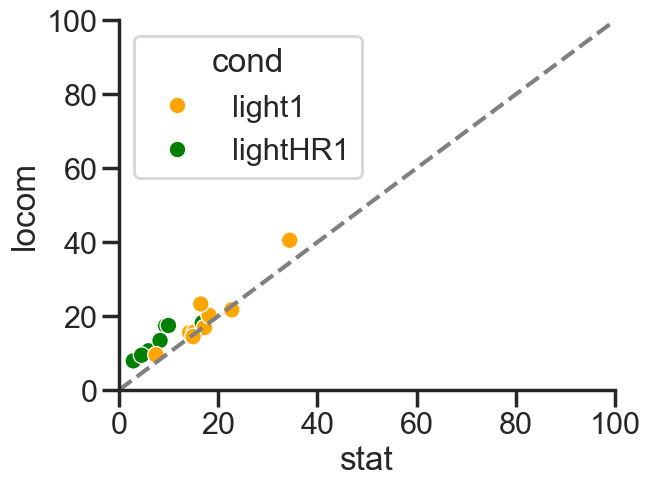

In [708]:
data = df_hr_betti
coi = ['light1', 'lightHR1']; pal = ['orange', 'green']
# coi = ['dark1', 'darkHR1'];  pal = ['gray', 'brown']
y = 'h1_bar'

unity_line = [0, 100]
_inp_plot = data[data.cond.isin(coi) 
                 & (data.rec_session.isin(hr_dark_sess))
                ].pivot(index = ['rec_id', 'cond'], 
                                                  columns = 'run', values = y).dropna().reset_index()
sns.scatterplot(data = _inp_plot, x = 'stat', y ='locom' , palette =  pal, hue = 'cond')
# sns.despine(trim=True)
plt.plot(unity_line, unity_line, c = 'gray', ls = '--')
plt.xlim(0, unity_line[1])
plt.ylim(0, unity_line[1])
# plt.savefig(f'scatter_hr_betti_{coi}_{y}.pdf', transparent = True) 

<Axes: xlabel='cond', ylabel='h1_bar'>

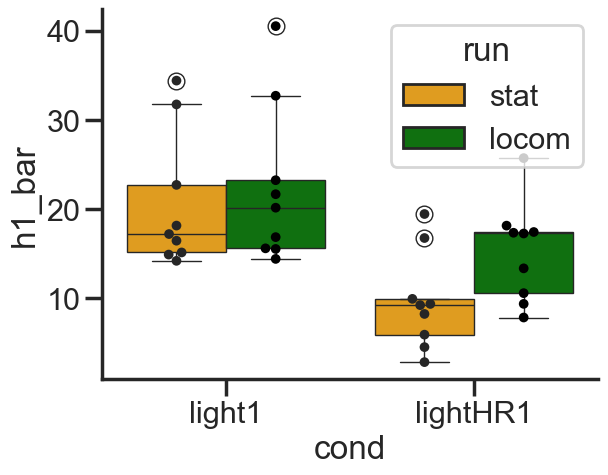

In [709]:
pal = ['orange', 'green']
_inp_plot = df_hr_betti[(df_hr_betti.cond.isin(coi))
                    & (df_hr_betti.rec_session.isin(hr_sess))
#                        & (df_hr_betti.az_occ > 0.5)
                    ]
sns.boxplot(data = _inp_plot, x = 'cond', y = y, hue = 'run', 
            palette= pal)
sns.swarmplot(data = _inp_plot, x = 'cond', y = y, hue = 'run', palette = 'dark:k', size = 7,
              dodge = True, legend = False)

# plt.savefig(f'box_hr_run_betti_{coi}_{y}.pdf', transparent = True)  

In [710]:
(_inp_plot.groupby(['cond', 'run'])[y].describe())

count       mean       std        min        25%        50%  \
cond     run                                                                  
light1   locom    9.0  22.303528  8.855579  14.425529  15.609478  20.162482   
         stat     9.0  20.550775  7.551500  14.210236  15.150577  17.210920   
lightHR1 locom    9.0  15.239635  5.539396   7.862246  10.591240  17.274356   
         stat     9.0   9.601844  5.418126   2.865592   5.941467   9.248994   

                      75%        max  
cond     run                          
light1   locom  23.243962  40.502560  
         stat   22.717576  34.398533  
lightHR1 locom  17.439497  25.718766  
         stat    9.951374  19.455693

In [711]:
a1 = _inp_plot[(_inp_plot.run == 'stat') & (_inp_plot.cond == coi[0])][y].values
a2 = _inp_plot[(_inp_plot.run == 'locom') & (_inp_plot.cond == coi[0])][y].values
b1 = _inp_plot[(_inp_plot.run == 'stat') & (_inp_plot.cond == coi[1])][y].values
b2 = _inp_plot[(_inp_plot.run == 'locom') & (_inp_plot.cond == coi[1])][y].values

stat1, pval1 = stats.wilcoxon(a1, a2)
print(f'{coi[0]} stat vs run {stat1} {pval1}')
stat2, pval2 = stats.wilcoxon(b1, b2)
print(f'{coi[1]} stat vs run {stat2} {pval2}')
stat3, pval3 = stats.mannwhitneyu(a1, b1)
print(f'stat  {stat3} {pval3}')
stat4, pval4 = stats.mannwhitneyu(a2, b2)
print(f'run {stat4} {pval4}')
pvals = [pval1, pval2, pval3, pval4]  
print('Benjamini/Hochberg (non-negative)')
print(multipletests(pvals, alpha=0.05, method='fdr_bh'))

light1 stat vs run 9.0 0.12890625
lightHR1 stat vs run 0.0 0.00390625
stat  71.0 0.00807148742526801
run 58.0 0.1333202155896274
Benjamini/Hochberg (non-negative)
(array([False,  True,  True, False]), array([0.13332022, 0.015625  , 0.01614297, 0.13332022]), 0.012741455098566168, 0.0125)


In [551]:
df_hr_betti.head()

,rec_id,cond,dts,animal_name,az_occ,run,h1_bar,dec_err,rec_session,stat_off_manifold,run_ratio
0,20211207_JA0144_light1,light1,20211207,JA0144,0.916667,stat,5.956747,27.552,JA0144_20211207,0.155352,0.659375
0,20211207_JA0144_light1,light1,20211207,JA0144,1.000000,locom,6.397861,24.376,JA0144_20211207,0.155352,0.659375
0,20220126_JA0153_light1,light1,20220126,JA0153,0.916667,stat,14.210236,22.769,JA0153_20220126,0.179570,0.612500
0,20220126_JA0153_light1,light1,20220126,JA0153,1.000000,locom,15.542182,27.529,JA0153_20220126,0.179570,0.612500
0,20220126_JA0153_lightHR1,lightHR1,20220126,JA0153,0.944444,stat,5.941467,28.507,JA0153_20220126,0.625000,0.433333


In [461]:
# _inp_plot.to_excel(filepath, index = True)

In [553]:
rec_id_keep = ['20220126_JA0153_light1', '20220126_JA0153_lightHR1',
       '20220302_JA0162_light1', '20220302_JA0162_lightHR1',
       '20220419_JA0164_light1', '20220419_JA0164_lightHR1',
       '20220819_JA0178_light1', '20220819_JA0178_lightHR1',
       '20220822_JA0178_light1', '20220822_JA0178_lightHR1',
       '20220812_JA0181_light1', '20220812_JA0181_lightHR1',
       '20220815_JA0181_light1', '20220815_JA0181_lightHR1',
       '20220818_JA0181_light1', '20220818_JA0181_lightHR1',
       '20220712_MC022_light1', '20220712_MC022_lightHR1', 
        '20220126_JA0153_dark1', '20220126_JA0153_darkHR1',
       '20220302_JA0162_dark1', '20220302_JA0162_darkHR1',
       '20220419_JA0164_dark1', '20220419_JA0164_darkHR1',
       '20220822_JA0178_dark1', '20220822_JA0178_darkHR1',
       '20220906_JA0178_dark1', '20220906_JA0178_darkHR1',
       '20220812_JA0181_dark1', '20220812_JA0181_darkHR1',
       '20220815_JA0181_dark1', '20220815_JA0181_darkHR1',
       '20220818_JA0181_dark1', '20220818_JA0181_darkHR1',
       '20220712_MC022_dark1', '20220712_MC022_darkHR1']

In [552]:
_inp_plot.rec_id.unique()

array(['20220126_JA0153_light1', '20220126_JA0153_lightHR1',
       '20220302_JA0162_light1', '20220302_JA0162_lightHR1',
       '20220419_JA0164_light1', '20220419_JA0164_lightHR1',
       '20220819_JA0178_light1', '20220819_JA0178_lightHR1',
       '20220822_JA0178_light1', '20220822_JA0178_lightHR1',
       '20220812_JA0181_light1', '20220812_JA0181_lightHR1',
       '20220815_JA0181_light1', '20220815_JA0181_lightHR1',
       '20220818_JA0181_light1', '20220818_JA0181_lightHR1',
       '20220712_MC022_light1', '20220712_MC022_lightHR1'], dtype=object)

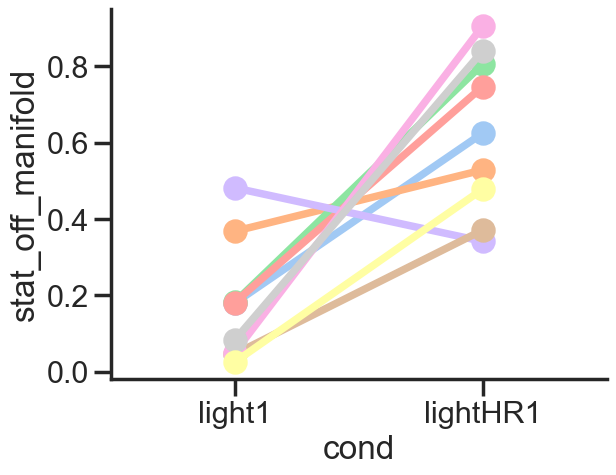

In [463]:
y = 'stat_off_manifold'

_inp_plot = df_hr_betti[df_hr_betti.cond.isin(coi) 
                     & (df_hr_betti.run == 'stat')
                     & (df_hr_betti.rec_session.isin(hr_sess))
                        # & (df_hr_betti.az_occ > 0.5)
                    ]
sns.pointplot(data = _inp_plot, x = 'cond', y = y, hue = 'rec_session')

# sns.barplot(data = _inp_plot, x = 'cond', y = y, errorbar= ('ci', 68), palette=pal)
# sns.swarmplot(data = _inp_plot, x = 'cond', y = y, color = 'k', size = 10)
plt.legend([],[], frameon=False)
# plt.savefig(f'point_hr_{coi}_{y}.pdf', transparent = True) 

In [464]:
_inp_plot.groupby('cond')[y].describe()

,count,mean,std,min,25%,50%,75%,max
cond,,,,,,,,
light1,9.0,0.177382,0.155968,0.025105,0.050000,0.17957,0.181818,0.481818
lightHR1,9.0,0.627092,0.208712,0.341648,0.478295,0.62500,0.806061,0.905683


In [465]:
a1 = _inp_plot[ (_inp_plot.cond == coi[0])][y].values
b1 = _inp_plot[ (_inp_plot.cond == coi[1])][y].values

stats.mannwhitneyu(a1, b1)

MannwhitneyuResult(statistic=4.0, pvalue=0.0014784647972275091)

### Plot embeddings

In [87]:
df_arena_emb.condition.unique()

array(['light1', 'dark'], dtype=object)

In [272]:
# df_arena_emb.loc[:, 'running'] = np.where(df_arena_emb['vel'] > 5, True, False)
# df_frun_emb.loc[:, 'running'] = np.where(df_frun_emb['velocity'] > 5, True, False)
df_hr_arena_emb.loc[:, 'running'] = np.where(df_hr_arena_emb['vel'] > 5, True, False)
# df_arena_emb['emb_angle'] =  np.arctan2(df_arena_emb.emb_x, df_arena_emb.emb_y)*180/np.pi

In [217]:
cond_ls

['dark1', 'darkHR1', 'light1', 'lightHR1']

20211212_JA0144_dark1


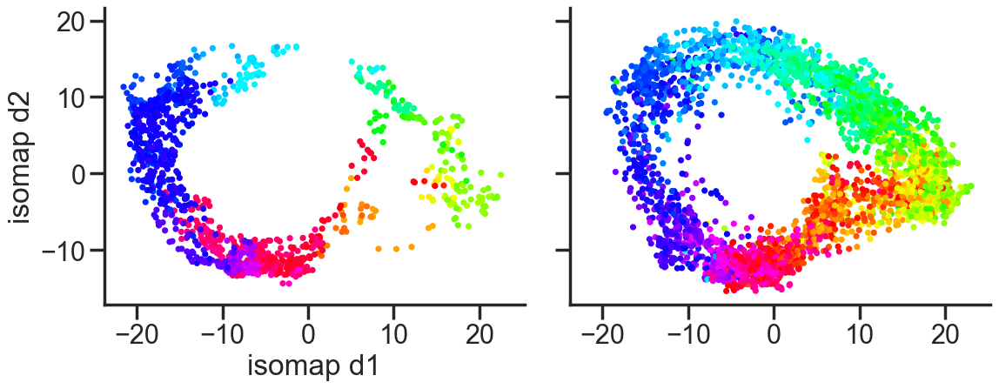

20211212_JA0144_darkHR1


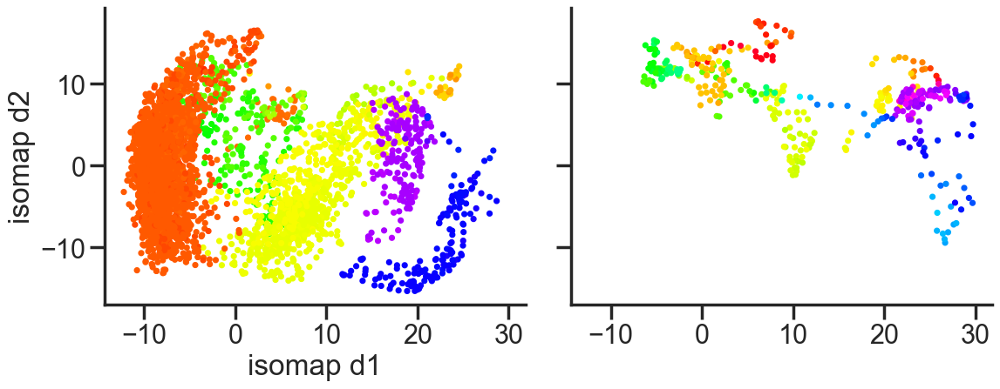

20211212_JA0144_light1


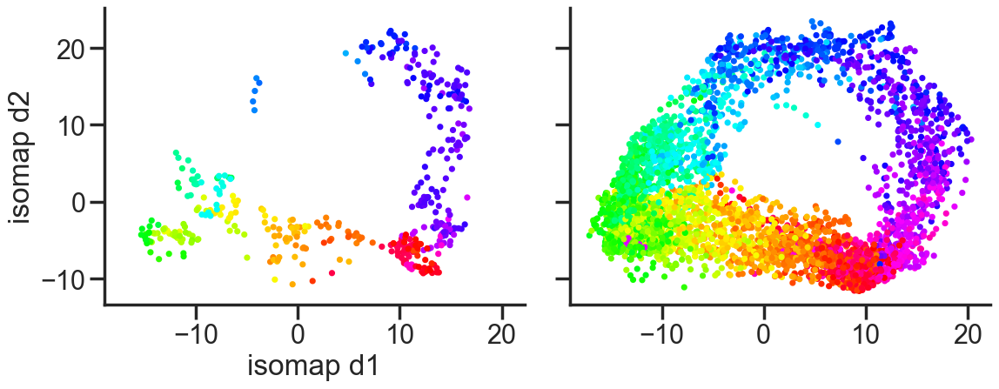

20211212_JA0144_lightHR1


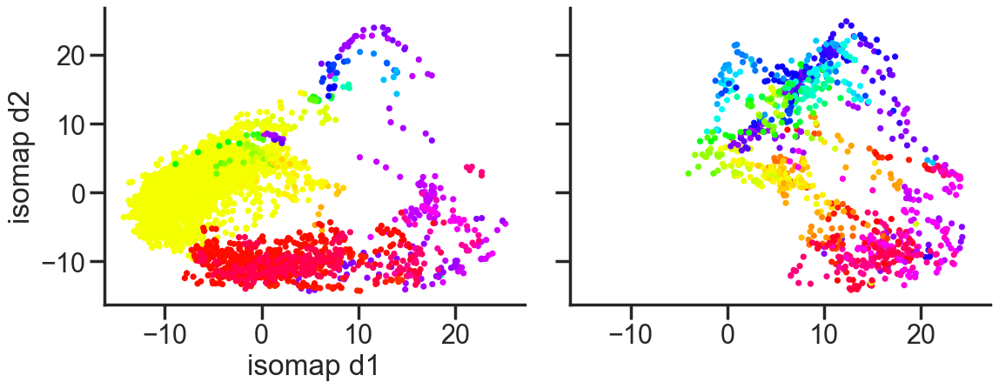

20220209_JA0153_dark1


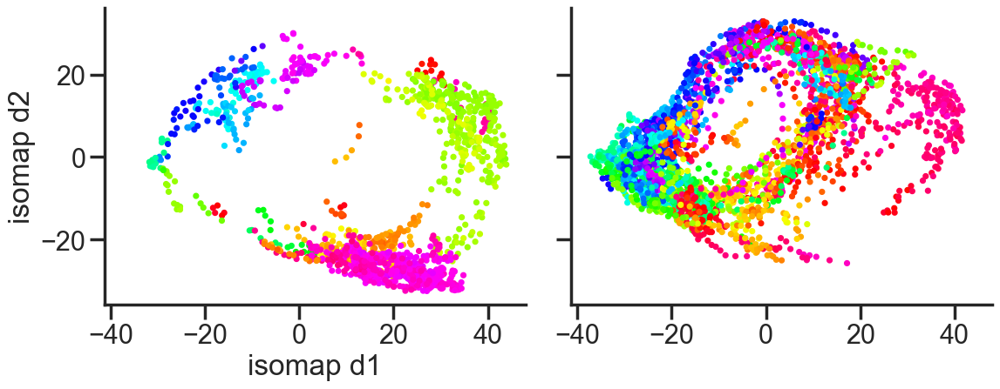

20220209_JA0153_darkHR1


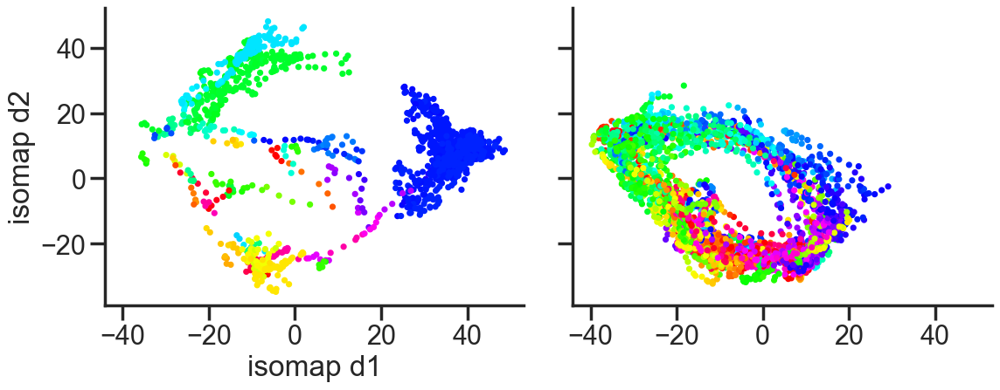

20220209_JA0153_light1


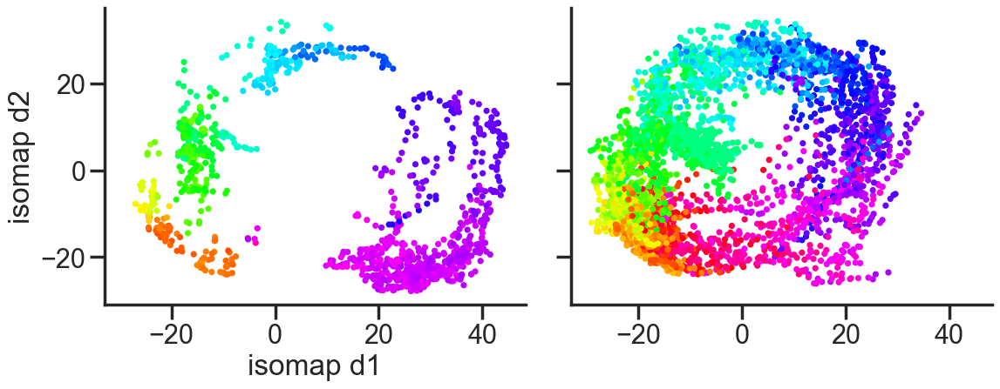

20220209_JA0153_lightHR1


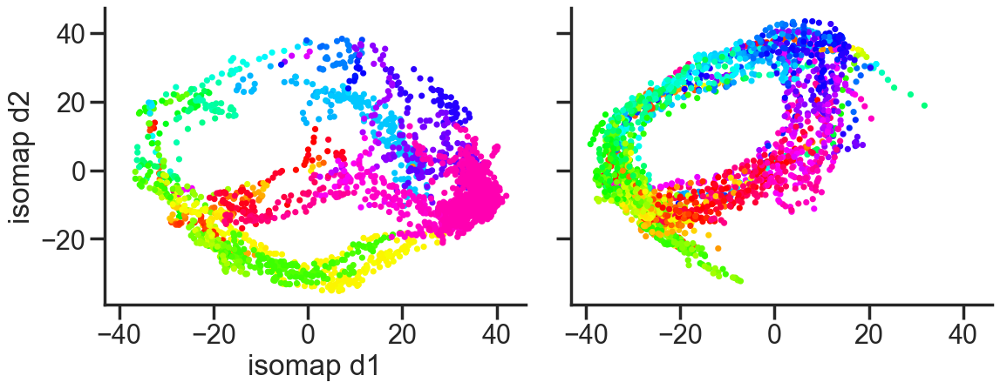

20220302_JA0162_dark1


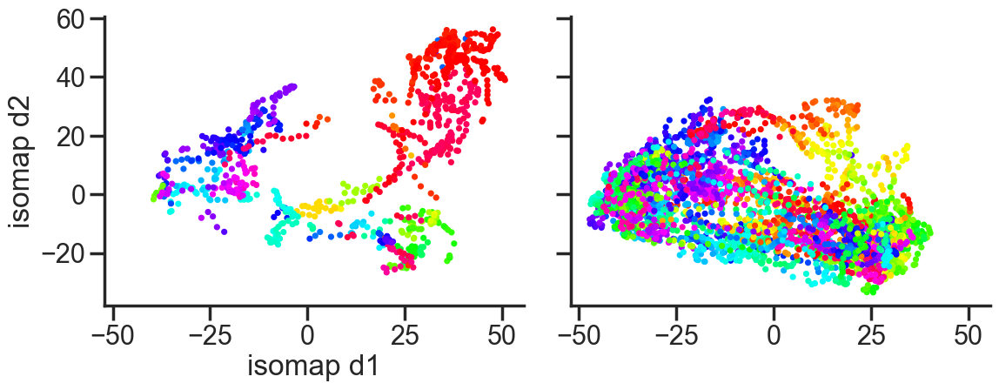

20220302_JA0162_darkHR1


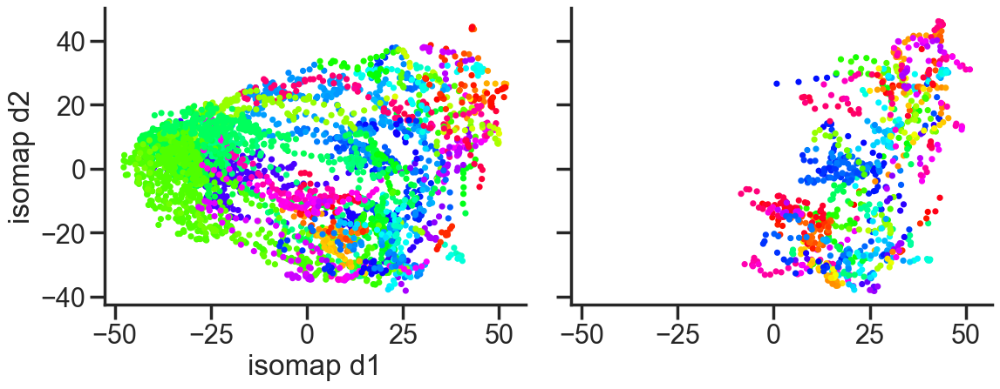

20220302_JA0162_light1


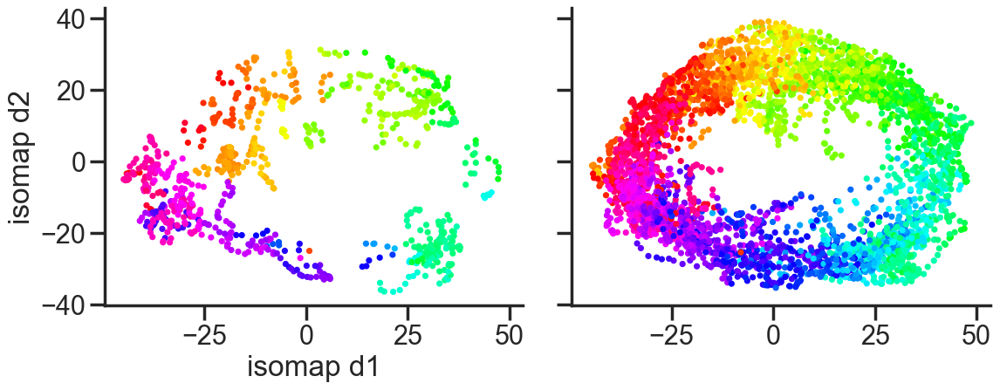

20220302_JA0162_lightHR1


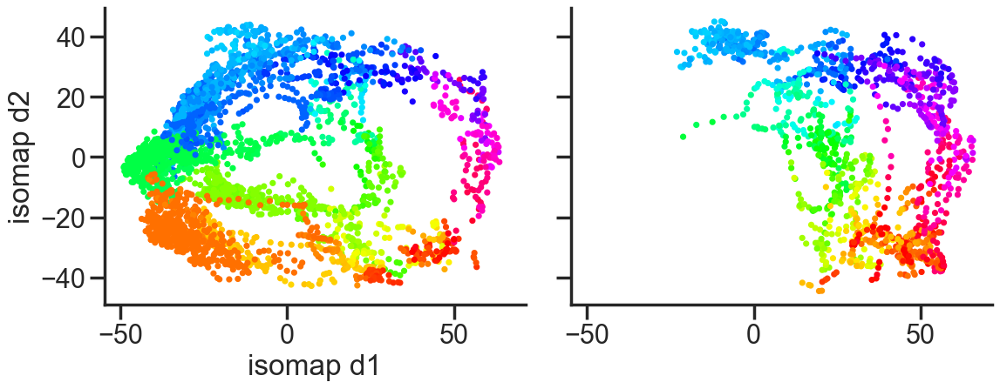

20220419_JA0164_dark1


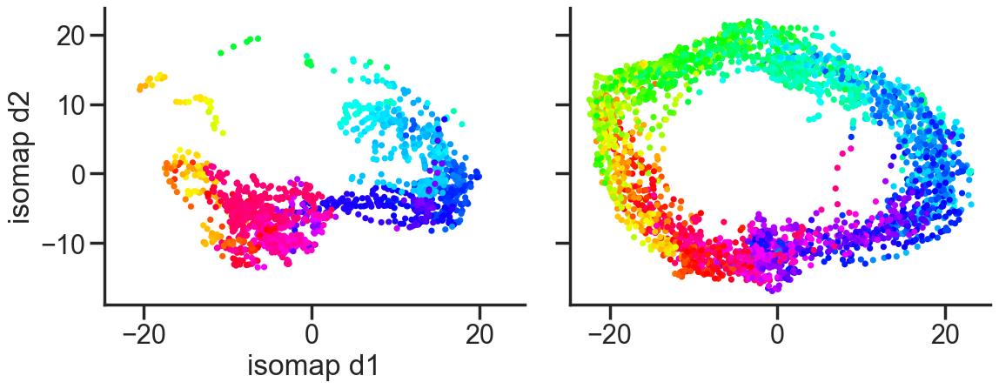

20220419_JA0164_darkHR1


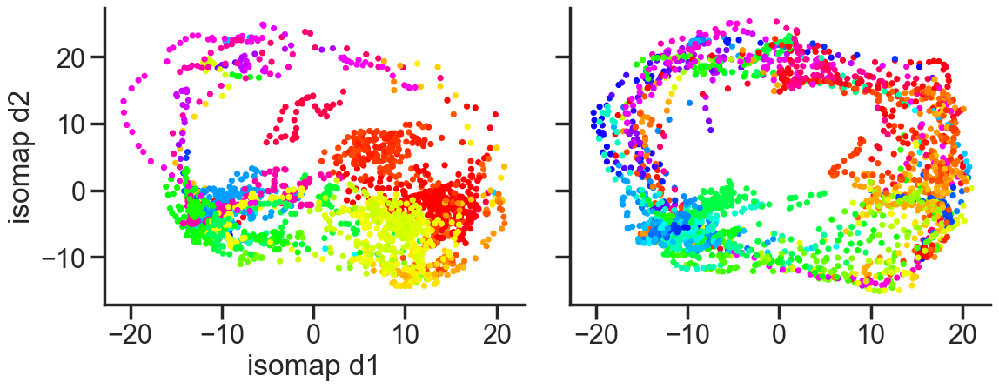

20220419_JA0164_light1


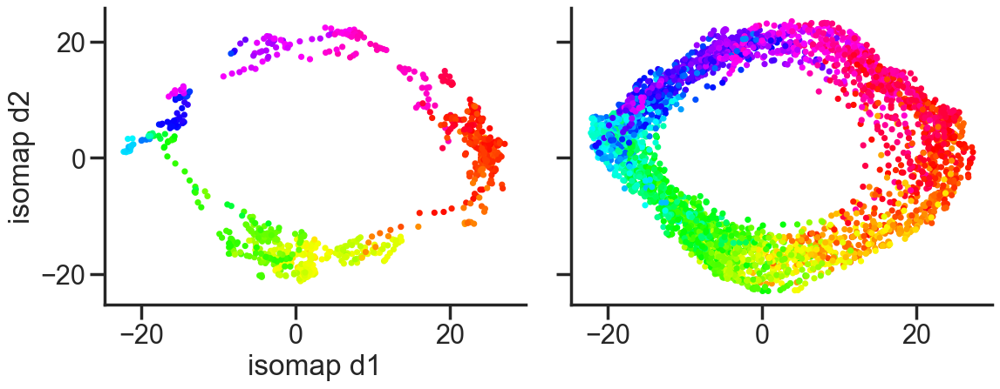

20220419_JA0164_lightHR1


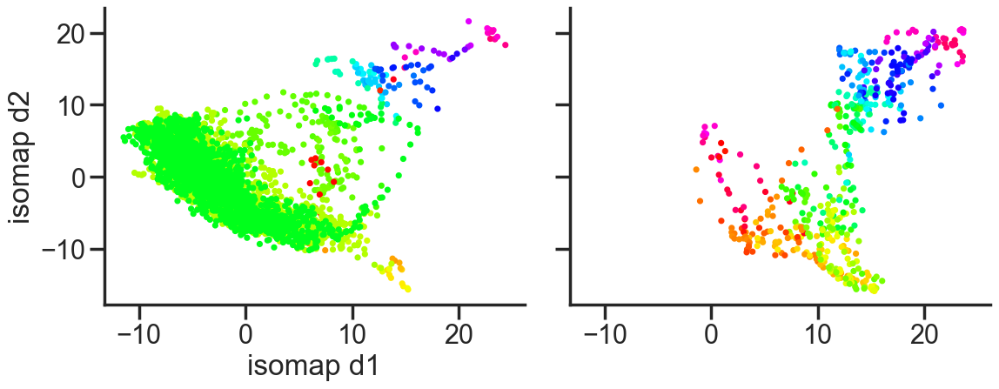

20220426_JA0164_dark1


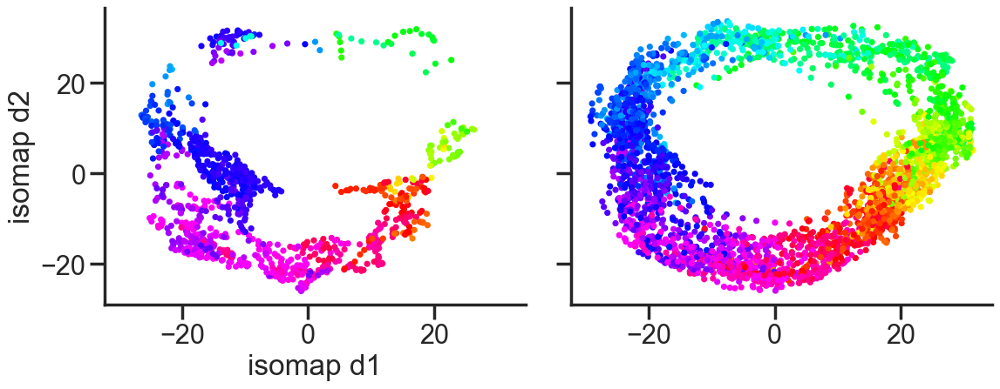

20220426_JA0164_darkHR1


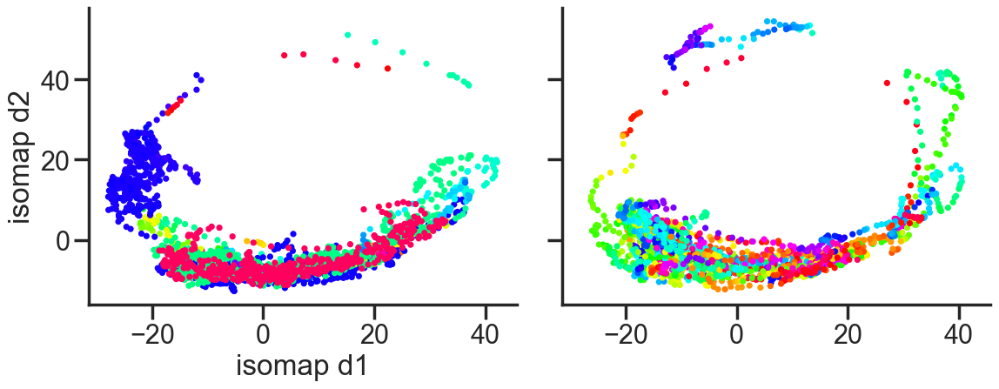

20220426_JA0164_light1


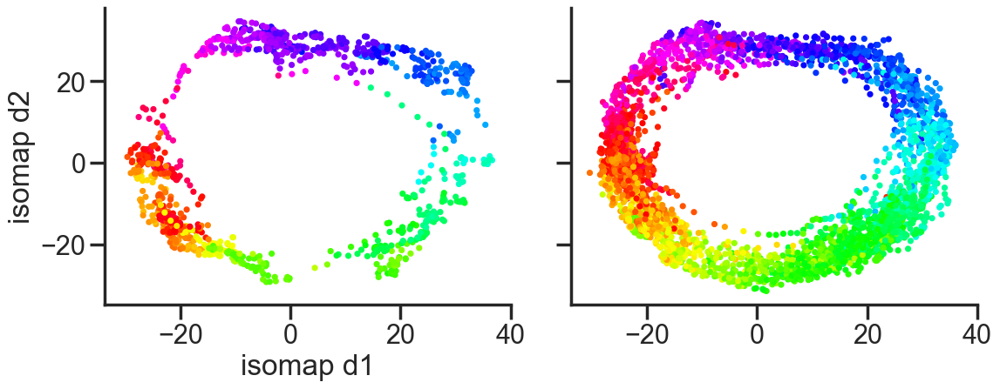

20220426_JA0164_lightHR1


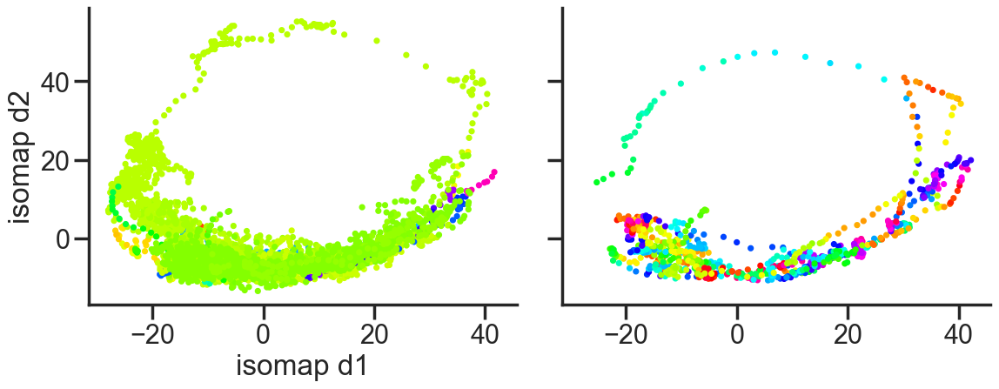

In [616]:
ls = []
data = df_hr_emball
for rec in data.rec_id.unique():

    f, ax = plt.subplots(1, 2, figsize = (12, 5), sharex  = True, sharey = True)
    
    tmp = data[(data.rec_id == rec) 
#                & (data.condition == con)
              ]

    print(f'{rec}')
    
    time_s = np.arange(0, tmp.shape[0]/50, 0.02)
    start, end = 0, 1800
    yaw = tmp['yaw'].values
    speed = tmp['vel'].values
    try:
        stat_idx, locom_idx = get_stat_run_epochs(speed, window_size=5, speed_thr = 4)
    except Exception as e:
        print (e)
        continue 
#         stat_idx = np.where(speed < 4)[0]
#         locom_idx = np.where(speed > 4)[0]
    x = tmp.emb_x.values
    y = tmp.emb_y.values
#             yaw_dec = np.arctan2(x, y)*180/np.pi

#             offset = ((yaw[:500] - yaw_dec[:500]) + 180)%360 - 180
#             yaw_dec = (yaw_dec + np.mean(offset) + 180)%360 - 180
#             offset = ((yaw[:500] - yaw_dec[:500]) + 180)%360 - 180

#             if np.mean(abs(offset)) > 60:
#                 yaw_dec = np.arctan2(y, x)*180/np.pi
#                 offset = ((yaw[:500] - yaw_dec[:500]) + 180)%360 - 180
#                 yaw_dec = (yaw_dec + np.mean(offset) + 180)%360 - 180
#                 offset = ((yaw[:500] - yaw_dec[:500]) + 180)%360 - 180
#             print(np.mean(abs(offset)), np.std(offset))
#             tmp.loc[:,'yaw_dec'] = yaw_dec
#         ls.append(tmp)
    p1 = ax[0].scatter(x[stat_idx] , y[stat_idx], c = yaw[stat_idx], s = 10, vmin = -180, vmax = 180, cmap = 'hsv')
    p = ax[1].scatter(x[locom_idx] , y[locom_idx], c = yaw[locom_idx], s = 10, vmin = -180, vmax = 180, cmap = 'hsv')
#             ax[0].plot(x, y, alpha = 0.5)
#         f.colorbar(p)
    ax[0].set_xlabel('isomap d1')
    ax[0].set_ylabel('isomap d2')
#         ax[1].plot(time_s[:], yaw[:], '.' , alpha = 0.5)
#         ax[1].plot(time_s[:], speed[:], '.' , alpha = 0.5)
#             ax[1].plot(time_s[:200], yaw_dec[:200], '.', color = 'crimson', alpha = 0.5)
#         ax[1].set_xlabel('Time (s)')
#         ax[1].set_ylabel('Az (deg)')
#         ax[0].set_xlim(-15, 15)
#         ax[0].set_ylim(-15, 15)
    plt.tight_layout()
    plt.show()
        
    
    
            # ax[2].plot(speed)
# df_arena_emb = pd.concat(ls)
    

In [1047]:
df_arena_emb.loc[:, 'isomap_err'] = abs(((df_arena_emb.yaw - df_arena_emb.yaw_dec) + 180)%360 - 180)
dyaw = np.diff(df_arena_emb.yaw_dec, 1)
dyaw[np.abs(dyaw) > 180] = 0
omega_dec = savgol_filter(dyaw, window_length=31, polyorder=2)
# data downsampled to 5 Hz
omega_dec *= 1/0.2
omega_dec = np.insert(omega_dec, 0, 0)
df_arena_emb.loc[:, 'ahv_dec'] = omega_dec

dyaw = np.diff(df_arena_emb.yaw, 1)
dyaw[np.abs(dyaw) > 180] = 0
omega = savgol_filter(dyaw, window_length=31, polyorder=2)
# data downsampled to 5 Hz
omega *= 1/0.2
omega = np.insert(omega, 0, 0)
df_arena_emb.loc[:, 'ahv'] = omega

df_arena_emb.loc[:, 'omega_dec_err'] = abs((df_arena_emb.ahv - df_arena_emb.ahv_dec))

In [1046]:
y = df_arena.omega.values
y[y< 0].mean()

-29.33108832199879

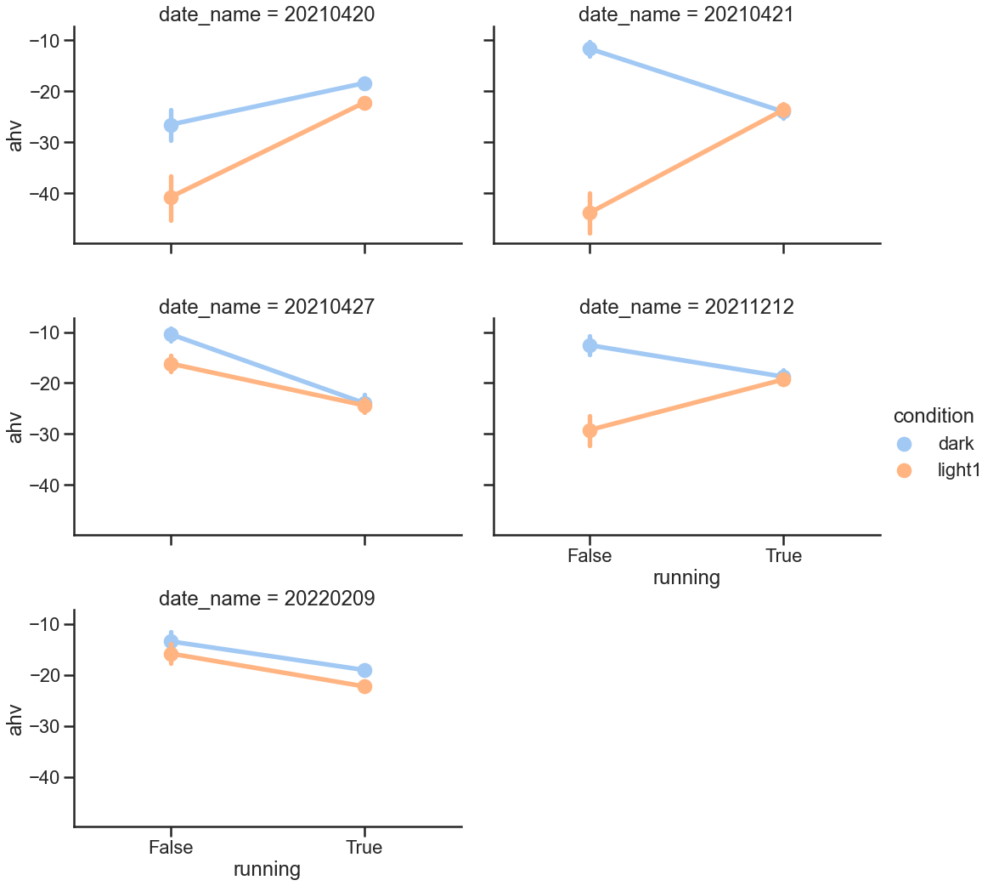

In [1055]:
g = sns.catplot(x = 'running', y = 'ahv', data = df_arena_emb[df_arena_emb.ahv < 0], 
               kind = 'point', hue = 'condition', hue_order = ['dark', 'light1'],
            col = 'date_name', col_wrap =2, 
                aspect = 1.5, height = 5)

## HR dark analysis

In [554]:
hr_dark_sess = ['JA0153_20220126', 'JA0162_20220302', 'JA0164_20220419',
        'JA0178_20220822', 'JA0181_20220812', 'JA0178_20220906',
       'JA0181_20220815', 'JA0181_20220818', 'MC022_20220712']

### Plot betti barcodes

20211207_JA0144_light1
H1 bar length 6.151793837547302 dec err 25.458207033783662
off_manifold_index 0.34520833333333334


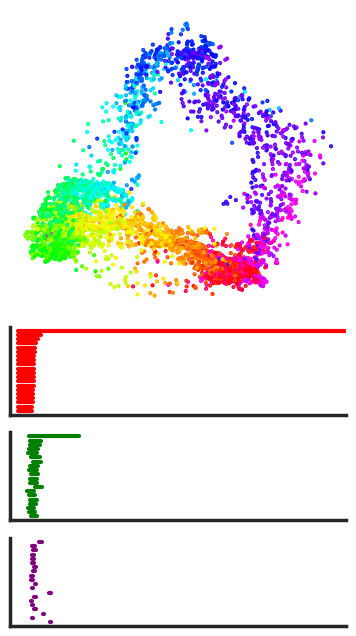

In [54]:
col_list = ['red', 'green', 'purple']
coi = ['light1', 'lightHR1']
angles = np.arange(0, 380, 20)
h1_bar_max = 40
ls = []

for k in d_hr_emb.keys():

    dts, mouse_id, cond = k.split('_')[-3:]
    if 'light1' not in k:
        continue

    fig = plt.figure(figsize=(12, 8))
    gs = gridspec.GridSpec(6, 8)
    rec_session = mouse_id + '_' + dts

    tmp = d_hr_emb[k]
    isomap = tmp['isomap']
    measured_yaw = tmp['measured_yaw']
    emb_x, emb_y = isomap[:, 0], isomap[:, 1]
    isomap_yaw, dec_err, _ = decode_az_isomap(isomap[:, 0], isomap[:, 1], measured_yaw[:])
    lin_speed = tmp['lin_vel']
    h1_bar = tmp['h1_bar']
    try:
        stat_idx, run_idx = get_stat_run_epochs(lin_speed, window_size=5, speed_thr = 5)
        # _, rot_idx = get_stat_run_epochs(ang_vel, window_size=5, speed_thr = 2)
    except:
        continue
        
    # compute off manifold ratios
    run_mask = np.zeros(lin_speed.size, dtype=bool)
    run_mask[run_idx] = True

    # new function to compute rad
    cxy, rad_manifold = compute_radius_runmask(emb_x, emb_y, run_mask)
    rad_manifold_norm = rad_manifold/rad_manifold.max()

    r90  = np.percentile(rad_manifold, 90)
    threshold = (r90 - 0.3*r90)

    off_ring = rad_manifold < threshold
    off_ring_ratio = np.sum(off_ring)/rad_manifold.size
    
    print(f'{k}')
    print(f'H1 bar length {h1_bar} dec err {dec_err}')
    print(f'off_manifold_index {off_ring_ratio}')
    ax = fig.add_subplot(gs[0:3, 0:3])
    ax.scatter(isomap[:,0], isomap[:,1], s = 1, c = measured_yaw[:], 
                                           vmin = -180, vmax = 180, cmap = 'hsv')
    ax.axis('off')
    # ax.set_xlim(-40, 40)
    # ax.set_ylim(-40, 40)
    plt.xticks([])

    h0 = tmp['h0']
    h1 = tmp['h1']
    h2 = tmp['h2']    
    to_plot, h1_bar_run = get_long_bettibars(h0, h1, h2)
    
    for curr_betti, curr_bar in enumerate(to_plot):
        ax = fig.add_subplot(gs[curr_betti +3: curr_betti + 4, :3])
        for i, interval in enumerate((curr_bar)):
            ax.plot([interval[0], interval[1]], [i, i], color=col_list[curr_betti], lw=3)
        ax.set_xlim([-1, 40])
        plt.xticks([])
        plt.yticks([])
    
    plt.show()
    break
#     tmp_df = pd.DataFrame({'rec_id': k,  'cond': cond,  'dts': dts, 'mouse_id': mouse_id,
#                        'epoch': 'full', 'h1_bar': h1_bar, 'dec_err': dec_err, 'rec_session':rec_session,
#                        'off_manifold_index': off_ring_ratio}, index = [0])
#     ls.append(tmp_df)    
    
#     # break

    
# df_betti = pd.concat(ls)
# df_betti.head()

### Stat vs run

20220126_JA0153_dark1, # of hdc 18
dec err stat:78.447, run:57.038
az occ stat:0.9444444444444444, run:1.0, off-manifold index 0.32375249500998005
h1_ratio_stat 1.1912022049625441, h1_ratio_run 6.368179089441387


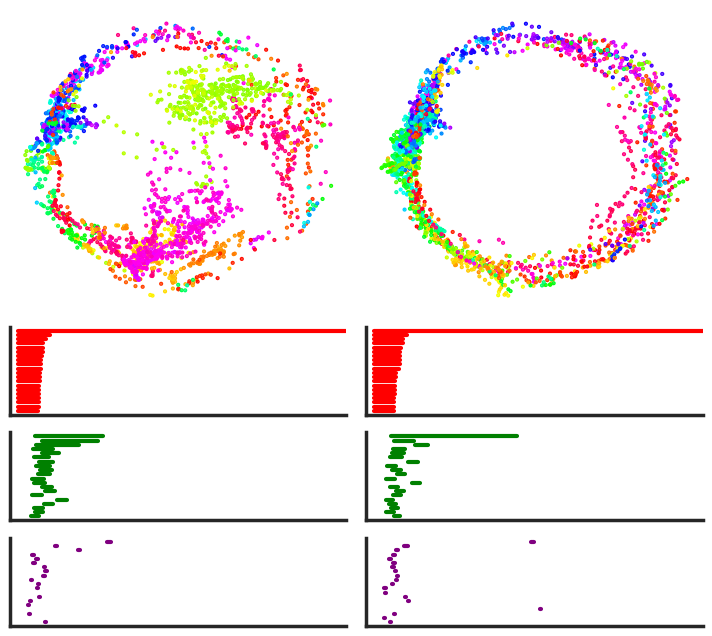

20220126_JA0153_darkHR1, # of hdc 21
dec err stat:36.301, run:52.607
az occ stat:0.9444444444444444, run:1.0, off-manifold index 0.6993630573248407
h1_ratio_stat 1.2685061891993739, h1_ratio_run 6.44313353684304


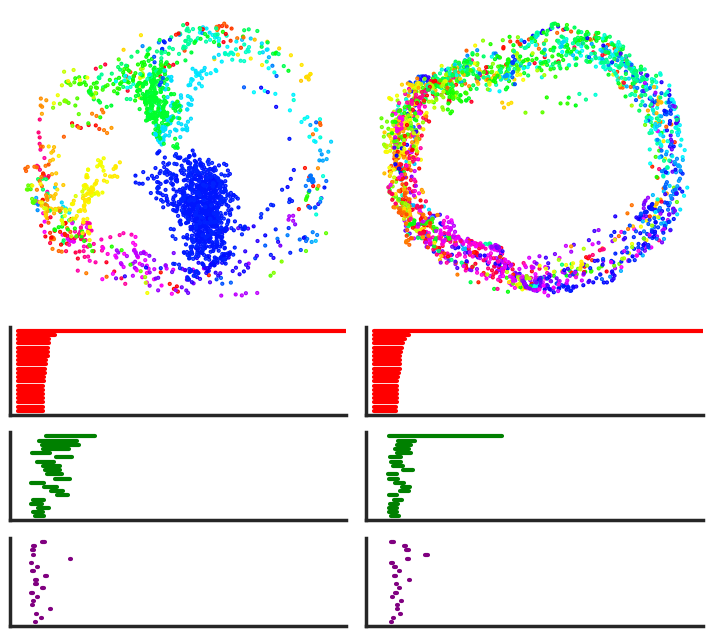

20220302_JA0162_dark1, # of hdc 11
dec err stat:50.007, run:64.498
az occ stat:0.9722222222222222, run:1.0, off-manifold index 0.6653061224489796
h1_ratio_stat 1.6557058384995627, h1_ratio_run 4.964795747886578


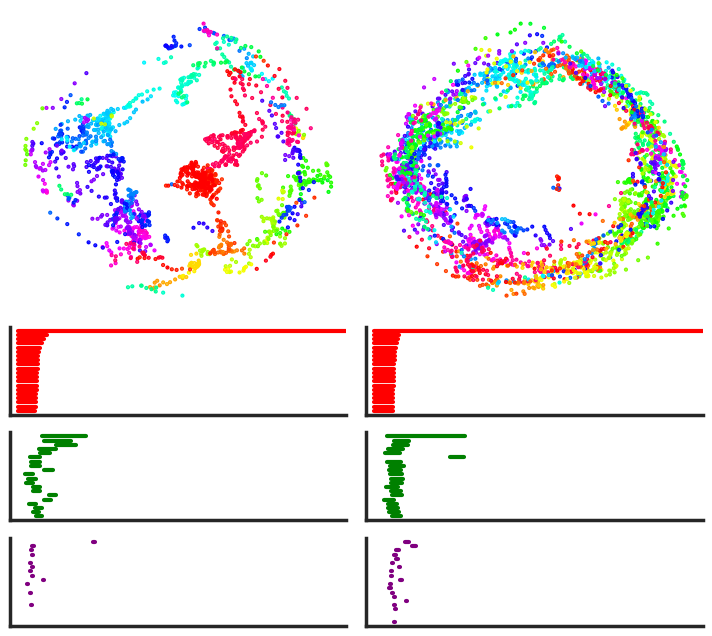

20220302_JA0162_darkHR1, # of hdc 10
dec err stat:81.896, run:95.661
az occ stat:0.9444444444444444, run:0.7777777777777778, off-manifold index 0.771916971916972
h1_ratio_stat 1.8996336037373758, h1_ratio_run 3.0873966567248394


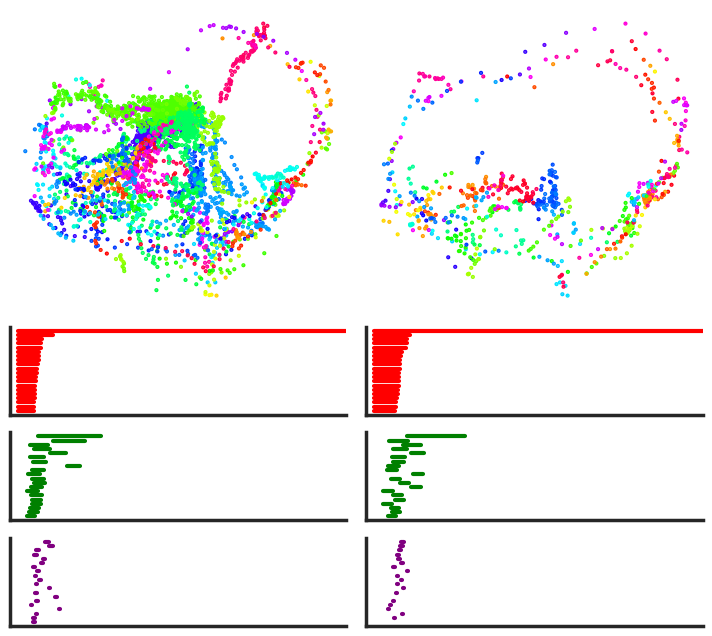

20220419_JA0164_dark1, # of hdc 11
dec err stat:26.14, run:27.902
az occ stat:0.9166666666666666, run:1.0, off-manifold index 0.6971922246220302
h1_ratio_stat 2.601409796961672, h1_ratio_run 3.4825073188213675


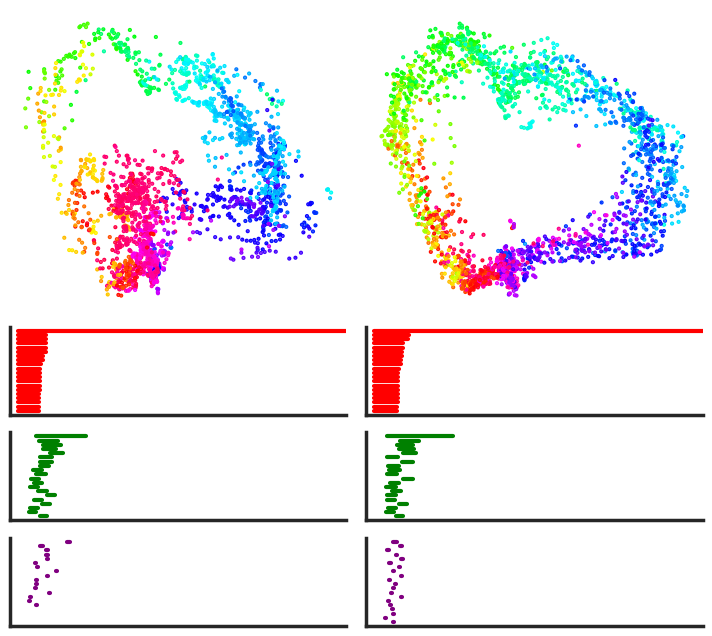

20220419_JA0164_darkHR1, # of hdc 11
dec err stat:43.694, run:58.344
az occ stat:0.9444444444444444, run:1.0, off-manifold index 0.5363636363636364
h1_ratio_stat 2.1353975293456275, h1_ratio_run 1.7107208805734204


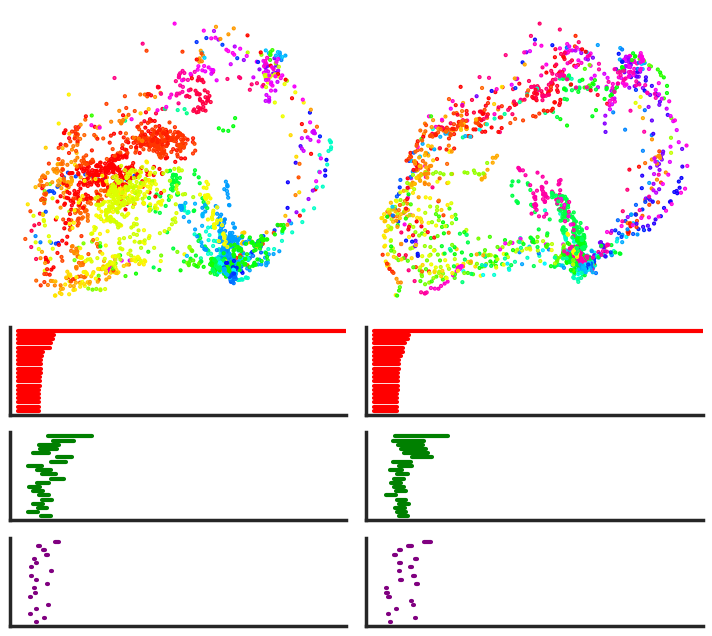

20220819_JA0178_dark1, # of hdc 30
dec err stat:30.167, run:22.859
az occ stat:0.9444444444444444, run:1.0, off-manifold index 0.5012165450121655
h1_ratio_stat 2.00719233161403, h1_ratio_run 3.9048925895625897


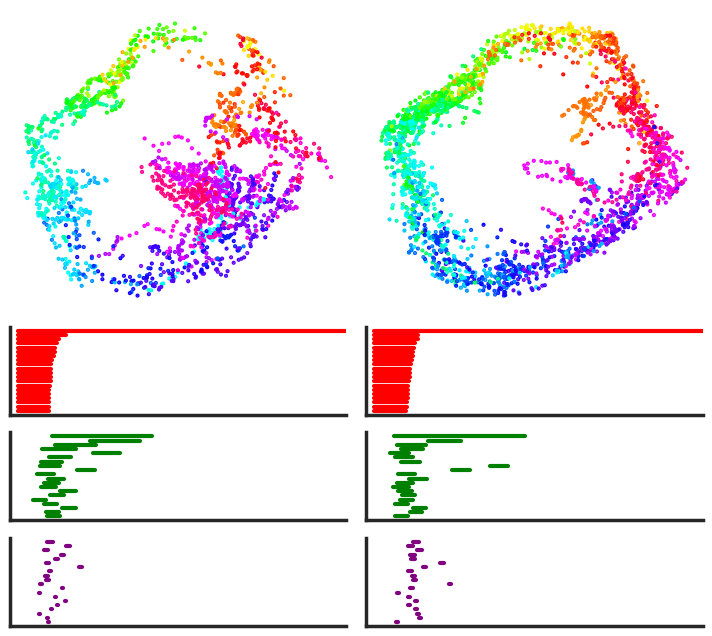

20220819_JA0178_darkHR1, # of hdc 28
20220822_JA0178_dark1, # of hdc 27
dec err stat:23.477, run:22.655
az occ stat:0.9166666666666666, run:1.0, off-manifold index 0.6459958932238193
h1_ratio_stat 2.4594515413556417, h1_ratio_run 3.240523358583879


<Figure size 1200x800 with 0 Axes>

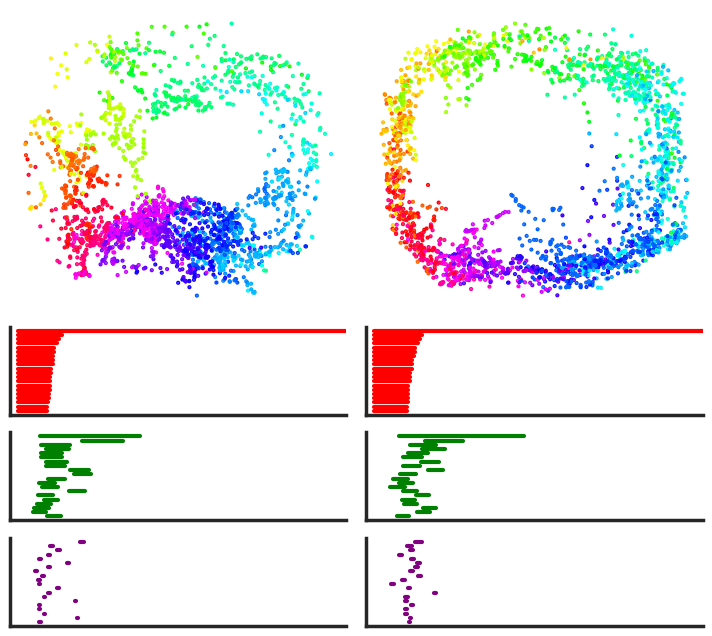

20220822_JA0178_darkHR1, # of hdc 27
dec err stat:37.908, run:44.753
az occ stat:0.9166666666666666, run:1.0, off-manifold index 0.6124783362218371
h1_ratio_stat 1.134505123030025, h1_ratio_run 6.501697453518891


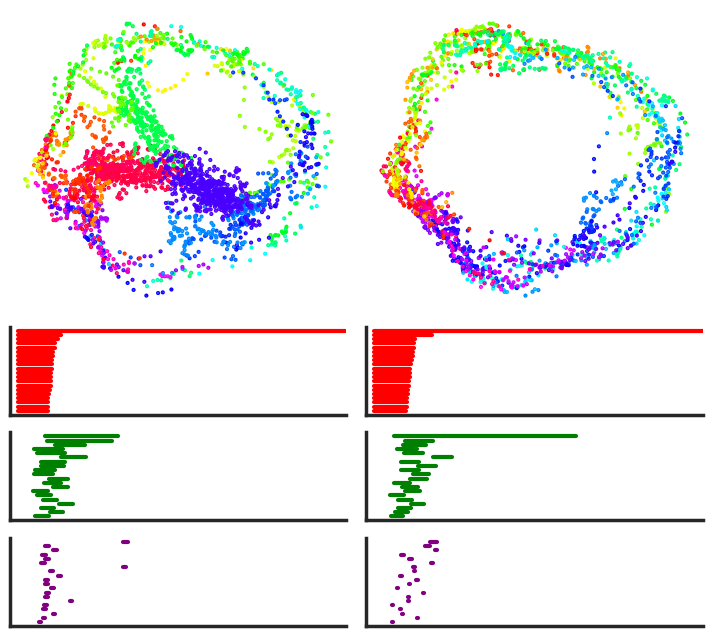

20220906_JA0178_dark1, # of hdc 11
dec err stat:32.5, run:21.908
az occ stat:0.9444444444444444, run:1.0, off-manifold index 0.5586206896551724
h1_ratio_stat 1.8163829683449573, h1_ratio_run 1.8407568740959892


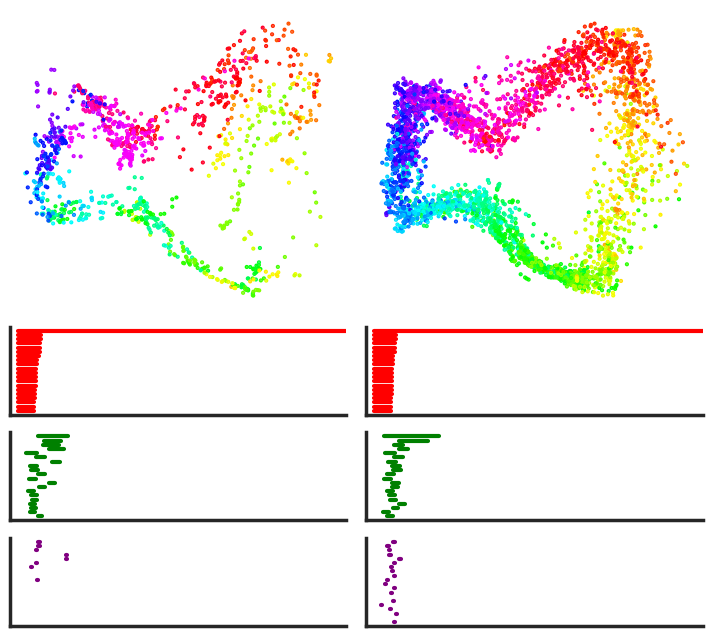

20220906_JA0178_darkHR1, # of hdc 11
dec err stat:62.029, run:75.541
az occ stat:0.9444444444444444, run:1.0, off-manifold index 0.5544736842105263
h1_ratio_stat 1.1109809812828013, h1_ratio_run 2.6195391657268288


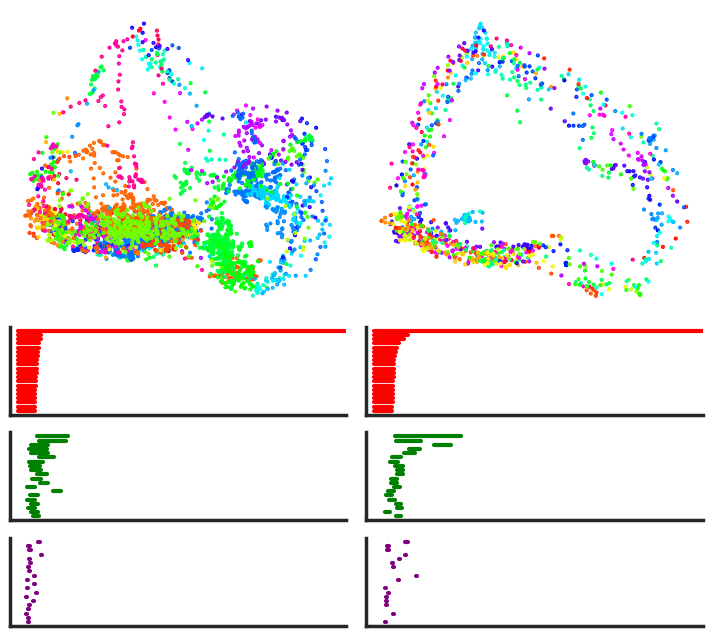

20220812_JA0181_dark1, # of hdc 18
dec err stat:30.21, run:27.079
az occ stat:0.9444444444444444, run:1.0, off-manifold index 0.2487272727272727
h1_ratio_stat 3.250337040334041, h1_ratio_run 2.927643731547679


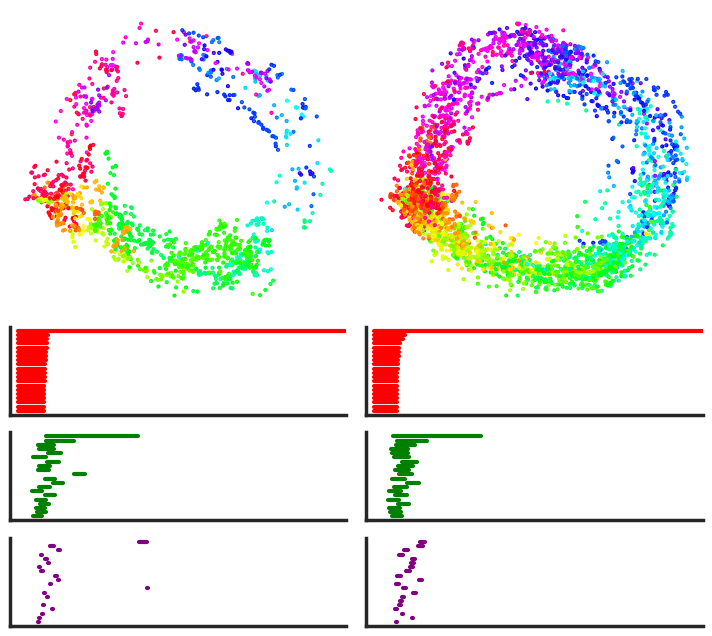

20220812_JA0181_darkHR1, # of hdc 17
dec err stat:31.787, run:32.407
az occ stat:0.9444444444444444, run:0.8888888888888888, off-manifold index 0.6767156862745098
h1_ratio_stat 1.8459638921475774, h1_ratio_run 5.311378660175816


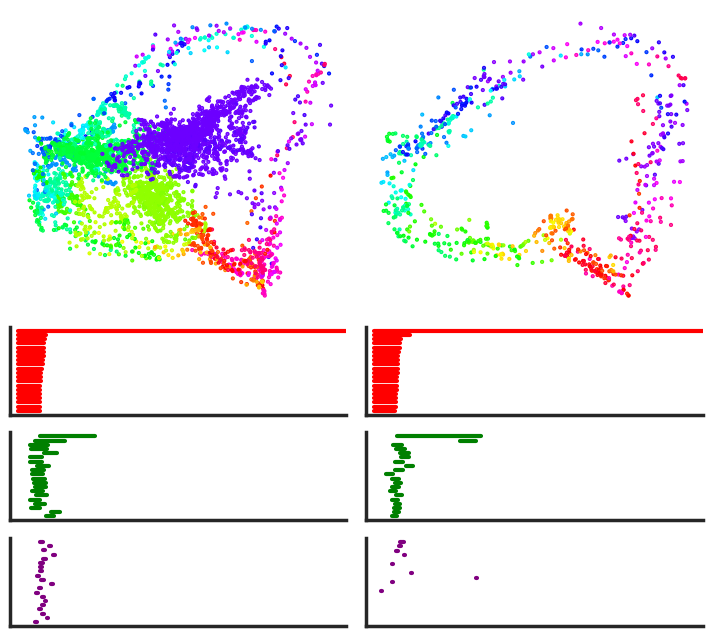

20220815_JA0181_dark1, # of hdc 16
dec err stat:32.545, run:32.917
az occ stat:0.9722222222222222, run:1.0, off-manifold index 0.0
h1_ratio_stat 16.3369360217264, h1_ratio_run 24.54246792540841


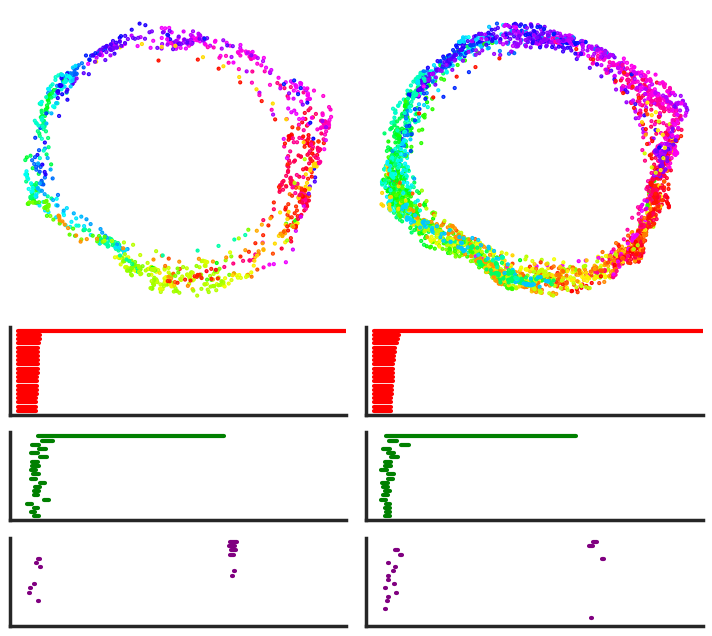

20220815_JA0181_darkHR1, # of hdc 16
dec err stat:61.593, run:56.091
az occ stat:0.9722222222222222, run:0.9722222222222222, off-manifold index 0.7035532994923858
h1_ratio_stat 1.386015726487693, h1_ratio_run 7.162950360168366


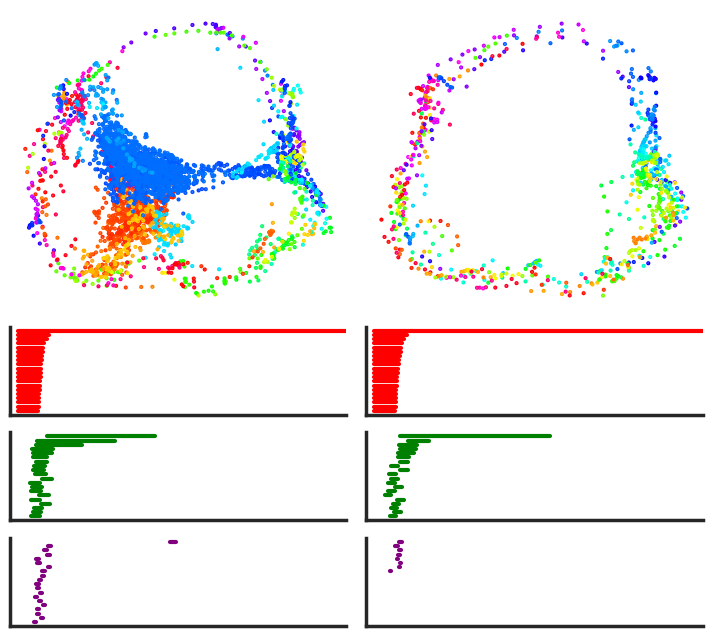

20220818_JA0181_dark1, # of hdc 14
dec err stat:17.381, run:23.663
az occ stat:0.9166666666666666, run:1.0, off-manifold index 0.014448669201520912
h1_ratio_stat 15.900044198281869, h1_ratio_run 16.004825156378086


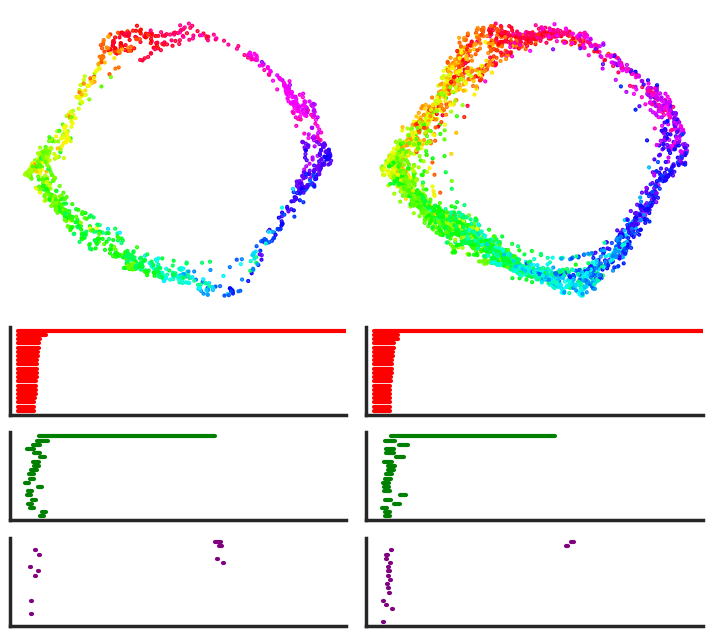

20220818_JA0181_darkHR1, # of hdc 14
dec err stat:81.031, run:78.574
az occ stat:1.0, run:1.0, off-manifold index 0.46277602523659306
h1_ratio_stat 1.7533234855464925, h1_ratio_run 7.952303740810532


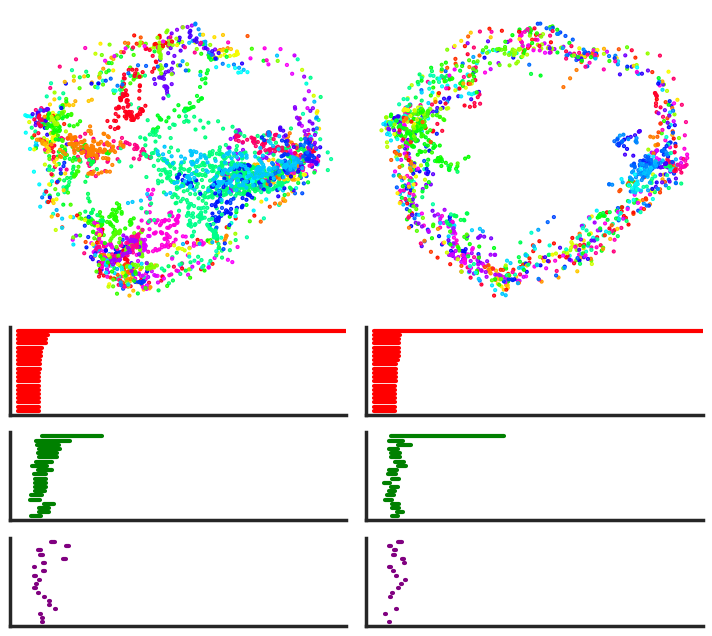

20220712_MC022_dark1, # of hdc 41
dec err stat:16.845, run:17.182
az occ stat:1.0, run:1.0, off-manifold index 0.06820276497695853
h1_ratio_stat 13.429662022827547, h1_ratio_run 7.0876648378706495


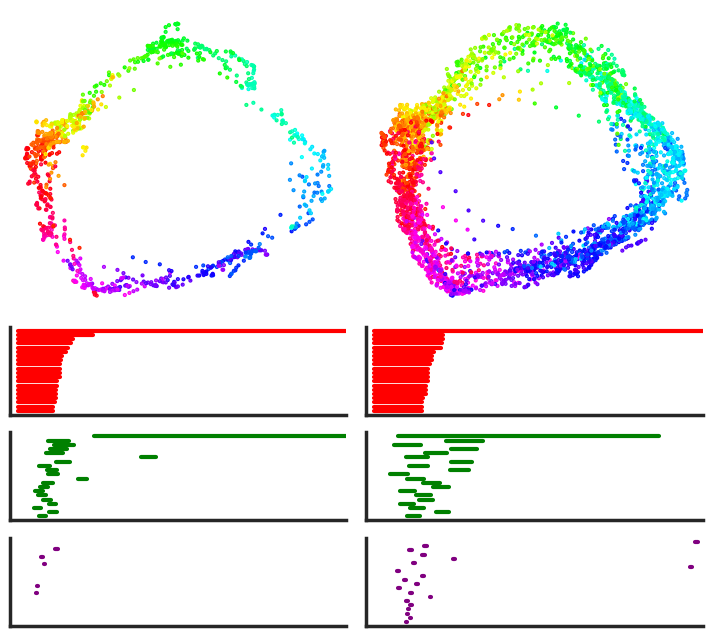

20220712_MC022_darkHR1, # of hdc 41
dec err stat:45.67, run:39.91
az occ stat:0.9166666666666666, run:0.9722222222222222, off-manifold index 0.5806615776081425
h1_ratio_stat 6.070581995962529, h1_ratio_run 4.669196506722499


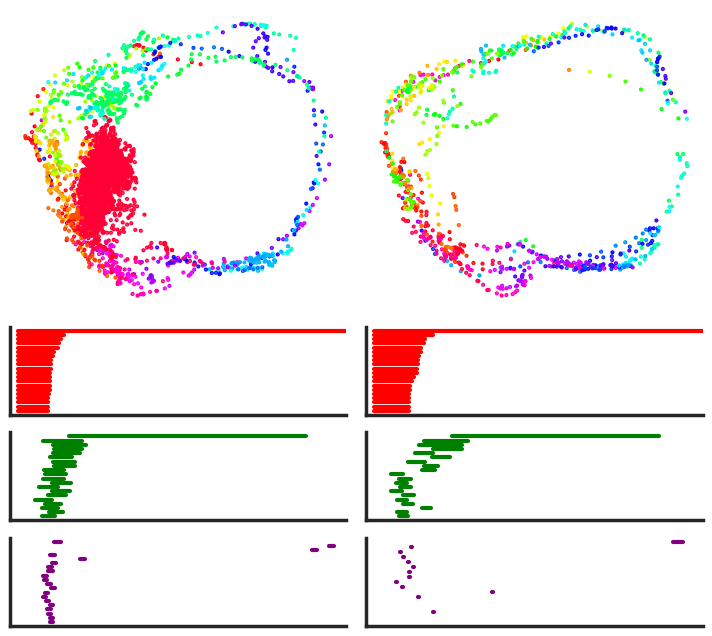

,rec_id,cond,dts,animal_name,az_occ,h1_ratio,run,h1_bar,dec_err,rec_session,stat_off_ring_ratio,run_ratio
0,20220126_JA0153_dark1,dark1,20220126,JA0153,0.944444,1.191202,stat,8.241301,78.447,JA0153_20220126,0.323752,0.478125
0,20220126_JA0153_dark1,dark1,20220126,JA0153,1.000000,6.368179,locom,15.354324,57.038,JA0153_20220126,0.323752,0.478125
0,20220126_JA0153_darkHR1,darkHR1,20220126,JA0153,0.944444,1.268506,stat,5.938250,36.301,JA0153_20220126,0.699363,0.509375
0,20220126_JA0153_darkHR1,darkHR1,20220126,JA0153,1.000000,6.443134,locom,13.744541,52.607,JA0153_20220126,0.699363,0.509375
0,20220302_JA0162_dark1,dark1,20220302,JA0162,0.972222,1.655706,stat,5.308832,50.007,JA0162_20220302,0.665306,0.642708


In [555]:
col_list = ['red', 'green', 'purple']
angles = np.arange(-180, 200, 20)
h1_bar_max = 40
ls = []

for k in d_hr_emb.keys():
    dts, animal_name, cond = k.split('_')[-3:]
    if 'dark' not in k:
        continue
    fig = plt.figure(figsize=(12, 8))
    gs = gridspec.GridSpec(6, 8)
    rec_session = animal_name + '_' + dts
    tmp = d_hr_emb[k]
    isomap = tmp['isomap']
    measured_yaw = tmp['measured_yaw']
    lin_vel = tmp['lin_vel']
    n_hdc = tmp['n_hdc']
    stat_az_occ = tmp['stat_az_occ'] 
    run_az_occ = tmp['run_az_occ'] 
    
    print(f'{k}, # of hdc {n_hdc}')
    if n_hdc < 10:
        continue

    if run_az_occ < 0.2:
        continue
    stat_idx, run_idx = tmp['stat_idx'], tmp['run_idx']
#     try:
#         stat_idx, run_idx = get_stat_run_epochs(lin_vel, window_size=5, speed_thr = 6)
#     except Exception as e:
#         print (e)
#         continue 
        
    stat_dec_err, loc_dec_err = tmp['stat']['dec_err'], tmp['run']['dec_err']
    run_ratio = run_idx.size/lin_vel.size
    
    # 10 samples = 1s
#     occup, _ = np.histogram(measured_yaw[stat_idx], bins = angles)
#     stat_az_occ = occup[occup > 10].size/occup.size
#     occup, _ = np.histogram(measured_yaw[run_idx], bins = angles)
#     run_az_occ = occup[occup > 10].size/occup.size
    
    # compute off manifold ratios
    run_mask = np.zeros(lin_vel.size, dtype=bool)
    run_mask[run_idx] = True

    cxy, rad_manifold = compute_radius_old(isomap[:,0], isomap[:,1])
    rad_manifold_stat = rad_manifold[stat_idx]
    # _, rad_manifold_loc = compute_radius_runmask(isomap[run_idx,0], isomap[run_idx,1])
    # offmanifold_threshold = np.percentile(rad_manifold_loc, 10)

    r90  = np.percentile(rad_manifold, 90) 
    threshold = (r90 - 0.3*r90)

    stat_off_ring = rad_manifold_stat < threshold
    stat_off_ring_ratio = np.sum(stat_off_ring)/stat_off_ring.size

    # stat_off_manifold = np.sum(rad_manifold_stat < offmanifold_threshold)/rad_manifold_stat.size
    
    

    
    ax = fig.add_subplot(gs[0:3, 0:3])
    ax.scatter(isomap[stat_idx,0], isomap[stat_idx,1], s = 1, c = measured_yaw[stat_idx], 
                                           vmin = -180, vmax = 180, cmap = 'hsv')
    ax.axis('off')
    plt.xticks([])
    # ax.set_xlim(-40, 40)
    # ax.set_ylim(-40, 40)
    #         plt.yticks([])
    ax = fig.add_subplot(gs[0:3, 3:6])
    ax.scatter(isomap[run_idx,0], isomap[run_idx,1], s = 1, c = measured_yaw[run_idx], 
                                           vmin = -180, vmax = 180, cmap = 'hsv')
    ax.axis('off')
    plt.xticks([])
    # ax.set_xlim(-40, 40)
    # ax.set_ylim(-40, 40)
    
    h0 = tmp['stat']['h0']
    h1 = tmp['stat']['h1']
    h2 = tmp['stat']['h2']

    to_plot, h1_bar_stat = get_long_bettibars(h0, h1, h2)
    h1_ratio_stat = h1_bar_stat[1]/h1_bar_stat[0]
 
    for curr_betti, curr_bar in enumerate(to_plot):
        ax = fig.add_subplot(gs[curr_betti +3: curr_betti + 4, :3])
        for i, interval in enumerate((curr_bar)):
            ax.plot([interval[0], interval[1]], [i, i], color=col_list[curr_betti], lw=3)
        ax.set_xlim([-1, 40])
        plt.xticks([])
        plt.yticks([])

    h0 = tmp['run']['h0']
    h1 = tmp['run']['h1']
    h2 = tmp['run']['h2']
    
    to_plot, h1_bar_run = get_long_bettibars(h0, h1, h2)
    h1_ratio_run = h1_bar_run[1]/h1_bar_run[0]
  
    for curr_betti, curr_bar in enumerate(to_plot):
        ax = fig.add_subplot(gs[curr_betti +3: curr_betti + 4, 3:6])
        for i, interval in enumerate((curr_bar)):
            ax.plot([interval[0], interval[1]], [i, i], color=col_list[curr_betti], lw=3)
        ax.set_xlim([-1, 40])
        plt.xticks([])
        plt.yticks([])

    print(f'dec err stat:{stat_dec_err}, run:{loc_dec_err}')
    print(f'az occ stat:{stat_az_occ}, run:{run_az_occ}, off-manifold index {stat_off_ring_ratio}')
    print(f'h1_ratio_stat {h1_ratio_stat}, h1_ratio_run {h1_ratio_run}')
    plt.show()
    # break
    tmp_df = pd.DataFrame({'rec_id': k,  'cond': cond,  'dts': dts, 'animal_name': animal_name, 'az_occ':stat_az_occ, 'h1_ratio':h1_ratio_stat,
                           'run': 'stat', 'h1_bar': tmp['stat']['h1_bar'], 'dec_err': stat_dec_err, 'rec_session':rec_session,
                          'stat_off_ring_ratio': stat_off_ring_ratio, 'run_ratio': run_ratio}, index = [0])
    ls.append(tmp_df)

    tmp_df = pd.DataFrame({'rec_id': k, 'cond': cond, 'dts': dts, 'animal_name': animal_name, 'az_occ':run_az_occ, 'h1_ratio':h1_ratio_run,
                           'run': 'locom', 'h1_bar': tmp['run']['h1_bar'], 'dec_err': loc_dec_err, 'rec_session':rec_session,
                          'stat_off_ring_ratio': stat_off_ring_ratio, 'run_ratio': run_ratio}, index = [0])
    ls.append(tmp_df)
    
df_darkhr_betti = pd.concat(ls)
df_darkhr_betti.head()


In [556]:
df_darkhr_betti.head()

,rec_id,cond,dts,animal_name,az_occ,h1_ratio,run,h1_bar,dec_err,rec_session,stat_off_ring_ratio,run_ratio
0,20220126_JA0153_dark1,dark1,20220126,JA0153,0.944444,1.191202,stat,8.241301,78.447,JA0153_20220126,0.323752,0.478125
0,20220126_JA0153_dark1,dark1,20220126,JA0153,1.000000,6.368179,locom,15.354324,57.038,JA0153_20220126,0.323752,0.478125
0,20220126_JA0153_darkHR1,darkHR1,20220126,JA0153,0.944444,1.268506,stat,5.938250,36.301,JA0153_20220126,0.699363,0.509375
0,20220126_JA0153_darkHR1,darkHR1,20220126,JA0153,1.000000,6.443134,locom,13.744541,52.607,JA0153_20220126,0.699363,0.509375
0,20220302_JA0162_dark1,dark1,20220302,JA0162,0.972222,1.655706,stat,5.308832,50.007,JA0162_20220302,0.665306,0.642708


In [49]:
h1_bar_stat[1]/h1_bar_stat[0], h1_bar_run[1]/h1_bar_run[0]

(1.1912022049625441, 6.368179089441387)

#### Stats: H1 bar

<Axes: xlabel='cond', ylabel='h1_bar'>

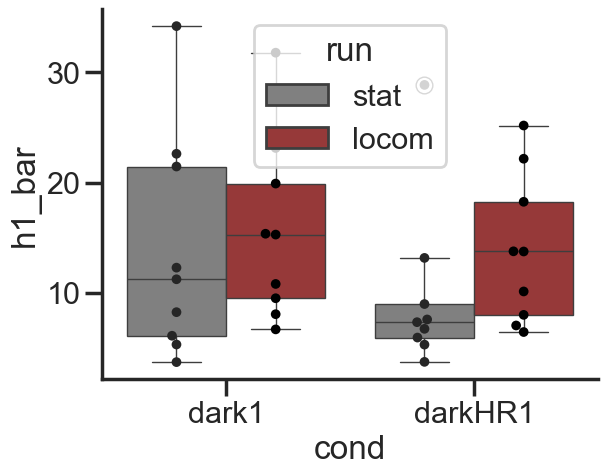

In [651]:
coi = ['dark1', 'darkHR1']
pal = ['gray', 'brown']

y = 'h1_bar'

_inp_plot = df_darkhr_betti[(df_darkhr_betti.cond.isin(coi))
                    & (df_darkhr_betti.rec_session.isin(hr_dark_sess))
#                        & (df_hr_betti.az_occ > 0.5)
                    ]
sns.boxplot(data = _inp_plot, x = 'cond', y = y, hue = 'run', 
            palette= pal)
sns.swarmplot(data = _inp_plot, x = 'cond', y = y, hue = 'run', palette = 'dark:k', size = 7,
              dodge = True, legend = False)

# plt.savefig(f'box_hr_run_betti_{coi}_{y}.pdf', transparent = True)  

In [652]:
(_inp_plot.groupby(['cond', 'run'])[y].describe())

count       mean        std       min       25%        50%  \
cond    run                                                                 
dark1   locom    9.0  15.609447   8.167739  6.679771  9.504531  15.277688   
        stat     9.0  13.900989  10.151876  3.711022  6.102040  11.225524   
darkHR1 locom    9.0  13.852567   6.764534  6.440409  7.995908  13.744541   
        stat     9.0   9.734015   7.643046  3.733549  5.938250   7.333139   

                     75%        max  
cond    run                          
dark1   locom  19.904240  31.774953  
        stat   21.450960  34.183998  
darkHR1 locom  18.251432  25.169529  
        stat    8.978398  28.851645

In [653]:
a1 = _inp_plot[(_inp_plot.run == 'stat') & (_inp_plot.cond == coi[0])][y].values
a2 = _inp_plot[(_inp_plot.run == 'locom') & (_inp_plot.cond == coi[0])][y].values
b1 = _inp_plot[(_inp_plot.run == 'stat') & (_inp_plot.cond == coi[1])][y].values
b2 = _inp_plot[(_inp_plot.run == 'locom') & (_inp_plot.cond == coi[1])][y].values

stat1, pval1 = stats.wilcoxon(a1, a2)
print(f'{coi[0]} stat vs run {stat1} {pval1}')
stat2, pval2 = stats.wilcoxon(b1, b2)
print(f'{coi[1]} stat vs run {stat2} {pval2}')

# pvals = [pval1, pval2, pval3, pval4]  
# print('Benjamini/Hochberg (non-negative)')
# print(multipletests(pvals, alpha=0.05, method='fdr_bh'))

dark1 stat vs run 9.0 0.12890625
darkHR1 stat vs run 5.0 0.0390625


In [654]:
_inp_plot.rec_id.unique()

array(['20220126_JA0153_dark1', '20220126_JA0153_darkHR1',
       '20220302_JA0162_dark1', '20220302_JA0162_darkHR1',
       '20220419_JA0164_dark1', '20220419_JA0164_darkHR1',
       '20220822_JA0178_dark1', '20220822_JA0178_darkHR1',
       '20220906_JA0178_dark1', '20220906_JA0178_darkHR1',
       '20220812_JA0181_dark1', '20220812_JA0181_darkHR1',
       '20220815_JA0181_dark1', '20220815_JA0181_darkHR1',
       '20220818_JA0181_dark1', '20220818_JA0181_darkHR1',
       '20220712_MC022_dark1', '20220712_MC022_darkHR1'], dtype=object)

#### Stats: decoding error

<Axes: xlabel='cond', ylabel='dec_err'>

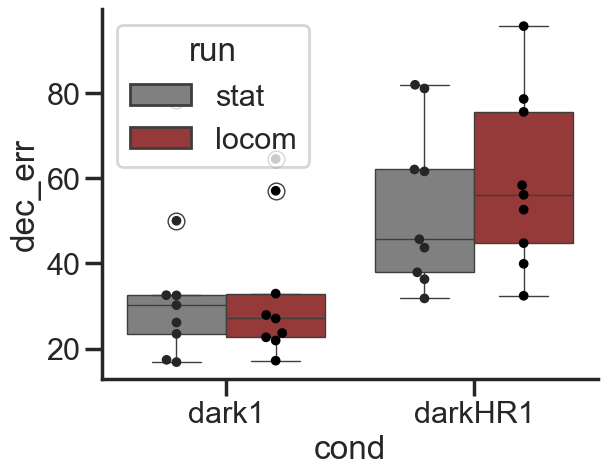

In [659]:
coi = ['dark1', 'darkHR1']
pal = ['gray', 'brown']

y = 'dec_err'

_inp_plot = df_darkhr_betti[(df_darkhr_betti.cond.isin(coi))
                    & (df_darkhr_betti.rec_session.isin(hr_dark_sess))
#                        & (df_hr_betti.az_occ > 0.5)
                    ]
sns.boxplot(data = _inp_plot, x = 'cond', y = y, hue = 'run', 
            palette= pal)
sns.swarmplot(data = _inp_plot, x = 'cond', y = y, hue = 'run', palette = 'dark:k', size = 7,
              dodge = True, legend = False)

# plt.savefig(f'box_hr_run_betti_{coi}_{y}.pdf', transparent = True)  

In [660]:
(_inp_plot.groupby(['cond', 'run'])[y].describe())

count       mean        std     min     25%     50%     75%  \
cond    run                                                                  
dark1   locom    9.0  32.760222  16.575309  17.182  22.655  27.079  32.917   
        stat     9.0  34.172444  19.343027  16.845  23.477  30.210  32.545   
darkHR1 locom    9.0  59.320889  20.384443  32.407  44.753  56.091  75.541   
        stat     9.0  53.545444  18.941844  31.787  37.908  45.670  62.029   

                  max  
cond    run            
dark1   locom  64.498  
        stat   78.447  
darkHR1 locom  95.661  
        stat   81.896

In [661]:
a1 = _inp_plot[(_inp_plot.run == 'stat') & (_inp_plot.cond == coi[0])][y].values
a2 = _inp_plot[(_inp_plot.run == 'locom') & (_inp_plot.cond == coi[0])][y].values
b1 = _inp_plot[(_inp_plot.run == 'stat') & (_inp_plot.cond == coi[1])][y].values
b2 = _inp_plot[(_inp_plot.run == 'locom') & (_inp_plot.cond == coi[1])][y].values

stat1, pval1 = stats.wilcoxon(a1, a2)
print(f'{coi[0]} stat vs run {stat1} {pval1}')
stat2, pval2 = stats.wilcoxon(b1, b2)
print(f'{coi[1]} stat vs run {stat2} {pval2}')
stat3, pval3 = stats.mannwhitneyu(a1, b1)
print(f'stat  {stat3} {pval3}')
stat4, pval4 = stats.mannwhitneyu(a2, b2)
print(f'run {stat4} {pval4}')
pvals = [pval1, pval2, pval3, pval4]  
print('Benjamini/Hochberg (non-negative)')
print(multipletests(pvals, alpha=0.05, method='fdr_bh'))

dark1 stat vs run 21.0 0.91015625
darkHR1 stat vs run 9.0 0.12890625
stat  14.0 0.021684111364991994
run 12.0 0.013418657920497472
Benjamini/Hochberg (non-negative)
(array([False, False,  True,  True]), array([0.91015625, 0.171875  , 0.04336822, 0.04336822]), 0.012741455098566168, 0.0125)


In [662]:
_inp_plot.head()

,rec_id,cond,dts,animal_name,az_occ,h1_ratio,run,h1_bar,dec_err,rec_session,stat_off_ring_ratio,run_ratio
0,20220126_JA0153_dark1,dark1,20220126,JA0153,0.944444,1.191202,stat,8.241301,78.447,JA0153_20220126,0.323752,0.478125
0,20220126_JA0153_dark1,dark1,20220126,JA0153,1.000000,6.368179,locom,15.354324,57.038,JA0153_20220126,0.323752,0.478125
0,20220126_JA0153_darkHR1,darkHR1,20220126,JA0153,0.944444,1.268506,stat,5.938250,36.301,JA0153_20220126,0.699363,0.509375
0,20220126_JA0153_darkHR1,darkHR1,20220126,JA0153,1.000000,6.443134,locom,13.744541,52.607,JA0153_20220126,0.699363,0.509375
0,20220302_JA0162_dark1,dark1,20220302,JA0162,0.972222,1.655706,stat,5.308832,50.007,JA0162_20220302,0.665306,0.642708


In [297]:
# _inp_plot.to_excel(filepath, index = True)

#### Stats: stat_off_manifold ratio

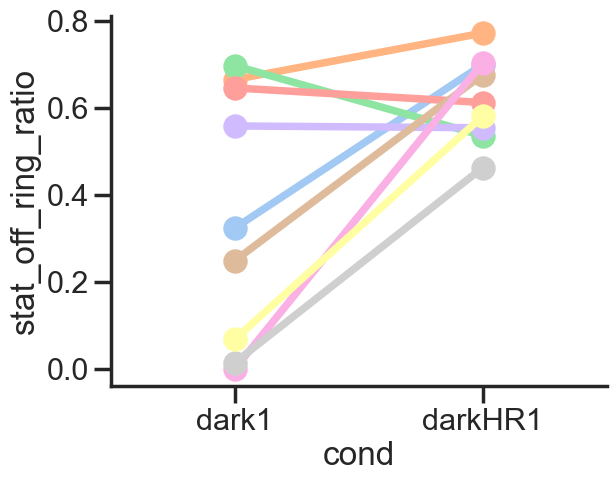

In [663]:
y = 'stat_off_ring_ratio'

_inp_plot = df_darkhr_betti[df_darkhr_betti.cond.isin(coi) 
                     & (df_darkhr_betti.run == 'stat')
                     & (df_darkhr_betti.rec_session.isin(hr_dark_sess))
                        & (df_darkhr_betti.az_occ > 0.5)
                    ]
sns.pointplot(data = _inp_plot, x = 'cond', y = y, hue = 'rec_session')

# sns.barplot(data = _inp_plot, x = 'cond', y = y, errorbar= ('ci', 68), palette=pal)
# sns.swarmplot(data = _inp_plot, x = 'cond', y = y, color = 'k', size = 10)
plt.legend([],[], frameon=False)
# plt.savefig(f'point_hr_{coi}_{y}.pdf', transparent = True) 
# filepath = save_dir / f'point_hr_{coi}_{y}.pdf'
# plt.savefig(filepath, transparent = True)

In [664]:
_inp_plot.groupby('cond')[y].describe()

,count,mean,std,min,25%,50%,75%,max
cond,,,,,,,,
dark1,9.0,0.358027,0.290682,0.000000,0.068203,0.323752,0.645996,0.697192
darkHR1,9.0,0.622034,0.098203,0.462776,0.554474,0.612478,0.699363,0.771917


In [667]:
a1 = _inp_plot[ (_inp_plot.cond == coi[0])][y].values
b1 = _inp_plot[ (_inp_plot.cond == coi[1])][y].values

stats.mannwhitneyu(a1, b1)

MannwhitneyuResult(statistic=19.0, pvalue=0.06368977513662868)

In [320]:
# filepath = save_dir / f'out.xlsx'
# _inp_plot.to_excel(filepath, index = True)

## Pairwise tau correlations

In [344]:
hr_sess = ['JA0153_20220126', 'JA0162_20220302', 'JA0164_20220419',
       'JA0178_20220819', 'JA0178_20220822', 'JA0181_20220812',
       'JA0181_20220815', 'JA0181_20220818', 'MC022_20220712']


KeyboardInterrupt



In [341]:
len(subset.keys())

28

In [29]:
ls_df = []
ls_hdc = []
speed_thr = 5
for k in d_hr_data.keys():
    if 'lightHR1' not in k:
        continue
    ephys_df = d_hr_data[k]['ephys']
    beh_df = d_hr_data[k]['beh']
    
    units_in = ephys_df.cids.unique()
    sess_hdc = ephys_df[ephys_df.hdc_flag == True].cids.unique()
    n_hdc = sess_hdc.size
    dts, animal_name, cond = k.split('_')[-3:]
    rec_sess = animal_name + '_' + animal_name
    if n_hdc < 8:
        # print(f'not enough HDC {k} {n_hdc}')
        continue
    print(k, n_hdc)
    ls_hdc.append(n_hdc)
    
    yaw = beh_df['yaw'].values
    if yaw.min() < - 10:
        yaw = yaw + 180
    lin_vel = beh_df['lin_vel'].values
    try:
        stat_idx, run_idx = get_stat_run_epochs(lin_vel, window_size=25, speed_thr = speed_thr)
    except:
        continue
    
    if stat_idx.size < 500 or run_idx.size < 500:
        continue
        
    
    for each in itertools.combinations(sess_hdc, 2):
        if each[0] in sess_hdc and each[1] in sess_hdc:
            hdc_pair = '1_1'
        elif each[0] in sess_hdc or each[1] in sess_hdc:
            hdc_pair = '1_0'
        else:
            hdc_pair = '0_0'
        # all data points
        corr_1 = ephys_df[ephys_df.cids == each[0]].hz.values[:]
        corr_2 = ephys_df[ephys_df.cids == each[1]].hz.values[:]
        if corr_1.size < 100 or corr_2.size < 100:
            continue
        tau1, p_value1 = kendalltau(corr_1, corr_2)
        ls_df.append(pd.DataFrame({ 'pair': str(each), 'tau': tau1,'abstau': abs(tau1), 'pval': p_value1, 'rec_id':k, 
                                   'dts':dts, 'rec_sess':rec_sess, "animal_name":animal_name, 'n_hdc':n_hdc,
               'cond': cond, 'rec_id': k, 'hdc_pair': hdc_pair, 'run': 'all', 'speed_thr':speed_thr, 
                       }, index = [0]))
        
        # stationary data points
        corr_1 = ephys_df[ephys_df.cids == each[0]].hz.values
        corr_2 = ephys_df[ephys_df.cids == each[1]].hz.values
        if corr_1.size < 100 or corr_2.size < 100:
            continue
        tau1, p_value1 = kendalltau(corr_1[stat_idx], corr_2[stat_idx])
        ls_df.append(pd.DataFrame({ 'pair': str(each), 'tau': tau1,'abstau': abs(tau1), 'pval': p_value1, 'rec_id':k, 
                                   'dts':dts, 'rec_sess':rec_sess, "animal_name":animal_name, 'n_hdc':n_hdc,
               'cond': cond, 'rec_id': k, 'hdc_pair': hdc_pair, 'run': 'stat', 'speed_thr':speed_thr, 
                       }, index = [0]))
        
        # runnning data points
        corr_1 = ephys_df[ephys_df.cids == each[0]].hz.values
        corr_2 = ephys_df[ephys_df.cids == each[1]].hz.values
        if corr_1.size < 100 or corr_2.size < 100:
            continue
        tau1, p_value1 = kendalltau(corr_1[run_idx], corr_2[run_idx])
        ls_df.append(pd.DataFrame({ 'pair': str(each), 'tau': tau1,'abstau': abs(tau1), 'pval': p_value1, 'rec_id':k, 
                                   'dts':dts, 'rec_sess':rec_sess, "animal_name":animal_name, 'n_hdc':n_hdc,
               'cond': cond, 'rec_id': k, 'hdc_pair': hdc_pair, 'run': 'run', 'speed_thr':speed_thr, 
                       }, index = [0]))
          
df_hr_taucorr = pd.concat(ls_df)
df_hr_taucorr.head()

20220126_JA0153_lightHR1 19
20220302_JA0162_lightHR1 9
20220419_JA0164_lightHR1 10
20220819_JA0178_lightHR1 30
20220822_JA0178_lightHR1 26
20220812_JA0181_lightHR1 12
20220815_JA0181_lightHR1 16
20220818_JA0181_lightHR1 14
20220712_MC022_lightHR1 41


In [30]:
np.mean(ls_hdc), np.min(ls_hdc), np.max(ls_hdc), 

(19.666666666666668, 9, 41)

In [328]:
(d_hr_data.keys())

dict_keys(['20211207_JA0144_dark1', '20211207_JA0144_darkHR1', '20211207_JA0144_light1', '20211207_JA0144_lightHR1', '20220126_JA0153_dark1', '20220126_JA0153_darkHR1', '20220126_JA0153_light1', '20220126_JA0153_lightHR1', '20220302_JA0162_dark1', '20220302_JA0162_darkHR1', '20220302_JA0162_light1', '20220302_JA0162_lightHR1', '20220419_JA0164_dark1', '20220419_JA0164_darkHR1', '20220419_JA0164_light1', '20220419_JA0164_lightHR1', '20220819_JA0178_dark1', '20220819_JA0178_darkHR1', '20220819_JA0178_light1', '20220819_JA0178_lightHR1', '20220822_JA0178_dark1', '20220822_JA0178_darkHR1', '20220822_JA0178_light1', '20220822_JA0178_lightHR1', '20220824_JA0178_dark1', '20220824_JA0178_darkHR1', '20220824_JA0178_light1', '20220824_JA0178_lightHR1', '20220906_JA0178_dark1', '20220906_JA0178_darkHR1', '20220906_JA0178_light1', '20220906_JA0178_lightHR1', '20220812_JA0181_dark1', '20220812_JA0181_darkHR1', '20220812_JA0181_light1', '20220812_JA0181_lightHR1', '20220815_JA0181_dark1', '20220815_

Index(['JA0153_20220126', 'JA0162_20220302', 'JA0164_20220419',
       'JA0178_20220819', 'JA0178_20220822', 'JA0181_20220812',
       'JA0181_20220815', 'JA0181_20220818', 'MC022_20220712'],
      dtype='object', name='rec_session')

In [156]:
# ls, ls2, ls3 = [], [], []
# ls_df = []

# cond1 = 'L1'
# cond2 = 'TS6-HF'
# coi = ['light1', 'lightHR1']
# data = df_hr_master_1
# _inp = data[ (data.hdc_flag == True)
# #             & (data.rec_session.isin(good_rec_shanks))
#             & (data.times == 0)
#             & (data.condition.isin(coi))
# #             & (df_hdatar_master.n_hdc > 3)
# #             & ((df_tun_proc.cond == cond1) | (df_tun_proc.cond == cond2))
#             ].groupby([ 'rec_id']).cids.apply(list).reset_index()

# for rec in _inp.rec_id.unique()[:]:
#     print(rec)
#     tmp_cids = _inp[_inp.rec_id == rec]
    
#     dts, animal_name, cond = rec.split('_')[-3:]
#     units_in = tmp_cids.cids.values[0]
#     if len(units_in) < 5:
#         print(f'not enough HDC {rec} {len(units_in)}')
#         continue
#     tmp_ephys = data[(data.rec_id == rec)]
# #     sh = d_good_shanks[implant]
# #     tmp_hist = df_hist_master[(df_hist_master.mouse_id == mouse_id) 
# #            & (df_hist_master.dts == dts)
# #            & (df_hist_master.group != 'noise')
# #           & (df_hist_master.shank.isin(sh))]

# #     units_in = tmp_hist.id.unique()
# #     sess_hdc = tmp_hist[tmp_hist.hdc == 1].id.values
# #     print(tmp.rec_id.values[0])
#     sess_hdc = units_in

#     start, end = 0, 1800
#     yaw = tmp_ephys[tmp_ephys.cids == units_in[0]]['yaw'].values
#     speed = tmp_ephys[tmp_ephys.cids == units_in[0]]['vel'].values
#     try:
#         stat_idx, run_idx = get_stat_run_epochs(speed, window_size=5, speed_thr = 4)
#     except:
#         continue
    
#     for each in itertools.combinations(units_in, 2):
#         if each[0] in sess_hdc and each[1] in sess_hdc:
#             hdc_pair = '1_1'
#         elif each[0] in sess_hdc or each[1] in sess_hdc:
#             hdc_pair = '1_0'
#         else:
#             hdc_pair = '0_0'
#         # all data points
#         corr_1 = tmp_ephys[tmp_ephys.cids == each[0]].hz.values[:]
#         corr_2 = tmp_ephys[tmp_ephys.cids == each[1]].hz.values[:]
#         if corr_1.size < 100 or corr_2.size < 100:
#             continue
#         tau1, p_value1 = kendalltau(corr_1, corr_2)
#         ls_df.append(pd.DataFrame({ 'pair': str(each), 'tau': tau1, 'pval': p_value1, 'rec_id':rec_id, 'dts':dts,
#                'cond': cond, 'rec_id': rec, 'hdc_pair': hdc_pair, 'run': 'all',"animal_name":animal_name,
#                                   }, index = [0]))
        
#         # stationary data points
#         corr_1 = tmp_ephys[tmp_ephys.cids == each[0]].hz.values
#         corr_2 = tmp_ephys[tmp_ephys.cids == each[1]].hz.values
#         if corr_1.size < 100 or corr_2.size < 100:
#             continue
#         tau1, p_value1 = kendalltau(corr_1[stat_idx], corr_2[stat_idx])
#         ls_df.append(pd.DataFrame({ 'pair': str(each), 'tau': tau1, 'pval': p_value1, 'rec_id':rec_id, 'dts':dts,
#                'cond': cond, 'rec_id': rec, 'hdc_pair': hdc_pair, 'run': 'stat', "animal_name":animal_name,
#                                   }, index = [0]))
        
#         # runnning data points
#         corr_1 = tmp_ephys[tmp_ephys.cids == each[0]].hz.values
#         corr_2 = tmp_ephys[tmp_ephys.cids == each[1]].hz.values
#         if corr_1.size < 100 or corr_2.size < 100:
#             continue
#         tau1, p_value1 = kendalltau(corr_1[run_idx], corr_2[run_idx])
#         ls_df.append(pd.DataFrame({ 'pair': str(each), 'tau': tau1, 'pval': p_value1, 'rec_id':rec_id, 'dts':dts,
#                'cond': cond, 'rec_id': rec, 'hdc_pair': hdc_pair, 'run': 'locom', "animal_name":animal_name,
#                                   }, index = [0]))
        
    
# df_hr_taucorr = pd.concat(ls_df)
# df_hr_taucorr.head()

20211212_JA0144_light1
20211212_JA0144_lightHR1
20220209_JA0153_light1
20220209_JA0153_lightHR1
20220302_JA0162_light1
20220302_JA0162_lightHR1
20220419_JA0164_light1
20220419_JA0164_lightHR1
20220426_JA0164_light1
20220426_JA0164_lightHR1
not enough HDC 20220426_JA0164_lightHR1 2


,pair,tau,pval,rec_id,dts,cond,hdc_pair,run,animal_name
0,"(51.0, 62.0)",-0.078906,7.043743e-42,20211212_JA0144_light1,20211212,light1,1_1,all,JA0144
0,"(51.0, 62.0)",-0.176801,1.809167e-27,20211212_JA0144_light1,20211212,light1,1_1,stat,JA0144
0,"(51.0, 62.0)",-0.064446,4.681502e-25,20211212_JA0144_light1,20211212,light1,1_1,locom,JA0144
0,"(51.0, 66.0)",0.181074,7.001641e-238,20211212_JA0144_light1,20211212,light1,1_1,all,JA0144
0,"(51.0, 66.0)",0.090186,8.995820e-09,20211212_JA0144_light1,20211212,light1,1_1,stat,JA0144


In [364]:
df_hr_taucorr[ (df_hr_taucorr.cond.isin(coi)) & (df_hr_taucorr.run == 'all') 
    & (df_hr_taucorr.run == 'all') & (df_hr_taucorr.rec_id.isin(good_corr_sess))].groupby(['rec_sess', 'cond', ]).count()

,,pair,tau,pval,rec_id,dts,hdc_pair,run,animal_name,n_hdc,abstau
rec_sess,cond,,,,,,,,,,


#### Plots and Stats

In [347]:
coi = ['light1', 'dark1', 'lightHR1']
n_pairs = df_hr_taucorr[(df_hr_taucorr.tau > -1) 
                        & (df_hr_taucorr.run == 'all')
                        # & (df_hr_taucorr.rec_sess.isin(hr_sess))
                        & (df_hr_taucorr.cond.isin(coi))
                        & (df_hr_taucorr.hdc_pair == '1_1')].groupby(['cond', 'rec_sess', 'rec_id'])['pair'].count().reset_index()
good_corr_sess = n_pairs[n_pairs.pair > 20].rec_id.unique()

In [348]:
df_hr_taucorr.head()

,pair,tau,pval,rec_id,dts,cond,hdc_pair,run,animal_name,n_hdc,rec_sess,abstau
0,"(25.0, 51.0)",-0.200876,8.440973e-277,20211207_JA0144_dark1,20211207,dark1,1_1,all,JA0144,8,JA0144_20211207,0.200876
0,"(25.0, 51.0)",-0.239519,1.527409e-141,20211207_JA0144_dark1,20211207,dark1,1_1,stat,JA0144,8,JA0144_20211207,0.239519
0,"(25.0, 51.0)",-0.183297,6.661943e-149,20211207_JA0144_dark1,20211207,dark1,1_1,run,JA0144,8,JA0144_20211207,0.183297
0,"(25.0, 62.0)",-0.014558,6.474542e-03,20211207_JA0144_dark1,20211207,dark1,1_1,all,JA0144,8,JA0144_20211207,0.014558
0,"(25.0, 62.0)",-0.042756,1.093612e-06,20211207_JA0144_dark1,20211207,dark1,1_1,stat,JA0144,8,JA0144_20211207,0.042756


C:\Users\01\AppData\Local\Temp\ipykernel_16696\3544408275.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data = _inp_plot, x = 'cond', y = y, order = coi,


<Axes: xlabel='cond', ylabel='abstau'>

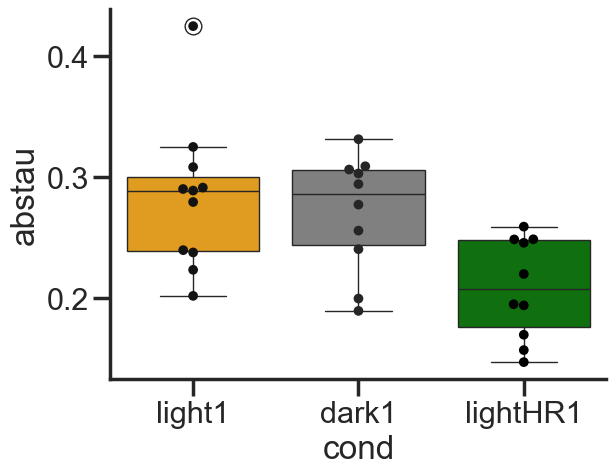

In [365]:
# f, ax = plt.subplots(figsize = (4, 4))

y = 'abstau'
coi = ['light1', 'dark1', 'lightHR1']
pal = ['orange', 'gray' , 'green']
# coi = ['dark1', 'darkHR1'];  pal = ['gray', 'brown']

_inp_plot = df_hr_taucorr[(df_hr_taucorr.tau > -1) 
                        & (df_hr_taucorr.run == 'all')
                        & (df_hr_taucorr.rec_id.isin(good_corr_sess))
                        & (df_hr_taucorr.cond.isin(coi))
                        & (df_hr_taucorr.hdc_pair == '1_1')].groupby(['cond', 'rec_sess', 'rec_id']).mean(numeric_only=True).reset_index()

# _inp_plot2 = _inp_plot.pivot(index = ['rec_id', 'pair'], columns = 'run', values = 'tau').dropna().reset_index()
sns.swarmplot(data = _inp_plot, x = 'cond', y = y,  dodge = False, hue = 'cond', order = coi,
             size = 7, palette='dark:k', legend = None)

sns.boxplot(data = _inp_plot, x = 'cond', y = y, order = coi,
        palette=pal)

# sns.boxplot(data = _inp_plot, x = 'cond', y = y,
#             hue = 'run', hue_order = ['stat', 'run'], palette=pal, )
# sns.swarmplot(data = _inp_plot, x = 'cond', y = y,  dodge = True, 
#               hue = 'run', hue_order = ['stat', 'run'], size = 7, color = 'k', legend = None)
# plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)

# plt.savefig(f'box_hr_{coi}_{y}.pdf', transparent = True)  

In [367]:
(_inp_plot.groupby(['cond' ])[y].describe())

,count,mean,std,min,25%,50%,75%,max
cond,,,,,,,,
dark1,10.0,0.270678,0.048041,0.189615,0.244353,0.285767,0.305449,0.331256
light1,11.0,0.282788,0.060516,0.202002,0.238780,0.288881,0.299811,0.424583
lightHR1,10.0,0.208600,0.041566,0.147336,0.175973,0.207575,0.247880,0.259134


In [355]:
a1 = _inp_plot[(_inp_plot.cond == coi[0])][y].values
b1 = _inp_plot[(_inp_plot.cond == coi[1])][y].values
c1 = _inp_plot[(_inp_plot.cond == coi[2])][y].values

stat, pval = stats.mannwhitneyu(a1, b1)
print(f'{coi[0]} vs {coi[1]} {stat} {pval}')
stat, pval = stats.mannwhitneyu(a1, c1)
print(f'{coi[0]} vs {coi[2]} {stat} {pval}')
stat, pval = stats.mannwhitneyu(c1, b1)
print(f'{coi[2]} vs {coi[1]} {stat} {pval}')


light1 vs dark1 55.0 1.0
light1 vs lightHR1 93.0 0.00827421565071521
lightHR1 vs dark1 17.0 0.014019277113959953


In [370]:
# filepath = save_dir / f'out.xlsx'
# _inp_plot.to_excel(filepath, index = True)

In [86]:
df_hr_taucorr.head()

,pair,tau,pval,rec_id,dts,cond,hdc_pair,run,animal_name,rec_sess,abstau
0,"(51.0, 62.0)",-0.078906,7.043743e-42,20211212_JA0144_light1,20211212,light1,1_1,all,JA0144,JA0144_20211212,0.078906
0,"(51.0, 62.0)",-0.176801,1.809167e-27,20211212_JA0144_light1,20211212,light1,1_1,stat,JA0144,JA0144_20211212,0.176801
0,"(51.0, 62.0)",-0.064446,4.681502e-25,20211212_JA0144_light1,20211212,light1,1_1,locom,JA0144,JA0144_20211212,0.064446
0,"(51.0, 66.0)",0.181074,7.001641e-238,20211212_JA0144_light1,20211212,light1,1_1,all,JA0144,JA0144_20211212,0.181074
0,"(51.0, 66.0)",0.090186,8.995820e-09,20211212_JA0144_light1,20211212,light1,1_1,stat,JA0144,JA0144_20211212,0.090186


PearsonRResult(statistic=0.8695347709760666, pvalue=5.92637729968651e-12)


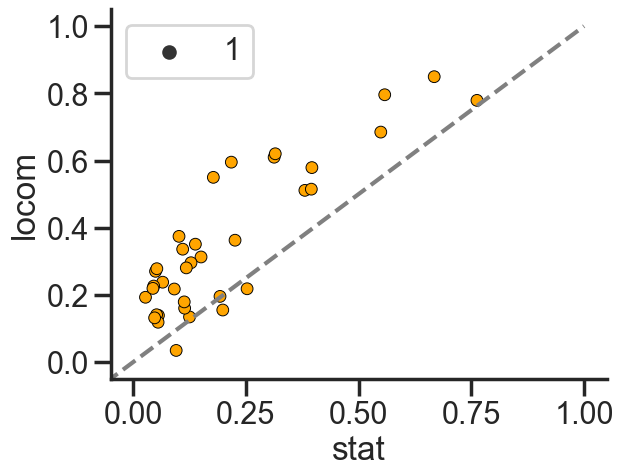

In [95]:
coi = ['stat', 'locom']
y = 'abstau'
unity_line = [-1, 1]
_inp_plot = df_hr_taucorr[(df_hr_taucorr.hdc_pair == '1_1')
                        & (df_hr_taucorr.rec_id == '20220302_JA0162_lightHR1')
                        & (df_hr_taucorr.run != 'all')
#                         & (df_tau_corr.cond.isin(coi))
                       ].pivot(index = ['dts',
                     'pair'], columns = 'run', values = y).reset_index().dropna()

sns.scatterplot(data = _inp_plot, x = coi[0], y = coi[1], legend = True, c = 'orange', edgecolor = 'k', 
                alpha = 1, size = 1
            )
plt.xlim(-0.05, 1.05)
plt.ylim(-0.05, 1.05)
plt.plot(unity_line, unity_line, ls = '--', c = 'gray')
print(stats.pearsonr(_inp_plot[coi[0]], _inp_plot[coi[1]]))
# plt.savefig(f'scatter_tau_{coi[0]}_{coi[1]}.png', dpi = 300, transparent=True)
# plt.savefig(f'scatter_hrtau_0302-JA162_L1_{coi[0]}_{coi[1]}.pdf', dpi = 300, transparent=True)

In [65]:
df_hr_taucorr.hdc_pair.unique()

array(['1_1'], dtype=object)

#### Delta tau R vs HR

1_1 ['light1', 'dark1'] JA0144_20211207
1_1 ['light1', 'dark1'] JA0153_20220126
1_1 ['light1', 'dark1'] JA0164_20220419
1_1 ['light1', 'dark1'] JA0178_20220819
1_1 ['light1', 'dark1'] JA0178_20220822
1_1 ['light1', 'dark1'] JA0178_20220824
1_1 ['light1', 'dark1'] JA0178_20220906
1_1 ['light1', 'dark1'] JA0181_20220812
1_1 ['light1', 'dark1'] JA0181_20220815


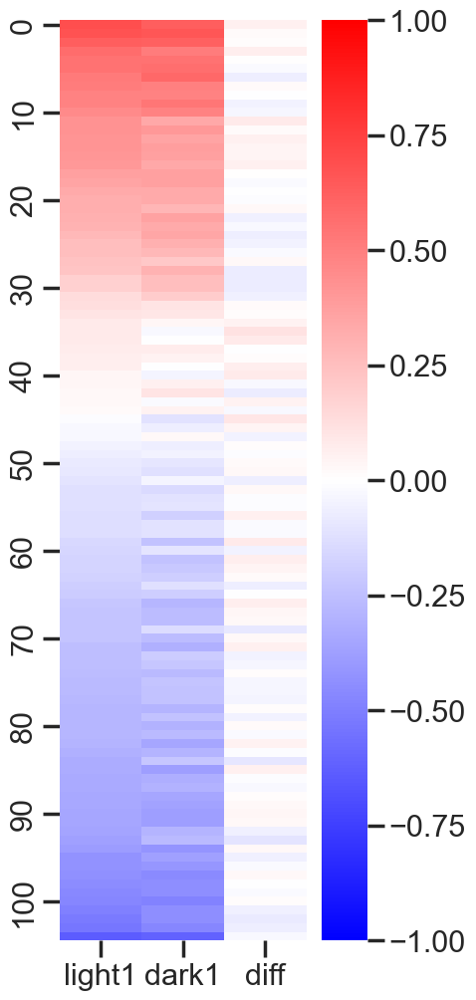

1_1 ['light1', 'dark1'] JA0181_20220818
1_1 ['light1', 'dark1'] MC022_20220712
1_1 ['light1', 'lightHR1'] JA0144_20211207
1_1 ['light1', 'lightHR1'] JA0153_20220126
1_1 ['light1', 'lightHR1'] JA0162_20220302
1_1 ['light1', 'lightHR1'] JA0164_20220419
1_1 ['light1', 'lightHR1'] JA0178_20220819
1_1 ['light1', 'lightHR1'] JA0178_20220822
1_1 ['light1', 'lightHR1'] JA0178_20220824
1_1 ['light1', 'lightHR1'] JA0181_20220812
1_1 ['light1', 'lightHR1'] JA0181_20220815


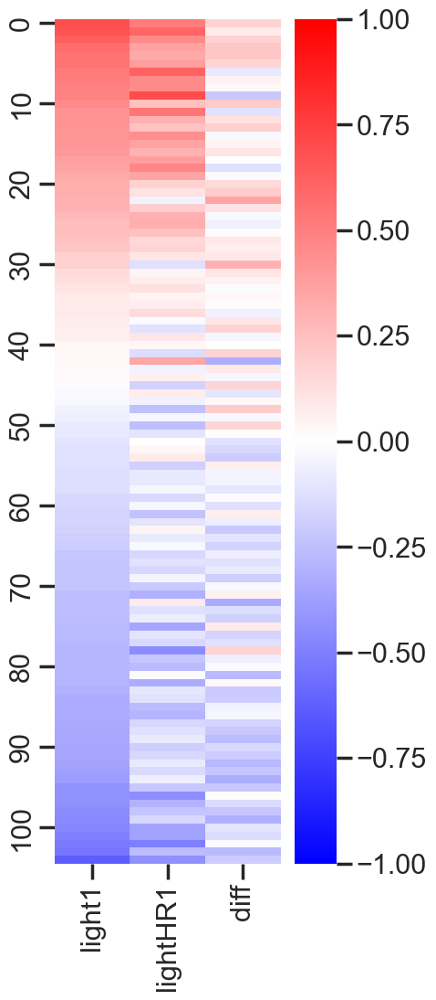

1_1 ['light1', 'lightHR1'] JA0181_20220818
1_1 ['light1', 'lightHR1'] MC022_20220712


In [373]:
ls = []
cond_pairs = [['light1', 'dark1'], ['light1', 'lightHR1'], 
             ]
pair_hdc = ['1_1']
ls_hm = []

for pt in pair_hdc:
    for cp in cond_pairs:
        coi = cp
        _inp_plot = df_hr_taucorr[(df_hr_taucorr.cond.isin(coi)) 
                                 & (df_hr_taucorr.hdc_pair == pt) 
                                & (df_hr_taucorr.run == 'all')].pivot(index = ['rec_sess',
                             'pair'], columns = 'cond', values = 'tau').reset_index().dropna()
        
        for recs in _inp_plot.rec_sess.unique()[:]:
            print(pt, cp, recs)

            if 'JA0181_20220815' not in recs:
                continue
            tmp = _inp_plot[_inp_plot.rec_sess == recs]
            tau_arr = tmp[coi].values

            sign_corr = (np.sign(tau_arr)[:, 0] * np.sign(tau_arr)[:, 1]) < 0

        #     idx_sort = np.argsort(tau_arr[:, 0])
            diff_tau = tau_arr[:, 0] - tau_arr[:, 1]
            pear_r, p_val = stats.pearsonr(tau_arr[:, 0], tau_arr[:, 1])
            strong_pairs = abs(diff_tau) > 0.1
            sign_sw = sign_corr & strong_pairs
            abs_tau = abs(diff_tau)
            # ls.append(pd.DataFrame({'rec_sess': recs, 'tau1': tau_arr[:, 0], 'tau2':tau_arr[:, 1], 'pair_hdc': pt,
            #                         'pear_r': round(pear_r, 3), 'pear_pval': round(p_val, 3), 'n_pairs': tau_arr[:, 0].size, 
            #       'diff_tau': diff_tau, 'abs_tau':abs_tau, 'cond': coi[0] + '_' + coi[1], 'sign_sw': sign_sw })) 

            if tau_arr.shape[0] > 100:
                f, ax = plt.subplots(figsize = (4, 12))
            else:
                f, ax = plt.subplots(figsize = (4, 6))

            out = np.vstack((tau_arr.T, diff_tau))
            out_df = pd.DataFrame(out.T, columns = [coi[0], coi[1], 'diff'])
            out_df = out_df.sort_values(by = coi[0], ascending=False).reset_index(drop = True)
            ls_hm.append(out_df)
            sns.heatmap(out_df, cmap = 'bwr', vmin = -1, vmax = 1, yticklabels = 10)

            plt.show()
    #         plt.savefig(f'heatmap_nhdc_pearson_{cp}.pdf', transparent=True)
        #     break
        # break
    
# df_hr_delta_tau = pd.concat(ls)
# df_hr_delta_tau.head()

In [376]:
# ls_hm[1].to_excel(filepath, index = True)

In [401]:
hr_sess

['JA0153_20220126',
 'JA0162_20220302',
 'JA0164_20220419',
 'JA0178_20220819',
 'JA0178_20220822',
 'JA0181_20220812',
 'JA0181_20220815',
 'JA0181_20220818',
 'MC022_20220712']

In [402]:
df_hr_taucorr.head()

,pair,tau,pval,rec_id,dts,cond,hdc_pair,run,animal_name,n_hdc,rec_sess,abstau
0,"(25.0, 51.0)",-0.200876,8.440973e-277,20211207_JA0144_dark1,20211207,dark1,1_1,all,JA0144,8,JA0144_20211207,0.200876
0,"(25.0, 51.0)",-0.239519,1.527409e-141,20211207_JA0144_dark1,20211207,dark1,1_1,stat,JA0144,8,JA0144_20211207,0.239519
0,"(25.0, 51.0)",-0.183297,6.661943e-149,20211207_JA0144_dark1,20211207,dark1,1_1,run,JA0144,8,JA0144_20211207,0.183297
0,"(25.0, 62.0)",-0.014558,6.474542e-03,20211207_JA0144_dark1,20211207,dark1,1_1,all,JA0144,8,JA0144_20211207,0.014558
0,"(25.0, 62.0)",-0.042756,1.093612e-06,20211207_JA0144_dark1,20211207,dark1,1_1,stat,JA0144,8,JA0144_20211207,0.042756


#### Stats

C:\Users\01\AppData\Local\Temp\ipykernel_16696\159512921.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data = _inp_plot, x = 'cond', y = y, order = coi,


<Axes: xlabel='cond', ylabel='abs_tau'>

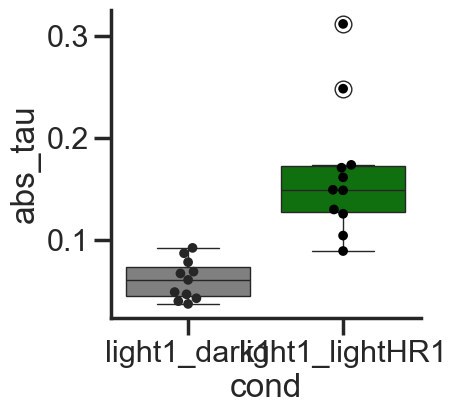

In [377]:
f, ax = plt.subplots(figsize = (4, 4))

y = 'abs_tau'
coi = ['light1_dark1', 'light1_lightHR1']
pal = ['gray', 'green']

_inp_plot = df_hr_delta_tau[(df_hr_delta_tau.cond.isin(coi))].groupby(['cond', 'rec_sess']).mean(numeric_only = True).reset_index()
# _inp_plot2 = _inp_plot.pivot(index = ['rec_id', 'pair'], columns = 'run', values = 'tau').dropna().reset_index()
sns.swarmplot(data = _inp_plot, x = 'cond', y = y,  dodge = False, hue = 'cond', order = coi,
             size = 7, palette='dark:k', legend = None)

sns.boxplot(data = _inp_plot, x = 'cond', y = y, order = coi,
        palette=pal)

# plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)
# plt.savefig(f'box_hr_{coi}_delta_{y}.pdf', transparent = True)  

In [378]:
(_inp_plot.groupby(['cond' ])[y].describe())

,count,mean,std,min,25%,50%,75%,max
cond,,,,,,,,
light1_dark1,11.0,0.061034,0.019292,0.037439,0.044901,0.060984,0.073677,0.092306
light1_lightHR1,11.0,0.164773,0.064212,0.089228,0.127799,0.149202,0.172177,0.311572


In [379]:
a1 = _inp_plot[(_inp_plot.cond == coi[0])][y].values
b1 = _inp_plot[(_inp_plot.cond == coi[1])][y].values

stat, pval = stats.mannwhitneyu(a1, b1)
print(f'{coi[0]} vs {coi[1]} {stat} {pval}')


light1_dark1 vs light1_lightHR1 1.0 0.00010695988268558165


In [380]:
_inp_plot.head()

,cond,rec_sess,tau1,tau2,pear_r,pear_pval,n_pairs,diff_tau,abs_tau,sign_sw
0,light1_dark1,JA0144_20211207,0.042753,0.054019,0.934,0.0,21.0,-0.011266,0.092306,0.047619
1,light1_dark1,JA0153_20220126,0.068059,0.076141,0.963,0.0,45.0,-0.008082,0.069046,0.044444
2,light1_dark1,JA0164_20220419,0.024916,0.016387,0.990,0.0,21.0,0.008529,0.046841,0.000000
3,light1_dark1,JA0178_20220819,0.076526,0.057627,0.978,0.0,406.0,0.018899,0.067284,0.022167
4,light1_dark1,JA0178_20220822,0.092002,0.115978,0.979,0.0,253.0,-0.023975,0.060984,0.027668


In [382]:
# _inp_plot.to_excel(filepath, index = True)

#### Delta tau run

20211207_JA0144_dark1


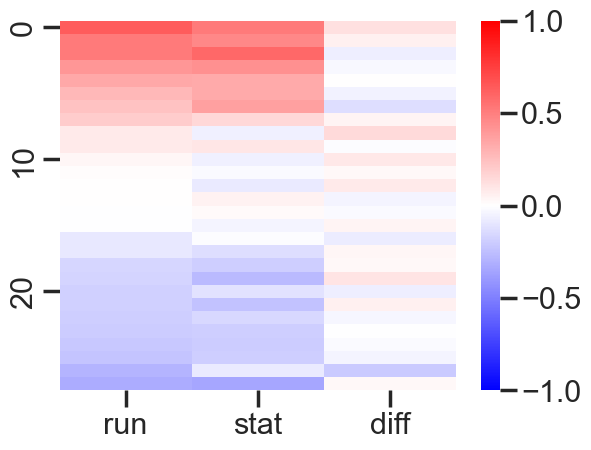

20211207_JA0144_darkHR1


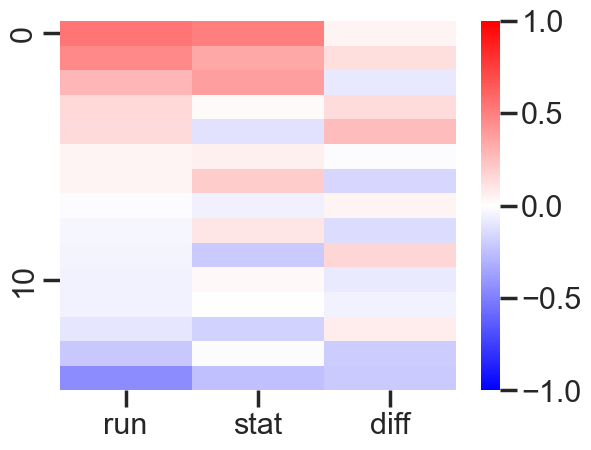

20211207_JA0144_light1


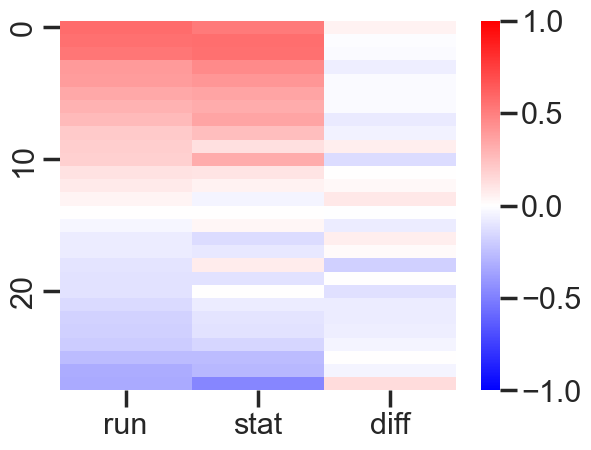

20211207_JA0144_lightHR1


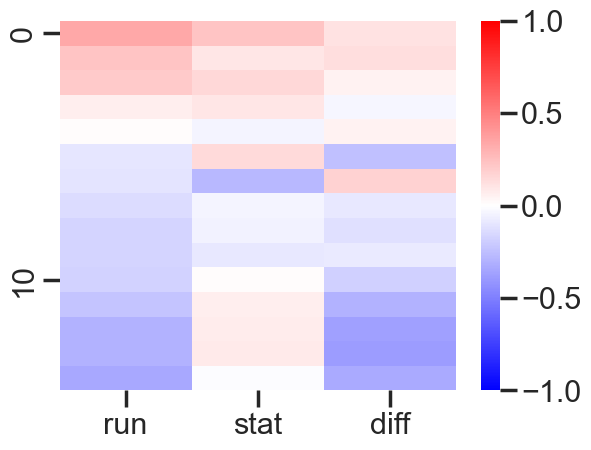

20220126_JA0153_dark1


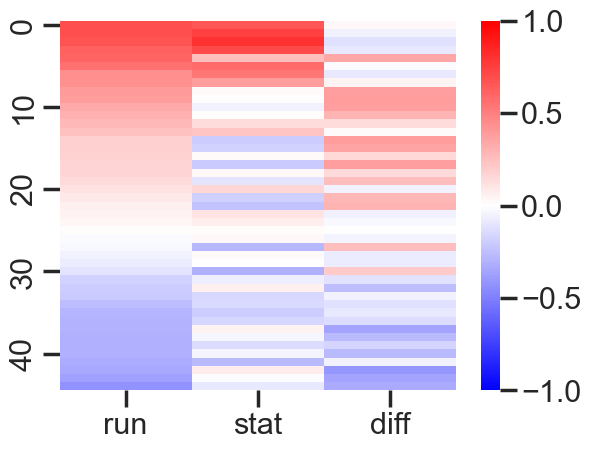

20220126_JA0153_darkHR1


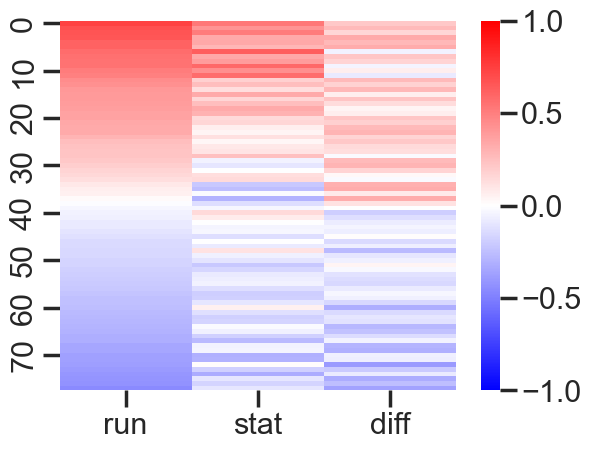

20220126_JA0153_light1


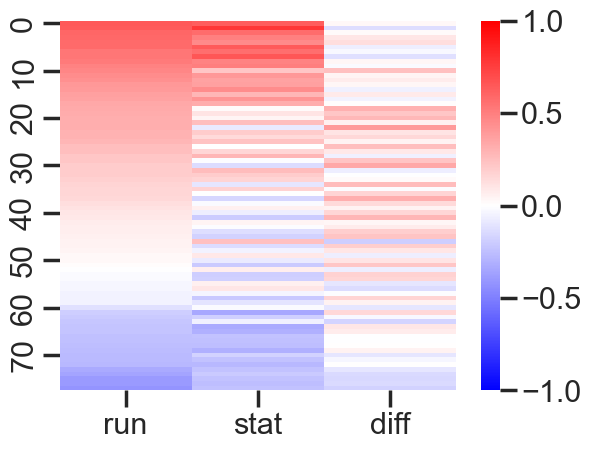

20220126_JA0153_lightHR1


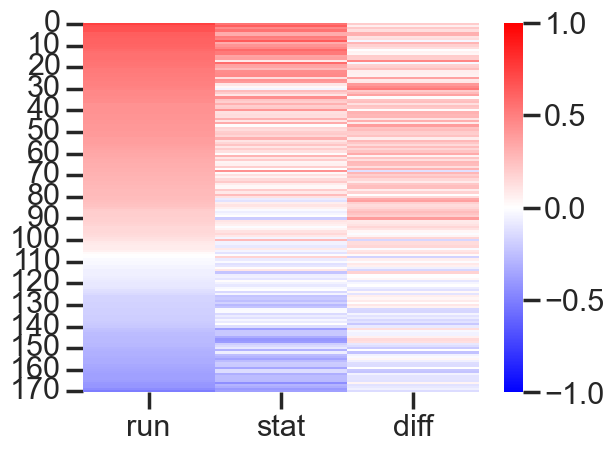

20220302_JA0162_light1


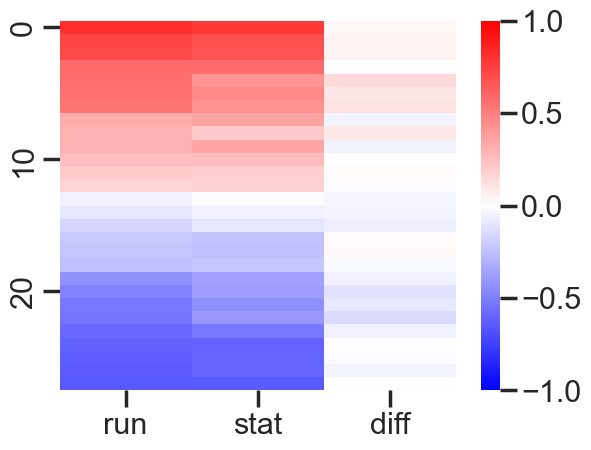

20220302_JA0162_lightHR1


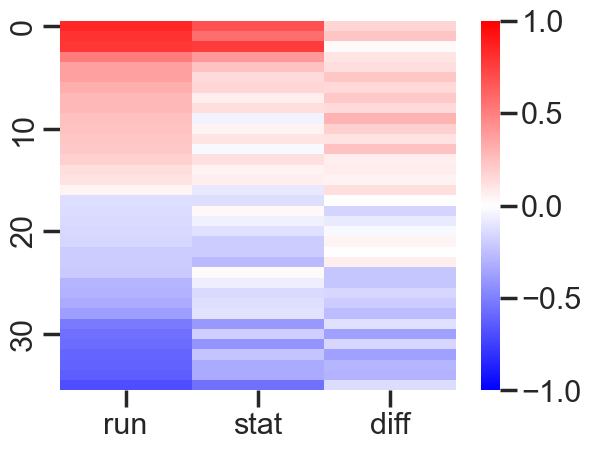

20220419_JA0164_dark1


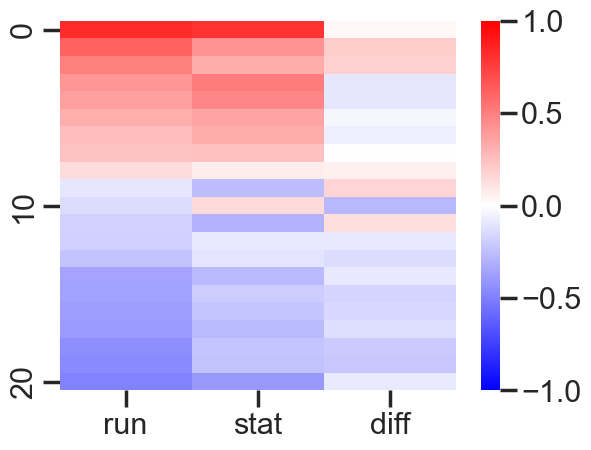

20220419_JA0164_darkHR1


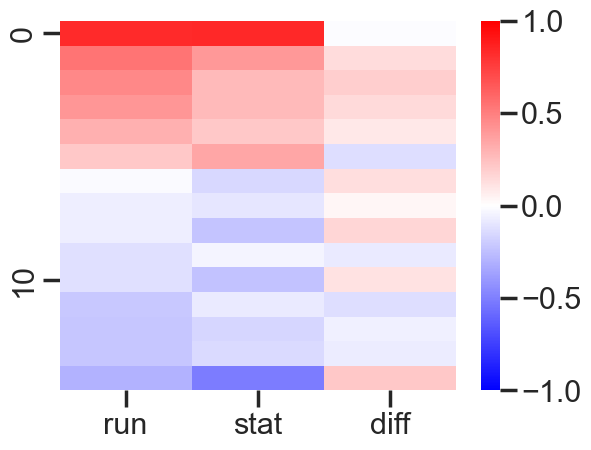

20220419_JA0164_light1


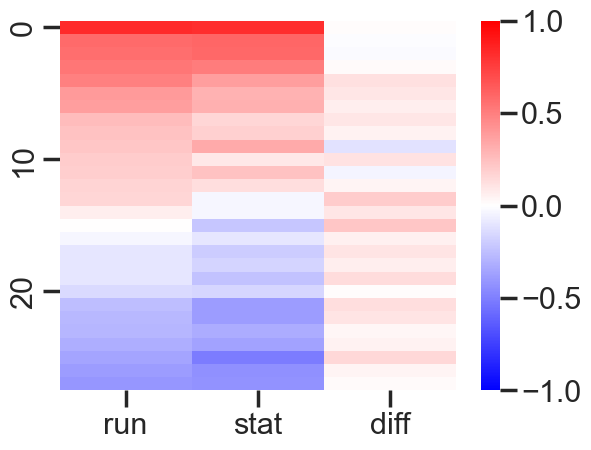

20220419_JA0164_lightHR1


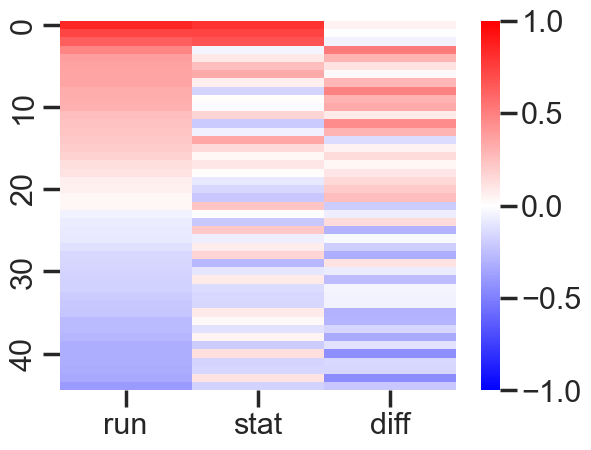

20220819_JA0178_dark1


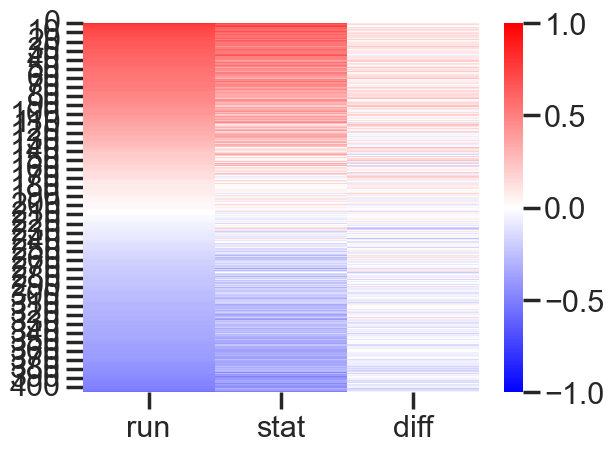

20220819_JA0178_light1


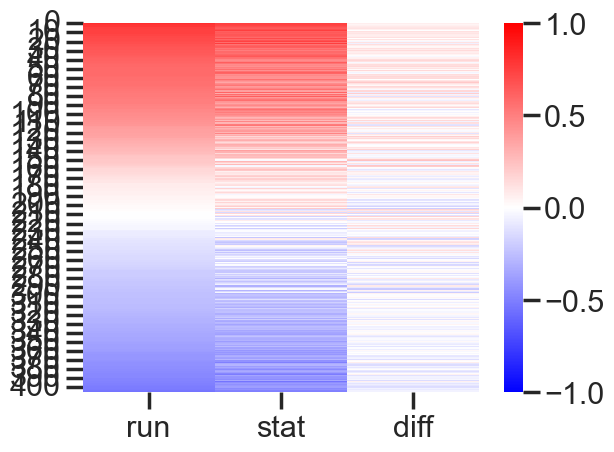

20220819_JA0178_lightHR1


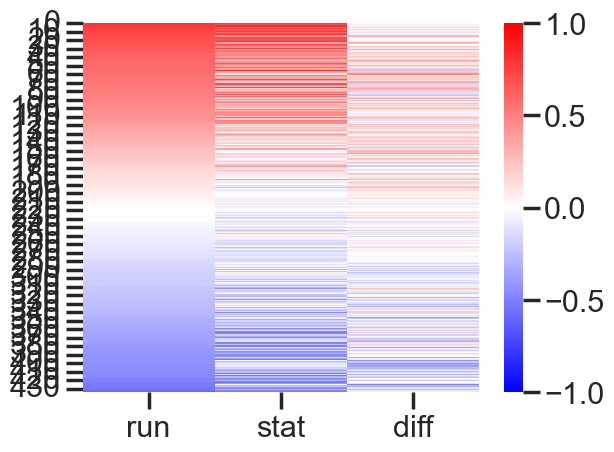

20220822_JA0178_dark1


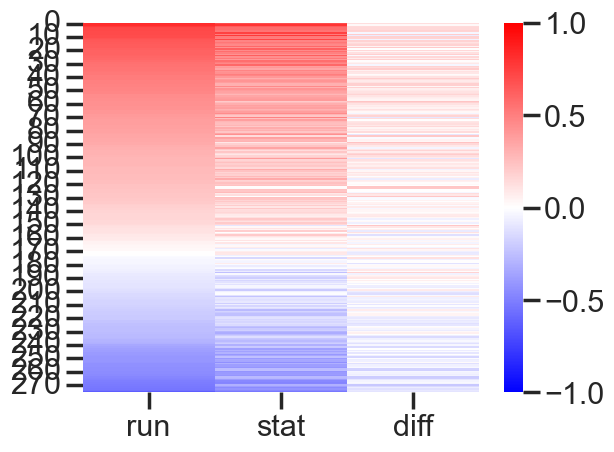

20220822_JA0178_darkHR1


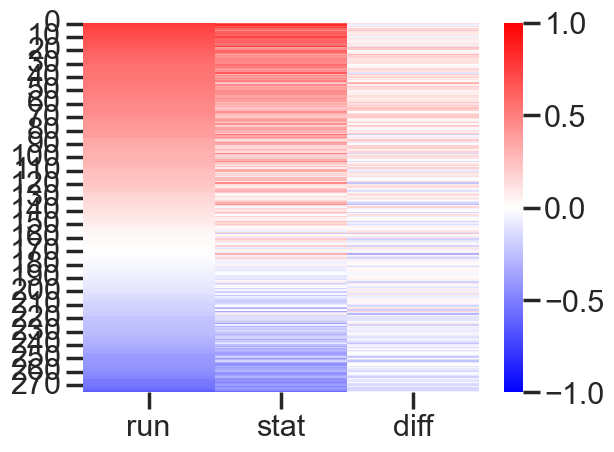

20220822_JA0178_light1


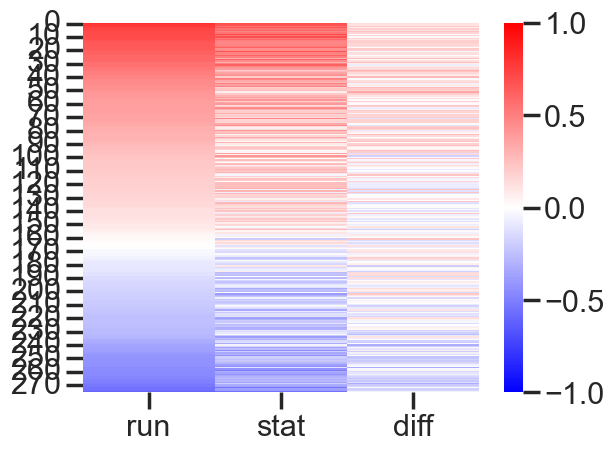

20220822_JA0178_lightHR1


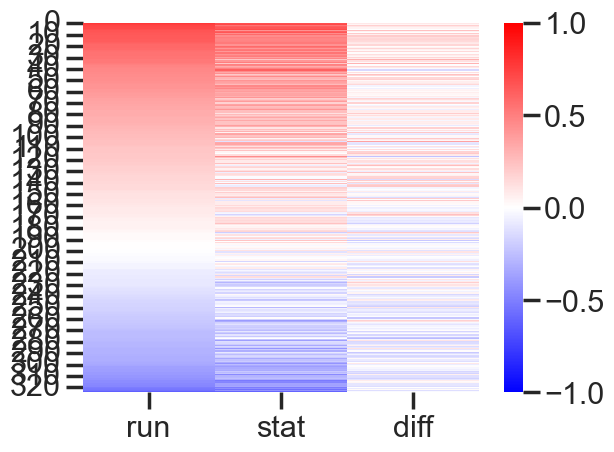

20220824_JA0178_dark1
20220824_JA0178_light1
20220824_JA0178_lightHR1


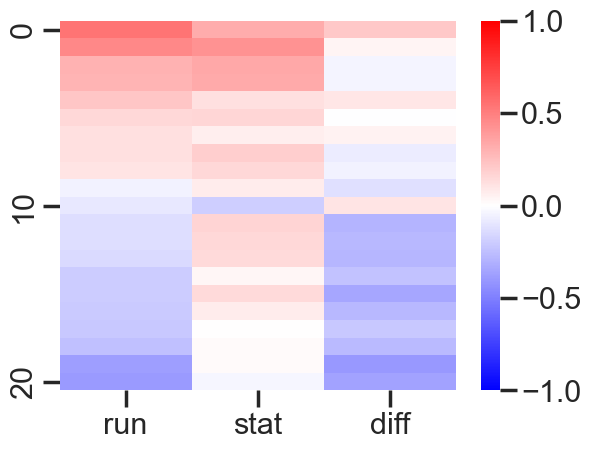

20220906_JA0178_dark1


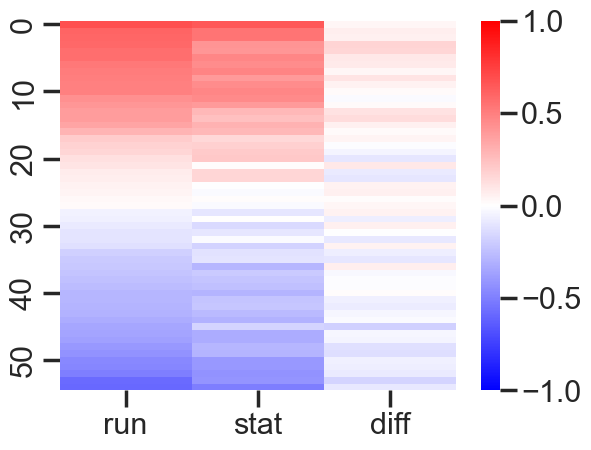

20220906_JA0178_light1


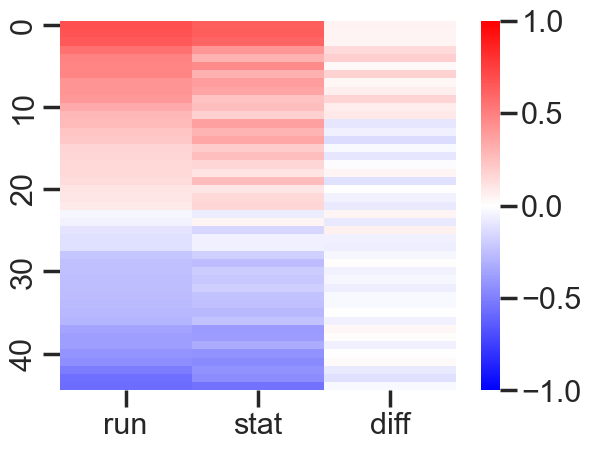

20220812_JA0181_dark1


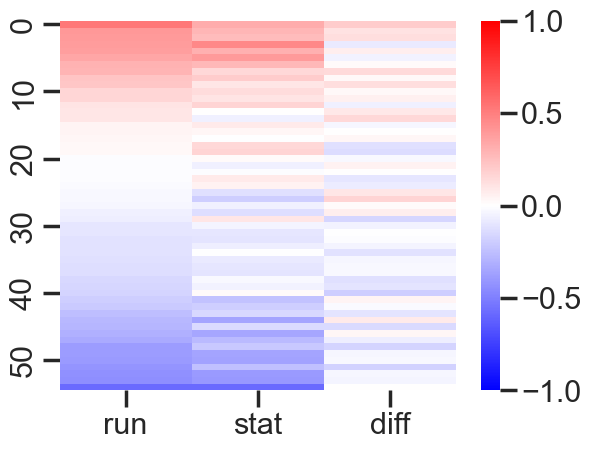

20220812_JA0181_darkHR1


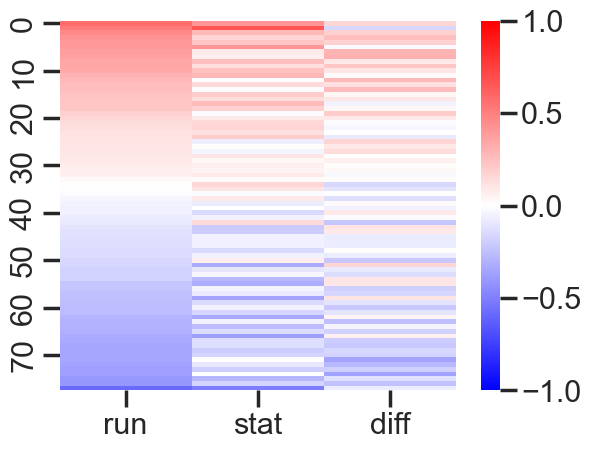

20220812_JA0181_light1


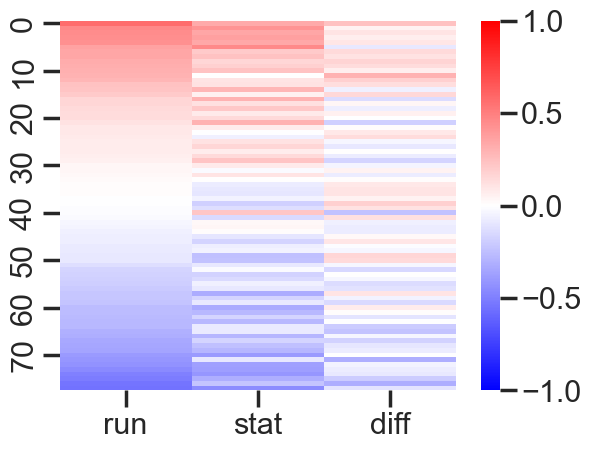

20220812_JA0181_lightHR1


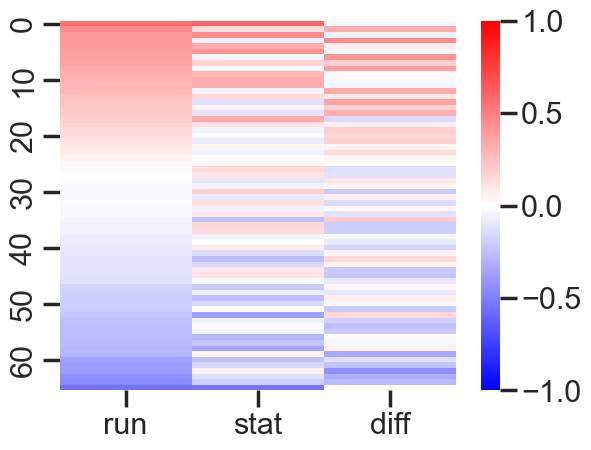

20220815_JA0181_dark1


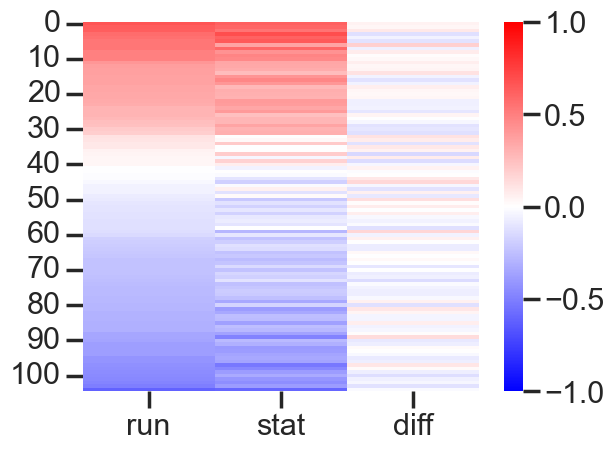

20220815_JA0181_darkHR1


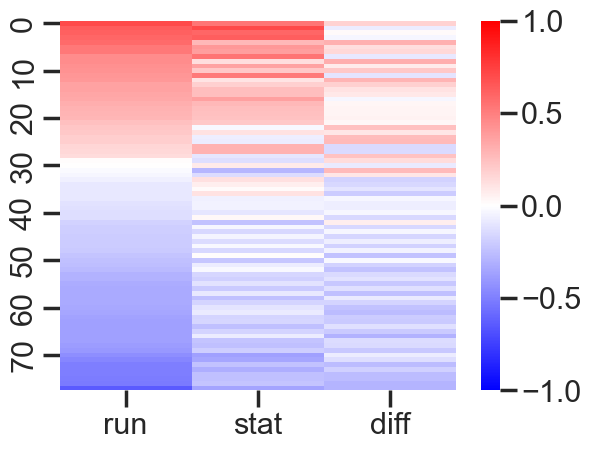

20220815_JA0181_light1


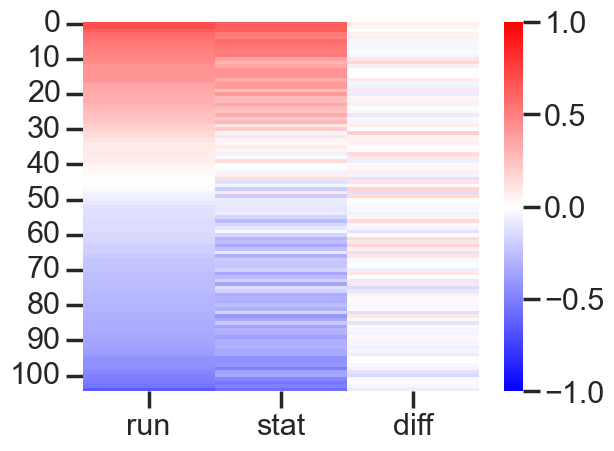

20220815_JA0181_lightHR1


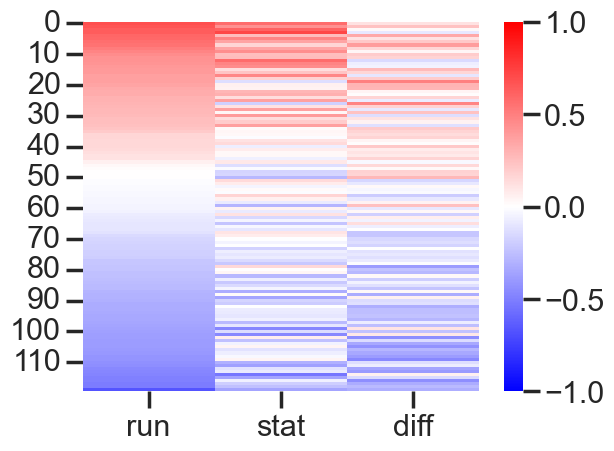

20220818_JA0181_dark1


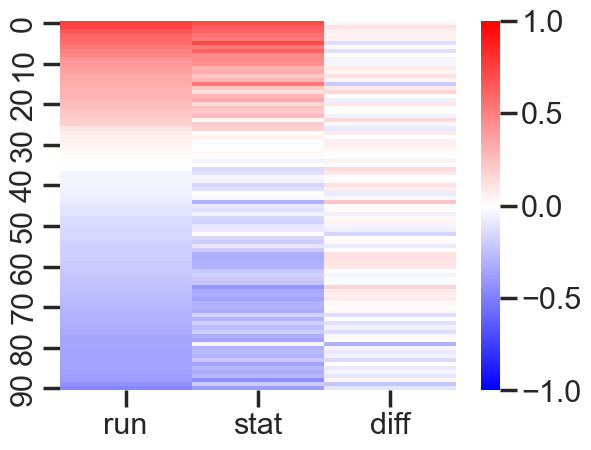

20220818_JA0181_light1


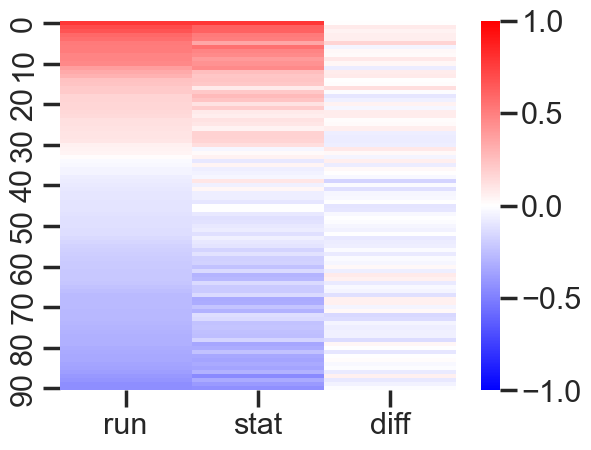

20220818_JA0181_lightHR1


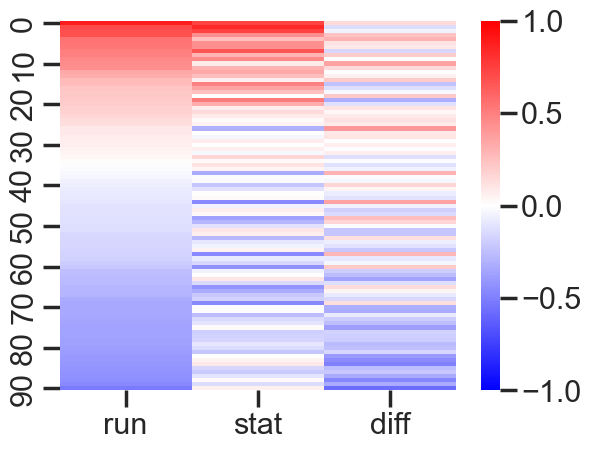

20220712_MC022_dark1


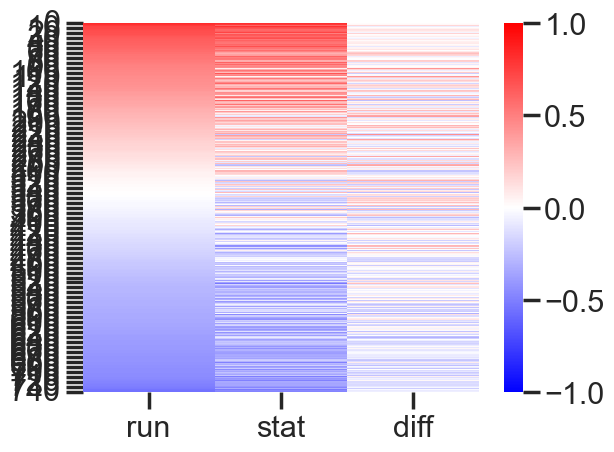

20220712_MC022_darkHR1


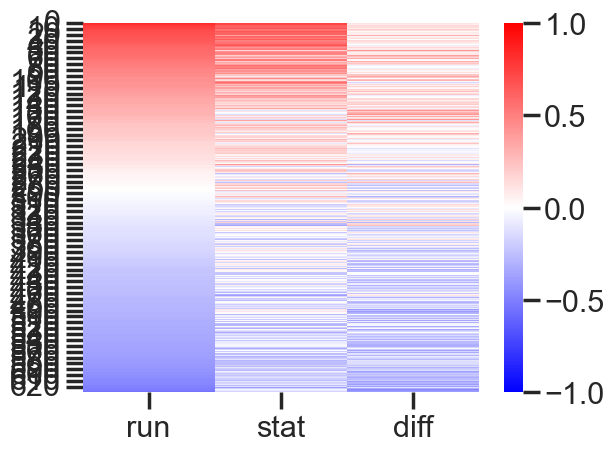

20220712_MC022_light1


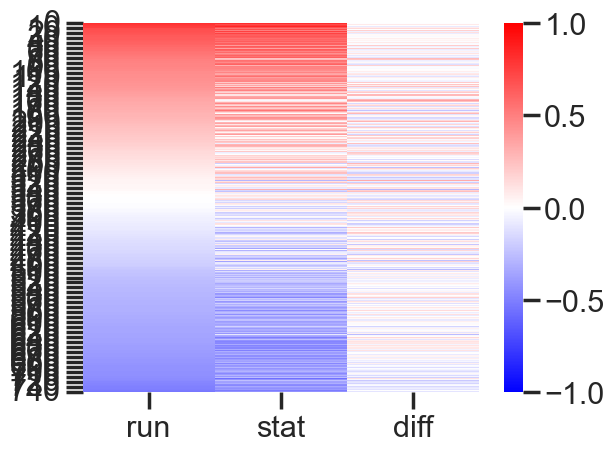

20220712_MC022_lightHR1


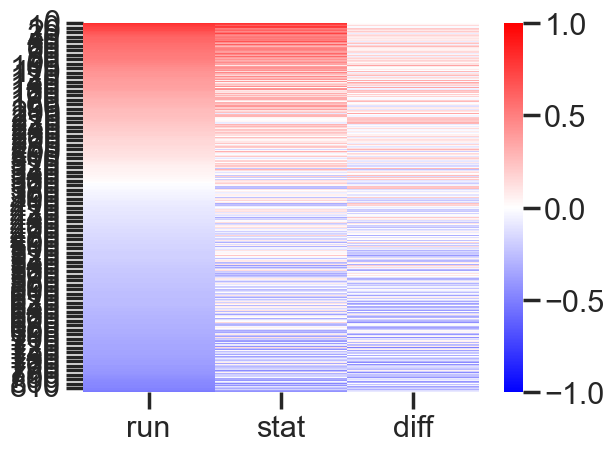

20220829_MC038_lightHR1


,rec_id,animal_name,cond,dts,delta_all,delta_pos,pear_r_pos,pos_n,neg_n,delta_neg,pear_r_neg,pear_r_all
0,20211207_JA0144_dark1,JA0144,dark1,20211207,0.059660,0.016909,0.944,14,14,-0.013682,0.704,0.957
0,20211207_JA0144_darkHR1,JA0144,darkHR1,20211207,0.118528,0.043866,0.765,7,8,-0.048345,0.527,0.825
0,20211207_JA0144_light1,JA0144,light1,20211207,0.056253,-0.012751,0.958,15,13,-0.033228,0.843,0.968
0,20211207_JA0144_lightHR1,JA0144,lightHR1,20211207,0.177548,0.062472,0.891,5,10,-0.193878,-0.384,0.436
0,20220126_JA0153_dark1,JA0153,dark1,20220126,0.187166,0.144013,0.829,26,19,-0.143307,-0.058,0.725


In [427]:
ls = []
ls_hm = []
for rec in df_hr_taucorr.rec_id.unique():
    print(rec)
    # if '20220302_JA0162' not in rec:
    #     continue
    dts, animal_name, cond = rec.split('_')[-3:]
    tmp_tau_arr = df_hr_taucorr[(df_hr_taucorr.rec_id == rec)].pivot(index = 'pair',
                                       columns = 'run', values = 'tau')[['run', 'stat']].values
    diff_tau = tmp_tau_arr[:, 0] - tmp_tau_arr[:, 1]
    loc_pos = tmp_tau_arr[:, 0] > 0
    loc_neg = tmp_tau_arr[:, 0] < 0
    if sum(loc_pos) < 5 or sum(loc_neg) < 5:
        continue
    delta_pos = np.mean((tmp_tau_arr[loc_pos, 0] - tmp_tau_arr[loc_pos, 1]))
    delta_neg = np.mean((tmp_tau_arr[loc_neg, 0] - tmp_tau_arr[loc_neg, 1]))
    delta_all = np.mean(abs(tmp_tau_arr[:, 0] - tmp_tau_arr[:, 1]))
    
    pear_r_pos, pval = stats.pearsonr(tmp_tau_arr[loc_pos, 0], tmp_tau_arr[loc_pos, 1])
    pear_r_neg, pval = stats.pearsonr(tmp_tau_arr[loc_neg, 0], tmp_tau_arr[loc_neg, 1])
    pear_r_all, pval = stats.pearsonr(tmp_tau_arr[:, 0], tmp_tau_arr[:, 1])
            
    tmp_df = pd.DataFrame({
        'rec_id': rec, 'animal_name': animal_name, 'cond': cond,  'dts':dts, 'delta_all':delta_all,
        'delta_pos':delta_pos, 'pear_r_pos': round(pear_r_pos, 3), 'pos_n': loc_pos.sum(), 'neg_n': loc_neg.sum(),
        'delta_neg':delta_neg, 'pear_r_neg': round(pear_r_neg, 3), 'pear_r_all': round(pear_r_all, 3)}, index = [0]
                         )    
    ls.append(tmp_df)
    
    out = np.vstack((tmp_tau_arr.T, diff_tau))
    out_df = pd.DataFrame(out.T, columns = ['run', 'stat', 'diff'])
    out_df = out_df.sort_values(by = 'run', ascending=False).reset_index(drop = True)
    ls_hm.append(out_df)
    sns.heatmap(out_df, cmap = 'bwr', vmin = -1, vmax = 1, yticklabels = 10)
    plt.show()
    # break
df_delta_tau = pd.concat(ls)
df_delta_tau.head()

In [390]:
# ls_hm[1].to_excel(filepath, index = True)

In [428]:
df_delta_tau.head()

,rec_id,animal_name,cond,dts,delta_all,delta_pos,pear_r_pos,pos_n,neg_n,delta_neg,pear_r_neg,pear_r_all
0,20211207_JA0144_dark1,JA0144,dark1,20211207,0.059660,0.016909,0.944,14,14,-0.013682,0.704,0.957
0,20211207_JA0144_darkHR1,JA0144,darkHR1,20211207,0.118528,0.043866,0.765,7,8,-0.048345,0.527,0.825
0,20211207_JA0144_light1,JA0144,light1,20211207,0.056253,-0.012751,0.958,15,13,-0.033228,0.843,0.968
0,20211207_JA0144_lightHR1,JA0144,lightHR1,20211207,0.177548,0.062472,0.891,5,10,-0.193878,-0.384,0.436
0,20220126_JA0153_dark1,JA0153,dark1,20220126,0.187166,0.144013,0.829,26,19,-0.143307,-0.058,0.725


#### Stat vs Run

C:\Users\01\AppData\Local\Temp\ipykernel_16696\4081864844.py:17: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:k'` for the same effect.

  sns.swarmplot(data = _inp_plot, x = 'cond', y = y,  dodge = True,


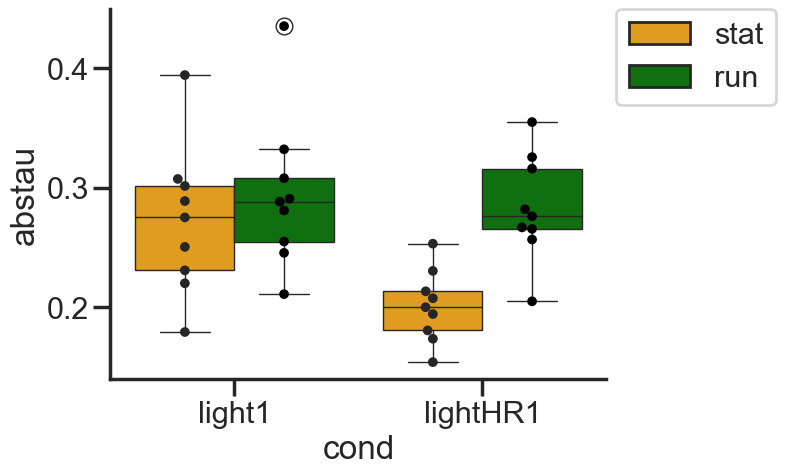

In [415]:
y = 'abstau'
coi = ['light1', 'lightHR1']
pal = ['orange', 'green' ]
# coi = ['dark1', 'darkHR1'];  pal = ['gray', 'brown']

_inp_plot = df_hr_taucorr[(df_hr_taucorr.tau > -1) 
                        & (df_hr_taucorr.run != 'all')
                        # & (df_hr_taucorr.rec_id.isin(good_corr_sess))
                        & (df_hr_taucorr.rec_sess.isin(hr_sess))
                        & (df_hr_taucorr.cond.isin(coi))
                        & (df_hr_taucorr.hdc_pair == '1_1')].groupby(['cond', 'run', 'rec_sess', 'rec_id']).mean(numeric_only=True).reset_index()

# _inp_plot2 = _inp_plot.pivot(index = ['rec_id', 'pair'], columns = 'run', values = 'tau').dropna().reset_index()

sns.boxplot(data = _inp_plot, x = 'cond', y = y,
            hue = 'run', hue_order = ['stat', 'run'], palette=pal, )
sns.swarmplot(data = _inp_plot, x = 'cond', y = y,  dodge = True, 
              hue = 'run', hue_order = ['stat', 'run'], size = 7, color = 'k', legend = None)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)

# filepath = save_dir/f'point_hr_run_{coi}_{y}.pdf'
# plt.savefig(filepath, transparent=True)

In [412]:
_inp_plot.groupby(['cond', 'run'])[y].describe()

count      mean       std       min       25%       50%  \
cond     run                                                             
light1   run     9.0  0.294106  0.063756  0.211051  0.255025  0.288360   
         stat    9.0  0.271998  0.062015  0.179372  0.230920  0.275169   
lightHR1 run     9.0  0.283197  0.043946  0.205038  0.265588  0.276140   
         stat    9.0  0.200872  0.029963  0.154198  0.180720  0.200096   

                    75%       max  
cond     run                       
light1   run   0.307946  0.435124  
         stat  0.301465  0.394202  
lightHR1 run   0.315929  0.354915  
         stat  0.213420  0.253226

In [413]:
a1 = _inp_plot[ (_inp_plot.run == 'stat') & (_inp_plot.cond == coi[0])][y].values
b1 = _inp_plot[ (_inp_plot.run == 'run') & (_inp_plot.cond == coi[0])][y].values

c1 = _inp_plot[ (_inp_plot.run == 'stat') & (_inp_plot.cond == coi[1])][y].values
d1 = _inp_plot[ (_inp_plot.run == 'run') & (_inp_plot.cond == coi[1])][y].values

stat1, pval1 = stats.wilcoxon(a1, b1)
print(f'{coi[0]} stat vs run {stat1} {pval1}')
stat2, pval2 = stats.wilcoxon(c1, d1)
print(f'{coi[1]} stat vs run {stat2} {pval2}')
stat3, pval3 = stats.mannwhitneyu(a1, c1)
print(f'stat {stat3} {pval3}')
stat4, pval4 = stats.mannwhitneyu(b1, d1)
print(f'run {stat4} {pval4}')
pvals = [pval1, pval2, pval3, pval4]  
print('Benjamini/Hochberg (non-negative)')
multipletests(pvals, alpha=0.05, method='fdr_bh')

light1 stat vs run 3.0 0.01953125
lightHR1 stat vs run 0.0 0.00390625
stat 70.0 0.010444271101370226
run 43.0 0.859819205054158
Benjamini/Hochberg (non-negative)


(array([ True,  True,  True, False]),
 array([0.02604167, 0.015625  , 0.02088854, 0.85981921]),
 0.012741455098566168,
 0.0125)

In [416]:
_inp_plot.head()

,cond,run,rec_sess,rec_id,tau,pval,n_hdc,abstau
0,light1,run,JA0153_20220126,20220126_JA0153_light1,0.122146,1.080060e-02,13.0,0.255025
1,light1,run,JA0162_20220302,20220302_JA0162_light1,-0.001302,9.309372e-26,8.0,0.435124
2,light1,run,JA0164_20220419,20220419_JA0164_light1,0.090880,1.645515e-02,8.0,0.288360
3,light1,run,JA0178_20220819,20220819_JA0178_light1,0.076955,1.108935e-02,29.0,0.332116
4,light1,run,JA0178_20220822,20220822_JA0178_light1,0.096520,8.023445e-03,24.0,0.307946


In [417]:
# filepath = save_dir / f'out.xlsx'
# _inp_plot.to_excel(filepath, index = True)

#### Map off-manifold index to tau corr

In [466]:
df_hr_betti.head()

,rec_id,cond,dts,animal_name,az_occ,run,h1_bar,dec_err,rec_session,stat_off_manifold,run_ratio
0,20211207_JA0144_light1,light1,20211207,JA0144,0.916667,stat,5.956747,27.552,JA0144_20211207,0.155352,0.659375
0,20211207_JA0144_light1,light1,20211207,JA0144,1.000000,locom,6.397861,24.376,JA0144_20211207,0.155352,0.659375
0,20220126_JA0153_light1,light1,20220126,JA0153,0.916667,stat,14.210236,22.769,JA0153_20220126,0.179570,0.612500
0,20220126_JA0153_light1,light1,20220126,JA0153,1.000000,locom,15.542182,27.529,JA0153_20220126,0.179570,0.612500
0,20220126_JA0153_lightHR1,lightHR1,20220126,JA0153,0.944444,stat,5.941467,28.507,JA0153_20220126,0.625000,0.433333


In [467]:
d_hr_offman = dict(zip(df_hr_betti[df_hr_betti.run == 'stat'].rec_id.values, 
                       df_hr_betti[df_hr_betti.run == 'stat'].stat_off_manifold.values))
df_delta_tau['stat_off_manifold'] = df_delta_tau.rec_id.map(d_hr_offman)
df_delta_tau['rec_session'] = df_delta_tau.animal_name + '_' + df_delta_tau.dts


C:\Users\01\AppData\Local\Temp\ipykernel_16696\3764525717.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data = _inp_plot, x = 'cond', y = y, errorbar=('ci', 68), palette=pal)
C:\Users\01\AppData\Local\Temp\ipykernel_16696\3764525717.py:8: UserWarning: 
The palette list has fewer values (2) than needed (4) and will cycle, which may produce an uninterpretable plot.
  sns.barplot(data = _inp_plot, x = 'cond', y = y, errorbar=('ci', 68), palette=pal)


<Axes: xlabel='cond', ylabel='delta_neg'>

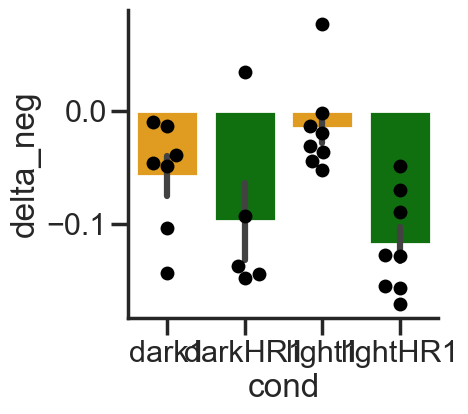

In [468]:
f, ax = plt.subplots(figsize = (4, 4))

y = 'delta_neg'
pal = ['orange', 'green']

_inp_plot = df_delta_tau[df_delta_tau.rec_session.isin(good_sess)]
# sns.pointplot(data = _inp_plot, x = 'cond', y = y, hue = 'dts', color = 'red')
sns.barplot(data = _inp_plot, x = 'cond', y = y, errorbar=('ci', 68), palette=pal)
sns.swarmplot(data = _inp_plot, x = 'cond', y = y, size = 10, color = 'k')
# plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)
# plt.savefig(f'bar_hr_{y}.pdf', transparent = True)  

In [469]:
print(_inp_plot.groupby(['cond' ])[y].describe())

a1 = _inp_plot[ (_inp_plot.cond == 'light1')][y].values
b1 = _inp_plot[ (_inp_plot.cond == 'lightHR1')][y].values

print(stats.wilcoxon(a1, b1))
print(stats.ttest_rel(a1, b1))

          count      mean       std       min       25%       50%       75%  \
cond                                                                          
dark1       7.0 -0.057691  0.048731 -0.143307 -0.076035 -0.046293 -0.026167   
darkHR1     5.0 -0.097238  0.076700 -0.147441 -0.143716 -0.136730 -0.092477   
light1      8.0 -0.015207  0.040631 -0.052436 -0.038364 -0.025208 -0.010265   
lightHR1    8.0 -0.117784  0.044301 -0.170167 -0.154725 -0.127373 -0.084335   

               max  
cond                
dark1    -0.009831  
darkHR1   0.034174  
light1    0.076673  
lightHR1 -0.048160  
WilcoxonResult(statistic=0.0, pvalue=0.0078125)
TtestResult(statistic=3.959437082660187, pvalue=0.005465602643230604, df=7)


In [470]:
df_delta_tau.head()

,rec_id,animal_name,cond,dts,delta_all,delta_pos,pear_r_pos,pos_n,neg_n,delta_neg,pear_r_neg,pear_r_all,stat_off_manifold,rec_session
0,20211207_JA0144_dark1,JA0144,dark1,20211207,0.059660,0.016909,0.944,14,14,-0.013682,0.704,0.957,NaN,JA0144_20211207
0,20211207_JA0144_darkHR1,JA0144,darkHR1,20211207,0.118528,0.043866,0.765,7,8,-0.048345,0.527,0.825,NaN,JA0144_20211207
0,20211207_JA0144_light1,JA0144,light1,20211207,0.056253,-0.012751,0.958,15,13,-0.033228,0.843,0.968,0.155352,JA0144_20211207
0,20211207_JA0144_lightHR1,JA0144,lightHR1,20211207,0.177548,0.062472,0.891,5,10,-0.193878,-0.384,0.436,NaN,JA0144_20211207
0,20220126_JA0153_dark1,JA0153,dark1,20220126,0.187166,0.144013,0.829,26,19,-0.143307,-0.058,0.725,0.564870,JA0153_20220126


L1 PearsonRResult(statistic=0.15875226441742893, pvalue=0.6833079155599018)
HR PearsonRResult(statistic=0.6770834513238242, pvalue=0.04513683211746637)


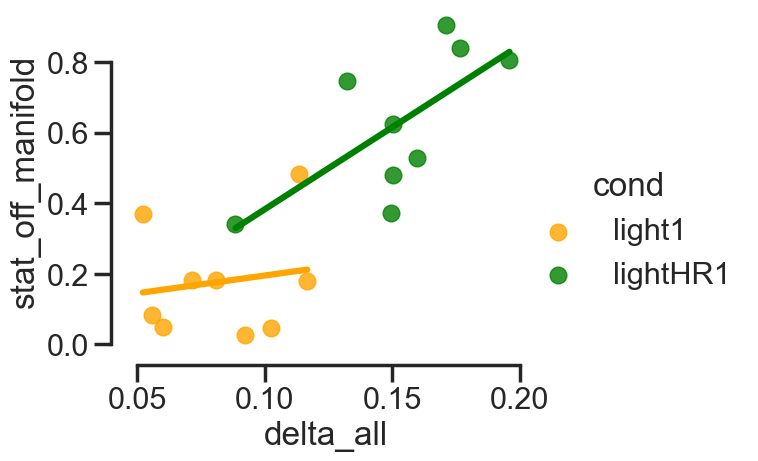

In [471]:
coi = ['light1', 'lightHR1']; pal = ['orange', 'green']
# coi = ['dark1', 'darkHR1'];  pal = ['gray', 'brown']

_inp_plot = df_delta_tau[df_delta_tau.rec_session.isin(hr_sess)
                        & (df_delta_tau.cond.isin(coi))
                        ]
# _inp_plot = df_delta_tau.dropna()
x, y = 'delta_all', 'stat_off_manifold'


sns.lmplot(data = _inp_plot, x = x, y = y, hue = 'cond', palette=pal,
           hue_order = coi, 
           aspect = 1.2, ci=None)

a1 = _inp_plot[(_inp_plot.cond == coi[0])][x].values
a2 = _inp_plot[(_inp_plot.cond == coi[0])][y].values
b1 = _inp_plot[(_inp_plot.cond == coi[1])][x].values
b2 = _inp_plot[(_inp_plot.cond == coi[1])][y].values

print('L1', stats.pearsonr(a1, a2))
print('HR', stats.pearsonr(b1, b2))
sns.despine(offset=10, trim=True)

# plt.savefig(f'lmplot_hr_{coi}_{x}_{y}.pdf', transparent = True)

In [473]:
_inp_plot.head()

,rec_id,animal_name,cond,dts,delta_all,delta_pos,pear_r_pos,pos_n,neg_n,delta_neg,pear_r_neg,pear_r_all,stat_off_manifold,rec_session
0,20220126_JA0153_light1,JA0153,light1,20220126,0.116739,0.095614,0.869,52,26,-0.019798,0.628,0.883,0.179570,JA0153_20220126
0,20220126_JA0153_lightHR1,JA0153,lightHR1,20220126,0.150322,0.178652,0.773,108,63,-0.048160,0.715,0.883,0.625000,JA0153_20220126
0,20220302_JA0162_light1,JA0162,light1,20220302,0.052282,0.037246,0.960,13,15,-0.044108,0.975,0.994,0.367918,JA0162_20220302
0,20220302_JA0162_lightHR1,JA0162,lightHR1,20220302,0.159671,0.149720,0.955,17,19,-0.156290,0.760,0.927,0.528650,JA0162_20220302
0,20220419_JA0164_light1,JA0164,light1,20220419,0.080869,0.060106,0.955,16,12,0.076673,0.933,0.981,0.181818,JA0164_20220419


In [474]:
# filepath = save_dir / f'out.xlsx'
# _inp_plot.to_excel(filepath, index = True)

## Off-manifold dynamics

In [16]:
from pathlib import Path

# Check if directory exists
save_dir = Path(r"C:\Users\01\Documents")


In [14]:
# df_hr_tuning.to_pickle('df_hr_tuning_master.pkl')

In [475]:
# both arena and hr present
good_sess = ['JA0144_20211212',  'JA0153_20220209', 'JA0162_20220302', 'JA0164_20220419',
             'JA0178_20220819', 'JA0181_20220812', 'JA0181_20220815', 'JA0181_20220818',
             'MC022_20220712', 'JA0153_20220126' ]

In [476]:
def circ_preferred_direction(tuning_curve, bin_centers_rad, method="circular_mean"):
    """
    Estimate the preferred direction of one HD cell.

    Parameters
    ----------
    tuning_curve   : 1-D array, firing rate per angular bin
    bin_centers_deg: 1-D array, centre of each bin (degrees)
    method         : 'circular_mean' (default) or 'peak'

    Returns
    -------
    pref_dir : float, degrees [0, 360)
    """
    if method == "peak":
        pk, _ = find_peaks(tuning_curve)
        if len(pk) == 0:
            pk = [np.argmax(tuning_curve)]
        best = pk[np.argmax(tuning_curve[pk])]
        return float(bin_centers_deg[best]) % 360
    else:  # circular_mean — robust to noise
        angles = np.deg2rad(bin_centers_rad)
        # angles = bin_centers_rad
        weights = np.clip(tuning_curve, 0, None)
        weights /= weights.sum() + 1e-12
        mean_angle = np.arctan2(
            np.sum(weights * np.sin(angles)),
            np.sum(weights * np.cos(angles))
        )
        return float(np.rad2deg(mean_angle) % 360)

In [477]:
ls_pref = []
for k in d_hr_data.keys():
    tmp_df = d_hr_data[k]['tuning']
    _inp = tmp_df[(tmp_df.rec_id == k) & (tmp_df.hdc_flag == True)]
    idx = _inp.groupby([ 'rec_id', 'cuid'])['tuning'].transform(lambda x: x.max()) == _inp['tuning']
    tmp_df_pref = _inp[idx][['condition', 'rec_id', 'cids', 'x_tuning', 'tuning']]
    ls_pref.append(tmp_df_pref)
    # break
df_pref = pd.concat(ls_pref)
df_pref.head()

,condition,rec_id,cids,x_tuning,tuning
15,dark1,20211207_JA0144_dark1,25.0,303.0,2.448795
6,dark1,20211207_JA0144_dark1,51.0,123.0,6.371094
11,dark1,20211207_JA0144_dark1,62.0,223.0,46.792631
11,dark1,20211207_JA0144_dark1,66.0,223.0,15.837189
11,dark1,20211207_JA0144_dark1,67.0,223.0,2.114824


In [478]:
d_hr_data.keys()

dict_keys(['20211207_JA0144_dark1', '20211207_JA0144_darkHR1', '20211207_JA0144_light1', '20211207_JA0144_lightHR1', '20220126_JA0153_dark1', '20220126_JA0153_darkHR1', '20220126_JA0153_light1', '20220126_JA0153_lightHR1', '20220302_JA0162_dark1', '20220302_JA0162_darkHR1', '20220302_JA0162_light1', '20220302_JA0162_lightHR1', '20220419_JA0164_dark1', '20220419_JA0164_darkHR1', '20220419_JA0164_light1', '20220419_JA0164_lightHR1', '20220819_JA0178_dark1', '20220819_JA0178_darkHR1', '20220819_JA0178_light1', '20220819_JA0178_lightHR1', '20220822_JA0178_dark1', '20220822_JA0178_darkHR1', '20220822_JA0178_light1', '20220822_JA0178_lightHR1', '20220824_JA0178_dark1', '20220824_JA0178_darkHR1', '20220824_JA0178_light1', '20220824_JA0178_lightHR1', '20220906_JA0178_dark1', '20220906_JA0178_darkHR1', '20220906_JA0178_light1', '20220906_JA0178_lightHR1', '20220812_JA0181_dark1', '20220812_JA0181_darkHR1', '20220812_JA0181_light1', '20220812_JA0181_lightHR1', '20220815_JA0181_dark1', '20220815_

In [479]:
d_hr_emb.keys()

dict_keys(['20211207_JA0144_light1', '20220126_JA0153_light1', '20220126_JA0153_lightHR1', '20220302_JA0162_light1', '20220302_JA0162_lightHR1', '20220419_JA0164_light1', '20220419_JA0164_lightHR1', '20220819_JA0178_light1', '20220819_JA0178_lightHR1', '20220822_JA0178_light1', '20220822_JA0178_lightHR1', '20220906_JA0178_light1', '20220812_JA0181_light1', '20220812_JA0181_lightHR1', '20220815_JA0181_light1', '20220815_JA0181_lightHR1', '20220818_JA0181_light1', '20220818_JA0181_lightHR1', '20220712_MC022_light1', '20220712_MC022_lightHR1', '20220126_JA0153_dark1', '20220126_JA0153_darkHR1', '20220302_JA0162_dark1', '20220302_JA0162_darkHR1', '20220419_JA0164_dark1', '20220419_JA0164_darkHR1', '20220819_JA0178_dark1', '20220819_JA0178_darkHR1', '20220822_JA0178_dark1', '20220822_JA0178_darkHR1', '20220906_JA0178_dark1', '20220906_JA0178_darkHR1', '20220812_JA0181_dark1', '20220812_JA0181_darkHR1', '20220815_JA0181_dark1', '20220815_JA0181_darkHR1', '20220818_JA0181_dark1', '20220818_JA

20220126_JA0153_lightHR1
circstd is too high 13.696211418436045
20220126_JA0153_lightHR1, ep idx: 29
len 190, mean: 60.89503597140978 std: 1.16, idx: 1345 - 1535
(3, 190) (16, 190)
pear r HDC@pref 0.5163314079133094 HDC @ non-pref -0.7099772236821018
rand pref HDC -0.4046208412675214

circstd is too high 14.91046135381278
20220126_JA0153_lightHR1, ep idx: 39
len 35, mean: 354.61787624603215 std: 3.07, idx: 1790 - 1825
not enough pref HDC 0
20220126_JA0153_lightHR1, ep idx: 41
len 215, mean: 197.16657988751183 std: 0.95, idx: 1875 - 2075
(10, 200) (9, 200)
pear r HDC@pref 0.3919105762355939 HDC @ non-pref -0.01895979770739878
rand pref HDC 0.12502780243099548

20220126_JA0153_lightHR1, ep idx: 50
len 190, mean: 103.89353676440189 std: 3.97, idx: 2450 - 2640
(4, 190) (15, 190)
pear r HDC@pref 0.5347113377336474 HDC @ non-pref -0.5598400347005317
rand pref HDC -0.1865636009817819

circstd is too high 17.415824392252837
20220126_JA0153_lightHR1, ep idx: 67
len 45, mean: 160.72896943803482 

C:\Users\01\AppData\Local\Temp\ipykernel_16696\1917683626.py:181: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  f, ax = plt.subplots(4, figsize = (10, 12), sharex = 'col')


rand pref HDC 0.037340492991498275

20220302_JA0162_lightHR1, ep idx: 87
len 160, mean: 222.15304314578427 std: 3.9, idx: 3655 - 3815
not enough pref HDC 1
20220302_JA0162_lightHR1, ep idx: 88
len 155, mean: 48.71261277875497 std: 3.06, idx: 3825 - 3980
not enough pref HDC 1
20220302_JA0162_lightHR1, ep idx: 89
len 40, mean: 14.132590261339468 std: 2.78, idx: 3990 - 4030
not enough pref HDC 0
20220302_JA0162_lightHR1, ep idx: 91
len 660, mean: 28.762708174732538 std: 1.77, idx: 4140 - 4340
not enough pref HDC 1
20220419_JA0164_lightHR1
circstd is too high 20.574688691474588
20220419_JA0164_lightHR1, ep idx: 2
len 150, mean: 97.45691038234136 std: 2.44, idx: 210 - 360
not enough pref HDC 0
20220419_JA0164_lightHR1, ep idx: 13
len 3845, mean: 79.40206968819368 std: 3.23, idx: 740 - 940
(3, 200) (7, 200)
pear r HDC@pref 0.9233309283702694 HDC @ non-pref 0.11839465231149852
rand pref HDC 0.42437851356549017

20220819_JA0178_lightHR1
20220819_JA0178_lightHR1, ep idx: 14
len 855, mean: 48.71

,dts,animal_name,cond,rec_id,ep_idx,r_hdc,r_nonhdc,r_rand,offman_ep_flag,min_rad
0,20220126,JA0153,lightHR1,20220126_JA0153_lightHR1,29,0.516331,-0.709977,-0.687574,True,0.118377
0,20220126,JA0153,lightHR1,20220126_JA0153_lightHR1,41,0.391911,-0.018960,0.198881,True,0.041279
0,20220126,JA0153,lightHR1,20220126_JA0153_lightHR1,50,0.534711,-0.559840,-0.055238,True,0.157587
0,20220126,JA0153,lightHR1,20220126_JA0153_lightHR1,67,0.645021,0.334978,0.495500,True,0.396868
0,20220126,JA0153,lightHR1,20220126_JA0153_lightHR1,74,0.802182,-0.674151,0.214133,True,0.031821


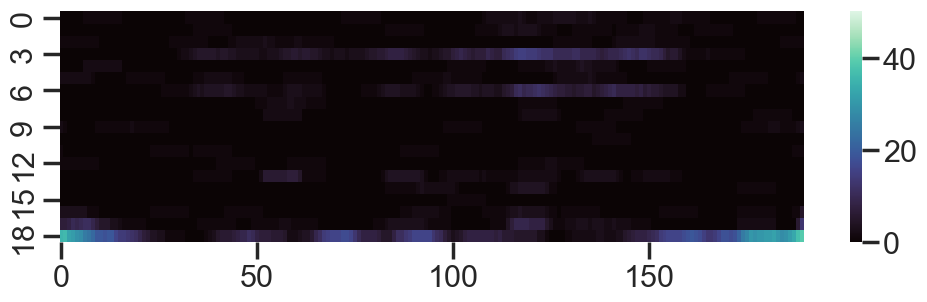

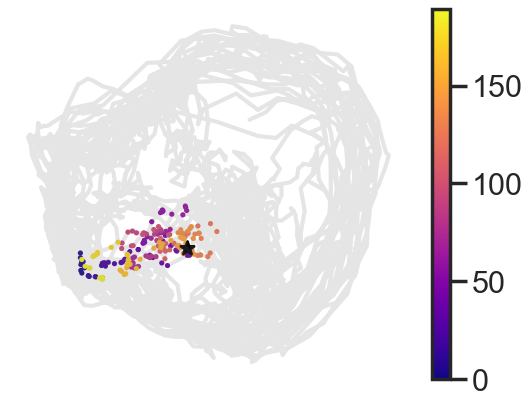

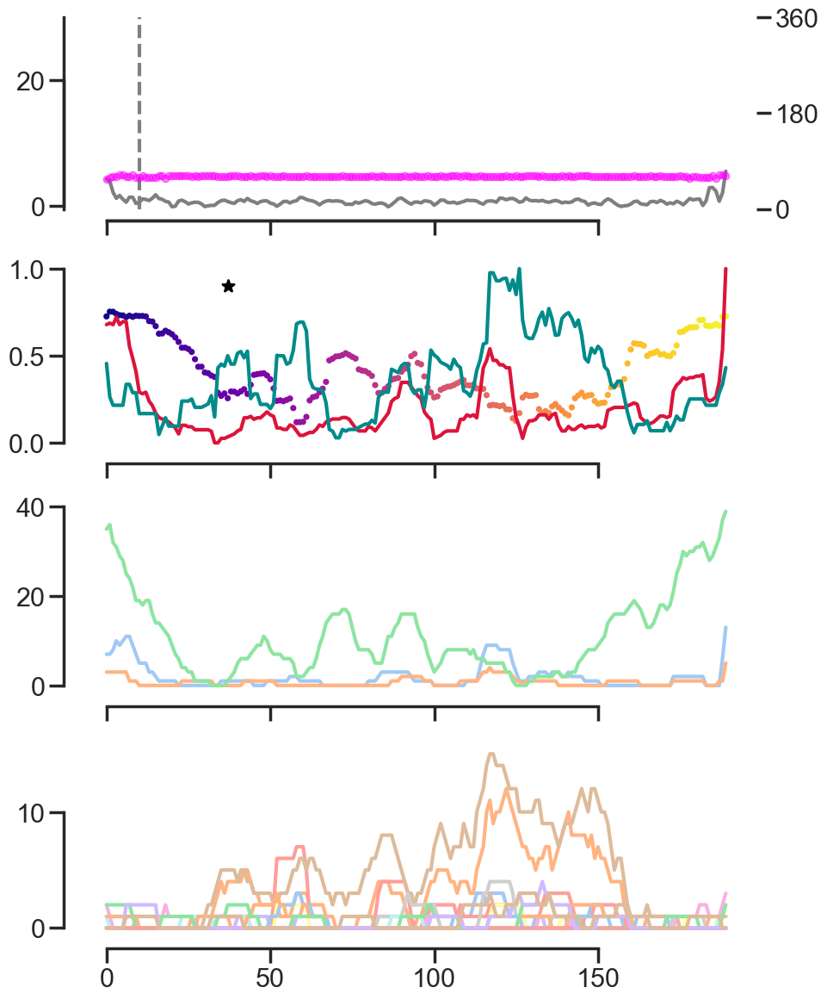

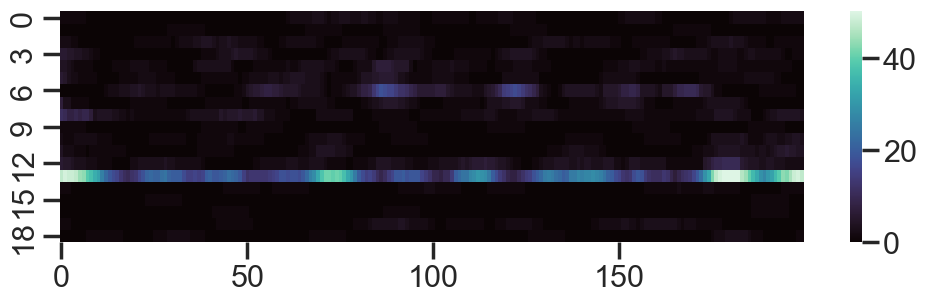

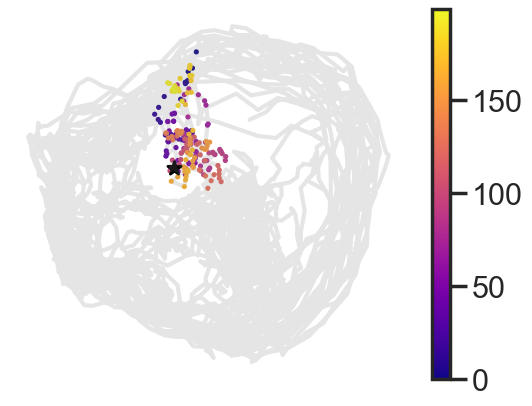

...

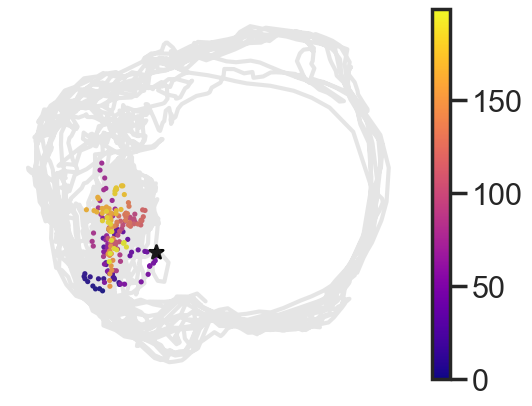

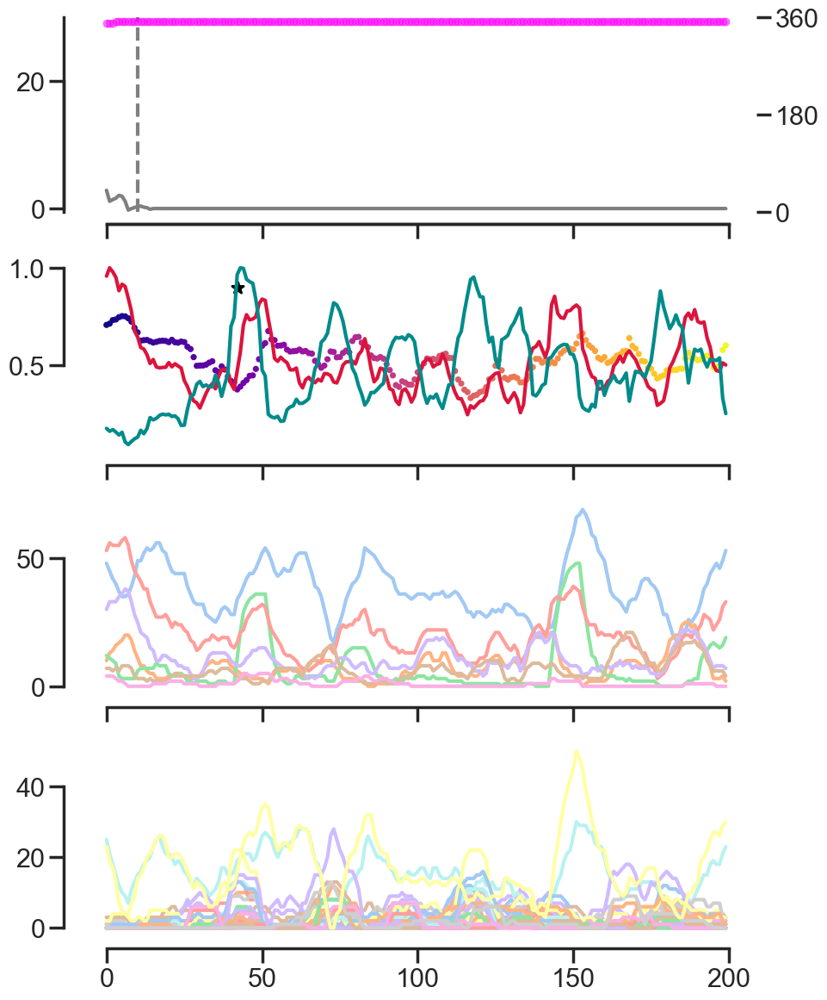

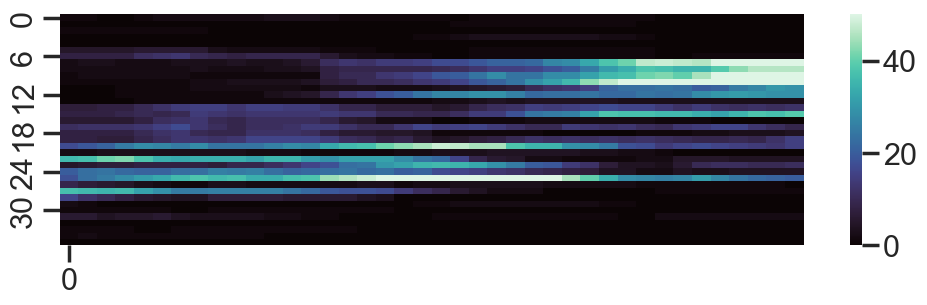

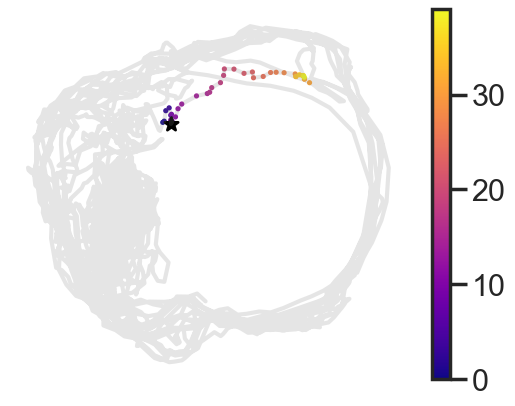

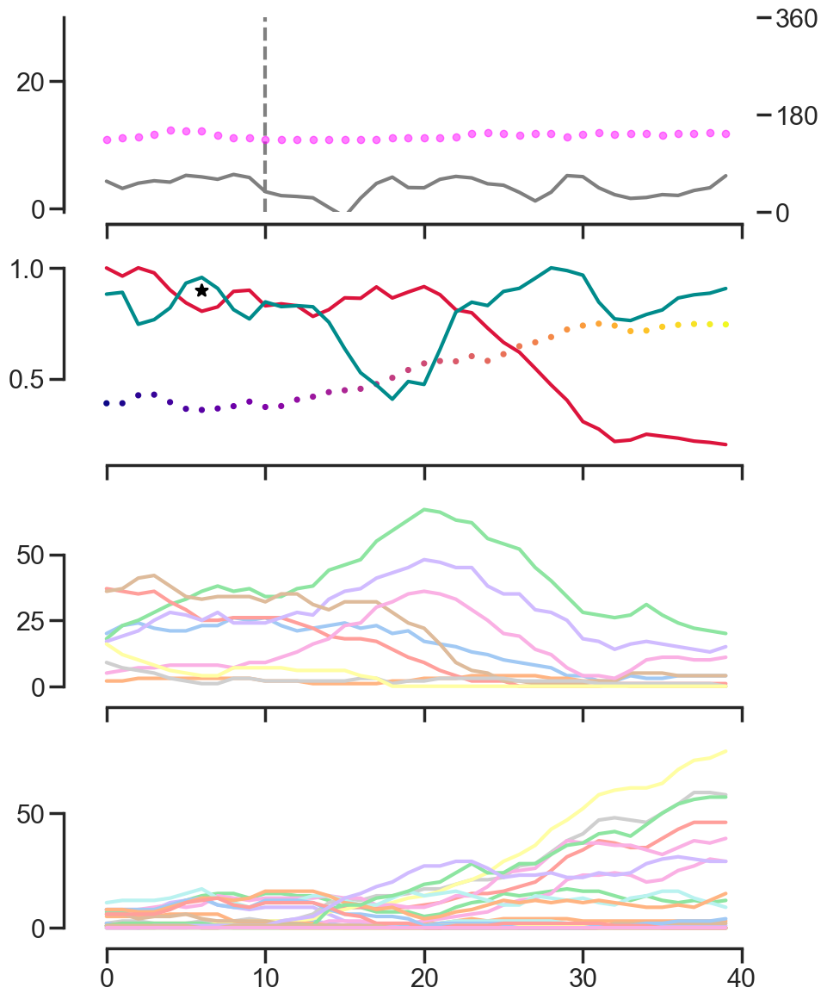

In [515]:
ls_pref, ls_nonpref, ls_rand = [], [], []
ls_df = []
ep_idx = 0
ep_offset = 10
to_plot = True
# 1-10s
ep_min_dur, ep_max_dur = 30, 200
pref_dir_thr = 45

for k in d_hr_emb.keys():
    if 'HR1' not in k:
        continue

    # if '20220712_MC022_lightHR1' not in k:
    #     continue
        
    print(k)
    tmp_ephys = d_hr_data[k]['ephys']
    tmp_beh = d_hr_data[k]['beh']
    dts, animal_name, cond = k.split('_')[-3:]
#     sess_hdc = tmp_ephys[tmp_ephys.hdc_flag == True].cids.unique()
    sess_hdc = df_pref[df_pref.rec_id == k].cids.unique()
    if sess_hdc.size < 8:
        print(f'not enough HDC {sess_hdc.size}')
        continue



#     sh = d_good_shanks[implant]
#     tmp_hist = df_hist_master[(df_hist_master.mouse_id == mouse_id) 
#            & (df_hist_master.dts == dts)
#            & (df_hist_master.group != 'noise')
#           & (df_hist_master.shank.isin(sh))]
#     units_in = tmp_hist.id.unique()
#     sess_hdc = tmp_hist[tmp_hist.hdc == 1].id.values
#     print(tmp.rec_id.values[0])
    
    measured_yaw = tmp_beh['yaw'].values[::5]
    if np.min(measured_yaw) < -10:
        measured_yaw = measured_yaw + 180
    lin_speed = tmp_beh['lin_vel'].values[::5]
    
    emb_x, emb_y = d_hr_emb[k]['isomap'][:,0], d_hr_emb[k]['isomap'][:,1]
    stat_idx, run_idx = get_stat_run_epochs(lin_speed, window_size=5, speed_thr = 5)
    # get stat epochs
    stat_epoch = consecutive(stat_idx)

    # compute off manifold ratios
    run_mask = np.zeros(lin_speed.size, dtype=bool)
    run_mask[run_idx] = True

    # new function to compute rad
    cxy, rad_manifold = compute_radius_runmask(emb_x, emb_y, run_mask)
    rad_manifold_norm = rad_manifold/rad_manifold.max()

    # find hdc ids for this rec
    hdc_units = df_pref[df_pref.rec_id == k].cids.values
    pref_dir = df_pref[df_pref.rec_id == k].x_tuning.values
    sorted_pref_dir = np.argsort(pref_dir)
    tmp_ephys_sel = tmp_ephys[tmp_ephys.cids.isin(sess_hdc)]
    offman_ep_flag = False
    
    for ep_idx, ep in enumerate(stat_epoch):
        # if ep_idx != 32:
        #     continue
        # at least 1s and no change in az
        if (len(ep) > ep_min_dur):
            start, end = ep[0], ep[:][-1]+1
            if start < 0:
                start = 0
            if ep.size > ep_max_dur:
                end = start + ep_max_dur
                
            this_man_rad = rad_manifold_norm[start:end]
            if this_man_rad.max() - this_man_rad.min() > 0.2:
                offman_ep_flag = True
            else:
                continue

                
            angles = np.deg2rad(measured_yaw[start:end])
            circstd = stats.circstd(angles[ep_offset:])
            circstd = np.rad2deg(circstd)
            # during stat
            this_yaw = np.rad2deg(stats.circmean(angles[ep_offset:]))
            if circstd > 5:
                print(f'circstd is too high {circstd}')
                continue
            
            print(f'{k}, ep idx: {ep_idx}')
            print(f'len {len(ep)}, mean: {this_yaw} std: {round(circstd, 2)}, idx: {start} - {end}')
            
            # get hdc preferring this yaw
            pref_idx = ang_diff(pref_dir, this_yaw) <= pref_dir_thr
            non_pref_idx = ang_diff(pref_dir, this_yaw) > pref_dir_thr 
            if sum(pref_idx) < 3:
                print(f'not enough pref HDC {sum(pref_idx)}')
                continue
    
            _inp = tmp_ephys_sel.pivot(index = 'cids', columns = 'times', values = 'hz').values[:, ::5][:, start:end]
            _inp_hdc = tmp_ephys_sel[tmp_ephys_sel.cids.isin(hdc_units[pref_idx])].pivot(index = 'cids', 
                                         columns = 'times', values = 'hz').values[:, ::5][:, start:end]
            _inp_nonhdc = tmp_ephys_sel[tmp_ephys_sel.cids.isin(hdc_units[non_pref_idx])].pivot(index = 'cids', 
                                         columns = 'times', values = 'hz').values[:, ::5][:, start:end]

#             to calculate corrs
            _inp_norm = _inp[:, :]/(_inp.max(axis = 1) + 1e-9)[:,np.newaxis]
            _inp_hdc_norm = _inp_hdc[:, :]/(_inp_hdc.max(axis = 1) + 1e-9)[:,np.newaxis]
            _inp_nonhdc_norm = _inp_nonhdc[:, :]/(_inp_nonhdc.max(axis = 1) + 1e-9)[:,np.newaxis]

            # min in first 5s after run
            offset = this_man_rad[:50].argmin()
            print(_inp_hdc.shape, _inp_nonhdc_norm.shape)
            hdc_vec = _inp_hdc_norm.sum(axis = 0)
            hdc_gain = hdc_vec/hdc_vec.max()
            nonhdc_vec = _inp_nonhdc_norm.sum(axis = 0)
            nonhdc_gain = nonhdc_vec/nonhdc_vec.max()
            
            r_hdc, pval = (stats.pearsonr(this_man_rad, hdc_gain))
            r_nonhdc, pval = (stats.pearsonr(this_man_rad, nonhdc_gain))
            print(f'pear r HDC@pref {r_hdc} HDC @ non-pref {r_nonhdc}')
            
            # shuffled population
            ls_rand = []
            for i in range(20):
                rand_n = np.random.randint(3, hdc_units.size//2)
                rand_units = np.random.choice(hdc_units, size = rand_n)
                _inp_rand = tmp_ephys_sel[tmp_ephys_sel.cids.isin(rand_units)].pivot(index = 'cids', 
                                                             columns = 'times', values = 'hz').values[:, ::5][:, start:end]
                _inp_rand_norm = _inp_rand[:, :]/(_inp_rand.max(axis = 1) + 1e-9)[:,np.newaxis]
                
                if np.sum(_inp_rand_norm) < 1:
                    continue
                rand_vec = _inp_rand_norm.sum(axis = 0)
                rand_gain = rand_vec/rand_vec.max()
                r_rand, pval = stats.pearsonr(this_man_rad, rand_gain)
                ls_rand.append(r_rand)
            print(f'rand pref HDC {np.mean(ls_rand)}')
            print()

            if to_plot:
                # to plot
                # _inp_norm = _inp[:, start:end]/_inp.max(axis = 1)[:,np.newaxis]
                # _inp_hdc_norm = _inp_hdc[:, start:end]/_inp_hdc.max(axis = 1)[:,np.newaxis]
                # _inp_nonhdc_norm = _inp_nonhdc[:, start:end]/_inp_nonhdc.max(axis = 1)[:,np.newaxis]
                # hdc_vec = _inp_hdc_norm.sum(axis = 0)
                # hdc_gain = hdc_vec/hdc_vec.max()
                # nonhdc_vec = _inp_nonhdc_norm.sum(axis = 0)
                # nonhdc_gain = nonhdc_vec/nonhdc_vec.max()

                f, ax = plt.subplots(1, figsize = (12, 3))
                sns.heatmap(_inp[(sorted_pref_dir[::-1])], cmap = 'mako', xticklabels=50, vmax = 50)
                # ax_1 = ax.twinx()
                # ax_1.plot( lin_speed[start:end],  color = 'gray', label = 'lin speed', alpha = 1)
                # ax_1.set_yticks([0, 15, 30])
                # ax_2 = ax.twinx()
                # ax_2.plot( measured_yaw[start:end],  color = 'magenta', label = 'yaw', alpha = 0.75)
                # ax_2.set_yticks([0, 180, 360])
                
                # filepath = save_dir / f'hr_heatmap_hdc_{k}_{ep_idx}_.pdf'
                # plt.savefig(filepath, transparent = True)
                
                f, ax = plt.subplots()
                x_tmp, y_tmp = emb_x[start:end], emb_y[start:end]
                plt.plot(emb_x, emb_y, c = 'gray', alpha = 0.2)
    #             plt.scatter(x_tmp[:], y_tmp[:], alpha = 1, s = 10,  c = x_time, cmap = 'afmhot', vmax = 400)
    #             plt.colorbar()
                plt.scatter(x_tmp[:], y_tmp[:], alpha = 1, s = 3,  c = np.arange(0, end - start)[:], 
                            cmap = 'plasma')

                plt.colorbar()
    #             plt.quiver(pos_x[::10], pos_y[::10], (u/norm)[::10], (v/norm)[::10], angles="xy", 
    #                        zorder=5, pivot="mid", alpha = 0.5 )
                plt.scatter(emb_x[start + offset], emb_y[start + offset], c = 'k', s = 100, marker = "*")
                plt.axis('off')
#                 plt.show()

                # filepath = save_dir / f'scatter_isomap-traj_{k}_{ep_idx}.pdf'
                # plt.savefig(filepath, transparent = True)
                
                f, ax = plt.subplots(4, figsize = (10, 12), sharex = 'col')
                x_time = np.arange(0, end - start)
    #             sorted_idx = np.argsort(pref_dir[pref_idx])
    #             sns.heatmap(_inp_hdc_norm[sorted_idx[::-1]], cmap = 'mako', xticklabels = 50,
    #                         yticklabels = 5, vmin = 0, vmax = 1, ax  = ax[1], cbar = False
    # #                         cbar_kws = dict(use_gridspec=False, location = "top")
    #                        )
    #             sorted_idx = np.argsort(pref_dir[non_pref_idx])
    #             sns.heatmap(_inp_nonhdc_norm[sorted_idx[::-1]], cmap = 'mako', xticklabels = 50,
    #                         yticklabels = 5, vmin = 0, vmax = 0.5, ax  = ax[2], cbar = False)
                
                for i in range(_inp_hdc.shape[0]):
                    ax[2].plot(_inp_hdc[i, :])
            
                for i in range(_inp_nonhdc.shape[0]):
                    ax[3].plot(_inp_nonhdc[i, :])
           
                ax[1].scatter( x_time, this_man_rad, s = 10, label = 'iso rad',  
                              c = x_time, cmap = 'plasma')
                ax[1].plot( hdc_gain, label = 'hdc gain', c = 'crimson')
                ax[1].plot( nonhdc_gain, label = 'non-hdc gain', c = 'darkcyan')
                ax[1].scatter(x = offset, y = 0.9, c = 'k', s = 100, marker = "*")

                ax[0].plot( lin_speed[start:end],  color = 'k', label = 'lin speed', alpha = 0.5)
                ax[0].axvline(x = ep_offset, c = 'gray', ls = '--')
                ax[0].set_ylim(-0.5, 30)
                ax_2 = ax[0].twinx()
                ax_2.plot( measured_yaw[start:end], '.', color = 'magenta', label = 'yaw', alpha = 0.5)
                ax_2.set_yticks([0, 180, 360])

    #             f.legend(loc='outside upper right')
                f.tight_layout()
                sns.despine(offset = 10, trim = True)
                # plt.show()
                # break
                # time.sleep(0.2)
                
                # filepath = save_dir / f'hr_line-hdcgain-{k}_{ep_idx}.pdf'
                # plt.savefig(filepath, transparent = True)

            df_tmp = pd.DataFrame({ 
            'dts': dts, 'animal_name': animal_name, 'cond': cond, 'rec_id':k,'ep_idx': ep_idx,
#             'rad_manifold_ep':rad_manifold_norm[ep], 'hdc_pop': hdc_vec[ep_offset:], 'nonhdc_pop': nonhdc_vec[ep_offset:],
            'r_hdc': r_hdc, 'r_nonhdc': r_nonhdc, 'r_rand': r_rand, 
                'offman_ep_flag': offman_ep_flag, 'min_rad' :rad_manifold_norm[ep].min() 
#                 'emb_x':emb_x[ep] , 'emb_y':emb_y[ep],  'ep': ep, 
                              }, index = [0])
            ls_df.append(df_tmp)
              

    # break
df_hr_mandyn = pd.concat(ls_df)
df_hr_mandyn.head()

In [510]:
# pd.DataFrame({'yaw': measured_yaw[start:end], 'lin_velocity':lin_speed[start:end], 'isomap_radius_norm':this_man_rad, 
#               'hdc_gain':hdc_gain, 'nonhdc_gain':nonhdc_gain, 'isomap_x':x_tmp, 'isomap_y':y_tmp }).to_excel(filepath, index=True)

In [513]:
# filepath = save_dir / f'out.xlsx'
# pd.DataFrame(_inp_nonhdc).to_excel(filepath, index=True)

In [516]:
df_hr_mandyn.groupby('rec_id').count()

,dts,animal_name,cond,ep_idx,r_hdc,r_nonhdc,r_rand,offman_ep_flag,min_rad
rec_id,,,,,,,,,
20220126_JA0153_darkHR1,4,4,4,4,4,4,4,4,4
20220126_JA0153_lightHR1,6,6,6,6,6,6,6,6,6
20220302_JA0162_lightHR1,2,2,2,2,2,2,2,2,2
20220419_JA0164_lightHR1,1,1,1,1,1,1,1,1,1
20220712_MC022_darkHR1,3,3,3,3,3,3,3,3,3
20220712_MC022_lightHR1,6,6,6,6,6,6,6,6,6
20220812_JA0181_darkHR1,1,1,1,1,1,1,1,1,1
20220812_JA0181_lightHR1,2,2,2,2,2,2,2,2,2
20220815_JA0181_lightHR1,5,5,5,5,5,5,5,5,5


#### Stats

(-1.1, 1.1)

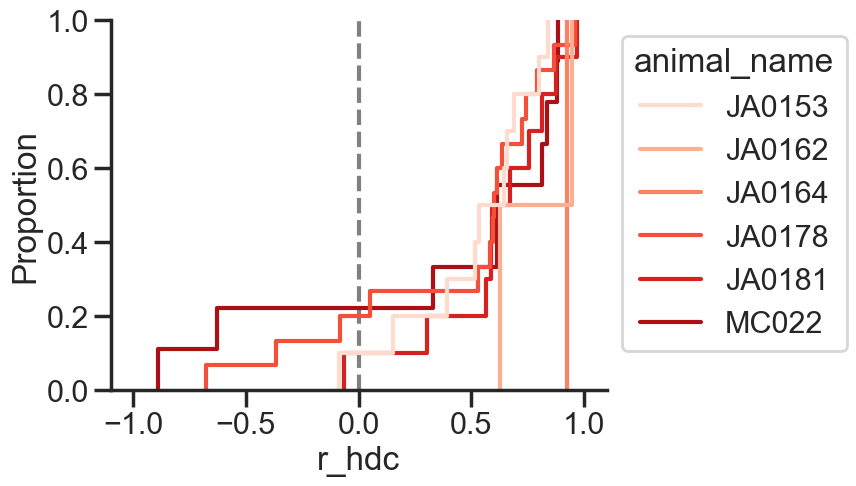

In [517]:
y = 'r_hdc'
_inp_plot = df_hr_mandyn[df_hr_mandyn.offman_ep_flag == True].groupby(['animal_name', 
                                                     'rec_id', 'ep_idx']).max().reset_index()
plt.axvline(x = 0, color = 'gray', ls = '--')

g = sns.ecdfplot(data = _inp_plot, x = y, hue = "animal_name", palette = 'Reds')
sns.move_legend(g, "upper left", bbox_to_anchor=(1, 1))

# y = 'r_nonhdc'
# g = sns.ecdfplot(data = _inp_plot, x = y, hue = "animal_name", palette = 'GnBu')
# sns.move_legend(g, "upper left", bbox_to_anchor=(1, 1))

# y = 'r_rand'
# g = sns.ecdfplot(data = _inp_plot, x = y, hue = "animal_name", palette = 'Greys')
# sns.move_legend(g, "upper left", bbox_to_anchor=(1, 1))
plt.xlim(-1.1, 1.1)
# plt.savefig(f'ecdf_hr_isomap-dyn-by-mouse_{y}.pdf', transparent = True)

(-1.1, 1.1)

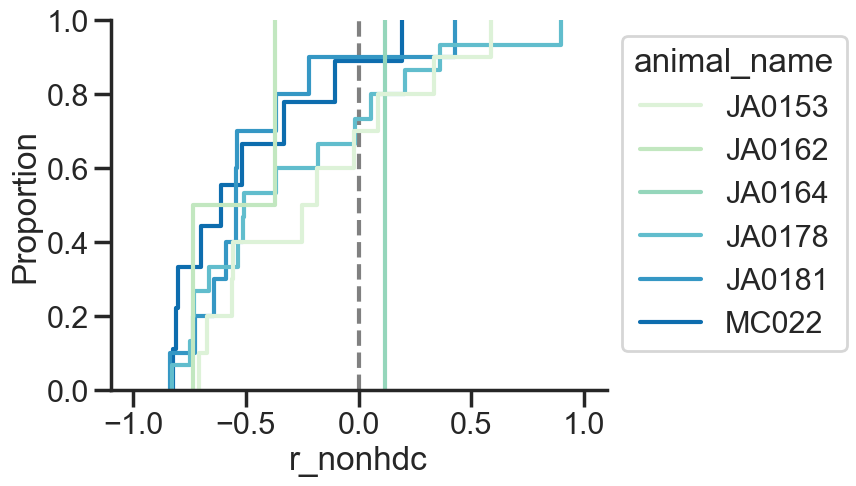

In [518]:
_inp_plot = df_hr_mandyn[df_hr_mandyn.offman_ep_flag == True].groupby(['animal_name', 
                                                     'rec_id', 'ep_idx']).max().reset_index()
plt.axvline(x = 0, color = 'gray', ls = '--')
# y = 'r_hdc'
# g = sns.ecdfplot(data = _inp_plot, x = y, hue = "animal_name", palette = 'Reds')
# sns.move_legend(g, "upper left", bbox_to_anchor=(1, 1))

y = 'r_nonhdc'
g = sns.ecdfplot(data = _inp_plot, x = y, hue = "animal_name", palette = 'GnBu')
sns.move_legend(g, "upper left", bbox_to_anchor=(1, 1))
plt.xlim(-1.1, 1.1)
# plt.savefig(f'ecdf_hr_isomap-dyn-by-mouse_{y}.pdf', transparent = True)

(-1.0, 1.0)

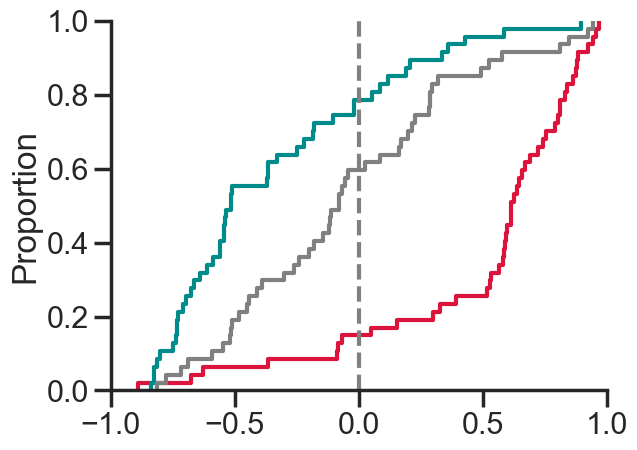

In [519]:
_inp_plot = df_hr_mandyn[df_hr_mandyn.offman_ep_flag == True].groupby(['animal_name', 
                                                                 'rec_id', 'ep_idx']).max().reset_index()

a1 = _inp_plot['r_hdc'].values
b1 = _inp_plot['r_nonhdc'].values
c1 = _inp_plot['r_rand'].values

sns.ecdfplot(a1, color = 'crimson')
sns.ecdfplot(b1, color = 'darkcyan')
sns.ecdfplot(c1, color = 'Gray')
plt.axvline(x = 0, color = 'gray', ls = '--')
plt.xlim(-1, 1)

# filepath = save_dir / f'ecdf_hr_isomap-dyn_all.pdf'
# plt.savefig(filepath, transparent = True)

In [520]:
_inp_plot.describe()

,ep_idx,r_hdc,r_nonhdc,r_rand,min_rad
count,47.000000,47.000000,47.000000,47.000000,47.000000
mean,36.638298,0.504920,-0.347166,-0.045575,0.192081
std,23.571746,0.445301,0.426822,0.455156,0.172417
min,1.000000,-0.888258,-0.837079,-0.814806,0.001462
25%,15.500000,0.454121,-0.685930,-0.426348,0.034048
50%,35.000000,0.615623,-0.515654,-0.078821,0.139133
75%,50.500000,0.807471,-0.061641,0.254911,0.362020
max,87.000000,0.967526,0.897861,0.945693,0.524892


In [521]:
print('r hdc vs nonhdc')
print(stats.ks_2samp(a1, b1))
print('r hdc vs rand')
print(stats.ks_2samp(a1, c1))
print('r rand vs nonhdc')
print(stats.ks_2samp(b1, c1))

r hdc vs nonhdc
KstestResult(statistic=0.7021276595744681, pvalue=2.1440209394916404e-11, statistic_location=0.2060327575551834, statistic_sign=-1)
r hdc vs rand
KstestResult(statistic=0.6382978723404256, pvalue=2.5904817704210756e-09, statistic_location=0.2941644611227, statistic_sign=-1)
r rand vs nonhdc
KstestResult(statistic=0.3829787234042553, pvalue=0.0018344083683356387, statistic_location=-0.5100971590133094, statistic_sign=1)


In [522]:
_inp_plot.to_excel(filepath, index=True)

## Lin vel vs manifold radius timecourse

In [523]:
from scipy.optimize import curve_fit
def sigmoid(t, t0, k, base, amplitude):
    """
    Logistic sigmoid.
    t0        : midpoint / inflection point (seconds)
    k         : steepness (s^-1)
    base      : value before rise
    amplitude : total rise
    """
    return base + amplitude / (1 + np.exp(-k * (t - t0)))


def fit_sigmoid(t, signal, p0=None):
    """Fit sigmoid and return (params, covariance, fitted_curve)."""
    if p0 is None:
        t0_guess = t[len(t) // 2]
        k_guess = 3.0
        base_guess = signal[:5].mean()
        amp_guess = signal[-5:].mean() - base_guess
        p0 = [t0_guess, k_guess, base_guess, amp_guess]
    try:
        popt, pcov = curve_fit(sigmoid, t, signal, p0=p0,
                               maxfev=10000,
                               bounds=([-np.inf, 0.1, -np.inf, -np.inf],
                                       [np.inf, 50, np.inf, np.inf]))
        fitted = sigmoid(t, *popt)
        return popt, pcov, fitted
    except RuntimeError:
        print("  WARNING: sigmoid fit did not converge.")
        return None, None, np.full_like(signal, np.nan)



In [524]:
def is_good_epoch(t, signal, popt, pcov, fit, label=''):
    perr = np.sqrt(np.diag(pcov))
    
    # 1. Parameter uncertainty on t0 (your proposed criterion)
    t0_err_ok = perr[0] < 0.4          # t0 uncertain by less than 300 ms
    
    # 2. t0 must be within the time window (catch runaway fits)
    t0_in_window = t[0] < popt[0] < t[-1]
    
    # 3. Amplitude must be in the right direction and meaningful
    amp_ok = popt[3] > 0               # signal rises, not falls
    
    # 4. Goodness of fit: R²
    ss_res = np.sum((signal - fit)**2)
    ss_tot = np.sum((signal - signal.mean())**2)
    r2 = 1 - ss_res / ss_tot
    r2_ok = r2 > 0.4
    
    # 5. Steepness sanity (not a cliff, not flat)
    k_ok = 0.5 < popt[1] < 50
    
    passed = t0_err_ok and t0_in_window and amp_ok and r2_ok and k_ok
    return passed, {'perr_t0': perr[0], 'r2': r2, 'k': popt[1], 
                    't0': popt[0], 'amp': popt[3]}

In [525]:
def test_xcorr_significance(speed, radius, n_shuffles=500, fs=10, to_plot = False):
    """
    Test if cross-correlation peak between speed and radius is statistically significant.
    
    Parameters:
    speed, radius - The two time series to correlate
    n_shuffles - Number of shuffles for null distribution
    fs - Sampling frequency in Hz
    
    Returns:
    is_significant - Boolean indicating if peak is significant (p < 0.05)
    p_value - Empirical p-value
    lag_seconds - Lag at peak in seconds
    """
    # Function to compute maximum cross-correlation
    def compute_xcorr_peak(a, b):
        # Mean-center and compute cross-correlation
        a_centered = a - np.mean(a)
        b_centered = b - np.mean(b)
        xcorr = np.correlate(a_centered, b_centered, mode='full')
        return np.max(np.abs(xcorr))
    
    # Compute actual cross-correlation
    xcorr_actual = np.correlate(speed - np.mean(speed), radius - np.mean(radius), mode='full')
    actual_peak = np.max(np.abs(xcorr_actual))
    
    # Find lag at peak
    peak_idx = np.argmax(np.abs(xcorr_actual))
    lag = peak_idx - (len(speed) - 1)
    lag_seconds = lag / fs
    
    # Perform shuffling test
    shuffle_peaks = np.empty(n_shuffles)
    for i in range(n_shuffles):
        # Randomly shuffle the radius signal
        radius_shuffled = np.random.permutation(radius)
        shuffle_peaks[i] = compute_xcorr_peak(speed, radius_shuffled)
    
    # Compute empirical p-value
    p_value = np.mean(shuffle_peaks >= actual_peak)
    is_significant = p_value < 0.05
    
    # Create simple diagnostic plot
    if to_plot == True:
        plt.figure(figsize=(8, 5))
        plt.hist(shuffle_peaks, bins=10, alpha=0.7, color='gray', label='Null distribution')
        plt.axvline(x=actual_peak, color='red', linestyle='--', 
                    label=f'Observed peak (p={p_value:.3f})')
        plt.xlabel('Peak Cross-Correlation')
        plt.ylabel('Frequency')
        plt.title(f'Lag: {lag_seconds:.3f} seconds')
        plt.legend()
    
    return is_significant, p_value, lag_seconds

#### Extract epochs using stat/run

In [527]:
d_run_onset = {}

20220126_JA0153_lightHR1, ep idx: 41, circmean 201.13077356778888, circstd 11.408500343540915 min rad 0.27601542165580784
len 215, std: 1.67, idx: 2069 - 2109
bad epoch (False, {'perr_t0': 0.35994810785416526, 'r2': 0.7391490809430349, 'k': 1.3016630233838402, 't0': 0.0072163961691083895, 'amp': 12.314503425675447}) (True, {'perr_t0': 0.13116986905806788, 'r2': 0.9003525097624444, 'k': 2.1790154003093627, 't0': 0.5263094758847832, 'amp': 0.36003418380451124})
20220302_JA0162_lightHR1, ep idx: 45, circmean 217.15079124941744, circstd 2.505555780445354 min rad 0.39334597101027297
len 430, std: 4.89, idx: 1824 - 1864
good epoch (True, {'perr_t0': 0.05059774258385106, 'r2': 0.7673779945387593, 'k': 20.714401459420714, 't0': 0.1292037004983629, 'amp': 6.5565572527891165}) (True, {'perr_t0': 0.036113422541523, 'r2': 0.9379567285392122, 'k': 9.167536841808545, 't0': 0.16337850719357225, 'amp': 0.1506546197028122})
Speed  sigmoid midpoint  t0 = +0.129 s  (±0.051)
Radius sigmoid midpoint  t0 = 

C:\Users\01\anaconda3\envs\py39\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


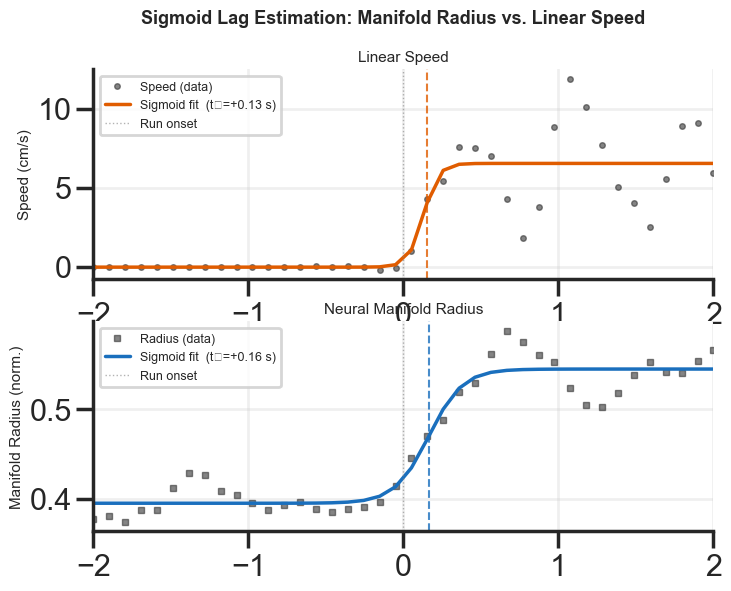

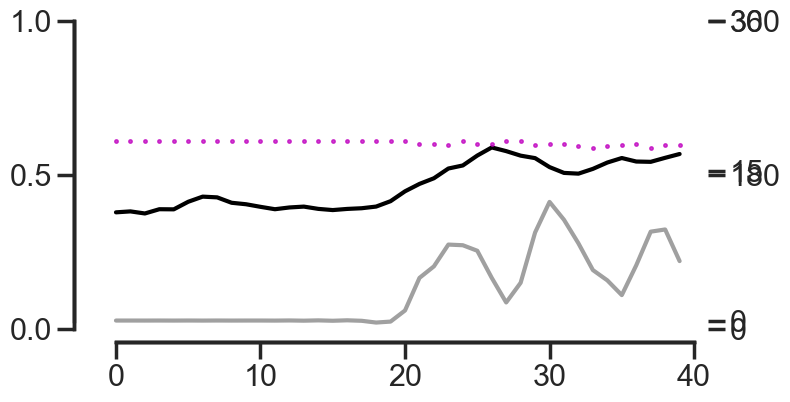

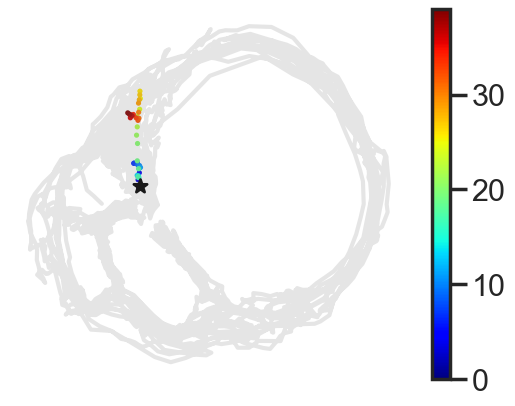


20220302_JA0162_lightHR1, ep idx: 60, circmean 201.5995424827472, circstd 1.881197919492108 min rad 0.32348322699313964
len 70, std: 1.98, idx: 2264 - 2304
good epoch (True, {'perr_t0': 0.0363111005494708, 'r2': 0.8731681116197734, 'k': 19.80671568992728, 't0': 0.10395069633805464, 'amp': 5.837309891994187}) (True, {'perr_t0': 0.048335829021413576, 'r2': 0.9269793419723614, 'k': 5.893759435670169, 't0': -0.7343345515517646, 'amp': 0.18178419515022995})
Speed  sigmoid midpoint  t0 = +0.104 s  (±0.036)
Radius sigmoid midpoint  t0 = -0.734 s  (±0.048)
Estimated lag (radius - speed): -888.2 ms


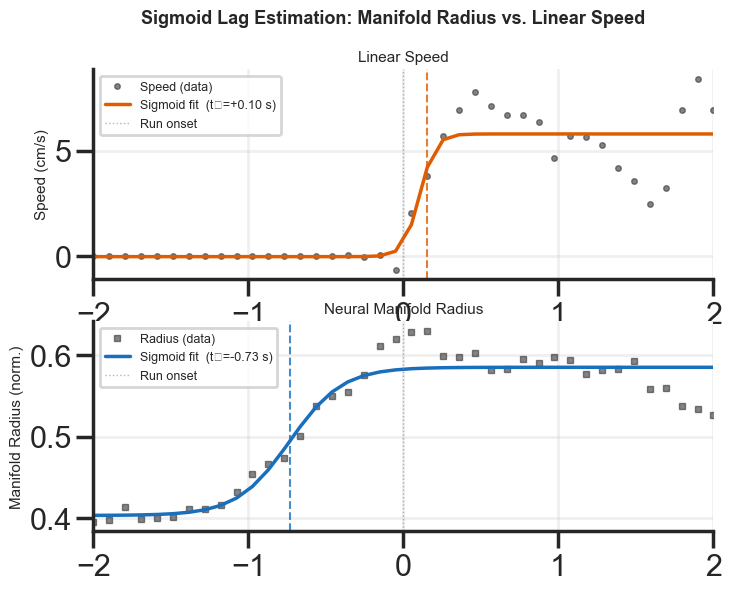

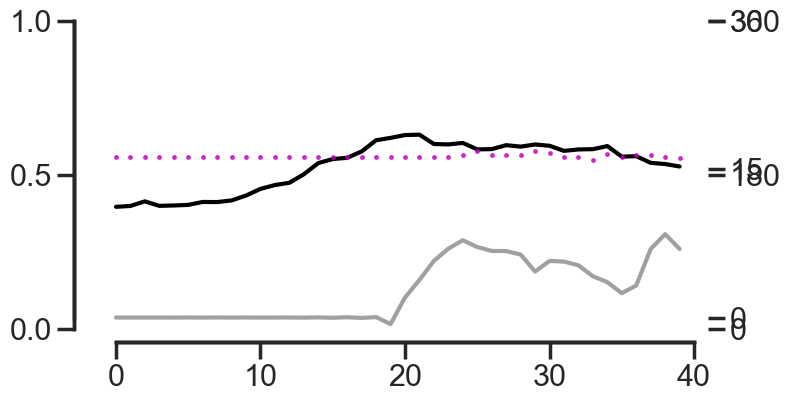

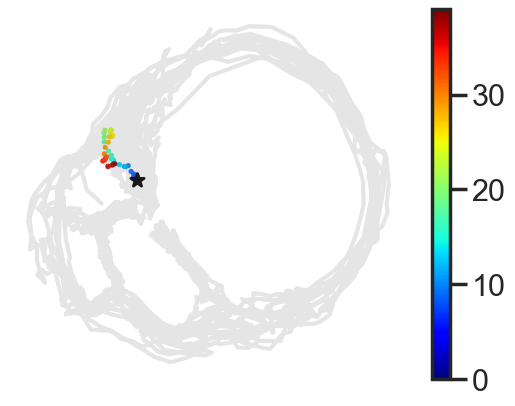


20220302_JA0162_lightHR1, ep idx: 63, circmean 201.37511697052798, circstd 2.352504932042013 min rad 0.3408801619375111
len 50, std: 1.35, idx: 2349 - 2389
good epoch (True, {'perr_t0': 0.07346522072599303, 'r2': 0.7306608516055948, 'k': 12.200951214875433, 't0': 0.03268593182461662, 'amp': 4.319196926083266}) (True, {'perr_t0': 0.06130957969080097, 'r2': 0.9585372704301182, 'k': 2.9406530001340156, 't0': -0.6280697526993114, 'amp': 0.21313702916859828})
Speed  sigmoid midpoint  t0 = +0.033 s  (±0.073)
Radius sigmoid midpoint  t0 = -0.628 s  (±0.061)
Estimated lag (radius - speed): -679.4 ms


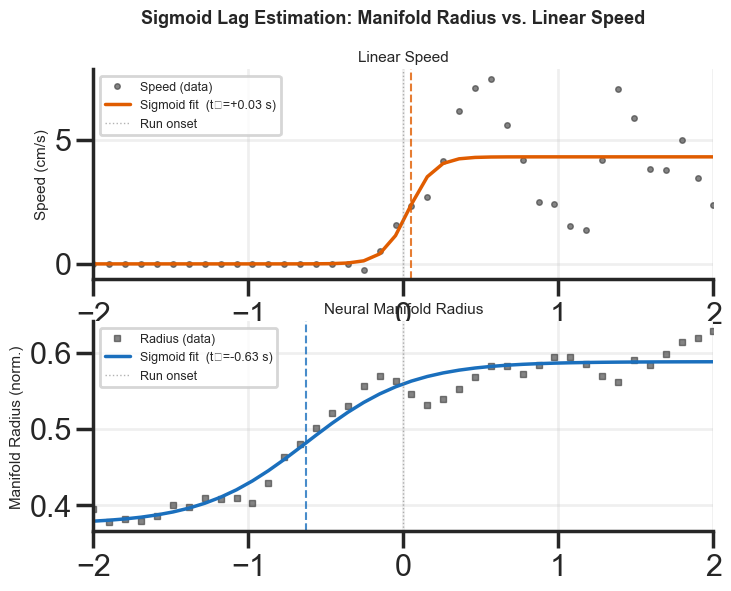

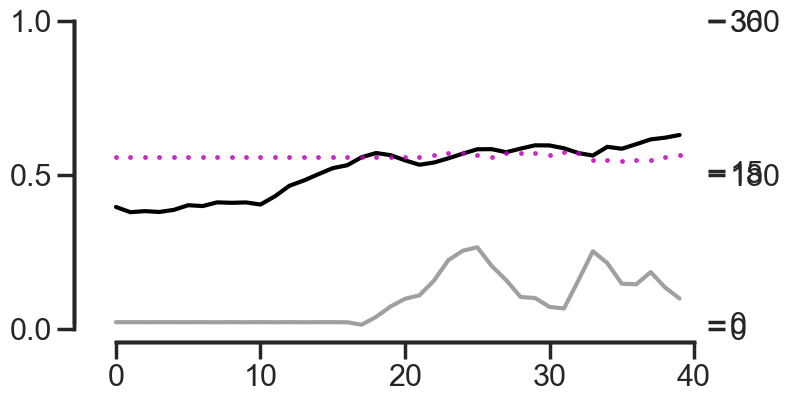

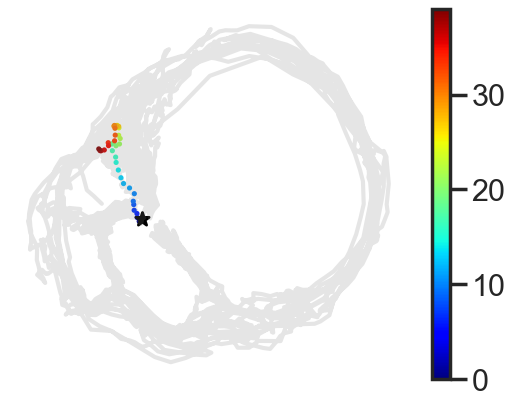


20220302_JA0162_lightHR1, ep idx: 64, circmean 205.99020128474913, circstd 7.228808967321798 min rad 0.5155643675875472
len 160, std: 4.03, idx: 2514 - 2554
good epoch (True, {'perr_t0': 0.03399199422043299, 'r2': 0.8148567600563349, 'k': 29.08696929803094, 't0': 0.056100471850581146, 'amp': 4.565827526681736}) (True, {'perr_t0': 0.031660586686588235, 'r2': 0.969412789583359, 'k': 5.871667896270467, 't0': -0.33029703415878486, 'amp': 0.21221921750053988})
Speed  sigmoid midpoint  t0 = +0.056 s  (±0.034)
Radius sigmoid midpoint  t0 = -0.330 s  (±0.032)
Estimated lag (radius - speed): -381.6 ms


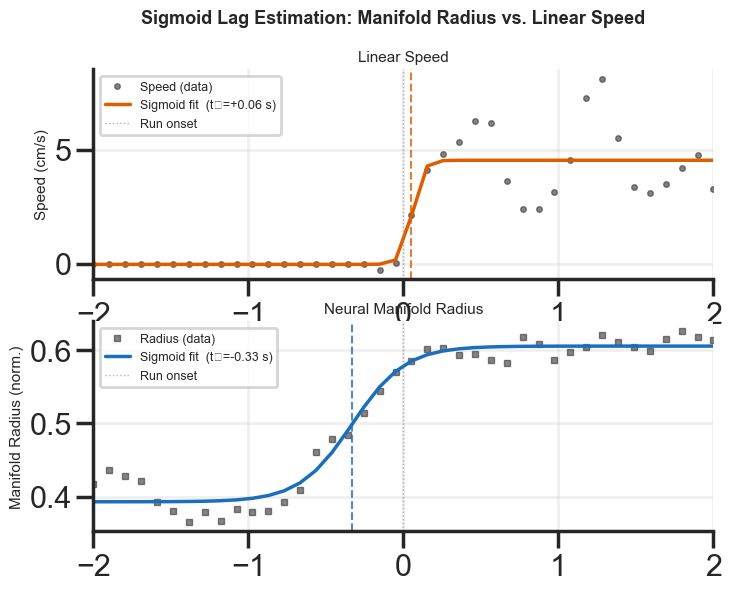

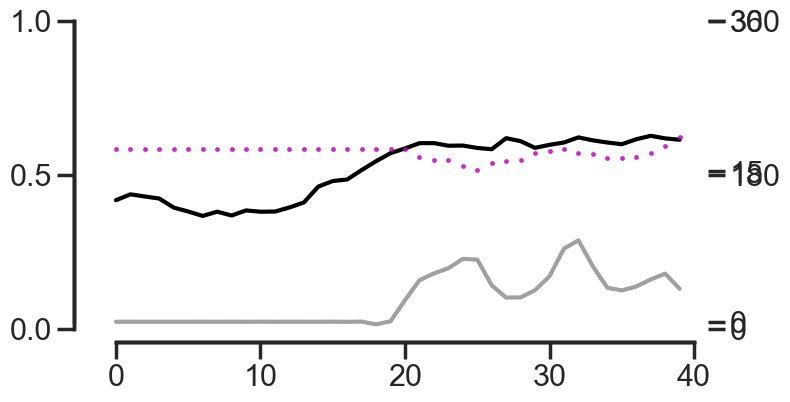

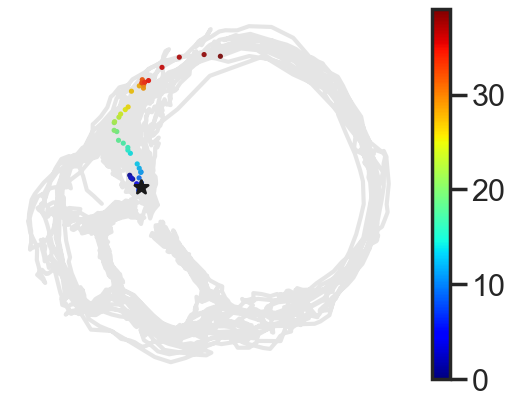


20220302_JA0162_lightHR1, ep idx: 88, circmean 38.75589993370238, circstd 13.73476440194642 min rad 0.5426789697586162
len 155, std: 5.58, idx: 3959 - 3999
bad epoch (True, {'perr_t0': 0.11562047486152463, 'r2': 0.5326096352281091, 'k': 49.99999999999932, 't0': -0.03868302751294965, 'amp': 3.84563053544914}) (False, {'perr_t0': 0.36726295943287757, 'r2': 0.8704867811137769, 'k': 1.467652900111318, 't0': -0.8932018261232644, 'amp': 0.40044508529175965})
20220815_JA0181_lightHR1, ep idx: 4, circmean 191.10900259507028, circstd 13.509430226581388 min rad 0.4274888199178195
len 60, std: 2.33, idx: 1054 - 1094
good epoch (True, {'perr_t0': 0.11979024821910599, 'r2': 0.542271572509345, 'k': 49.99999999979585, 't0': 0.03675670567311878, 'amp': 5.488851221881643}) (True, {'perr_t0': 0.08912447480563339, 'r2': 0.708270282992491, 'k': 8.035464173541795, 't0': -0.9109114471466797, 'amp': 0.2059480107034378})
Speed  sigmoid midpoint  t0 = +0.037 s  (±0.120)
Radius sigmoid midpoint  t0 = -0.911 s 

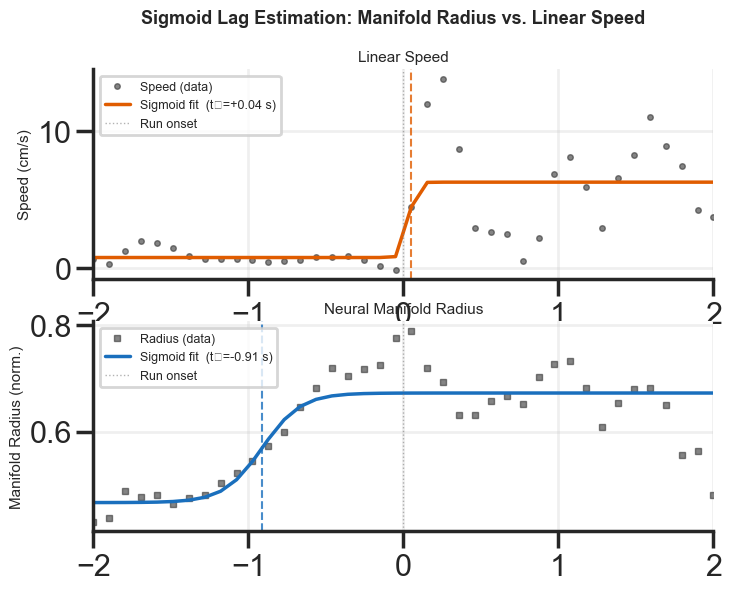

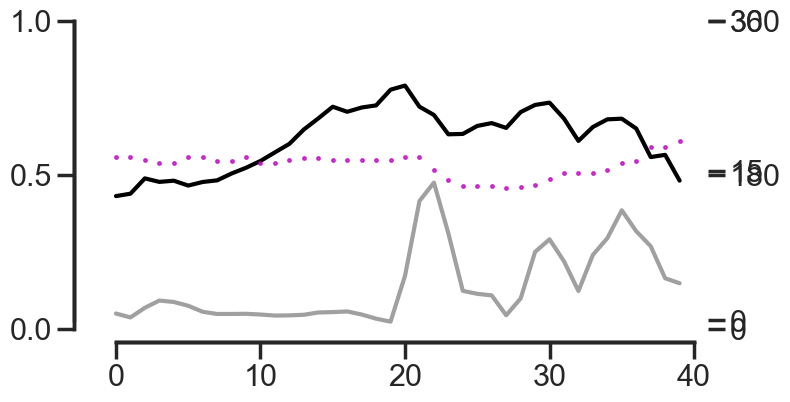

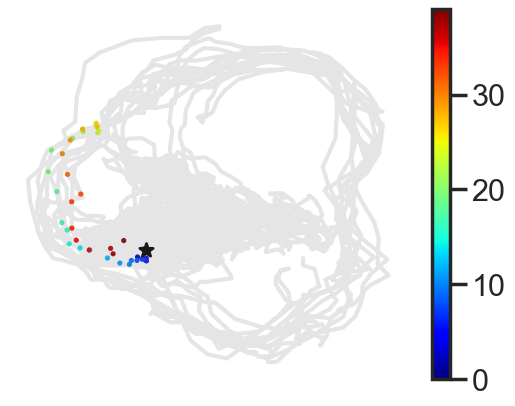


20220712_MC022_lightHR1, ep idx: 12, circmean 129.77505593177804, circstd 11.169741848559768 min rad 0.4619271799096692
len 115, std: 0.99, idx: 609 - 649
good epoch (True, {'perr_t0': 0.12575837379440022, 'r2': 0.45947878094815164, 'k': 49.999999949617155, 't0': -0.4729959613973064, 'amp': 5.494182229082591}) (True, {'perr_t0': 0.21972665451519094, 'r2': 0.5041723979053931, 'k': 4.33130974174245, 't0': -1.05954609939131, 'amp': 0.17522117956034755})
Speed  sigmoid midpoint  t0 = -0.473 s  (±0.126)
Radius sigmoid midpoint  t0 = -1.060 s  (±0.220)
Estimated lag (radius - speed): -598.0 ms


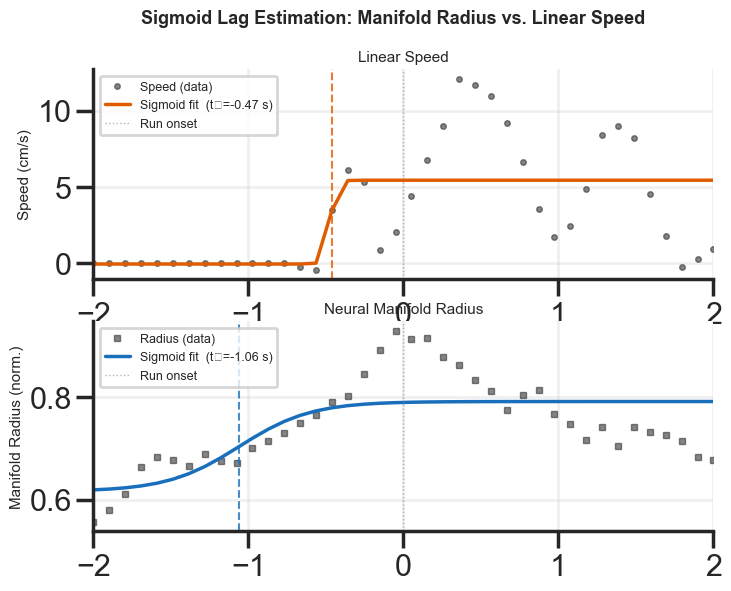

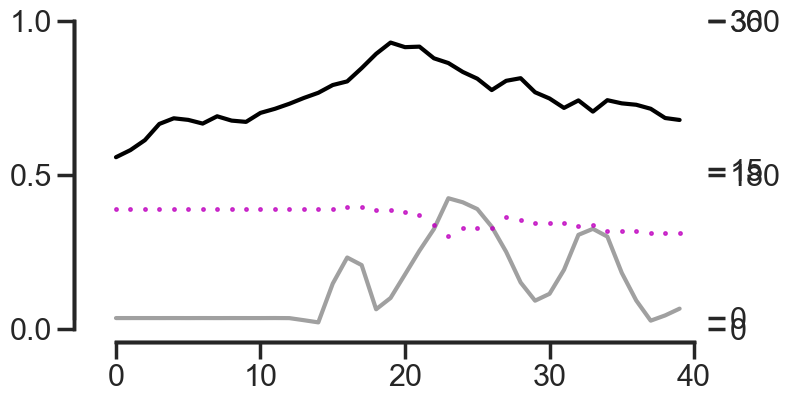

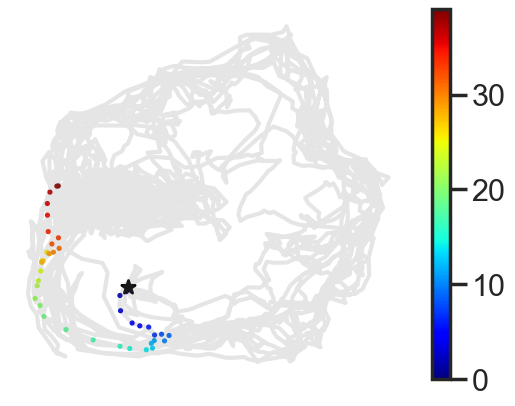


20220126_JA0153_darkHR1, ep idx: 16, circmean 188.54556858518447, circstd 14.279717780647054 min rad 0.16175338188391425
len 130, std: 1.13, idx: 1409 - 1449
bad epoch (False, {'perr_t0': 0.36922115310388404, 'r2': 0.8700634673259424, 'k': 1.7875723111307924, 't0': 1.2324607700514985, 'amp': 32.1150828168346}) (True, {'perr_t0': 0.05547199788207786, 'r2': 0.8907606175663217, 'k': 7.046596334187838, 't0': -0.5158743600850197, 'amp': 0.46725223383136555})
20220126_JA0153_darkHR1, ep idx: 22, circmean 126.98351901438846, circstd 6.620247778847675 min rad 0.28948935050341645
len 175, std: 9.1, idx: 1799 - 1839
good epoch (True, {'perr_t0': 0.10265077360463686, 'r2': 0.41865845331398743, 'k': 43.65878931342027, 't0': 0.16588863152400884, 'amp': 15.992605069507555}) (True, {'perr_t0': 0.252811033611428, 'r2': 0.936703019470521, 'k': 1.9639362037837362, 't0': -1.3897784750941384, 'amp': 0.43341822772559363})
Speed  sigmoid midpoint  t0 = +0.166 s  (±0.103)
Radius sigmoid midpoint  t0 = -1.39

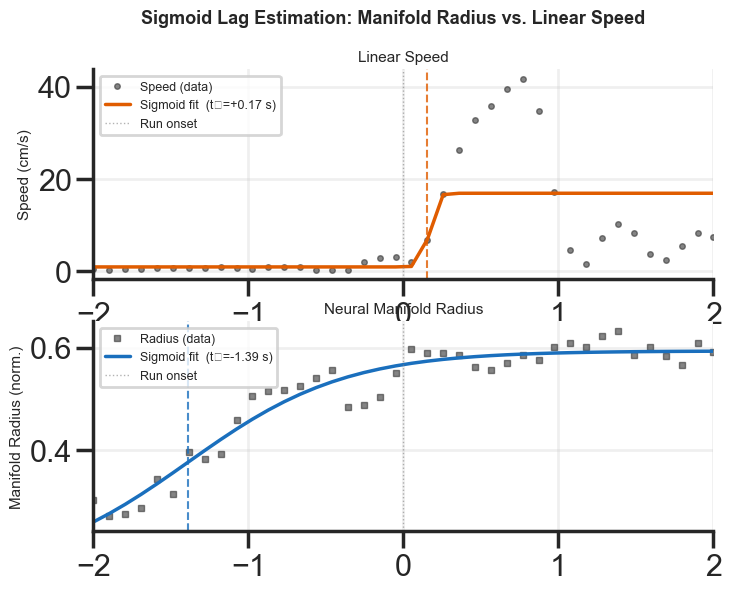

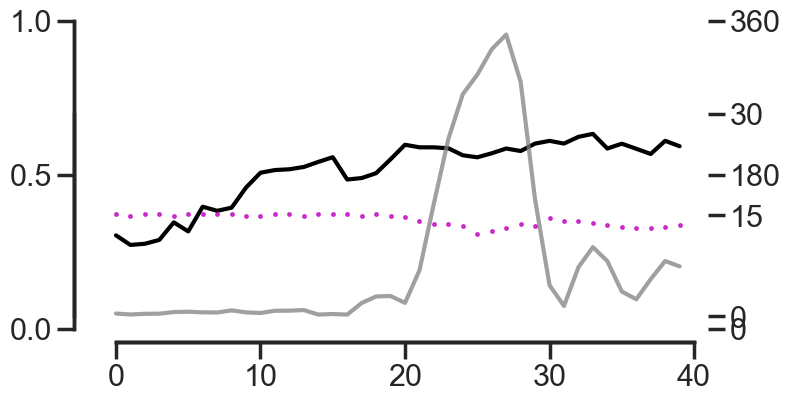

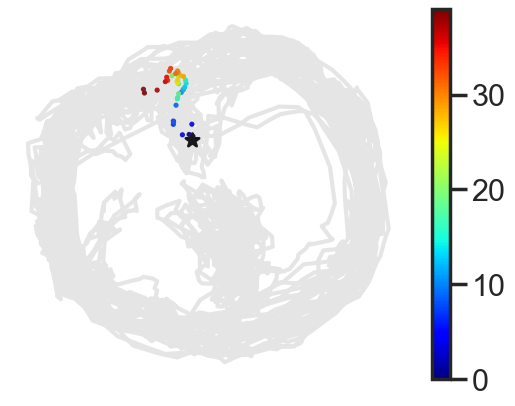


20220302_JA0162_darkHR1, ep idx: 23, circmean 206.54947931077464, circstd 4.455832949717459 min rad 0.14577741475206318
len 85, std: 2.68, idx: 1524 - 1564
bad epoch (False, {'perr_t0': 0.6589301518424392, 'r2': 0.2062038586855428, 'k': 3.61893997961262, 't0': -1.333031582903622, 'amp': 3.3265072169689307}) (True, {'perr_t0': 0.1303031160342229, 'r2': 0.7472704028283678, 'k': 4.1184662558870935, 't0': 0.8587401634732008, 'amp': 0.12733645368995422})
20220302_JA0162_darkHR1, ep idx: 36, circmean 146.55975522006992, circstd 6.88320085801345 min rad 0.23433412866578215
len 240, std: 12.8, idx: 2099 - 2139
good epoch (True, {'perr_t0': 0.07470809724327646, 'r2': 0.6950072532313278, 'k': 13.935379149680925, 't0': 0.11598053364727512, 'amp': 4.115273728906722}) (True, {'perr_t0': 0.1542945525688681, 'r2': 0.5061653187456743, 'k': 6.861445913740249, 't0': -0.7668921786485319, 'amp': 0.19706629566036232})
Speed  sigmoid midpoint  t0 = +0.116 s  (±0.075)
Radius sigmoid midpoint  t0 = -0.767 s 

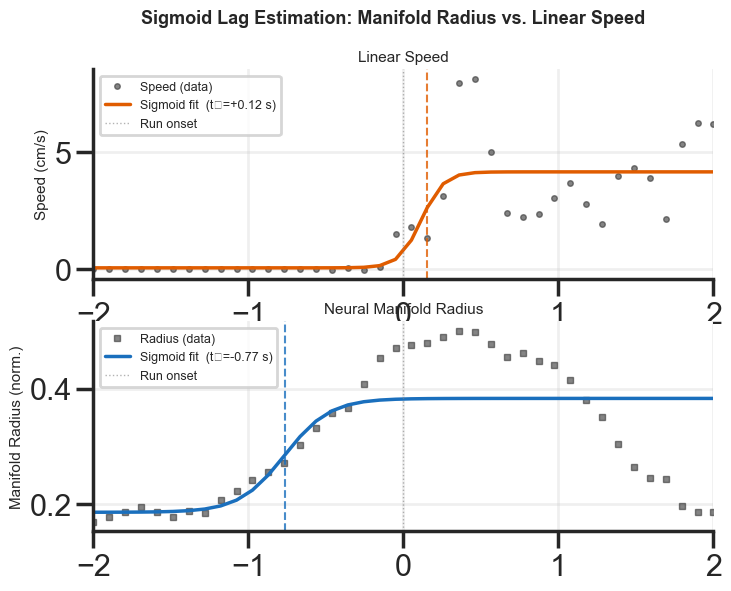

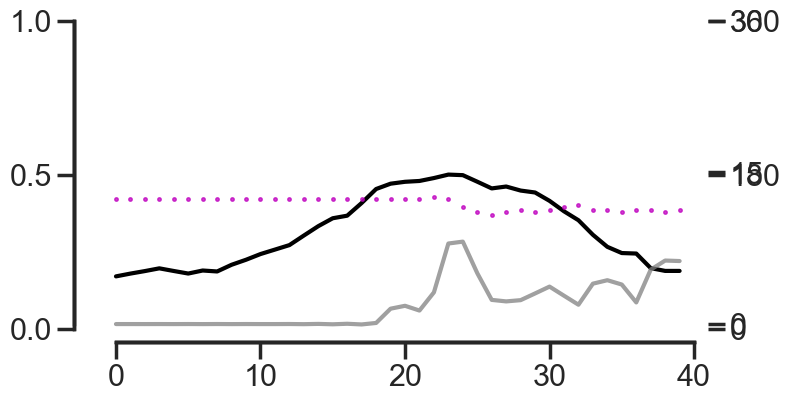

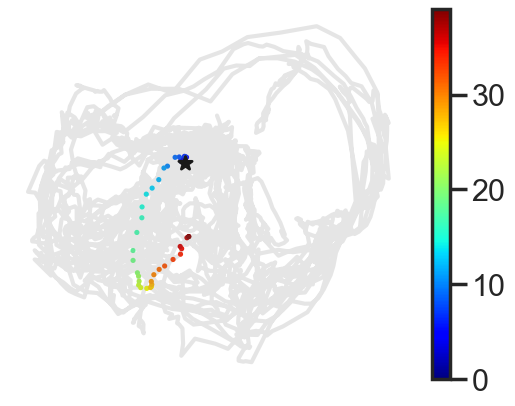


20220302_JA0162_darkHR1, ep idx: 41, circmean 131.3801458175364, circstd 9.510799700719895 min rad 0.335924912135506
len 500, std: 3.97, idx: 2924 - 2964
good epoch (True, {'perr_t0': 0.03645933256587686, 'r2': 0.8472593692447932, 'k': 22.386244390974372, 't0': -0.2660512877026263, 'amp': 5.796888385315755}) (True, {'perr_t0': 0.024696513983747358, 'r2': 0.979635472436959, 'k': 6.309571096206461, 't0': -0.30528931172114304, 'amp': 0.40196286045074353})
Speed  sigmoid midpoint  t0 = -0.266 s  (±0.036)
Radius sigmoid midpoint  t0 = -0.305 s  (±0.025)
Estimated lag (radius - speed): -48.9 ms


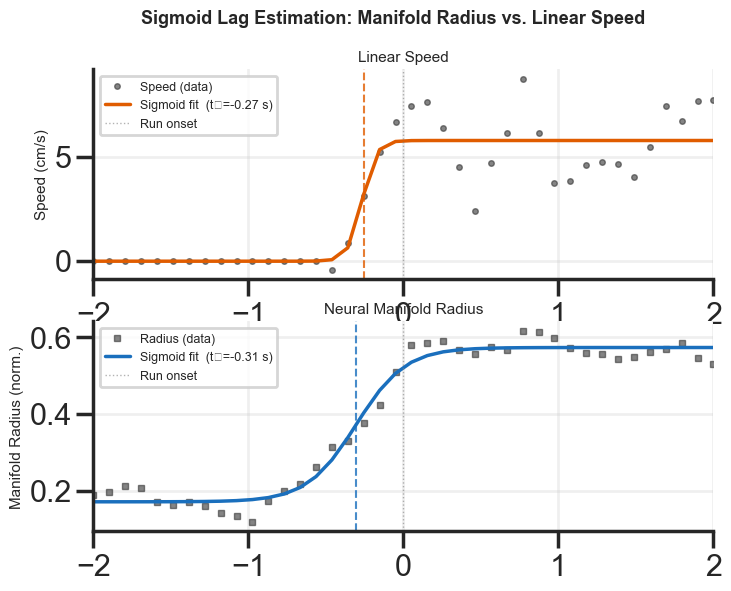

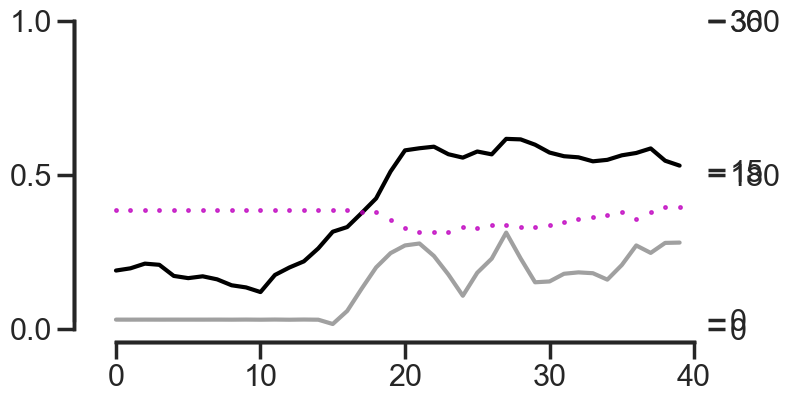

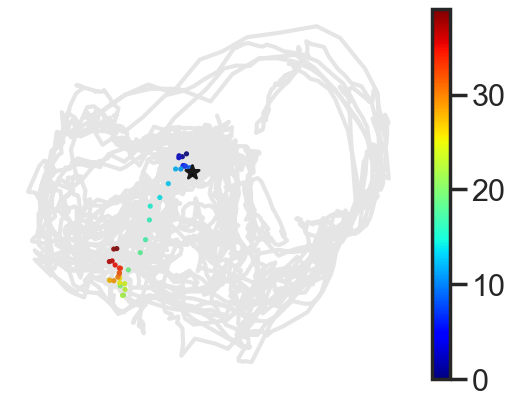


20220302_JA0162_darkHR1, ep idx: 65, circmean 302.1609248149504, circstd 7.419932767732687 min rad 0.08737849735235455
len 50, std: 2.75, idx: 4234 - 4274
bad epoch (True, {'perr_t0': 0.1475464039227331, 'r2': 0.6761268072181805, 'k': 4.333566790358574, 't0': -0.5108591644664914, 'amp': 4.528513891723673}) (False, {'perr_t0': 5.254563507946076, 'r2': 0.8509635256371412, 'k': 0.973229336984273, 't0': -3.1752361649931498, 'amp': 0.8841201128905378})
20220822_JA0178_darkHR1, ep idx: 42, circmean 343.79301276134754, circstd 9.475602229325109 min rad 0.46805810095118644
len 115, std: 68.8, idx: 1944 - 1984
bad epoch (True, {'perr_t0': 0.12199451811149063, 'r2': 0.5405673103230035, 'k': 49.9999999999999, 't0': -0.08294101570400567, 'amp': 5.860613065002755}) (False, {'perr_t0': 1.3536575227405474, 'r2': 0.9096251027299391, 'k': 0.9648836584262126, 't0': -1.7483268753367098, 'amp': 0.5663807899758321})
20220815_JA0181_darkHR1, ep idx: 9, circmean 220.86306417857884, circstd 6.71102746608554 

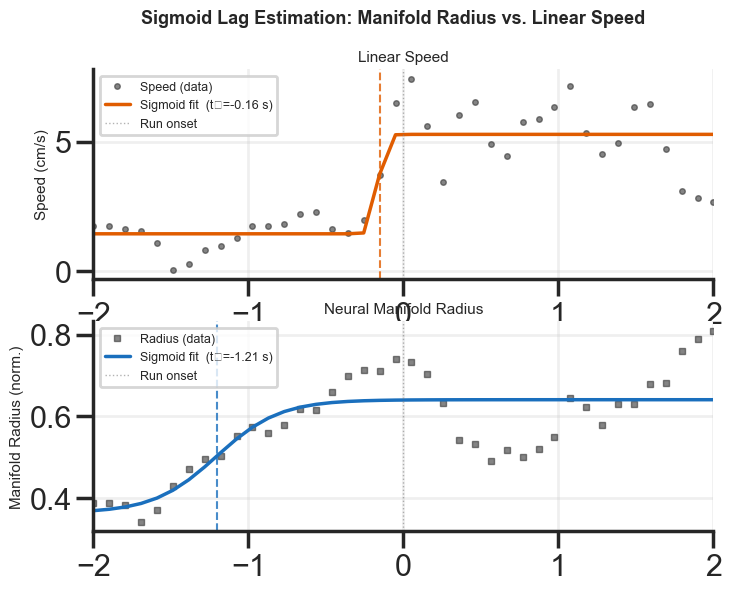

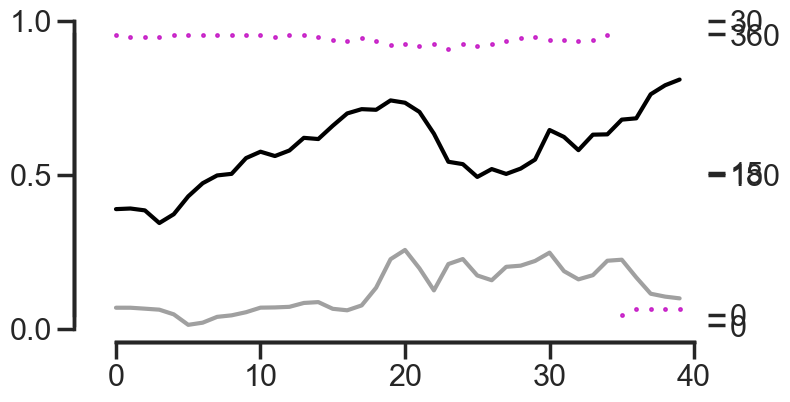

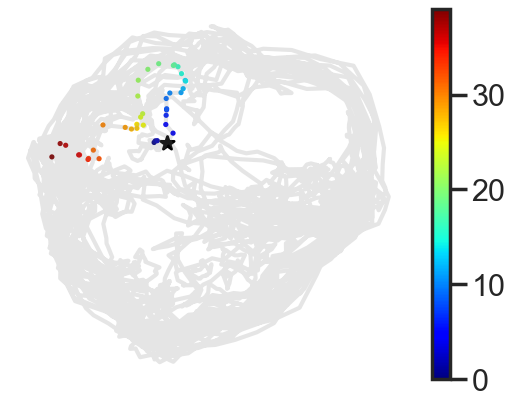


20220818_JA0181_darkHR1, ep idx: 112, circmean 248.74937262955757, circstd 11.26544882937501 min rad 0.2831988047437175
len 90, std: 1.76, idx: 3979 - 4019
good epoch (True, {'perr_t0': 0.07099863280392248, 'r2': 0.6123053735555952, 'k': 49.9999999999956, 't0': 0.05825882556179573, 'amp': 4.537445712295941}) (True, {'perr_t0': 0.042819616455185394, 'r2': 0.9283222025386888, 'k': 7.744886907579844, 't0': -0.08979736808584227, 'amp': 0.4239417043405121})
Speed  sigmoid midpoint  t0 = +0.058 s  (±0.071)
Radius sigmoid midpoint  t0 = -0.090 s  (±0.043)
Estimated lag (radius - speed): -243.6 ms


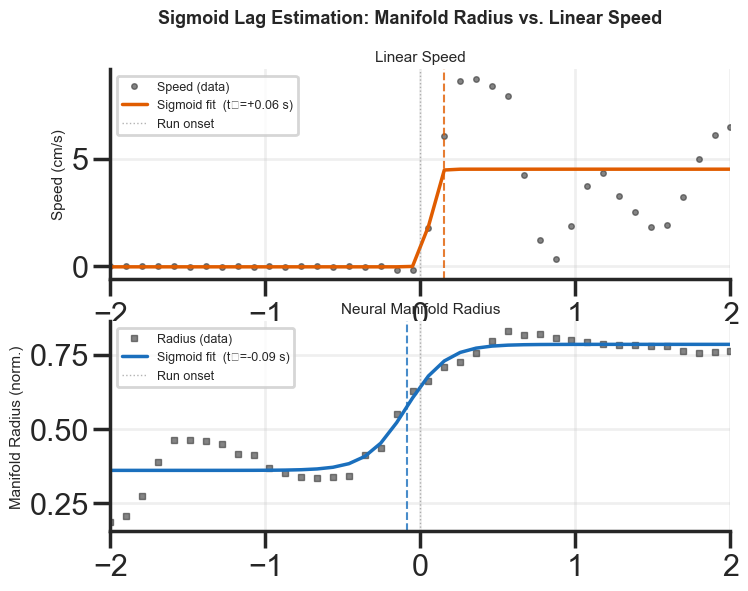

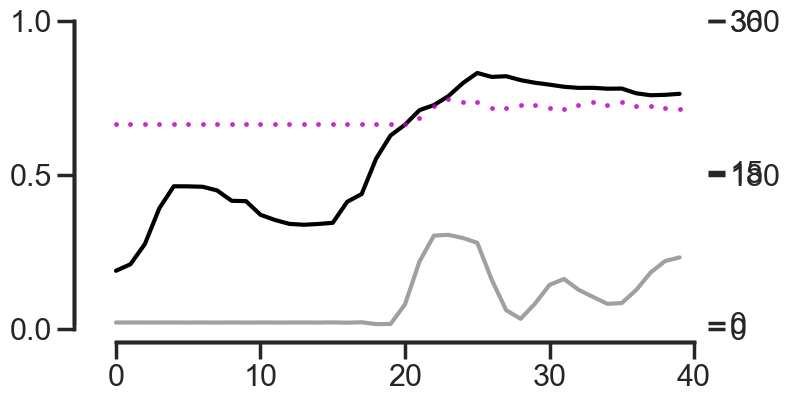

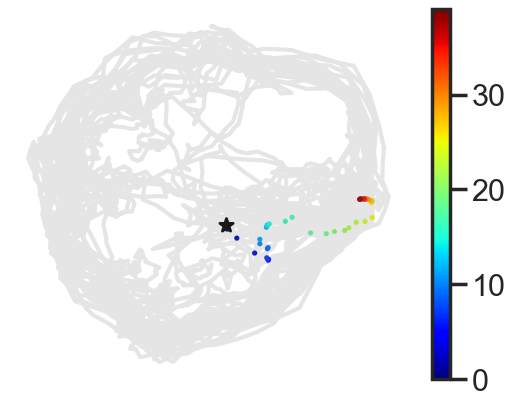


20220818_JA0181_darkHR1, ep idx: 119, circmean 36.594445969609616, circstd 10.45759300864278 min rad 0.39240255262229545
len 130, std: 1.34, idx: 4229 - 4269
good epoch (True, {'perr_t0': 0.12038366717710595, 'r2': 0.49585194408011013, 'k': 12.51547916001137, 't0': -0.03561094450362974, 'amp': 4.3429250289025285}) (True, {'perr_t0': 0.07982002774500796, 'r2': 0.9007071947098363, 'k': 3.624963755654106, 't0': -0.21047886552836018, 'amp': 0.3258596716198323})
Speed  sigmoid midpoint  t0 = -0.036 s  (±0.120)
Radius sigmoid midpoint  t0 = -0.210 s  (±0.080)
Estimated lag (radius - speed): -159.2 ms


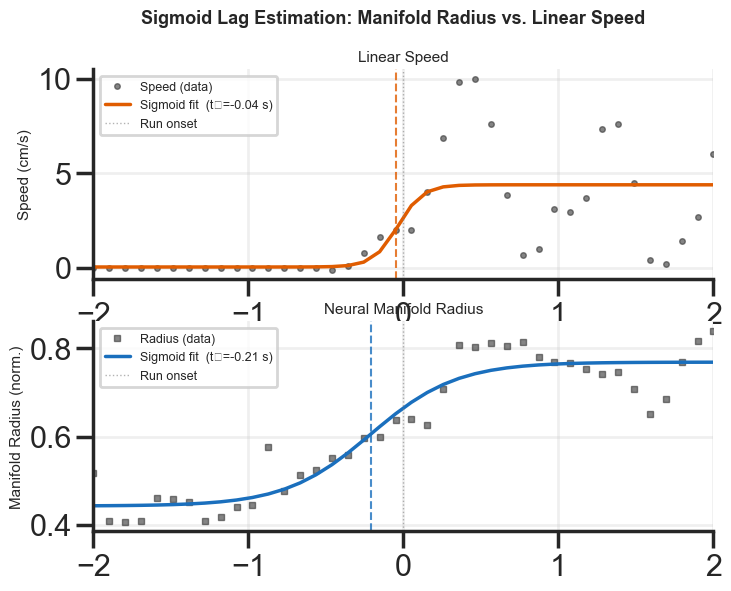

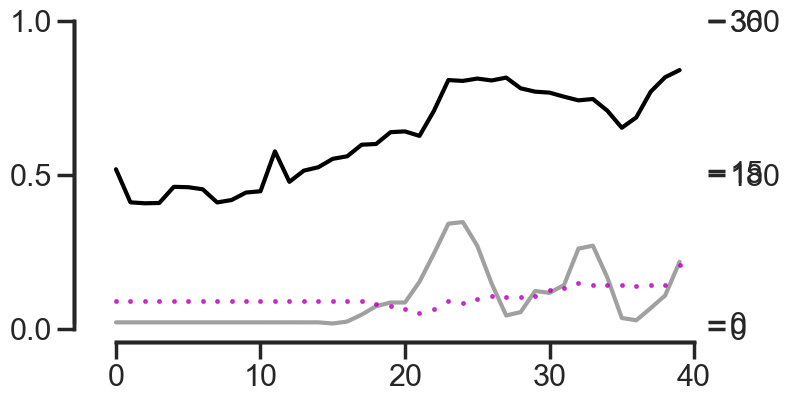

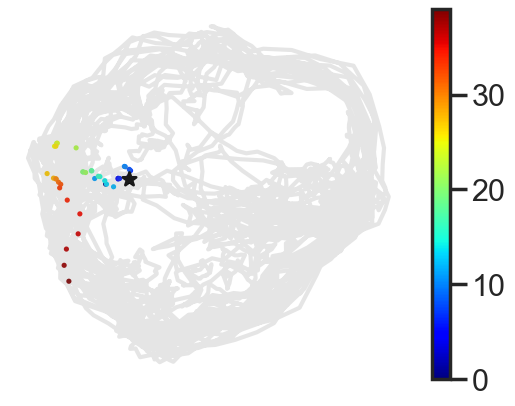

,rec_id,epoch,aligned_speed,speed_onset_t,fit_s,lag,aligned_yaw,aligned_radius,fit_r,t0_radius,time
0,20220302_JA0162_lightHR1,45,-0.000157,0.153846,-0.02473,0.009532,219.0,0.377413,0.394726,0.163379,-2.000000
1,20220302_JA0162_lightHR1,45,0.000635,0.153846,-0.02473,0.009532,219.0,0.380499,0.394726,0.163379,-1.897436
2,20220302_JA0162_lightHR1,45,-0.001241,0.153846,-0.02473,0.009532,219.0,0.373732,0.394726,0.163379,-1.794872
3,20220302_JA0162_lightHR1,45,0.001923,0.153846,-0.02473,0.009532,219.0,0.387532,0.394726,0.163379,-1.692308
4,20220302_JA0162_lightHR1,45,-0.002592,0.153846,-0.02473,0.009532,219.0,0.387153,0.394726,0.163379,-1.589744


In [23]:
ls_pref, ls_nonpref, ls_rand = [], [], []
ls_df = []
pref_dir_thr = 45 
speed_thr = 5
ep_offset = 30
to_plot = True
# 25s
ep_end = 40
n_samples = 40   # samples per epoch
t = np.linspace(-2, 2, n_samples)   # 4 s window centred on run onset
ls_lag, ls_df = [], []

for k in d_hr_emb.keys():

    if 'HR1' not in k:
        continue
    d_run_onset[k] = {}
    aligned_speed, aligned_yaw, aligned_radius = [], [], []

    
    dts, animal_name, cond = k.split('_')[-3:]
    rec_session = animal_name + '_' + dts
    tmp = d_hr_emb[k]
    isomap = tmp['isomap']
    measured_yaw = tmp['measured_yaw'] + 180
    isomap_yaw, dec_err, _ = decode_az_isomap(isomap[:, 0], isomap[:, 1], measured_yaw[:])
    dyaw = compute_dYaw(measured_yaw)
    # sampling 10 Hz, 100ms
    ang_vel = dyaw*100
    lin_speed = tmp['lin_vel']
    _, rad_manifold = compute_radius(isomap[:,0], isomap[:,1])
    rad_manifold_norm = rad_manifold/rad_manifold.max()
    
    # find stat, run, rot epochs
    try:
        stat_idx, run_idx = get_stat_run_epochs(lin_speed, window_size=5, speed_thr = 5)
        _, rot_idx = get_stat_run_epochs(ang_vel, window_size=5, speed_thr = 2)
    except:
        continue
    # get stat epochs
    stat_epoch = consecutive(stat_idx)
    run_epoch = consecutive(run_idx)
    
    for ep_idx, ep in enumerate(stat_epoch):
        # at least 3s and no change in az
        if (len(ep) > 40):
            # if ep_idx != 114:
            #     continue
            start, end = ep[-1]-20, ep[-1] + 20
            if ep.size > 250:
                end = start + ep_end
            if rad_manifold_norm[start:end].max() - rad_manifold_norm[start:end].min() > 0.2:
                offman_ep_flag = True
            else:
                continue
            if ep[0] - ep_offset < 1:
                continue
                
            angles = np.deg2rad(measured_yaw[start:end])
            circstd = stats.circstd(angles)
            circmean = stats.circmean(angles)
            circstd = np.rad2deg(circstd)
            this_yaw = np.rad2deg(circmean)
           
            if circstd > 15:
                # print(f'High circ std {circstd}')
                continue
            baseline_speed = lin_speed[start:ep[-1]].mean()
            onset_speed = lin_speed[ep[-1]: ep[-1] + 5].mean()
            if  baseline_speed > 2 or onset_speed < 4:
                # print(f'Base lin speed {baseline_speed}, onset {onset_speed}')
                continue
            if angles.size != 40:
                continue
            print(f'{k}, ep idx: {ep_idx}, circmean {this_yaw}, circstd {circstd} min rad {rad_manifold_norm[ep[:ep_end]].min()}')
            print(f'len {len(ep)}, std: {round(np.std(measured_yaw[ep]), 2)}, idx: {start} - {end}')
            offset = rad_manifold_norm[start:end].argmin()

            # Convert to arrays
            # aligned_speed.append(lin_speed[start:end])
            # aligned_radius.append(rad_manifold_norm[start:end])
            # aligned_yaw.append(measured_yaw[start:end])

            speed = lin_speed[start:end]
            radius = rad_manifold_norm[start:end]
            epoch_yaw =  measured_yaw[start:end]

            p0_speed  = [0.0,  4.0, speed[:5].mean(),  speed[-5:].mean()  - speed[:5].mean()]
            p0_radius = [-0.5, 3.5, radius[:5].mean(), radius[-5:].mean() - radius[:5].mean()]
            
            popt_s, pcov_s, fit_s = fit_sigmoid(t, speed,  p0=p0_speed)
            popt_r, pcov_r, fit_r = fit_sigmoid(t, radius, p0=p0_radius)
            
            t0_speed  = popt_s[0] if popt_s is not None else np.nan
            t0_radius = popt_r[0] if popt_r is not None else np.nan
            # define spped onset as fit speed crossing 2cm/s
            speed_onset_t = t[np.where(fit_s > 2)[0][0]]
            lag = t0_radius - speed_onset_t   # negative → radius leads speed
            perr_s = np.sqrt(np.diag(pcov_s)) if pcov_s is not None else [np.nan]*4
            perr_r = np.sqrt(np.diag(pcov_r)) if pcov_r is not None else [np.nan]*4

            is_good_speed = is_good_epoch(t, speed, popt_s, pcov_s, fit_s)
            is_good_rad = is_good_epoch(t, radius, popt_r, pcov_r, fit_r)

            if is_good_speed[0] & is_good_rad[0]:
                print(f'good epoch {is_good_speed} {is_good_rad}')
            else:
                print(f'bad epoch {is_good_speed} {is_good_rad}')
                continue
            
            print(f"Speed  sigmoid midpoint  t0 = {t0_speed:+.3f} s  (±{perr_s[0]:.3f})")
            print(f"Radius sigmoid midpoint  t0 = {t0_radius:+.3f} s  (±{perr_r[0]:.3f})")
            print(f"Estimated lag (radius - speed): {lag*1000:+.1f} ms")
            
            ls_lag.append(lag)
            tmp_df = pd.DataFrame({'rec_id': k, 'epoch': ep_idx, 'aligned_speed': speed, 'speed_onset_t': speed_onset_t, 'fit_s':fit_s, 'lag': lag,
                          'aligned_yaw':epoch_yaw, 'aligned_radius': radius, 'fit_r':fit_r, 't0_radius':t0_radius, 'time':t,
                          })
            ls_df.append(tmp_df)
    

            if to_plot == True:

                fig, axes = plt.subplots(2, 1, figsize=(8, 6))
                fig.suptitle("Sigmoid Lag Estimation: Manifold Radius vs. Linear Speed",
                             fontsize=13, fontweight='bold', y=0.98)
                
                # --- Panel 1: Speed ---
                ax = axes[0]
                ax.plot(t, speed, 'o', color='#333333', ms=4, alpha=0.6, label='Speed (data)')
                ax.plot(t, fit_s, '-', color='#e05c00', lw=2.5, label=f'Sigmoid fit  (t₀={t0_speed:+.2f} s)')
                ax.axvline(speed_onset_t, color='#e05c00', lw=1.5, ls='--', alpha=0.8)
                ax.axvline(0, color='gray', lw=1, ls=':', alpha=0.6, label='Run onset')
                ax.set_ylabel('Speed (cm/s)', fontsize=11)
                ax.legend(fontsize=9, loc='upper left')
                ax.set_xlim(t[0], t[-1])
                ax.set_title('Linear Speed', fontsize=11)
                ax.grid(True, alpha=0.3)
                
                # --- Panel 2: Radius ---
                ax = axes[1]
                ax.plot(t, radius, 's', color='#333333', ms=4, alpha=0.6, label='Radius (data)')
                ax.plot(t, fit_r, '-', color='#1a6fbd', lw=2.5, label=f'Sigmoid fit  (t₀={t0_radius:+.2f} s)')
                ax.axvline(t0_radius, color='#1a6fbd', lw=1.5, ls='--', alpha=0.8)
                ax.axvline(0, color='gray', lw=1, ls=':', alpha=0.6, label='Run onset')
                ax.set_ylabel('Manifold Radius (norm.)', fontsize=11)
                ax.legend(fontsize=9, loc='upper left')
                ax.set_xlim(t[0], t[-1])
                ax.set_title('Neural Manifold Radius', fontsize=11)
                ax.grid(True, alpha=0.3)


                f, ax = plt.subplots(1, figsize = (8, 4))
                ax.plot(rad_manifold_norm[start:end], color = 'k',)
                ax.set_yticks([0, 0.5, 1])
                ax_1 = ax.twinx()
                ax_1.plot( lin_speed[start:end],  color = 'gray', label = 'lin speed', alpha = 0.75)
                ax_1.set_yticks([0, 15, 30])
                ax_2 = ax.twinx()
                ax_2.plot( measured_yaw[start:end], 'm.', markersize = 5, label = 'yaw', alpha = 0.75)
                ax_2.set_yticks([0, 180, 360])
                sns.despine(offset = 10, trim = True)
                # plt.savefig(f'line_vel_{k}_{ep_idx}.pdf', transparent = True)
                time.sleep(0.2)
                
                f, ax = plt.subplots()
                x_tmp, y_tmp = isomap[start:end, 0], isomap[start:end, 1]
                u = np.diff(x_tmp)
                v = np.diff(y_tmp)
                pos_x = x_tmp[:-1] + u/2
                pos_y = y_tmp[:-1] + v/2
                norm = np.sqrt(u**2+v**2) 
                plt.plot(isomap[:, 0], isomap[:, 1], c = 'gray', alpha = 0.2)
                
                plt.scatter(x_tmp[:], y_tmp[:], alpha = 1, s = 3,  c = np.arange(0, end - start)[:x_tmp.size], 
                            cmap = 'jet')

                plt.colorbar()
    #             plt.quiver(pos_x[::10], pos_y[::10], (u/norm)[::10], (v/norm)[::10], angles="xy", 
    #                        zorder=5, pivot="mid", alpha = 0.5 )
                plt.scatter(isomap[start + offset, 0], isomap[start + offset, 1], c = 'k', s = 100, marker = "*")
                plt.axis('off')
                # plt.savefig(f'scatter_isomap-traj_{k}_{ep_idx}.pdf', transparent = True)

    #             f.legend(loc='outside upper right')
                # f.tight_layout()

                plt.show()
                print('')
            # break
        # d_run_onset[k]['aligned_speed'] = aligned_speed
        # d_run_onset[k]['aligned_radius'] = aligned_radius
        # d_run_onset[k]['aligned_yaw'] = aligned_yaw


        
        # break
    # break
df_run_onset = pd.concat(ls_df)
df_run_onset.head()

In [26]:
df_run_onset.epoch.unique().size

12

In [52]:
spped_onset_t

0.0512820512820511

In [54]:
spped_onset_t

-0.05128205128205132

#### Extract epochs using rolling window

In [528]:
# Skip the epoch-based approach and work directly with continuous data
fs = 10  # Assuming 30 frames per second
speed_threshold = 5  # cm/s
radius_threshold = 0.1  # Relative change threshold
min_separation = fs
n_samples = 35   # samples per epoch
t = np.linspace(-1.5, 2, n_samples)   # 4 s window centred on run onset
t = np.round(t, 1) 
ls_df = []
for k in d_hr_emb.keys():

    if 'HR' not in k:
        continue
    print(k)
    d_run_onset[k] = {}
    dts, animal_name, cond = k.split('_')[-3:]
    rec_session = animal_name + '_' + dts
    tmp = d_hr_emb[k]
    isomap = tmp['isomap']
    emb_x, emb_y = isomap[:, 0], isomap[:, 1]
    measured_yaw = tmp['measured_yaw'] + 180
    measured_yaw_rad = np.deg2rad(measured_yaw)
    dyaw = compute_dYaw(measured_yaw)
    # sampling 10 Hz, 100ms
    ang_vel = dyaw*100
    lin_speed = tmp['lin_vel']
     # find stat, run, rot epochs
    try:
        stat_idx, run_idx = get_stat_run_epochs(lin_speed, window_size=5, speed_thr = 5)
        _, rot_idx = get_stat_run_epochs(ang_vel, window_size=5, speed_thr = 2)
    except:
        continue
    run_mask = np.zeros(lin_speed.size, dtype=bool)
    run_mask[run_idx] = True

    # new function to compute rad
    cxy, rad_manifold = compute_radius_runmask(emb_x, emb_y, run_mask)
    rad_manifold_norm = rad_manifold/rad_manifold.max()
    
    # Find movement onset events with clean preceding stationary periods
    onset_events = []
    i = fs*3  # Start after first 3 seconds
    
    while i < len(lin_speed) - fs*3:  # Skip last 3 seconds
        # Check if this is a transition from stationary to moving
        if (np.mean(lin_speed[i-10:i]) < 1 and 
            np.mean(lin_speed[i:i+5]) > 4):
        
            # Stable heading
            # circmean = stats.circmean(measured_yaw_rad[i-5:i+10])
            circstd = stats.circstd(measured_yaw_rad[i-10:i+10])
            circstd = np.rad2deg(circstd)
            if circstd > 10:
                i += 1 
                continue
            
            # Find the precise frame where speed crosses threshold
            onset_frame = None
            for j in range(i-5, i+5):
                if lin_speed[j] > speed_threshold:
                    onset_frame = j
                    break
            
            if onset_frame is not None:
                onset_events.append(onset_frame)
                # Skip ahead to avoid double counting nearby transitions
                i = onset_frame + min_separation
                
            else:
                i += 1
        else:
            i += 1
    
    # For each onset event, extract a window of data
    pre_frames = 15  # 1.5 seconds before
    post_frames = 20  # 2 seconds after

    for onset in onset_events:
        if onset > pre_frames and onset + post_frames < len(lin_speed):
            window = np.arange(onset - pre_frames, onset + post_frames)
            # choose epochs with off ring dynamics
            if rad_manifold_norm[window].min() > 0.4:
                continue
            epoch_id = k + '_' + str(onset)
            tmp_df = pd.DataFrame({'epoch_id':epoch_id, 'epoch_speed': lin_speed[window], 'epoch_ring_rad': rad_manifold_norm[window], 'epoch_yaw': measured_yaw[window],
                                  'epoch_emb_x': emb_x[window], 'epoch_emb_y': emb_y[window], 'time':t, 'rec_id':k    })
            ls_df.append(tmp_df)

df_stat2run = pd.concat(ls_df)
df_stat2run.head()

20220126_JA0153_lightHR1
20220302_JA0162_lightHR1
20220419_JA0164_lightHR1
20220819_JA0178_lightHR1
20220822_JA0178_lightHR1
20220812_JA0181_lightHR1
20220815_JA0181_lightHR1
20220818_JA0181_lightHR1
20220712_MC022_lightHR1
20220126_JA0153_darkHR1
20220302_JA0162_darkHR1
20220419_JA0164_darkHR1
20220819_JA0178_darkHR1
20220822_JA0178_darkHR1
20220906_JA0178_darkHR1
20220812_JA0181_darkHR1
20220815_JA0181_darkHR1
20220818_JA0181_darkHR1
20220712_MC022_darkHR1


,epoch_id,epoch_speed,epoch_ring_rad,epoch_yaw,epoch_emb_x,epoch_emb_y,time,rec_id
0,20220302_JA0162_lightHR1_1846,0.003150,0.420467,219.0,-3.408711,4.327514,-1.5,20220302_JA0162_lightHR1
1,20220302_JA0162_lightHR1_1846,-0.002320,0.403037,219.0,-3.075265,4.221943,-1.4,20220302_JA0162_lightHR1
2,20220302_JA0162_lightHR1_1846,0.000750,0.398353,219.0,-2.996255,4.157624,-1.3,20220302_JA0162_lightHR1
3,20220302_JA0162_lightHR1_1846,0.001622,0.390018,219.0,-2.837636,4.104202,-1.2,20220302_JA0162_lightHR1
4,20220302_JA0162_lightHR1_1846,-0.004770,0.382580,219.0,-2.729084,3.939549,-1.1,20220302_JA0162_lightHR1


In [529]:
df_stat2run['epoch_id'].unique().size

22

In [530]:
df_stat2run.rec_id.unique()

array(['20220302_JA0162_lightHR1', '20220819_JA0178_lightHR1',
       '20220126_JA0153_darkHR1', '20220302_JA0162_darkHR1',
       '20220419_JA0164_darkHR1', '20220819_JA0178_darkHR1',
       '20220812_JA0181_darkHR1', '20220815_JA0181_darkHR1',
       '20220818_JA0181_darkHR1'], dtype=object)

In [256]:
# ls_lag = []
# ls_df = []
# time_idx = np.arange(40)
# for k in d_run_onset.keys():
#     print (k)
#     aligned_speed = d_run_onset[k]['aligned_speed']
#     aligned_yaw = d_run_onset[k]['aligned_yaw']
#     aligned_radius = d_run_onset[k]['aligned_radius']
#     if len(aligned_speed) < 1:
#         continue
    
#     for idx, val in enumerate(aligned_speed[:]):
#         print(idx)
#         # if aligned_speed[idx].size != 40:
#         #     continue
#         is_significant, p_value, lag_seconds = test_xcorr_significance(aligned_radius[idx], aligned_speed[idx], n_shuffles=1000, fs=10, to_plot=True)
#         print(p_value, lag_seconds)
#         # if p_value > 0.0001:
#         #     continue
            
#         f, ax = plt.subplots(1, figsize = (8, 4))
#         ax.plot(aligned_radius[idx], color = 'k',)
#         ax.set_yticks([0, 0.5, 1])
#         ax_1 = ax.twinx()
#         ax_1.plot( aligned_speed[idx],  color = 'gray', label = 'lin speed', alpha = 0.75)
#         ax_1.set_yticks([0, 15, 30])
#         ax_2 = ax.twinx()
#         ax_2.plot( aligned_yaw[idx], 'm.', markersize = 5, label = 'yaw', alpha = 0.75)
#         ax_2.set_yticks([0, 180, 360])
        

#         plt.show()
        
#         # ls_lag.append(lag_seconds)
#         # tmp_df = pd.DataFrame({'rec_id': k, 'epoch': idx, 'aligned_speed': aligned_speed[idx], 'xcorr_pval': p_value, 'lag': lag_seconds,
#         #                       'aligned_yaw': aligned_yaw[idx], 'aligned_radius': aligned_radius[idx], 'time_idx':time_idx,
#         #                       })
#         # ls_df.append(tmp_df)
#     # break
# # df_run_onset = pd.concat(ls_df)
# # df_run_onset.head()

In [64]:
len(ls_lag)

12

20220815_JA0181_darkHR1_3760
good epoch (True, {'perr_t0': 0.1365074733103818, 'r2': 0.41929717682314127, 'k': 49.999999999999915, 't0': -0.1644504510091467, 'amp': 2.280518109356297}) (True, {'perr_t0': 0.09685338385132473, 'r2': 0.6444354066624072, 'k': 8.877248851990545, 't0': -0.6472812051827501, 'amp': 0.40193947983238215})
Speed  sigmoid midpoint  t0 = -0.164 s  (±0.137)
Radius sigmoid midpoint  t0 = -0.647 s  (±0.097)
Estimated lag (radius - speed): -547.3 ms


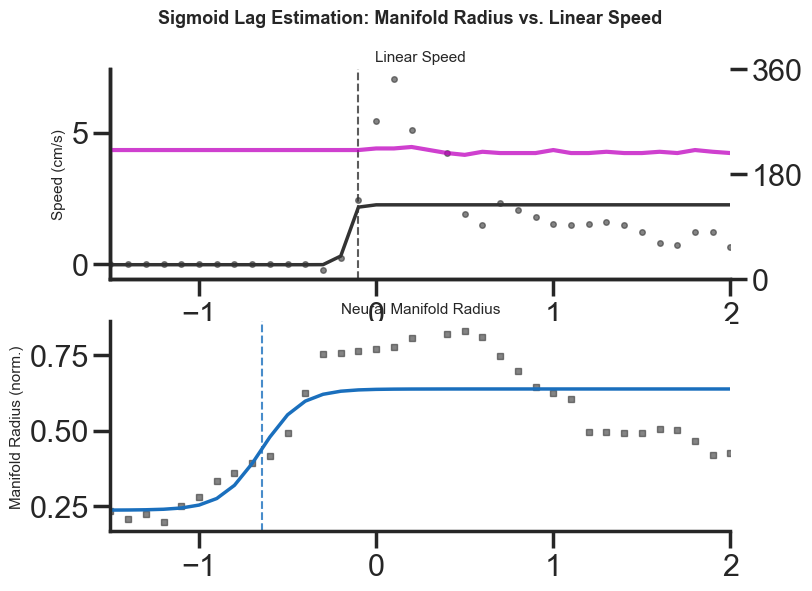

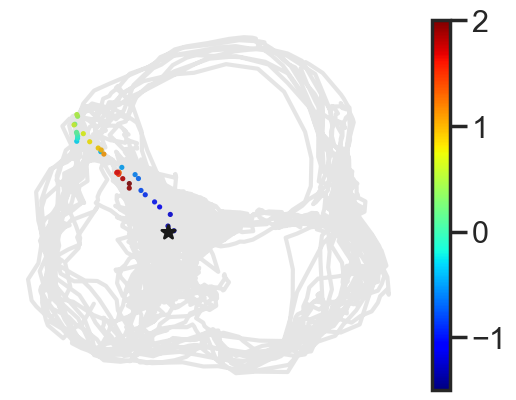

In [544]:
ls_lag = []
ls_df = []
time_idx = np.arange(35)
n_samples = 35   # samples per epoch
t = np.linspace(-1.5, 2, n_samples)   # 4 s window centred on run onset
t = np.round(t, 1)
to_plot = True

for epid in df_stat2run.epoch_id.unique():
    
    if epid != '20220815_JA0181_darkHR1_3760':
        continue
        
    print (epid)
    tmp_stat2run = df_stat2run[df_stat2run.epoch_id == epid]
    speed = tmp_stat2run['epoch_speed'].values
    ep_yaw = tmp_stat2run['epoch_yaw'].values
    radius = tmp_stat2run['epoch_ring_rad'].values
    ep_emb_x = tmp_stat2run['epoch_emb_x'].values
    ep_emb_y = tmp_stat2run['epoch_emb_y'].values
    rec_id = tmp_stat2run['rec_id'][0]
    emb_x, emb_y = d_hr_emb[rec_id]['isomap'][:, 0], d_hr_emb[rec_id]['isomap'][:, 1]
    

    p0_speed  = [0.0,  10.0, speed[:5].mean(),  speed[-5:].mean()  - speed[:5].mean()]
    p0_radius = [-0.5, 1.5, radius[:5].mean(), radius[-5:].mean() - radius[:5].mean()]
    
    popt_s, pcov_s, fit_s = fit_sigmoid(t, speed,  p0=p0_speed)
    popt_r, pcov_r, fit_r = fit_sigmoid(t, radius, p0=p0_radius)
    
    t0_speed  = popt_s[0] if popt_s is not None else np.nan
    t0_radius = popt_r[0] if popt_r is not None else np.nan
    
    # circstd was computed within 1s
    if abs(t0_speed) > 1 or abs(t0_radius) > 1:
        print(f't0 beyond limits of constant yaw')
        continue
        
    perr_s = np.sqrt(np.diag(pcov_s)) if pcov_s is not None else [np.nan]*4
    perr_r = np.sqrt(np.diag(pcov_r)) if pcov_r is not None else [np.nan]*4

    try:
        stat2run_idx = np.where(fit_s > 2)[0][0]
        stat2run_t = t[stat2run_idx]
        base_fit_s = fit_s[:stat2run_idx].mean()
    except:
        print(f'bad fitting')
        continue
        
    lag = t0_radius - stat2run_t   # negative → radius leads speed

    if fit_s[:10].mean() > 2:
        print('base fit_s speed > 1 cm/s')
        continue
    is_good_speed = is_good_epoch(t, speed, popt_s, pcov_s, fit_s)
    is_good_rad = is_good_epoch(t, radius, popt_r, pcov_r, fit_r)

    if is_good_speed[0] & is_good_rad[0]:
        print(f'good epoch {is_good_speed} {is_good_rad}')
    else:
        print(f'bad epoch {is_good_speed} {is_good_rad}')
        continue

    
    print(f"Speed  sigmoid midpoint  t0 = {t0_speed:+.3f} s  (±{perr_s[0]:.3f})")
    print(f"Radius sigmoid midpoint  t0 = {t0_radius:+.3f} s  (±{perr_r[0]:.3f})")
    print(f"Estimated lag (radius - speed): {lag*1000:+.1f} ms")
    
    if to_plot == True:
        fig, axes = plt.subplots(2, 1, figsize=(8, 6))
        fig.suptitle("Sigmoid Lag Estimation: Manifold Radius vs. Linear Speed",
                     fontsize=13, fontweight='bold', y=0.98)
                
        # --- Panel 1: Speed ---
        ax = axes[0]
        ax.plot(t, speed, 'o', color='#333333', ms=4, alpha=0.6, label='Speed (data)')
        ax.plot(t, fit_s, '-', color='#333333', lw=2.5, label=f'Sigmoid fit  (t₀={t0_speed:+.2f} s)')
        ax.axvline(stat2run_t, color='#333333', lw=1.5, ls='--', alpha=0.8)
        # ax.axvline(0, color='gray', lw=1, ls=':', alpha=0.6, label='Run onset')
        ax.set_ylabel('Speed (cm/s)', fontsize=11)
        # ax.legend(fontsize=9, loc='upper left')
        ax.set_xlim(t[0], t[-1])
        ax.set_title('Linear Speed', fontsize=11)

        ax_2 = ax.twinx()
        ax_2.plot(t, ep_yaw, 'm', label = 'yaw', alpha = 0.75)
        ax_2.set_yticks([0, 180, 360])
     
        
        # ax.grid(True, alpha=0.3)
        
        # --- Panel 2: Radius ---
        ax = axes[1]
        ax.plot(t, radius, 's', color='#333333', ms=4, alpha=0.6, label='Radius (data)')
        ax.plot(t, fit_r, '-', color='#1a6fbd', lw=2.5, label=f'Sigmoid fit  (t₀={t0_radius:+.2f} s)')
        ax.axvline(t0_radius, color='#1a6fbd', lw=1.5, ls='--', alpha=0.8)
        # ax.axvline(0, color='gray', lw=1, ls=':', alpha=0.6, label='Run onset')
        ax.set_ylabel('Manifold Radius (norm.)', fontsize=11)
        # ax.legend(fontsize=9, loc='upper left')
        ax.set_xlim(t[0], t[-1])
        ax.set_title('Neural Manifold Radius', fontsize=11)
        # ax.grid(True, alpha=0.3)
        
        # filepath = save_dir / f'line_{epid}_r-fit.pdf'
        # plt.savefig(filepath, transparent = True)
      
    

        # time.sleep(0.2)
        
        f, ax = plt.subplots()
        plt.scatter(ep_emb_x[:], ep_emb_y[:], alpha = 1, s = 3,  c = t, 
                    cmap = 'jet')
        plt.colorbar()
        plt.plot(emb_x[:], emb_y[:], c = 'gray', alpha = 0.2)
        plt.scatter(ep_emb_x[0], ep_emb_y[0], c = 'k', s = 100, marker = "*")
        plt.axis('off')
        
        # filepath = save_dir / f'scatter-hr_{epid}_vel_rad.pdf'
        # plt.savefig(filepath, transparent = True)
    
        plt.show()
        

    # break
#     tmp_df = pd.DataFrame({'rec_id': rec_id, 'epoch': epid, 'ep_speed': speed, 'lag_s':lag, 'ep_emb_x': ep_emb_x, 'ep_emb_y':ep_emb_y,
#                           'ep_yaw': ep_yaw, 'ep_radius': radius, 'time_s':t, 'speed_onset':stat2run_t, 'rad_onset':t0_radius, 'fit_s': fit_s, 'fit_r': fit_r,
#                           })
#     ls_df.append(tmp_df)
#     # break
# df_run_onset = pd.concat(ls_df)
# df_run_onset.head()

In [545]:
# pd.DataFrame({'ep_emb_x': ep_emb_x, 'ep_emb_y': ep_emb_y, 'speed': speed, 'fit_s': fit_s, 't':t, 
#               'radius': radius, 'fit_r': fit_r, 'ep_yaw': ep_yaw}).to_excel(filepath, index = True)

In [532]:
df_run_onset.epoch.unique().size

11

In [533]:
df_run_onset.rec_id.unique()

array(['20220302_JA0162_lightHR1', '20220126_JA0153_darkHR1',
       '20220302_JA0162_darkHR1', '20220819_JA0178_darkHR1',
       '20220815_JA0181_darkHR1', '20220818_JA0181_darkHR1'], dtype=object)

In [534]:
lag_arr = df_run_onset.loc[0]['lag_s'].values
print(lag_arr)

[ 0.02912815 -0.43445954 -0.08927615 -0.54307123 -0.60360009 -0.75503257
 -0.07997578 -0.45303585 -0.85599253 -0.54728121 -0.26293517]


# of epochs 11
mean -0.41777563479441215 -0.8559925310759491 0.029128147044438266
sem 0.08634068607898707


(-1.5, 1.5)

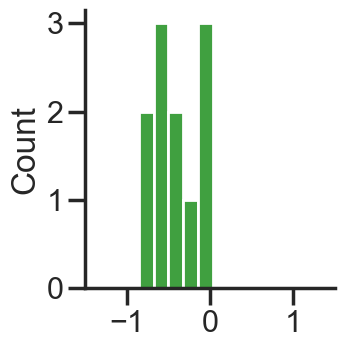

In [535]:
sns.displot(lag_arr, bins = 5, color = 'green', height=4, aspect = 1)
print('# of epochs', len(lag_arr))
print('mean', np.mean(lag_arr), lag_arr.min(), lag_arr.max())
print('sem', stats.sem(lag_arr))

plt.xlim(-1.5, 1.5)

# filepath = save_dir / 'dist_hr_lag-rad_vel.pdf'
# plt.savefig(filepath, transparent = True)

In [538]:
# pd.DataFrame(lag_arr).to_excel(filepath, index = True)

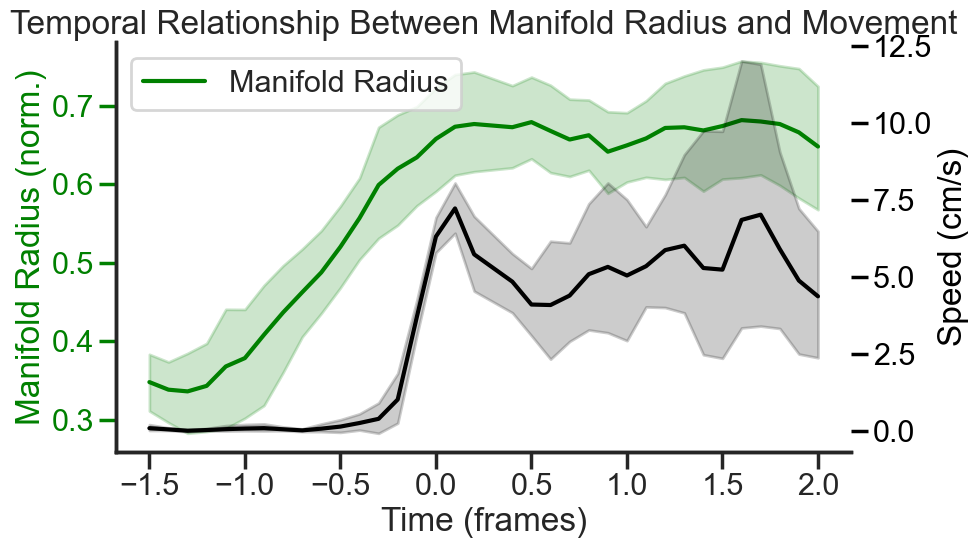

In [539]:
fig, ax1 = plt.subplots(figsize=(10, 6))
_inp = df_run_onset
# Plot radius data on primary axis
sns.lineplot(
    data=_inp, 
    x='time_s', 
    y='ep_radius',
    ax=ax1,
    color='green',
    label='Manifold Radius'
)
ax1.set_xlabel('Time (frames)')
ax1.set_ylabel('Manifold Radius (norm.)', color='green')
ax1.tick_params(axis='y', colors='green')

# Add a secondary y-axis for speed
ax2 = ax1.twinx()
sns.lineplot(
    data=_inp, 
    x='time_s', 
    y='ep_speed',
    ax=ax2,
    color='k',
    # label='Speed'
)
ax2.set_ylabel('Speed (cm/s)', color='k')
ax2.tick_params(axis='y', colors='k')

# Add vertical line at t=0 (movement onset)
# ax1.axvline(x=15, color='black', linestyle='--', label='Movement Onset')

# Combine legends
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

plt.title('Temporal Relationship Between Manifold Radius and Movement')
plt.tight_layout()

# filepath = save_dir / 'line-hr_vel_rad.pdf'
# plt.savefig(filepath, transparent = True)

In [540]:
# import os
# print(f"Current directory: {os.getcwd()}")
# print(f"Writeable: {os.access(os.getcwd(), os.W_OK)}")

Current directory: H:\My Drive\SNL @NU\Papers\ADN HD VR-Hfree paper\Data analysis
Writeable: True


In [541]:
# filepath = save_dir / f'out.xlsx'
# _inp.to_excel(filepath, index = True)


0.61 -0.4


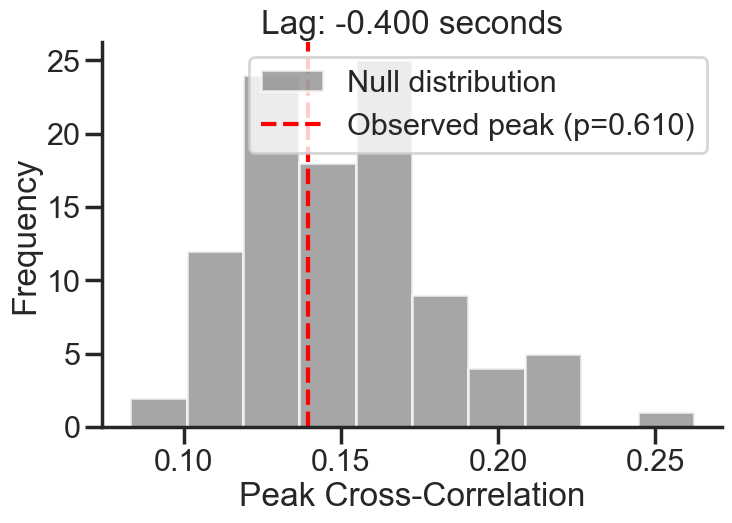

In [113]:
a = df_run_onset.groupby([ 'time_s'])['ep_speed'].mean()
b = df_run_onset.groupby([ 'time_s'])['ep_radius'].mean()
speed_diff = np.diff(a.values)
radius_diff = np.diff(b.values)
is_significant, p_value, lag_seconds = test_xcorr_significance(radius_diff, speed_diff, n_shuffles=100, fs=10, to_plot = True)
print(p_value, lag_seconds)
# plt.savefig(f'xcorr-vr_meanvel_rad.pdf', transparent = True)

## LFP analysis

In [385]:
import ghostipy as gsp

In [384]:
path = r'y:\Users\Alex\Data Analysis\VR1 ATN data\Processed_paper\df_hr_tf.pkl'
df_hr_tf = pd.read_pickle(path)
df_hr_tf.head()

FileNotFoundError: [Errno 2] No such file or directory: 'y:\\Users\\Alex\\Data Analysis\\VR1 ATN data\\Processed_paper\\df_hr_tf.pkl'

In [160]:
df_hr_master_2['rec_session'] = df_hr_master_2['animal_name'] + '_' + df_hr_master_2['date_name']
df_hr_master_2.head()

,animal_name,cids,date_name,is_sua,depth,cuid,session_name,site,rec_id,condition,hz,times,yaw,lfp,omega,vel,hdc_flag,rec_session
0,JA0178,1.0,20220819,0.0,742.0,1.0_20220819_JA0178_dark1,,239,20220819_JA0178_dark1,dark1,0.0,0.00,140.206927,0.0,17.507949,9.286662,False,JA0178_20220819
1,JA0178,1.0,20220819,0.0,742.0,1.0_20220819_JA0178_dark1,,239,20220819_JA0178_dark1,dark1,0.0,0.02,140.206927,-97.0,18.163893,10.613187,False,JA0178_20220819
2,JA0178,1.0,20220819,0.0,742.0,1.0_20220819_JA0178_dark1,,239,20220819_JA0178_dark1,dark1,0.0,0.04,140.206927,-30.0,16.766670,9.085629,False,JA0178_20220819
3,JA0178,1.0,20220819,0.0,742.0,1.0_20220819_JA0178_dark1,,239,20220819_JA0178_dark1,dark1,0.0,0.06,140.206927,99.0,15.569051,8.962052,False,JA0178_20220819
4,JA0178,1.0,20220819,0.0,742.0,1.0_20220819_JA0178_dark1,,239,20220819_JA0178_dark1,dark1,0.0,0.08,140.206927,153.0,14.531114,9.849319,False,JA0178_20220819


In [161]:
df_hr_master_2.head()

,animal_name,cids,date_name,is_sua,depth,cuid,session_name,site,rec_id,condition,hz,times,yaw,lfp,omega,vel,hdc_flag,rec_session
0,JA0178,1.0,20220819,0.0,742.0,1.0_20220819_JA0178_dark1,,239,20220819_JA0178_dark1,dark1,0.0,0.00,140.206927,0.0,17.507949,9.286662,False,JA0178_20220819
1,JA0178,1.0,20220819,0.0,742.0,1.0_20220819_JA0178_dark1,,239,20220819_JA0178_dark1,dark1,0.0,0.02,140.206927,-97.0,18.163893,10.613187,False,JA0178_20220819
2,JA0178,1.0,20220819,0.0,742.0,1.0_20220819_JA0178_dark1,,239,20220819_JA0178_dark1,dark1,0.0,0.04,140.206927,-30.0,16.766670,9.085629,False,JA0178_20220819
3,JA0178,1.0,20220819,0.0,742.0,1.0_20220819_JA0178_dark1,,239,20220819_JA0178_dark1,dark1,0.0,0.06,140.206927,99.0,15.569051,8.962052,False,JA0178_20220819
4,JA0178,1.0,20220819,0.0,742.0,1.0_20220819_JA0178_dark1,,239,20220819_JA0178_dark1,dark1,0.0,0.08,140.206927,153.0,14.531114,9.849319,False,JA0178_20220819


In [439]:
good_sess, 

['JA0144_20211212',
 'JA0153_20220209',
 'JA0162_20220302',
 'JA0164_20220419',
 'MC022_12',
 'JA0178_20220819',
 'JA0181_20220812',
 'JA0181_20220815',
 'JA0181_20220818',
 'JA153_26']

In [386]:
freq_bands = {'theta': (4, 12), 'beta': (15, 30), 
              'low_gamma': (30, 60), 'high_gamma': (60, 100)} 


In [388]:
# fs_lfp = 50
# gamma = 3 
# beta = 10 # decrease beta to improve temporal resolution
# # Zoom in on a particular window of time

# for rec in data_inp.rec_id.unique():
#     print(rec)
#     data_tmp = data_inp[(data_inp.rec_id == rec)]
#     lfp = data_inp.groupby('times')['lfp'].mean().values
#     lfp_ts = data_inp.groupby('times')['lfp'].mean().index.values
#     speed = data_inp.groupby('times')['vel'].mean().values
    
#     for i in range(2):
#         t1 = np.random.randint(lfp_ts.max() - 10)
#         t2 = t1 + 4

#         idx = (lfp_ts >= t1) & (lfp_ts <= t2)
#         LFP = lfp[idx]
#         spd = speed[idx]
#         ts = lfp_ts[idx]

#         cwtcoefs, _, freq, cwtts, _ = gsp.cwt(
#             LFP, timestamps=ts, freq_limits=[1, 25], fs=fs_lfp,
#             wavelet=gsp.MorseWavelet(gamma=gamma, beta=beta))

#         cwt_power = cwtcoefs.imag**2 + cwtcoefs.real**2

#         plt.rcParams.update({'axes.spines.right': False, 'axes.spines.top': False})
#         fig, axes = plt.subplots(3, 1, figsize=(6, 6), sharex=True, 
#                                  gridspec_kw={'hspace':0.15, 'height_ratios':[0.2,0.8,0.2]})
#         ax1, ax2, ax3 = axes

#         ax1.plot(ts, spd)
#         ax1.set_ylim(-1, 40)
#         ax1.set_ylabel("Speed\n(cm/s)", labelpad=10)
#         ax1.tick_params(axis='x', which='both', bottom=False, top=False)

#         t_ax, f_ax = np.meshgrid(ts, freq)
#         ax2.pcolormesh(t_ax, f_ax, cwt_power, shading='gouraud', 
#                        cmap=plt.cm.viridis, vmin=0, vmax=1250)

#         ax2.set_ylabel("Frequency (Hz)")
#         ax2.set_ylim(1, 25)
#         ax2.tick_params(axis='x', which='both', bottom=False, top=False)

#         ax3.plot(ts, LFP, 'grey', linewidth=0.5)
#         plt.show()
#         # plt.savefig('../figures/Figure5.pdf', bbox_inches='tight')
#     break

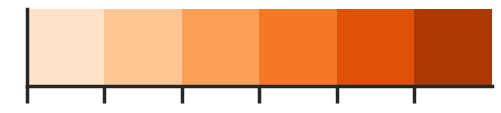

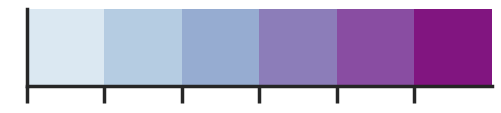

In [387]:
grey_palette = sns.color_palette("Greys")
orange_palette = sns.color_palette("Oranges")
green_palette = sns.color_palette("Greens")
red_palette = sns.color_palette("BuPu")
d_pal = {'light1': orange_palette, 'dark1':grey_palette, 'lightHR1':green_palette, 'darkHR1':red_palette}
sns.palplot(orange_palette[:][:])
sns.palplot(red_palette[:][:])

### Theta vs lin. speed

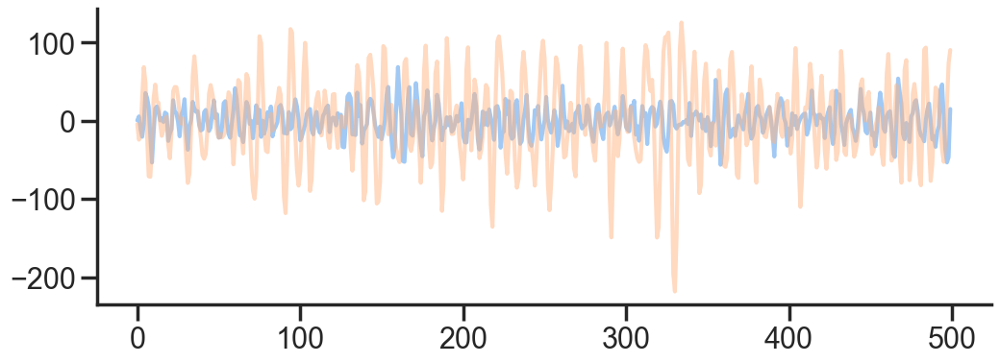

In [434]:
f, ax = plt.subplots(figsize = (12, 4))
plt.plot(med_lfp[:500])
plt.plot(data_inp[data_inp.cids == unit].lfp.values[:500], alpha = 0.5)

In [905]:
from sklearn.linear_model import LinearRegression, HuberRegressor

In [711]:
 dts, animal_name, cond

('20220829', 'MC038', 'light1')

20211207_JA0144_dark1 8
(0, 1) 1550 7.1793647187314695 1.0
(1, 2) 1325 6.25 1.0
(2, 4) 2375 6.25 1.0
(4, 8) 9650 7.1793647187314695 1.0
(8, 17) 8525 7.694652583405727 1.0
(17, 35) 575 8.838834764831844 1.0


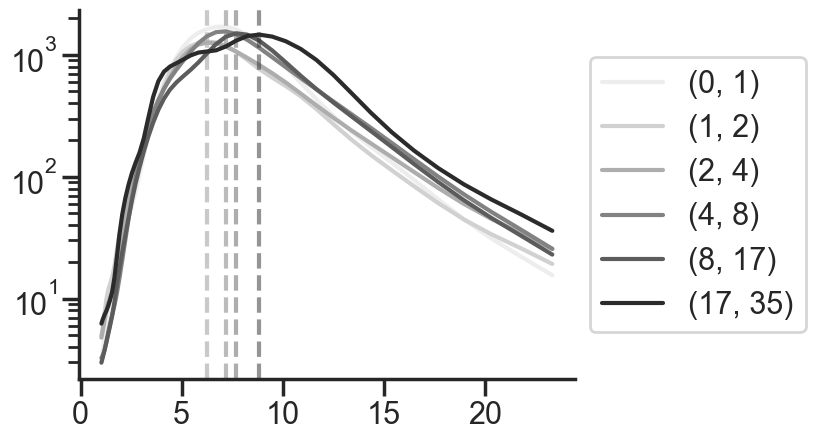

20211207_JA0144_darkHR1 6
(0, 1) 11825 7.1793647187314695 1.0
(1, 2) 725 6.698584140851832 1.0
(2, 4) 750 7.694652583405727 1.0
(4, 8) 1200 7.1793647187314695 1.0
(8, 17) 825 7.1793647187314695 1.0


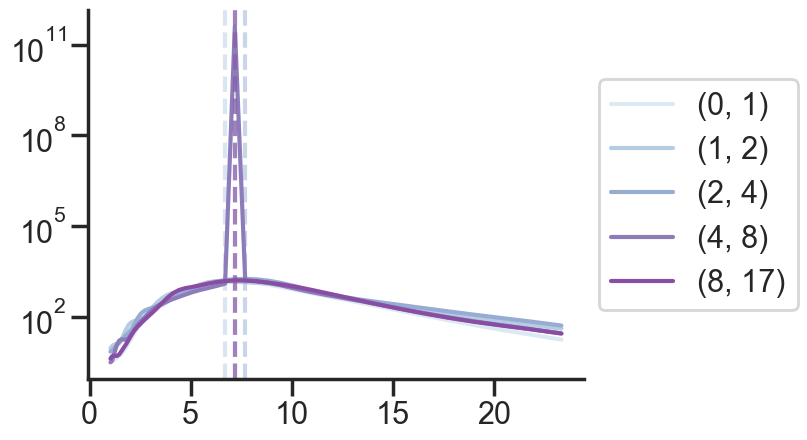

20211207_JA0144_light1 8
(2, 4) 1650 6.698584140851832 1.0
(4, 8) 8400 7.1793647187314695 1.0
(8, 17) 12225 8.246924442330588 1.0
(17, 35) 1175 8.246924442330588 1.0


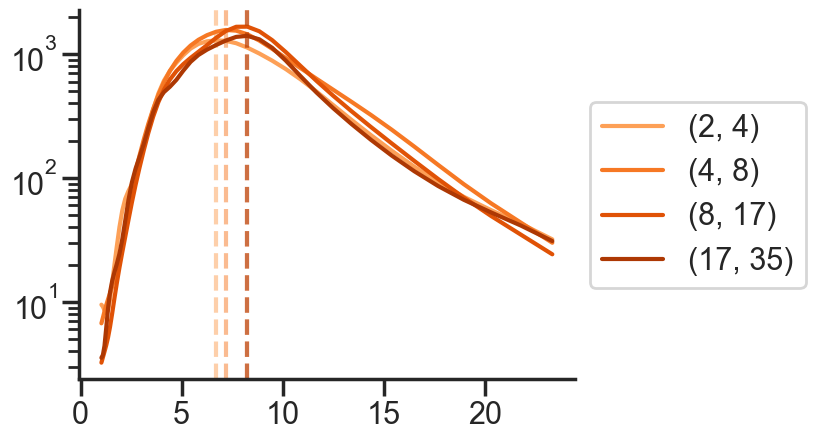

20211207_JA0144_lightHR1 6
(0, 1) 3950 7.694652583405727 1.0
(1, 2) 675 8.246924442330588 1.0
(2, 4) 1325 7.694652583405727 1.0
(4, 8) 2375 8.246924442330588 1.0


C:\Users\lab\AppData\Local\Temp\ipykernel_18196\2647220368.py:51: RuntimeWarning: overflow encountered in square
  cwt_power = cwtcoefs.imag**2 + cwtcoefs.real**2


(8, 17) 2700 7.1793647187314695 nan


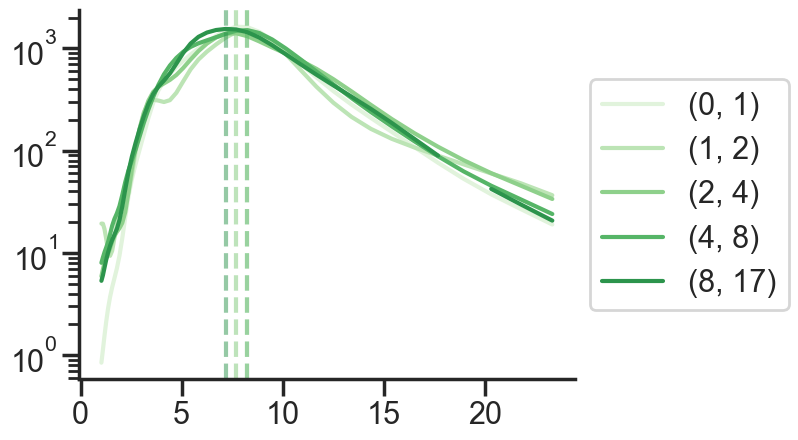

20220126_JA0153_dark1 10
(1, 2) 2825 5.831456197105046 1.0
(2, 4) 3975 6.698584140851832 0.7682243203382811
(4, 8) 5525 11.662912394210093 0.6840907937119317
(8, 17) 9975 11.662912394210093 0.621757040692615
(17, 35) 1375 8.246924442330588 0.6292666389944019


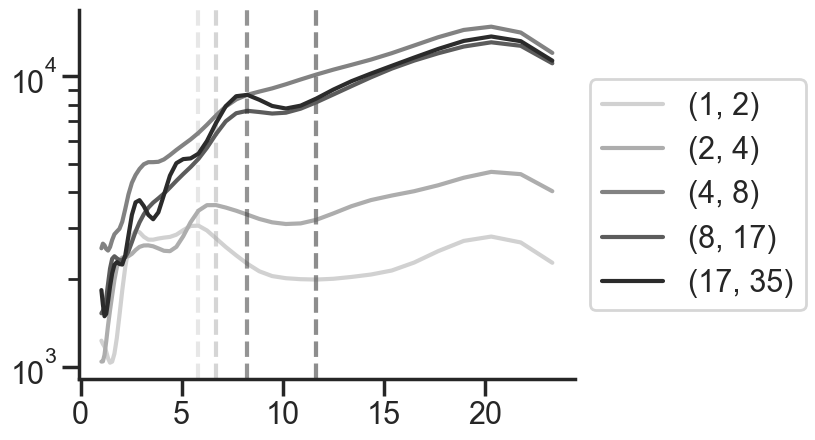

20220126_JA0153_darkHR1 13
(0, 1) 3700 5.440941020600776 0.7334804847491183
(1, 2) 675 6.25 1.0
(2, 4) 1000 6.698584140851832 1.0
(4, 8) 3900 6.698584140851832 0.9952106751832941
(8, 17) 7400 6.698584140851832 0.8743403380757591
(17, 35) 3800 7.1793647187314695 1.0


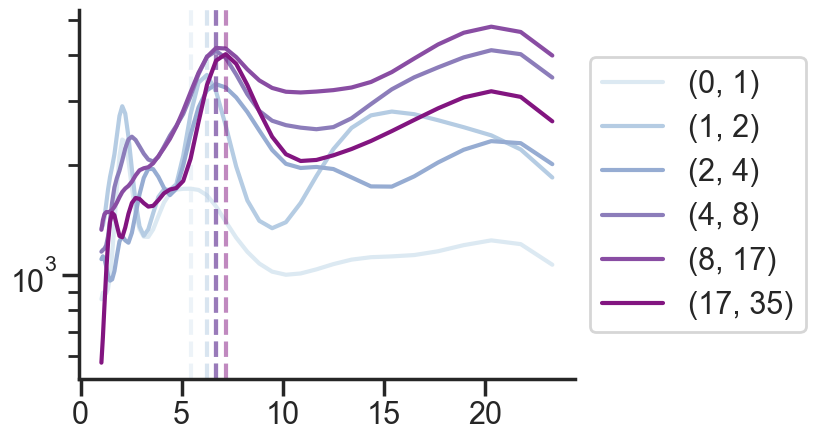

20220126_JA0153_light1 13
(1, 2) 1975 6.25 0.8324441057505425
(2, 4) 3775 7.1793647187314695 0.7055515690920799
(4, 8) 6400 11.662912394210093 0.6369509787679236
(8, 17) 10350 11.662912394210093 0.6612181897982948
(17, 35) 1450 8.838834764831844 0.5662197169271614


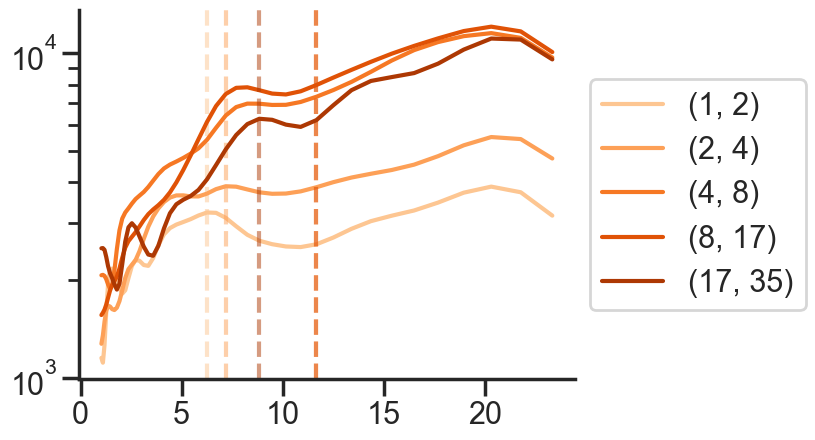

20220126_JA0153_lightHR1 19
(0, 1) 4250 6.25 1.0
(1, 2) 1150 6.25 1.0
(2, 4) 2525 7.1793647187314695 1.0
(4, 8) 4750 7.1793647187314695 1.0
(8, 17) 5750 7.1793647187314695 1.0
(17, 35) 1225 7.1793647187314695 1.0


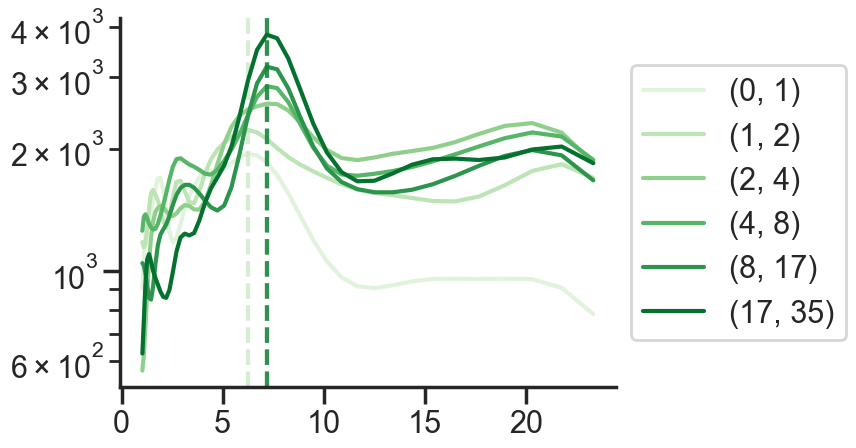

20220302_JA0162_dark1 4
(0, 1) 1500 5.440941020600776 1.0
(1, 2) 750 5.831456197105046 1.0
(2, 4) 2450 5.831456197105046 1.0
(4, 8) 10775 6.698584140851832 1.0
(8, 17) 7875 7.1793647187314695 1.0
(17, 35) 600 7.694652583405727 1.0


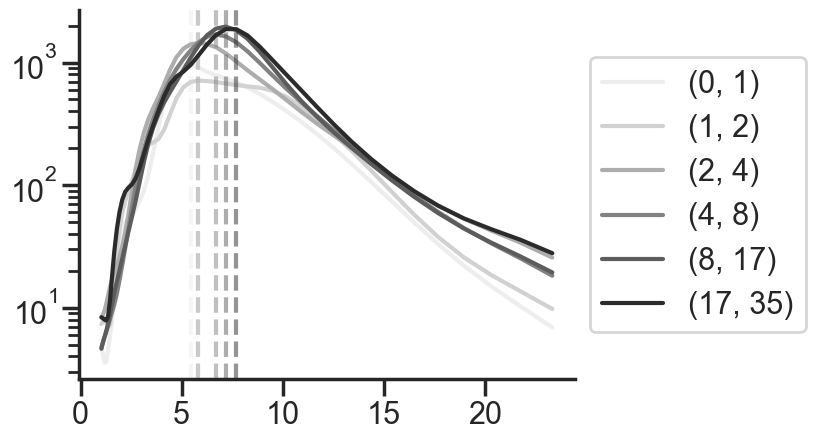

20220302_JA0162_darkHR1 1
20220302_JA0162_light1 8
(1, 2) 750 5.076577477226473 1.0
(2, 4) 2700 6.25 1.0
(4, 8) 10900 6.698584140851832 1.0
(8, 17) 8950 7.694652583405727 1.0
(17, 35) 650 6.698584140851832 1.0


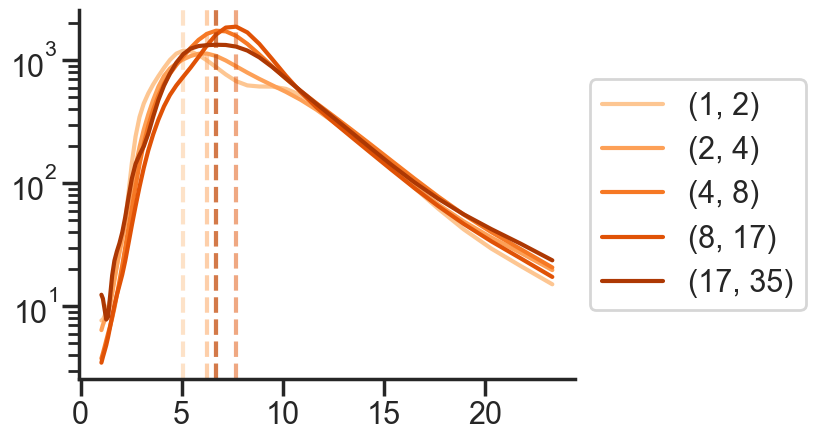

20220302_JA0162_lightHR1 9
(0, 1) 5875 7.1793647187314695 1.0
(1, 2) 1075 7.1793647187314695 1.0
(2, 4) 3075 6.698584140851832 1.0
(4, 8) 5500 7.1793647187314695 1.0
(8, 17) 1750 7.1793647187314695 1.0


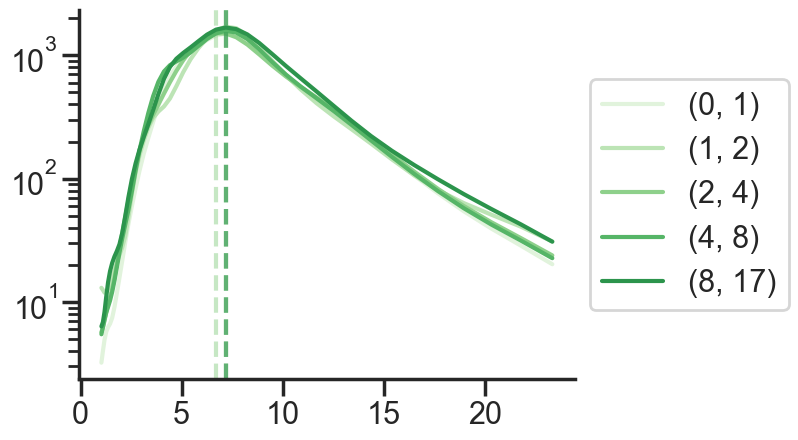

20220419_JA0164_dark1 7
(0, 1) 575 5.440941020600776 1.0
(1, 2) 2375 6.25 1.0
(2, 4) 5025 5.831456197105046 1.0
(4, 8) 5650 7.1793647187314695 1.0
(8, 17) 9500 7.694652583405727 1.0
(17, 35) 875 8.246924442330588 1.0


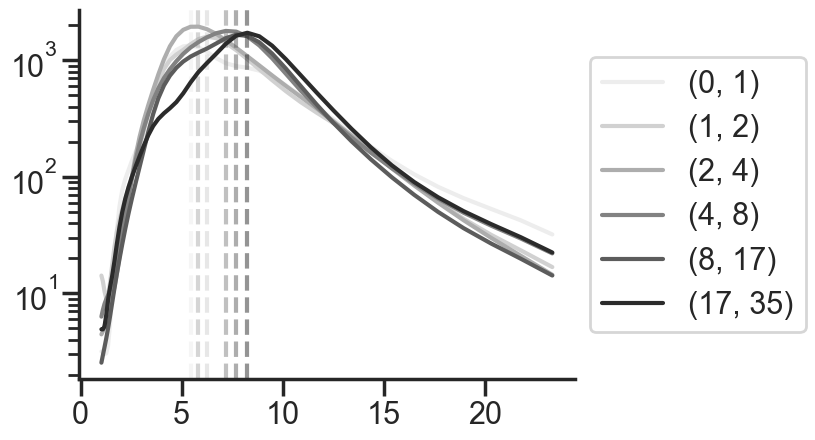

20220419_JA0164_darkHR1 6
(0, 1) 3250 7.694652583405727 1.0
(1, 2) 1850 6.698584140851832 1.0
(2, 4) 3450 7.1793647187314695 1.0
(4, 8) 7800 6.25 1.0
(8, 17) 6100 7.694652583405727 1.0
(17, 35) 600 6.25 1.0


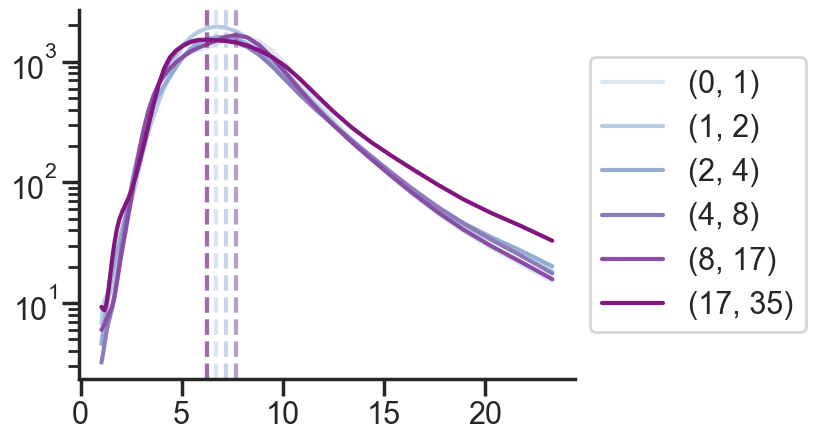

20220419_JA0164_light1 8
(1, 2) 550 5.831456197105046 1.0
(2, 4) 3875 6.25 1.0
(4, 8) 8150 6.698584140851832 1.0
(8, 17) 10650 7.694652583405727 1.0
(17, 35) 675 8.246924442330588 1.0


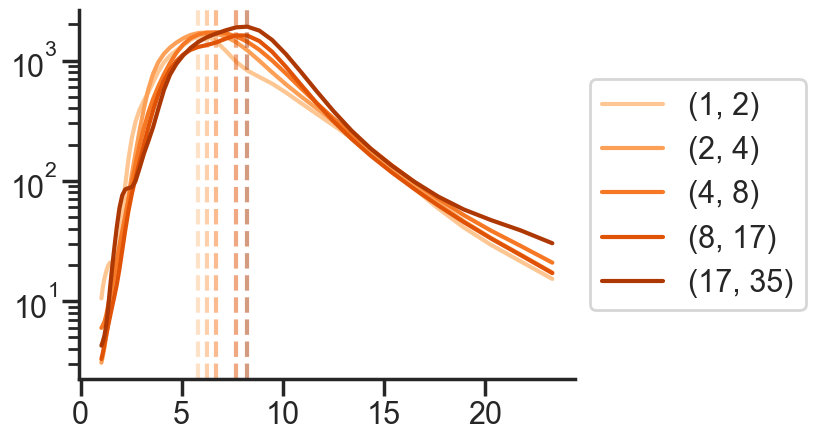

20220419_JA0164_lightHR1 10
(0, 1) 500 5.831456197105046 1.0
(1, 2) 2600 7.1793647187314695 1.0
(2, 4) 11775 7.1793647187314695 1.0
(4, 8) 7050 7.694652583405727 1.0
(8, 17) 1525 7.694652583405727 1.0


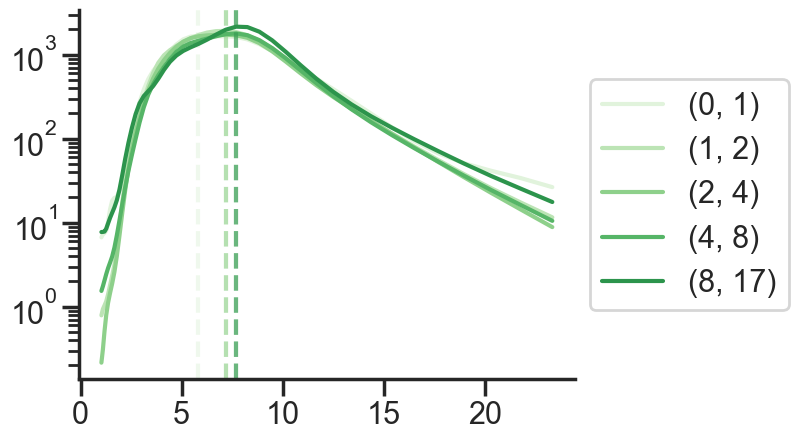

20220819_JA0178_dark1 29
(1, 2) 700 5.831456197105046 1.0
(2, 4) 2150 6.698584140851832 1.0
(4, 8) 8225 7.1793647187314695 1.0
(8, 17) 11425 7.694652583405727 0.6236531363851573
(17, 35) 1350 7.694652583405727 0.6194232905166643


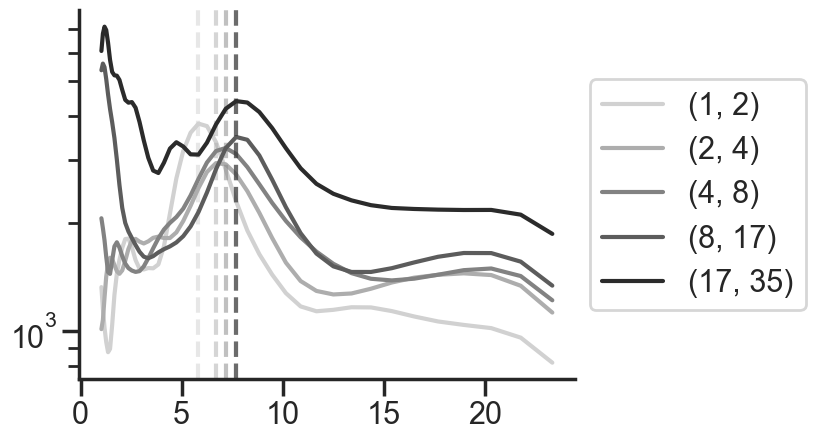

20220819_JA0178_darkHR1 0
20220819_JA0178_light1 29
(2, 4) 2400 5.831456197105046 1.0
(4, 8) 9275 7.1793647187314695 1.0
(8, 17) 10550 8.246924442330588 1.0
(17, 35) 1300 7.694652583405727 0.8644118743256325


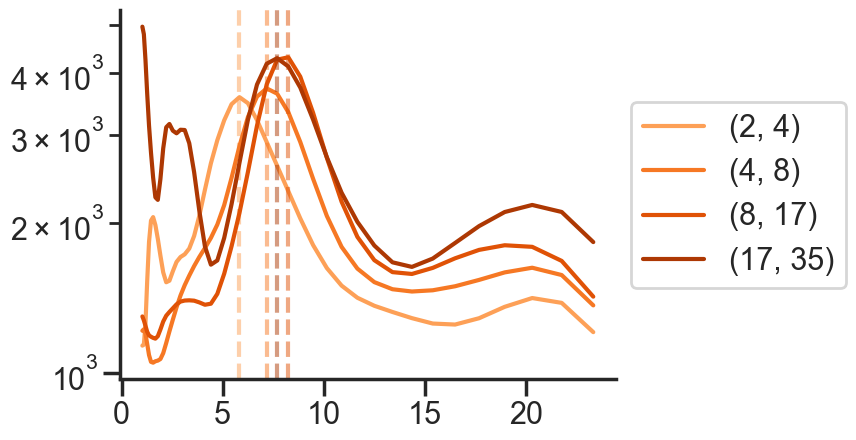

20220819_JA0178_lightHR1 30
(0, 1) 8675 5.831456197105046 1.0
(1, 2) 625 6.25 1.0
(2, 4) 2025 7.1793647187314695 1.0
(4, 8) 2750 7.1793647187314695 1.0
(8, 17) 750 7.1793647187314695 1.0


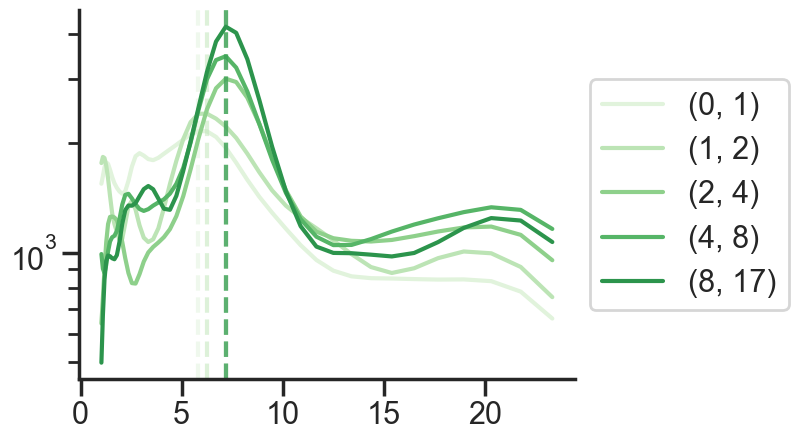

20220822_JA0178_dark1 24
(1, 2) 1250 6.698584140851832 0.8391016449498478
(2, 4) 5675 6.698584140851832 1.0
(4, 8) 7775 7.694652583405727 1.0
(8, 17) 8275 8.246924442330588 1.0
(17, 35) 775 4.419417382415922 0.18421682401743078


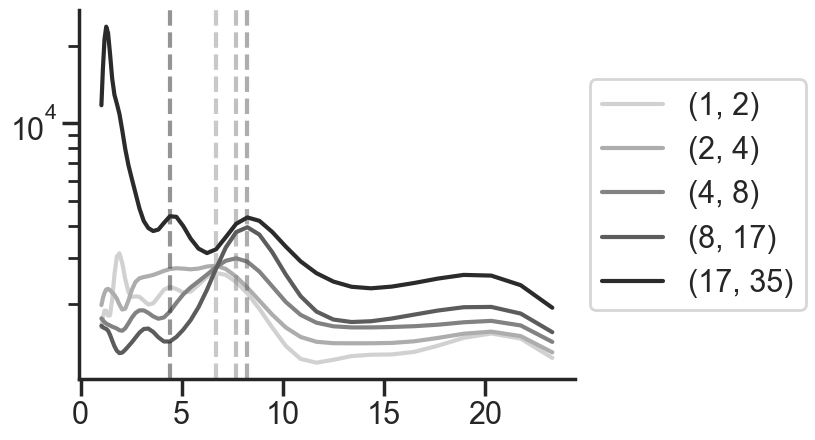

20220822_JA0178_darkHR1 24
(0, 1) 4250 6.25 0.9371146763241321
(1, 2) 1450 6.698584140851832 1.0
(2, 4) 2700 6.25 1.0
(4, 8) 5700 7.1793647187314695 1.0
(8, 17) 6275 7.1793647187314695 1.0


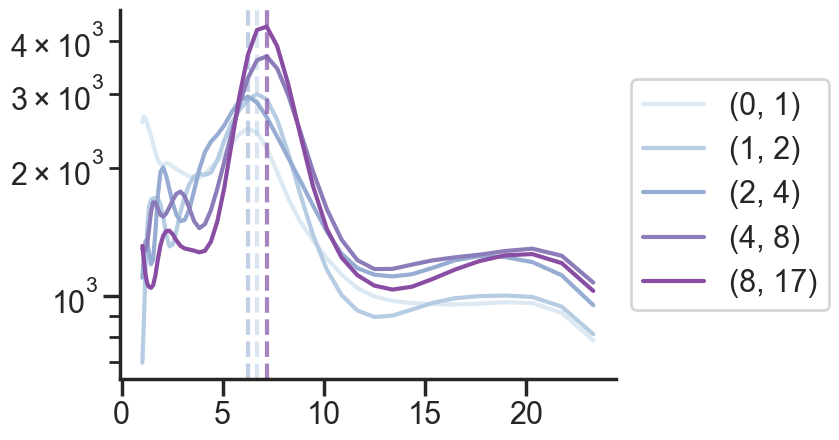

20220822_JA0178_light1 24
(1, 2) 800 6.698584140851832 1.0
(2, 4) 5400 5.831456197105046 0.7820849718096331
(4, 8) 6575 6.698584140851832 0.2100099048782551
(8, 17) 9525 4.123462221165294 0.1314669445374259
(17, 35) 1475 8.246924442330588 0.2307933262753447


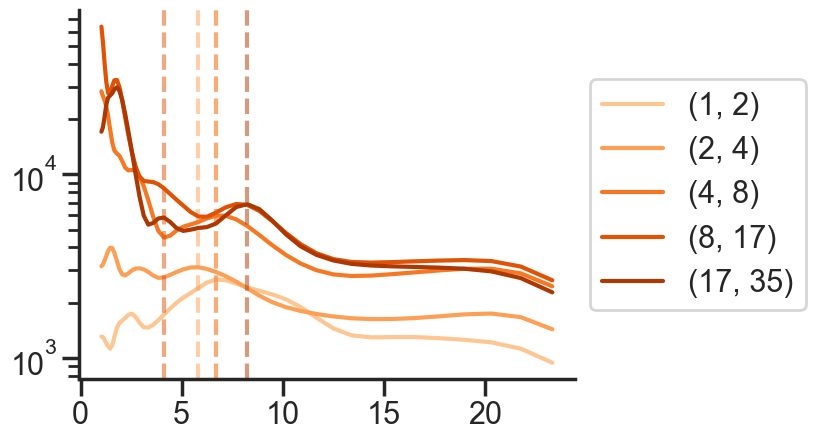

20220822_JA0178_lightHR1 26
(0, 1) 3000 6.25 1.0
(1, 2) 2525 6.25 1.0
(2, 4) 1975 7.1793647187314695 1.0
(4, 8) 3850 6.698584140851832 1.0
(8, 17) 3875 7.1793647187314695 1.0


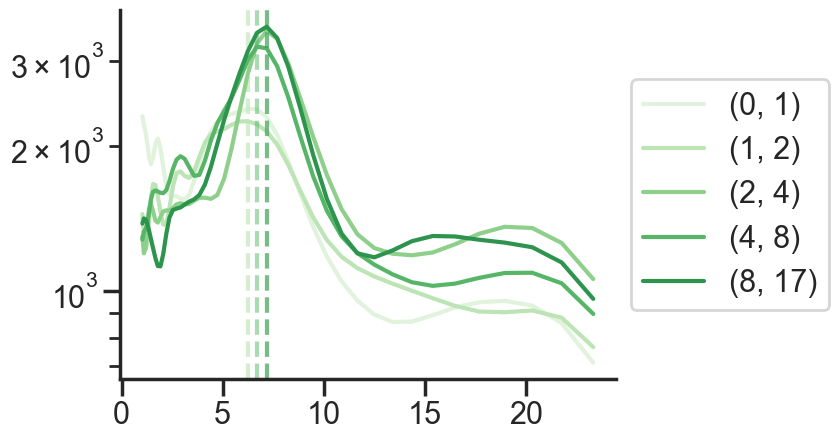

20220824_JA0178_dark1 5
(0, 1) 1000 10.153154954452944 0.9091578285220302
(1, 2) 925 5.440941020600776 1.0
(2, 4) 3400 7.1793647187314695 1.0
(4, 8) 10400 6.698584140851832 1.0
(8, 17) 7800 7.694652583405727 0.30124809743764097


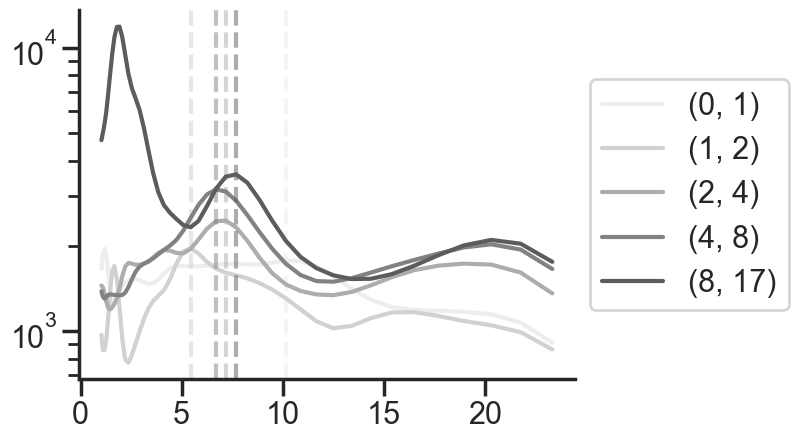

20220824_JA0178_darkHR1 2
20220824_JA0178_light1 5
(1, 2) 750 4.123462221165294 1.0
(2, 4) 5425 6.698584140851832 1.0
(4, 8) 13250 7.1793647187314695 1.0
(8, 17) 4550 8.246924442330588 1.0


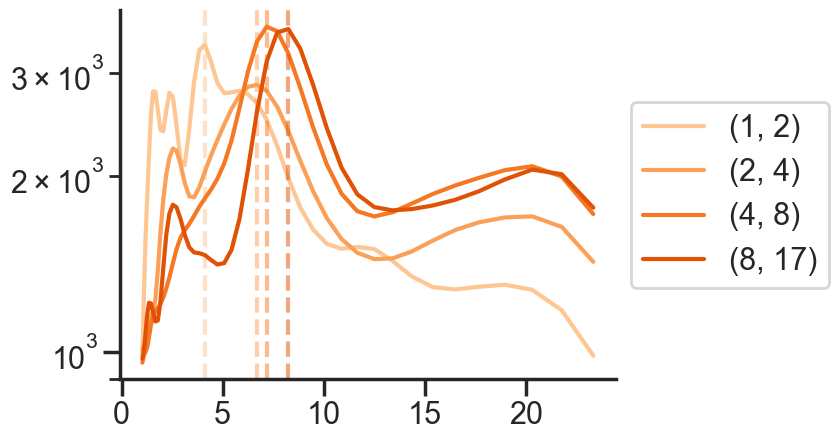

20220824_JA0178_lightHR1 7
(0, 1) 7875 5.831456197105046 1.0
(1, 2) 700 7.1793647187314695 1.0
(2, 4) 775 7.694652583405727 1.0
(4, 8) 1875 7.1793647187314695 1.0
(8, 17) 625 7.694652583405727 1.0


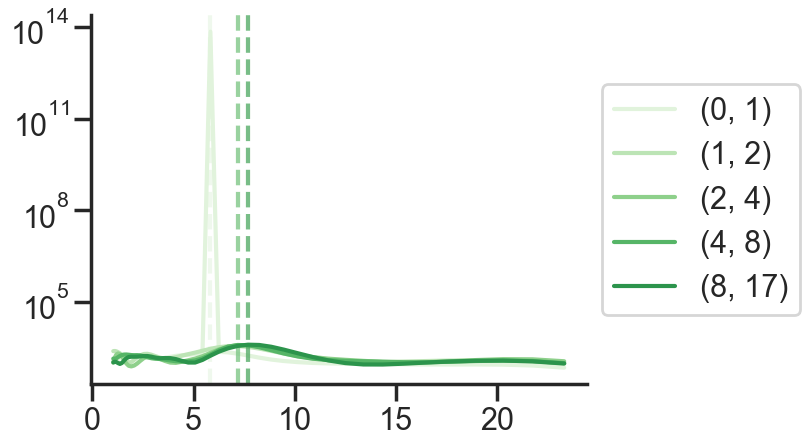

20220906_JA0178_dark1 11
(1, 2) 750 4.419417382415922 0.9914208618268239
(2, 4) 1825 5.440941020600776 1.0
(4, 8) 6725 7.1793647187314695 1.0
(8, 17) 13575 8.246924442330588 1.0
(17, 35) 950 8.246924442330588 1.0


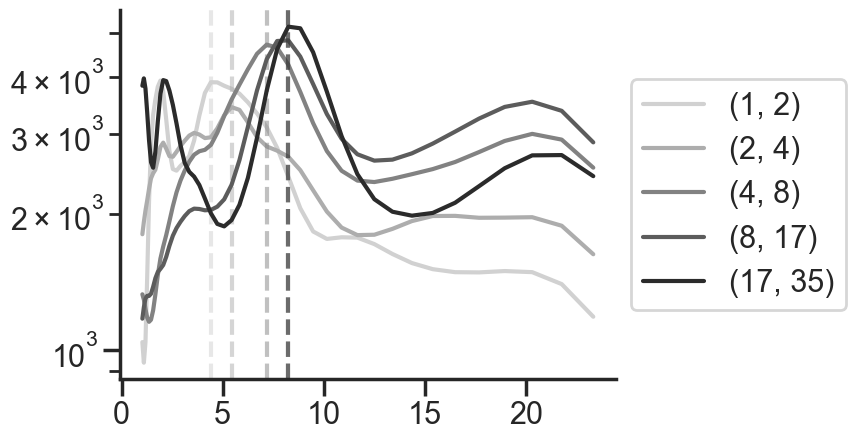

20220906_JA0178_darkHR1 3
(0, 1) 9225 5.831456197105046 1.0
(1, 2) 1500 6.698584140851832 1.0
(2, 4) 2575 6.698584140851832 1.0
(4, 8) 5650 7.1793647187314695 1.0
(8, 17) 900 6.698584140851832 1.0


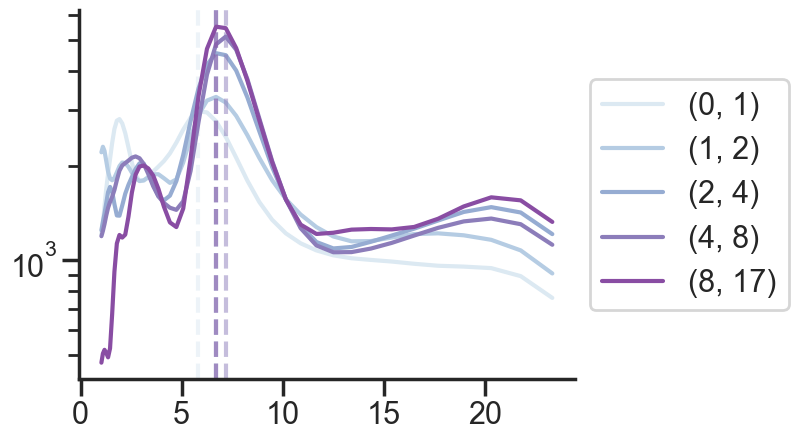

20220906_JA0178_light1 10
(2, 4) 2150 4.736614270344994 1.0
(4, 8) 7275 7.694652583405727 1.0
(8, 17) 13825 8.246924442330588 1.0
(17, 35) 700 8.246924442330588 1.0


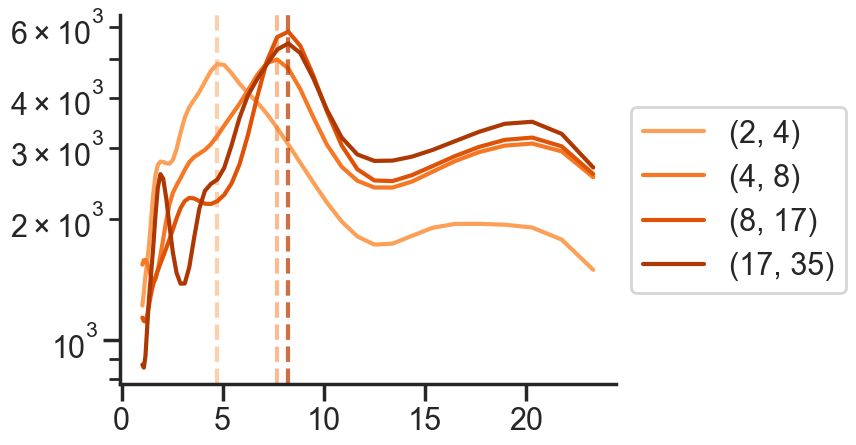

20220906_JA0178_lightHR1 1
20220812_JA0181_dark1 11
(1, 2) 1000 7.694652583405727 1.0
(2, 4) 2325 6.698584140851832 1.0
(4, 8) 5450 7.694652583405727 1.0
(8, 17) 12700 8.246924442330588 1.0
(17, 35) 2125 8.246924442330588 1.0


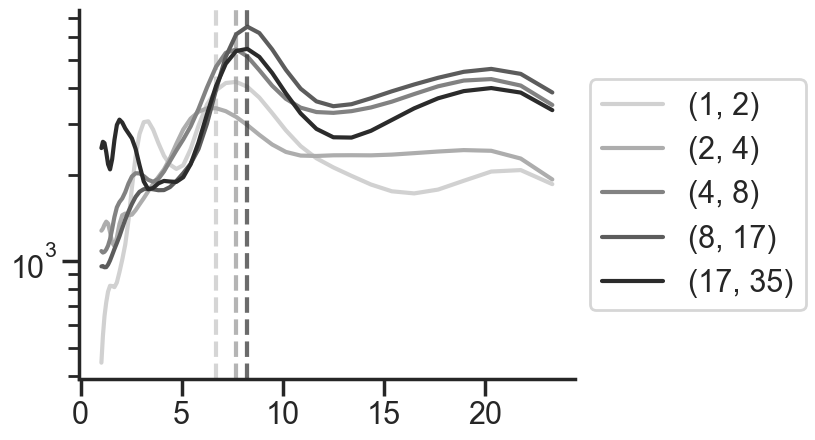

20220812_JA0181_darkHR1 13
(0, 1) 6625 6.698584140851832 1.0
(1, 2) 1150 7.1793647187314695 1.0
(2, 4) 2475 7.1793647187314695 1.0
(4, 8) 3950 7.1793647187314695 1.0
(8, 17) 1625 7.1793647187314695 1.0


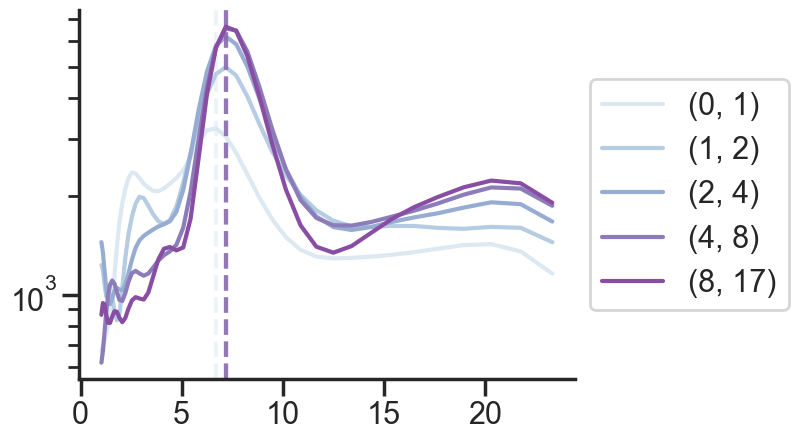

20220812_JA0181_light1 13
(1, 2) 1825 6.25 1.0
(2, 4) 2650 6.698584140851832 1.0
(4, 8) 5675 7.694652583405727 1.0
(8, 17) 11425 8.246924442330588 1.0
(17, 35) 2275 8.246924442330588 1.0


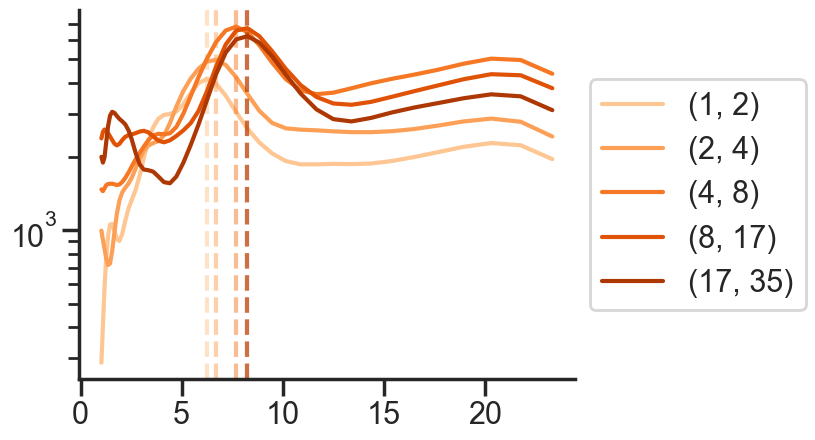

20220812_JA0181_lightHR1 12
(0, 1) 3650 6.25 1.0
(1, 2) 625 7.1793647187314695 1.0
(2, 4) 1325 7.694652583405727 1.0
(4, 8) 1950 7.694652583405727 1.0
(8, 17) 2500 7.694652583405727 1.0


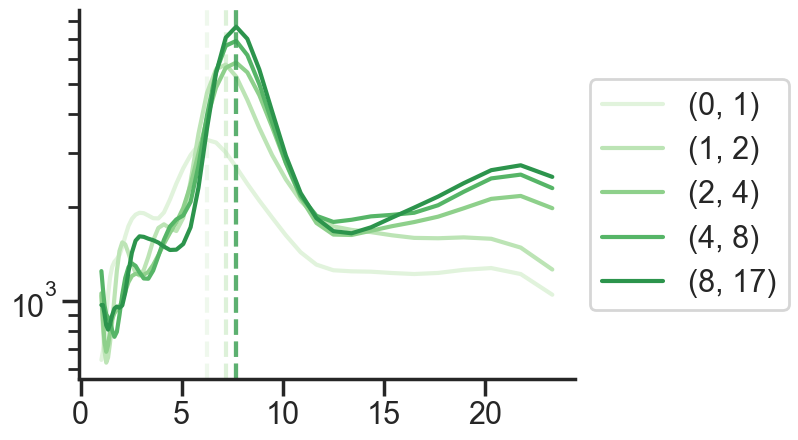

20220815_JA0181_dark1 15
(2, 4) 1400 6.698584140851832 1.0
(4, 8) 3425 7.694652583405727 1.0
(8, 17) 12425 8.246924442330588 1.0
(17, 35) 6050 8.246924442330588 1.0


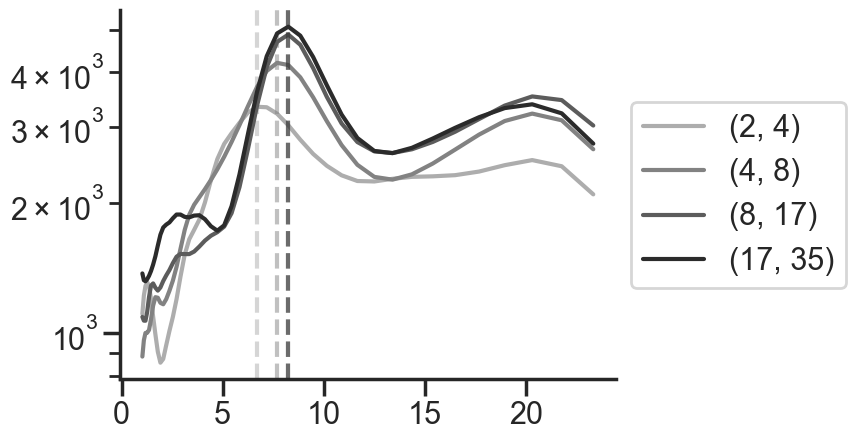

20220815_JA0181_darkHR1 13
(0, 1) 6425 6.698584140851832 0.8581860283095343
(1, 2) 1250 7.1793647187314695 1.0
(2, 4) 2250 7.694652583405727 1.0
(4, 8) 4850 7.694652583405727 1.0
(8, 17) 2225 7.694652583405727 1.0


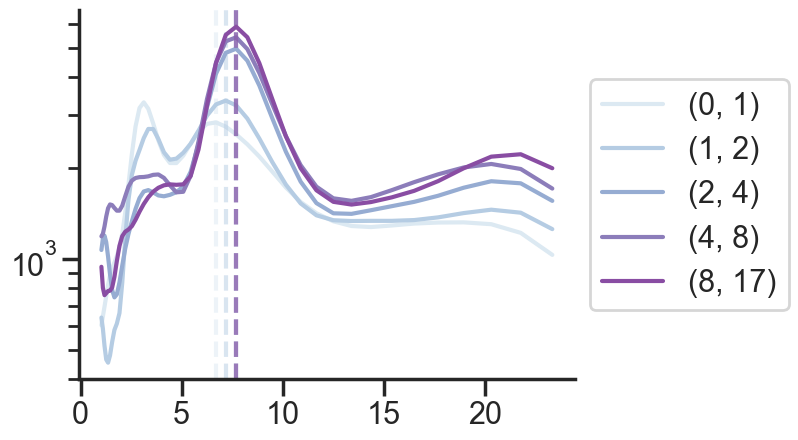

20220815_JA0181_light1 15
(2, 4) 1475 6.698584140851832 1.0
(4, 8) 3475 7.694652583405727 1.0
(8, 17) 12150 8.246924442330588 1.0
(17, 35) 6325 8.246924442330588 1.0


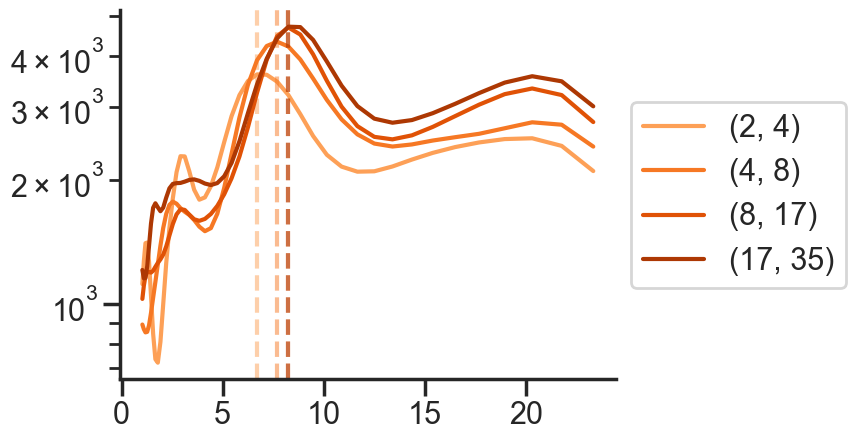

20220815_JA0181_lightHR1 16
(0, 1) 4250 6.698584140851832 1.0
(1, 2) 725 6.698584140851832 1.0
(2, 4) 775 7.694652583405727 1.0
(4, 8) 2050 7.694652583405727 1.0
(8, 17) 2075 7.694652583405727 1.0


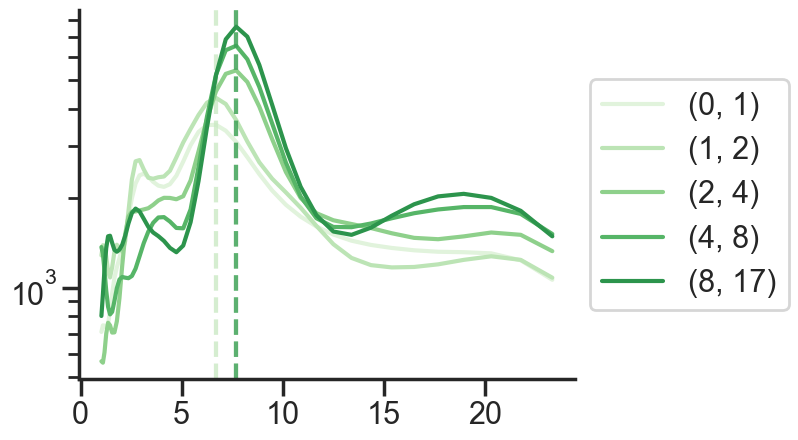

20220818_JA0181_dark1 14
(2, 4) 1125 5.076577477226473 1.0
(4, 8) 6075 7.694652583405727 1.0
(8, 17) 13575 8.246924442330588 1.0
(17, 35) 2775 8.838834764831844 1.0


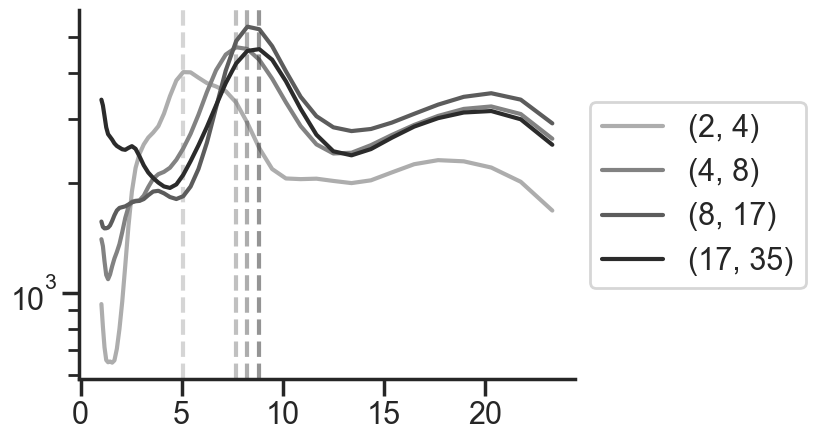

20220818_JA0181_darkHR1 0
20220818_JA0181_light1 14
(2, 4) 1775 6.698584140851832 1.0
(4, 8) 6650 7.694652583405727 1.0
(8, 17) 13825 8.838834764831844 1.0
(17, 35) 1325 8.838834764831844 1.0


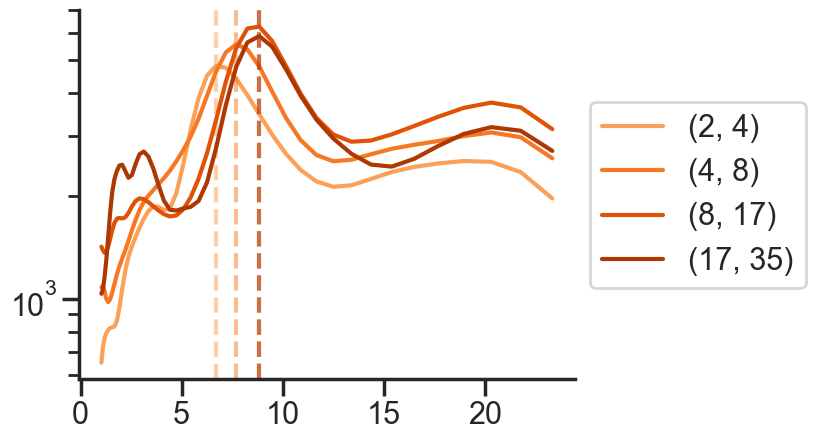

20220818_JA0181_lightHR1 14
(0, 1) 8875 7.1793647187314695 1.0
(1, 2) 725 7.1793647187314695 1.0
(2, 4) 1275 7.694652583405727 1.0
(4, 8) 1200 7.694652583405727 1.0


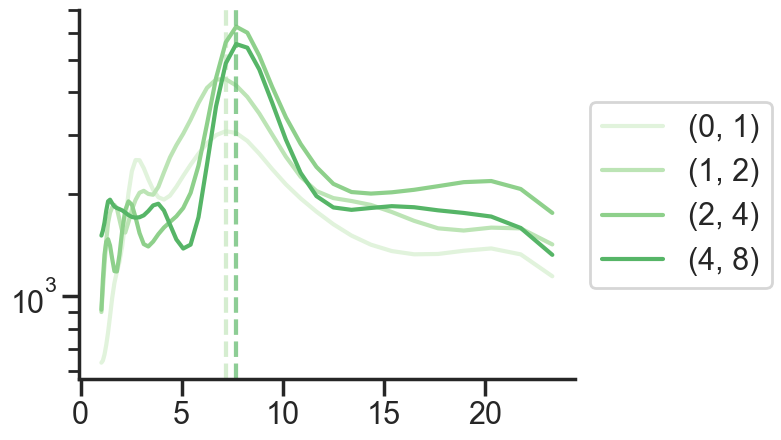

20220712_MC022_dark1 39
(2, 4) 825 8.246924442330588 1.0
(4, 8) 4300 8.246924442330588 1.0
(8, 17) 14975 8.246924442330588 1.0
(17, 35) 3475 8.838834764831844 1.0


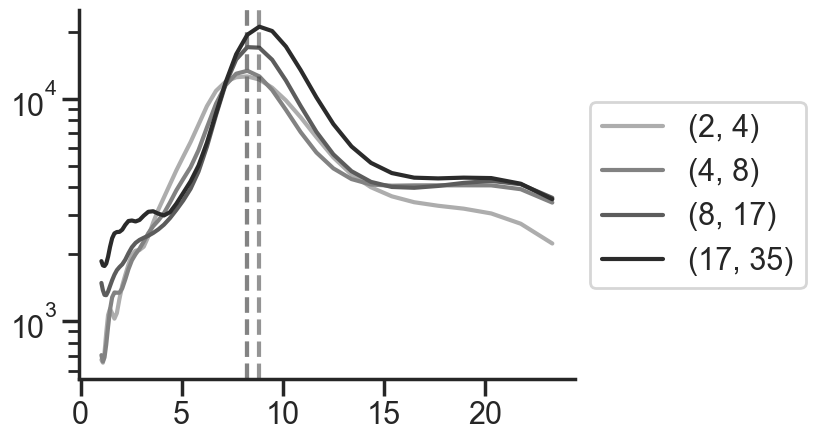

20220712_MC022_darkHR1 36
(0, 1) 5475 7.1793647187314695 1.0
(1, 2) 2075 7.1793647187314695 1.0
(2, 4) 1300 7.1793647187314695 1.0
(4, 8) 3650 7.1793647187314695 1.0
(8, 17) 3850 7.1793647187314695 1.0


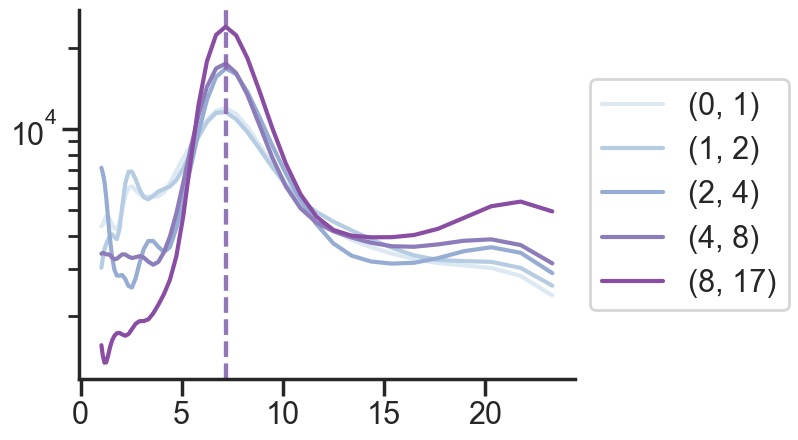

20220712_MC022_light1 39
(2, 4) 1100 6.25 1.0
(4, 8) 3600 8.246924442330588 1.0
(8, 17) 14050 8.838834764831844 1.0
(17, 35) 4850 8.838834764831844 1.0


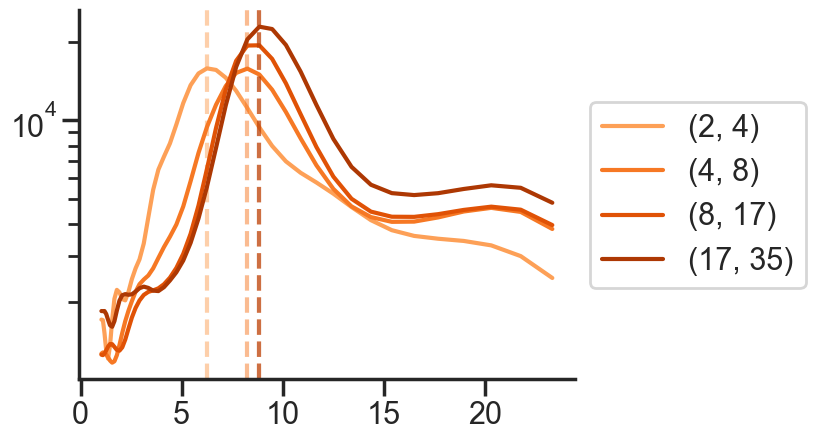

20220712_MC022_lightHR1 41
(0, 1) 2975 6.698584140851832 1.0
(1, 2) 650 6.698584140851832 1.0
(2, 4) 2300 7.1793647187314695 1.0
(4, 8) 4550 7.1793647187314695 1.0
(8, 17) 4000 7.694652583405727 1.0


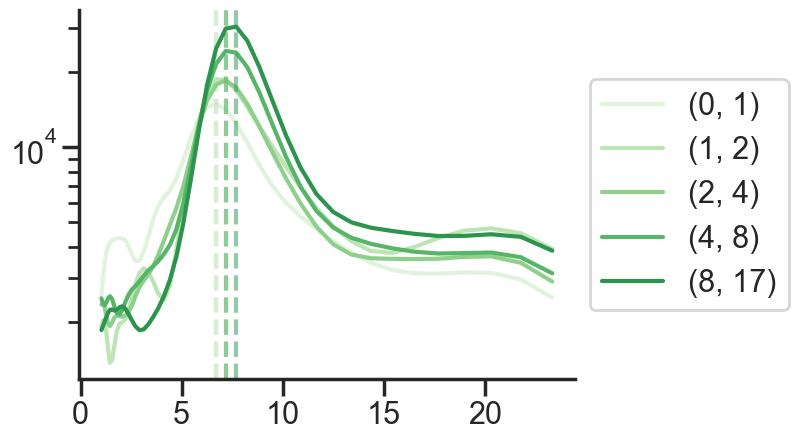

20220722_MC022_dark1 1
20220722_MC022_darkHR1 2
20220722_MC022_light1 1
20220722_MC022_lightHR1 1
20220829_MC038_dark1 0
20220829_MC038_darkHR1 4
(0, 1) 12925 6.698584140851832 1.0
(1, 2) 2050 6.698584140851832 1.0
(2, 4) 1900 7.1793647187314695 1.0
(4, 8) 3025 7.1793647187314695 1.0
(8, 17) 1600 7.1793647187314695 1.0


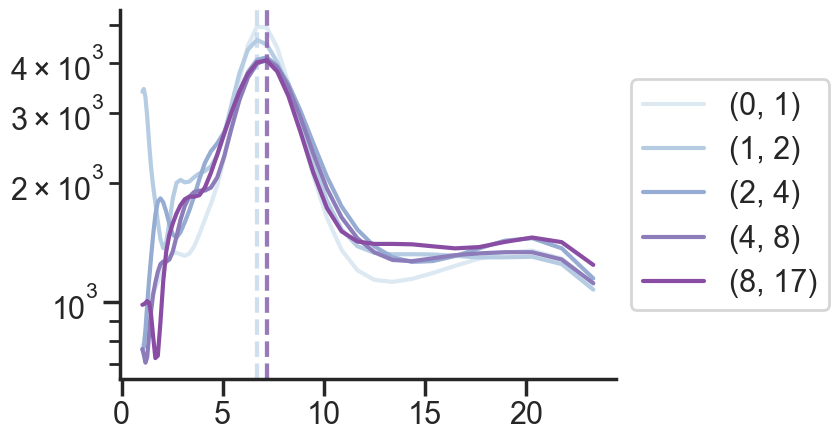

20220829_MC038_light1 0
20220829_MC038_lightHR1 5
(0, 1) 16750 7.1793647187314695 1.0
(1, 2) 2850 7.1793647187314695 1.0
(2, 4) 1250 7.1793647187314695 1.0
(4, 8) 2500 7.694652583405727 1.0


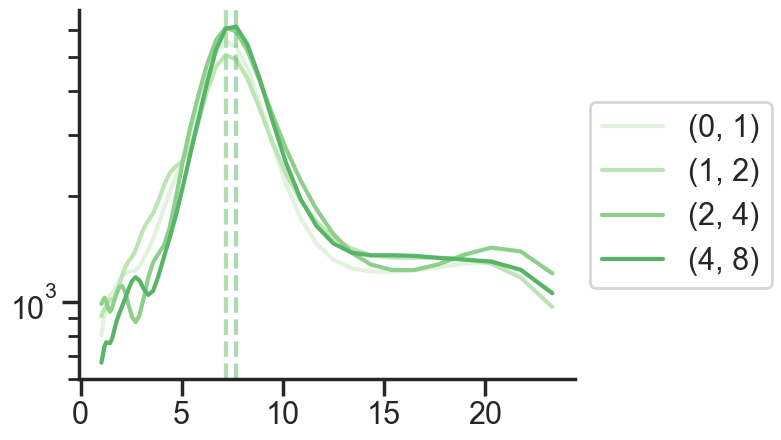

,rec_id,freq,cwt,rec_session,speed_bin,dts,theta_amp_ratio,animal_name,cond,peak_freq
0,20211207_JA0144_dark1,25.000000,10.248156,JA0144_20211207,"(0, 1)",20211207,1.0,JA0144,dark1,7.179365
1,20211207_JA0144_dark1,23.325825,15.563750,JA0144_20211207,"(0, 1)",20211207,1.0,JA0144,dark1,7.179365
2,20211207_JA0144_dark1,21.763764,22.168566,JA0144_20211207,"(0, 1)",20211207,1.0,JA0144,dark1,7.179365
3,20211207_JA0144_dark1,20.306310,31.183753,JA0144_20211207,"(0, 1)",20211207,1.0,JA0144,dark1,7.179365
4,20211207_JA0144_dark1,18.946457,44.810948,JA0144_20211207,"(0, 1)",20211207,1.0,JA0144,dark1,7.179365


In [389]:
ls_tf = []
fs_lfp = 50
gamma = 3 
beta = 10 # decrease beta to improve temporal resolution
# 0.5s window
window_size = 25
speed_bins = [(0, 1), (1, 2), (2, 4), (4, 8), (8, 17), (17, 35)]
ang_speed_bins = [(-50, -25), (-25, -12), (-12, -1), (1, 12), (12, 25), (25, 50)]

for k in d_hr_data.keys():
    
    dts, animal_name, cond = k.split('_')[-3:]
    rec_session = animal_name + '_' + dts
    data = d_hr_data[k]
    data_ephys = d_hr_data[k]['ephys']
    data_beh = d_hr_data[k]['beh']
    hdc_ephys = data_ephys[data_ephys.hdc_flag == True]
    hdc_units = hdc_ephys.cids.unique()
    
    print(k, hdc_units.size)
    if (hdc_units.size < 3):
        continue
    
    lfp = hdc_ephys.groupby('times')['lfp'].mean().values
    lfp_ts = hdc_ephys.groupby('times')['lfp'].mean().index.values
    speed = data_beh['lin_vel'].values
    # CAR LFP subract median of all channels to remove volume conducted lfp
#     med_lfp = df_hr_master_2[df_hr_master_2.rec_id == rec].groupby('times')['lfp'].median().values
#     lfp = lfp - med_lfp
    
    lin_speed = speed[:speed.size//window_size*window_size]
    lin_speed_sm = savgol_filter(lin_speed, window_length= window_size, polyorder=2)
    ang_vel = data_beh['omega'].values
    ang_vel = ang_vel[:ang_vel.size//window_size*window_size]

    chunk_mean = np.mean(lin_speed.reshape(-1, window_size), 1)
#     chunk_mean = np.mean(ang_vel.reshape(-1, window_size), 1)

    for idx, b in enumerate(speed_bins):
        lfp_chunk_ls = []
        bin_chunk = np.where((chunk_mean > b[0]) & (chunk_mean < b[1]))[0]
        # at least 10s
        if len(bin_chunk) < 20:
            continue
        for bc in bin_chunk:
            lfp_chunk_ls.append(lfp[bc*window_size : bc*window_size + window_size])
        lfp_roi = np.concatenate(lfp_chunk_ls)
        
        cwtcoefs, _, freq, cwtts, _ = gsp.cwt( lfp_roi, timestamps=lfp_ts, freq_limits=[1, 25], fs=fs_lfp,
            wavelet=gsp.MorseWavelet(gamma=gamma, beta=beta))
        cwt_power = cwtcoefs.imag**2 + cwtcoefs.real**2
        freq_idx = np.where(freq<25)[0]
        cwt_mean_pow = cwt_power.mean(axis = 1)
#         if np.isnan(cwt_mean_pow).sum() > 20:
#             continue
        
        theta_freq = np.where((freq>4) & (freq < 12))[0]
        peak_freq_idx = cwt_mean_pow[theta_freq].argmax()
        peak_freq = freq[theta_freq[0] + peak_freq_idx]
        amp_ratio = cwt_mean_pow[theta_freq].max()/cwt_mean_pow.max()
        print(b, lfp_roi.size, peak_freq, amp_ratio)
        
        plt.semilogy(freq[freq_idx], cwt_mean_pow[freq_idx], label = b, color = d_pal[cond][idx])
        plt.axvline(x = peak_freq, color = d_pal[cond][idx], ls = '--', alpha = 0.5)
#         f, Pxx_den = ssig.welch(lfp_roi, fs_lfp, nperseg = 6*fs_lfp, nfft = 2**14, noverlap = 3*fs_lfp ) # 4 seconds window
     
        ls_tf.append(pd.DataFrame({'rec_id': k, 'freq': freq, 'cwt': cwt_mean_pow, 'rec_session':rec_session,
                                   'speed_bin': [b]*freq.size, 'dts':dts, 'theta_amp_ratio': amp_ratio,
                                   'animal_name': animal_name, 'cond': cond, 'peak_freq': peak_freq }))
        
        plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))

    plt.show()
#     break
df_hr_tf = pd.concat(ls_tf)
df_hr_tf.head()

In [390]:
Mean = df_hr_tf.groupby(['rec_id', 'speed_bin']).cwt.transform('mean')    
Std = df_hr_tf.groupby(['rec_id', 'speed_bin']).cwt.transform('std')  
df_hr_tf['cwt_zscore'] = (df_hr_tf.cwt.values - Mean) / Std

In [394]:
lfp.shape

(24000,)

In [391]:
df_hr_tf.head()

,rec_id,freq,cwt,rec_session,speed_bin,dts,theta_amp_ratio,animal_name,cond,peak_freq,cwt_zscore
0,20211207_JA0144_dark1,25.000000,10.248156,JA0144_20211207,"(0, 1)",20211207,1.0,JA0144,dark1,7.179365,-0.767953
1,20211207_JA0144_dark1,23.325825,15.563750,JA0144_20211207,"(0, 1)",20211207,1.0,JA0144,dark1,7.179365,-0.758712
2,20211207_JA0144_dark1,21.763764,22.168566,JA0144_20211207,"(0, 1)",20211207,1.0,JA0144,dark1,7.179365,-0.747230
3,20211207_JA0144_dark1,20.306310,31.183753,JA0144_20211207,"(0, 1)",20211207,1.0,JA0144,dark1,7.179365,-0.731558
4,20211207_JA0144_dark1,18.946457,44.810948,JA0144_20211207,"(0, 1)",20211207,1.0,JA0144,dark1,7.179365,-0.707868


In [215]:
# df_hr_tf.to_pickle('df_hr_tf.pkl')

In [392]:
df_hr_tf.cond.unique()

array(['dark1', 'darkHR1', 'light1', 'lightHR1'], dtype=object)

JA0144


C:\Users\lab\AppData\Local\Temp\ipykernel_18196\546969595.py:14: UserWarning: The palette list has more values (6) than needed (5), which may not be intended.
  sns.lineplot(data=_inp_plot, x="freq", y=y, hue="speed_bin",


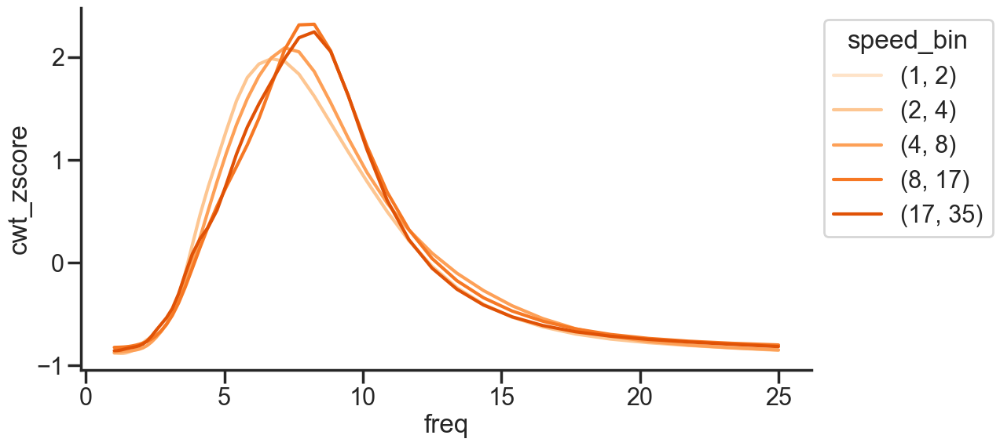

JA0153


C:\Users\lab\AppData\Local\Temp\ipykernel_18196\546969595.py:14: UserWarning: The palette list has more values (6) than needed (5), which may not be intended.
  sns.lineplot(data=_inp_plot, x="freq", y=y, hue="speed_bin",


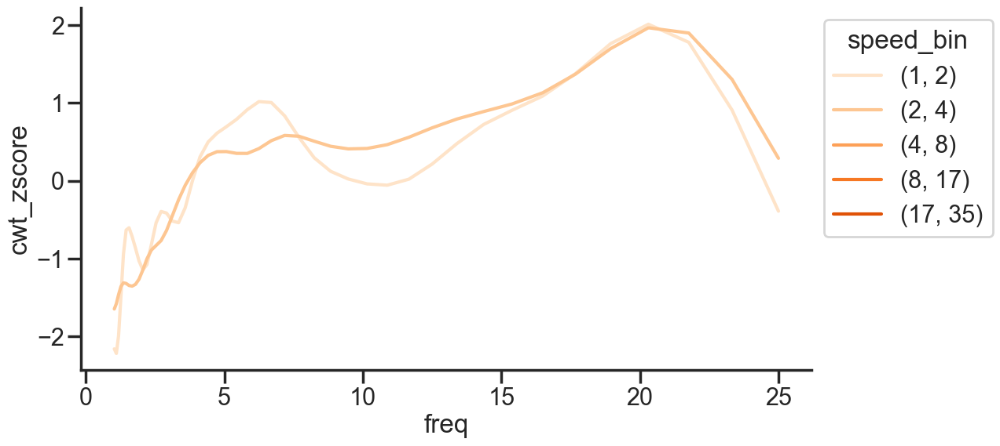

JA0162


C:\Users\lab\AppData\Local\Temp\ipykernel_18196\546969595.py:14: UserWarning: The palette list has more values (6) than needed (5), which may not be intended.
  sns.lineplot(data=_inp_plot, x="freq", y=y, hue="speed_bin",


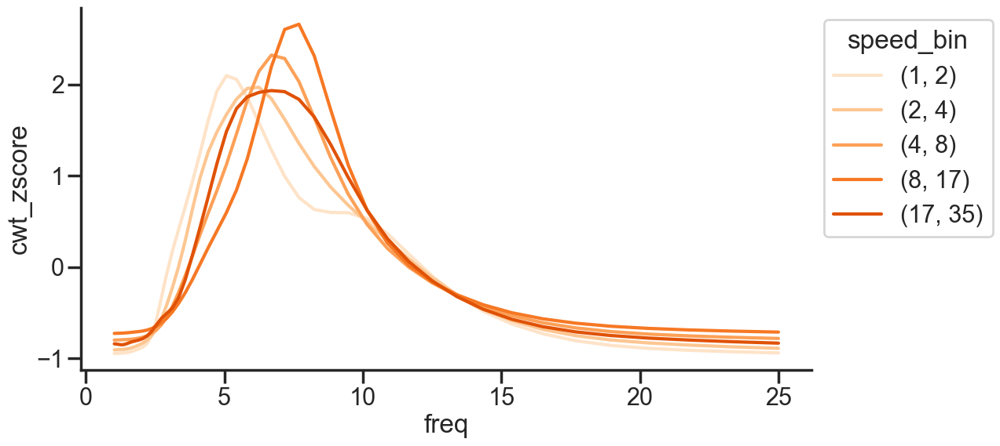

JA0164


C:\Users\lab\AppData\Local\Temp\ipykernel_18196\546969595.py:14: UserWarning: The palette list has more values (6) than needed (5), which may not be intended.
  sns.lineplot(data=_inp_plot, x="freq", y=y, hue="speed_bin",


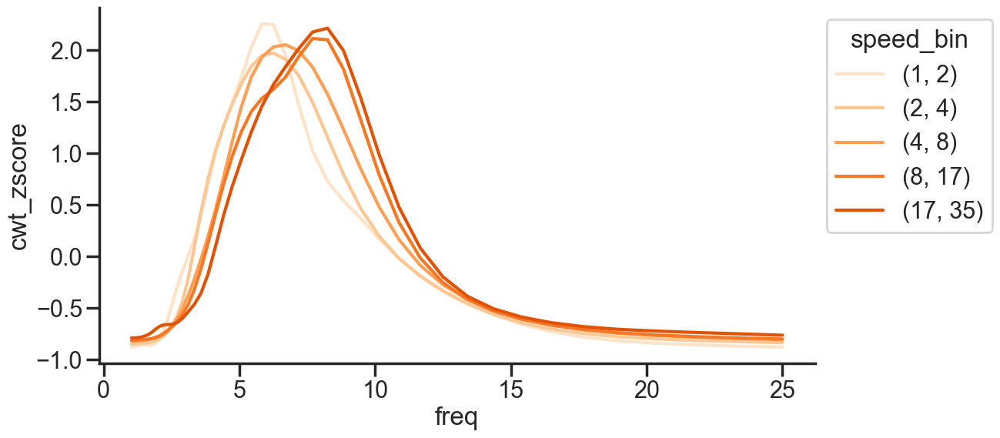

JA0178


C:\Users\lab\AppData\Local\Temp\ipykernel_18196\546969595.py:14: UserWarning: The palette list has more values (6) than needed (5), which may not be intended.
  sns.lineplot(data=_inp_plot, x="freq", y=y, hue="speed_bin",


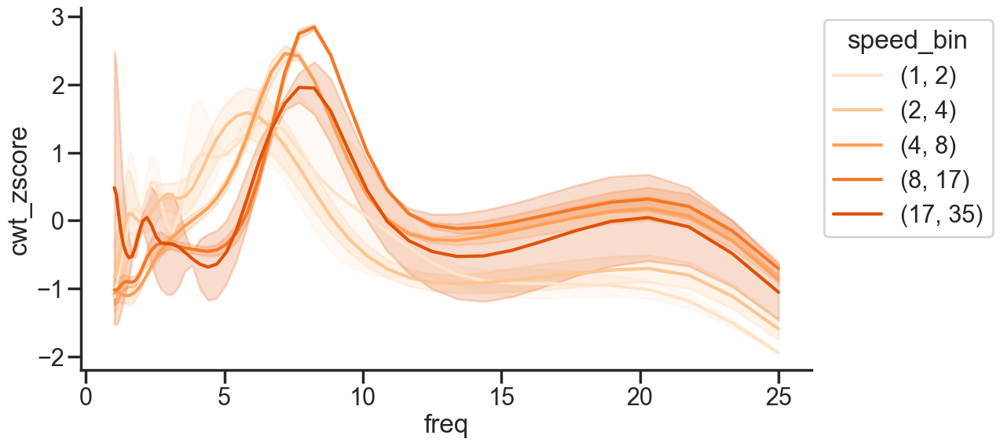

JA0181


C:\Users\lab\AppData\Local\Temp\ipykernel_18196\546969595.py:14: UserWarning: The palette list has more values (6) than needed (5), which may not be intended.
  sns.lineplot(data=_inp_plot, x="freq", y=y, hue="speed_bin",


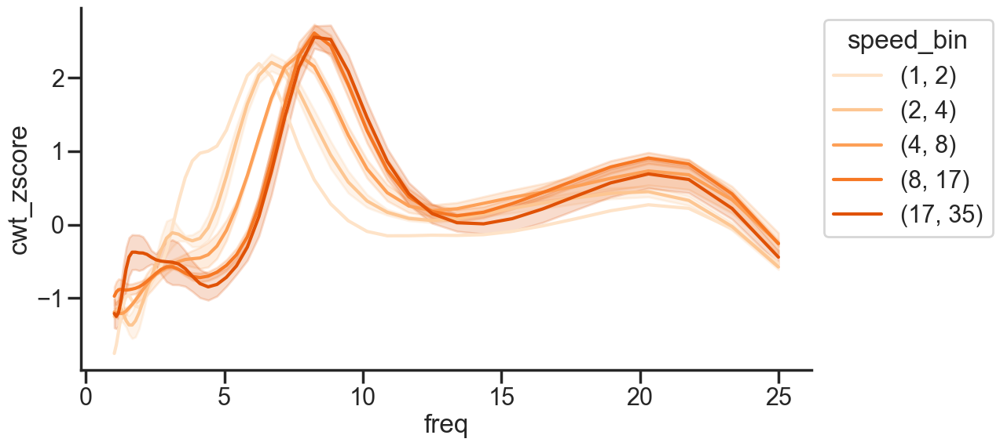

MC022


C:\Users\lab\AppData\Local\Temp\ipykernel_18196\546969595.py:14: UserWarning: The palette list has more values (6) than needed (5), which may not be intended.
  sns.lineplot(data=_inp_plot, x="freq", y=y, hue="speed_bin",


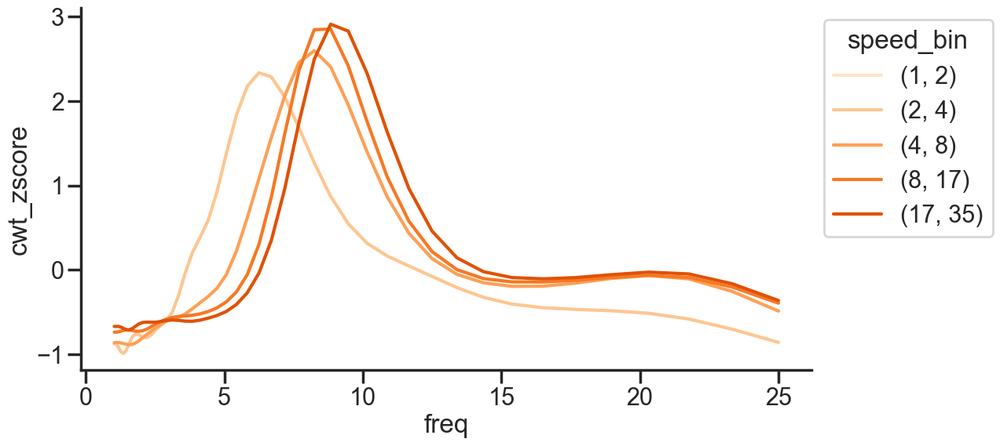

In [393]:
cond = 'light1'
data = df_hr_tf
y = 'cwt_zscore'
_inp_data = data[(data.theta_amp_ratio > 0.7) 
                  & (data.cond == cond) 
                  & (data.speed_bin != (0, 1))]

for m in _inp_data.animal_name.unique():
    print (m)
    f, ax = plt.subplots(figsize=(12, 6))
#     ax.set( yscale="log")

    _inp_plot = _inp_data[(_inp_data.animal_name == m)].dropna()
    sns.lineplot(data=_inp_plot, x="freq", y=y, hue="speed_bin", 
                 hue_order = [(1, 2), (2, 4), (4, 8), (8, 17), (17, 35)], 
                 errorbar=('se', 1), palette = d_pal[cond], ax = ax)
    sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
    plt.show()
# plt.savefig(f'MC022_thetapow_speed_{cond}.pdf', transparent=True)

C:\Users\lab\AppData\Local\Temp\ipykernel_11956\1282412145.py:13: UserWarning: The palette list has more values (6) than needed (5), which may not be intended.
  sns.lineplot(data=_inp_plot, x="freq", y=y, hue="speed_bin",


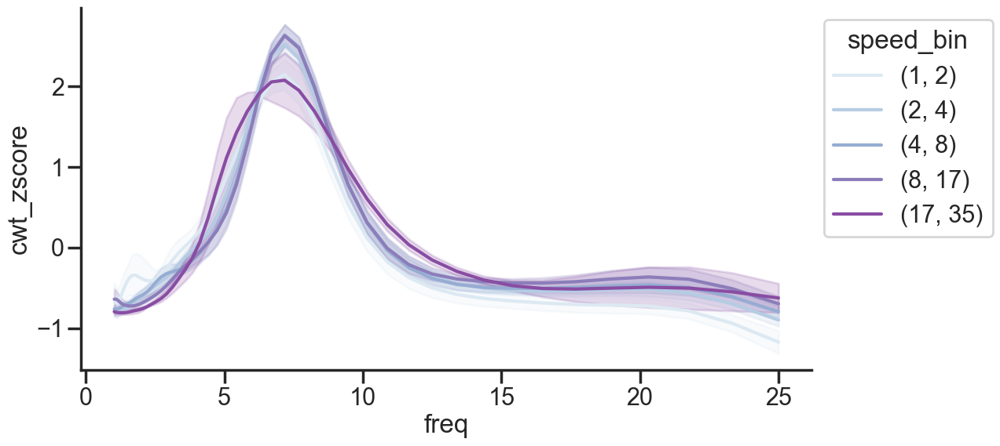

In [36]:
data = df_hr_tf
cond = 'darkHR1'
y = 'cwt_zscore'

_inp_data = data[(data.theta_amp_ratio > 0.7) 
                  & (data.cond == cond) 
                  & (data.speed_bin != (0, 1))]

f, ax = plt.subplots(figsize=(12, 6))
# ax.set( yscale="log")

_inp_plot = _inp_data
sns.lineplot(data=_inp_plot, x="freq", y=y, hue="speed_bin", 
             hue_order = [(1, 2), (2, 4), (4, 8), (8, 17), (17, 35)], 
             errorbar=('se', 1), palette = d_pal[cond], ax = ax)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))

# plt.savefig(f'line_hr_tf_{cond}_{y}.pdf', transparent=True)

(array([0, 1, 2, 3]),
 [Text(0, 0, '(1, 2)'),
  Text(1, 0, '(2, 4)'),
  Text(2, 0, '(4, 8)'),
  Text(3, 0, '(8, 17)')])

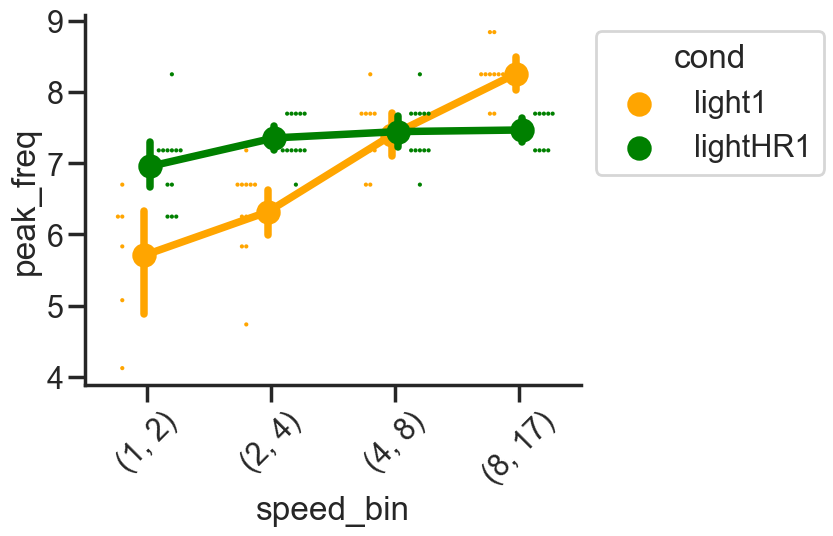

In [462]:
y = 'peak_freq'
coi = ['light1', 'lightHR1']; pal = ['orange', 'green']
# coi = ['dark1', 'darkHR1']; pal = ['grey', 'brown']

data = df_hr_tf[(df_hr_tf.cond.isin(coi))]
cond_ls = data.cond.unique()

_inp_plot = data[(data.cond.isin(cond_ls)) 
                  & (data.theta_amp_ratio > 0.7) 
                  & (data.speed_bin != (0, 1))
                  & (data.freq > 4) 
                  & (data.freq < 12) ].groupby(['cond','rec_session', 'rec_id', 'speed_bin'])[y].max().reset_index()

_inp_plot['speed_bin'] = _inp_plot['speed_bin'].astype('str')
plot = sns.swarmplot(data = _inp_plot, x = 'speed_bin', y = y, hue = 'cond', 
                     order = ['(1, 2)', '(2, 4)', '(4, 8)', '(8, 17)', ],
                     legend = False, dodge = True, size = 3, 
                     palette = pal)

sns.pointplot(data = _inp_plot, x = 'speed_bin', y = y, hue = 'cond', 
              palette = pal,
              order = ['(1, 2)', '(2, 4)', '(4, 8)', '(8, 17)', ],
              dodge = True)

sns.move_legend(plot, "upper left", bbox_to_anchor=(1, 1))
plt.xticks(rotation = 45)
# plt.savefig(f'point_hr_speed_{y}_{coi}.pdf', transparent=True)

In [463]:
_inp_plot.groupby(['speed_bin', 'cond']).describe()

peak_freq                                          \
                       count      mean       std       min       25%   
speed_bin cond                                                         
(1, 2)    light1         6.0  5.705013  0.947990  4.123462  5.265297   
          lightHR1      12.0  6.955857  0.571574  6.250000  6.586438   
(17, 35)  light1         9.0  8.145059  0.643204  6.698584  8.246924   
          lightHR1       1.0  7.179365       NaN  7.179365  7.179365   
(2, 4)    light1        12.0  6.318484  0.636344  4.736614  6.145364   
          lightHR1      12.0  7.354003  0.329293  6.698584  7.179365   
(4, 8)    light1        10.0  7.396080  0.493785  6.698584  7.179365   
          lightHR1      12.0  7.442966  0.411716  6.698584  7.179365   
(8, 17)   light1        10.0  8.254852  0.381531  7.694653  8.246924   
          lightHR1       9.0  7.465636  0.271581  7.179365  7.179365   

                                                  
                         50%       75%       max  
speed_bin cond                                    
(1, 2)    light1    6.040728  6.250000  6.698584  
          lightHR1  7.179365  7.179365  8.246924  
(17, 35)  light1    8.246924  8.246924  8.838835  
          lightHR1  7.179365  7.179365  7.179365  
(2, 4)    light1    6.474292  6.698584  7.179365  
          lightHR1  7.179365  7.694653  7.694653  
(4, 8)    light1    7.437009  7.694653  8.246924  
          lightHR1  7.437009  7.694653  8.246924  
(8, 17)   light1    8.246924  8.246924  8.838835  
          lightHR1  7.694653  7.694653  7.694653

In [465]:
for cond in cond_ls:
    print(cond)
    a1 = _inp_plot[(_inp_plot.speed_bin == '(1, 2)') & (_inp_plot.cond == cond)][y]
    a2 = _inp_plot[(_inp_plot.speed_bin == '(2, 4)') & (_inp_plot.cond == cond)][y]
    a3 = _inp_plot[(_inp_plot.speed_bin == '(4, 8)') & (_inp_plot.cond == cond)][y]
    a4 = _inp_plot[(_inp_plot.speed_bin == '(8, 17)') & (_inp_plot.cond == cond)][y]

    print(stats.kruskal(a1, a2, a3, a4))

light1
KruskalResult(statistic=29.546683092544914, pvalue=1.7188174015825663e-06)
lightHR1
KruskalResult(statistic=9.140426074754403, pvalue=0.027480950272657897)


In [458]:
pvals = []
for sb in speed_bins[1:-1]:
    print(sb)
    a1 = _inp_plot[(_inp_plot.speed_bin == str(sb)) & (_inp_plot.cond == coi[0])][y]
    b1 = _inp_plot[(_inp_plot.speed_bin == str(sb)) & (_inp_plot.cond == coi[1])][y]
    st, pval = stats.mannwhitneyu(a1, b1)
    pvals.append(pval)
    print(st, pval)
print('Benjamini/Hochberg (non-negative)')
print(multipletests(pvals, alpha=0.05, method='fdr_bh'))

(1, 2)
16.0 0.034069195144143936
(2, 4)
16.0 0.007698627281707499
(4, 8)
26.0 0.08056875653563067
(8, 17)
32.0 0.47992869214595724
Benjamini/Hochberg (non-negative)
(array([False,  True, False, False]), array([0.06813839, 0.03079451, 0.10742501, 0.47992869]), 0.012741455098566168, 0.0125)


In [394]:
lfp.shape

(24000,)

In [391]:
df_hr_tf.head()

,rec_id,freq,cwt,rec_session,speed_bin,dts,theta_amp_ratio,animal_name,cond,peak_freq,cwt_zscore
0,20211207_JA0144_dark1,25.000000,10.248156,JA0144_20211207,"(0, 1)",20211207,1.0,JA0144,dark1,7.179365,-0.767953
1,20211207_JA0144_dark1,23.325825,15.563750,JA0144_20211207,"(0, 1)",20211207,1.0,JA0144,dark1,7.179365,-0.758712
2,20211207_JA0144_dark1,21.763764,22.168566,JA0144_20211207,"(0, 1)",20211207,1.0,JA0144,dark1,7.179365,-0.747230
3,20211207_JA0144_dark1,20.306310,31.183753,JA0144_20211207,"(0, 1)",20211207,1.0,JA0144,dark1,7.179365,-0.731558
4,20211207_JA0144_dark1,18.946457,44.810948,JA0144_20211207,"(0, 1)",20211207,1.0,JA0144,dark1,7.179365,-0.707868


In [215]:
# df_hr_tf.to_pickle('df_hr_tf.pkl')

In [392]:
df_hr_tf.cond.unique()

array(['dark1', 'darkHR1', 'light1', 'lightHR1'], dtype=object)

JA0144


C:\Users\lab\AppData\Local\Temp\ipykernel_18196\546969595.py:14: UserWarning: The palette list has more values (6) than needed (5), which may not be intended.
  sns.lineplot(data=_inp_plot, x="freq", y=y, hue="speed_bin",


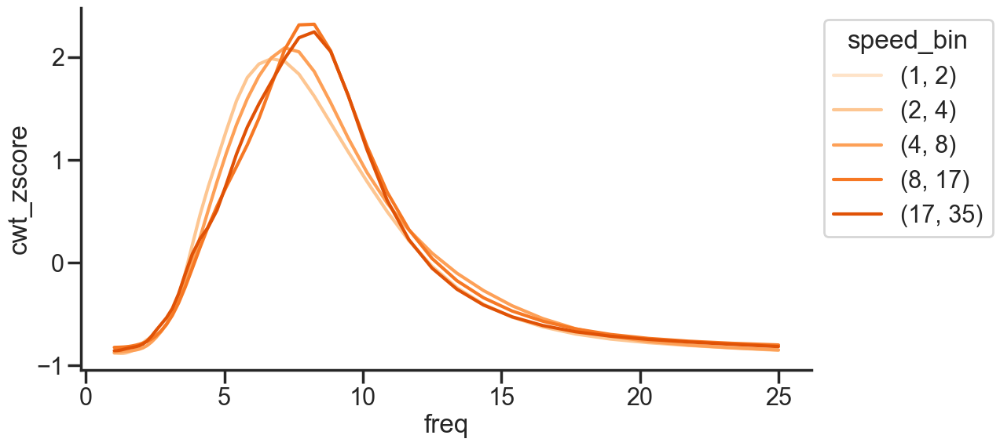

JA0153


C:\Users\lab\AppData\Local\Temp\ipykernel_18196\546969595.py:14: UserWarning: The palette list has more values (6) than needed (5), which may not be intended.
  sns.lineplot(data=_inp_plot, x="freq", y=y, hue="speed_bin",


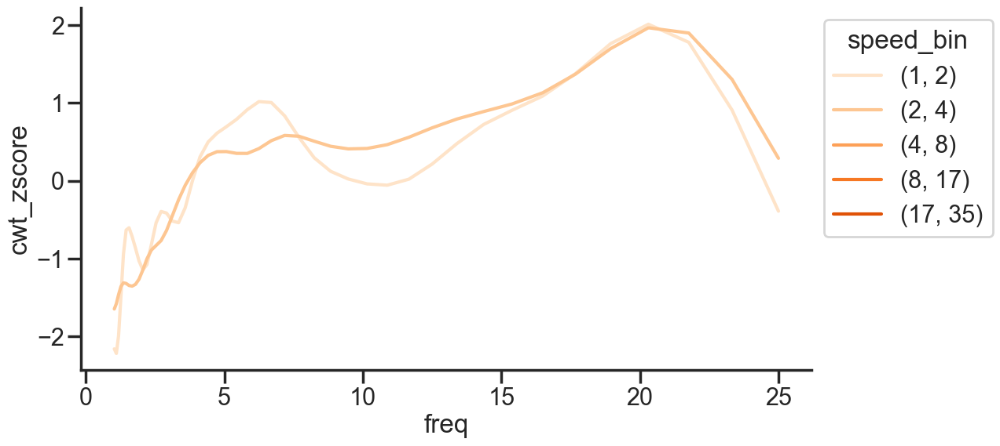

JA0162


C:\Users\lab\AppData\Local\Temp\ipykernel_18196\546969595.py:14: UserWarning: The palette list has more values (6) than needed (5), which may not be intended.
  sns.lineplot(data=_inp_plot, x="freq", y=y, hue="speed_bin",


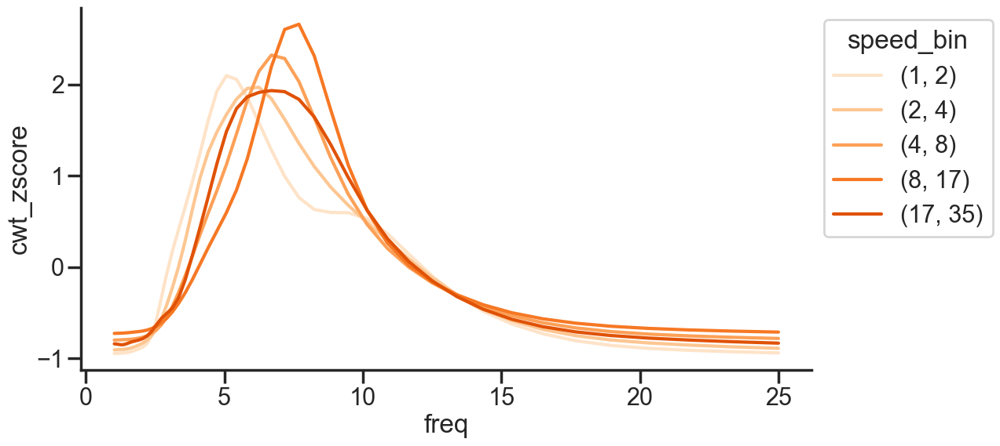

JA0164


C:\Users\lab\AppData\Local\Temp\ipykernel_18196\546969595.py:14: UserWarning: The palette list has more values (6) than needed (5), which may not be intended.
  sns.lineplot(data=_inp_plot, x="freq", y=y, hue="speed_bin",


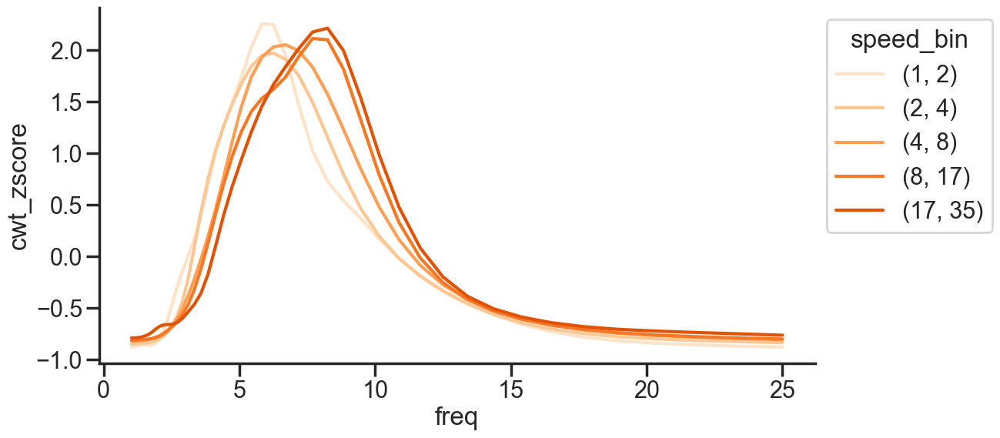

JA0178


C:\Users\lab\AppData\Local\Temp\ipykernel_18196\546969595.py:14: UserWarning: The palette list has more values (6) than needed (5), which may not be intended.
  sns.lineplot(data=_inp_plot, x="freq", y=y, hue="speed_bin",


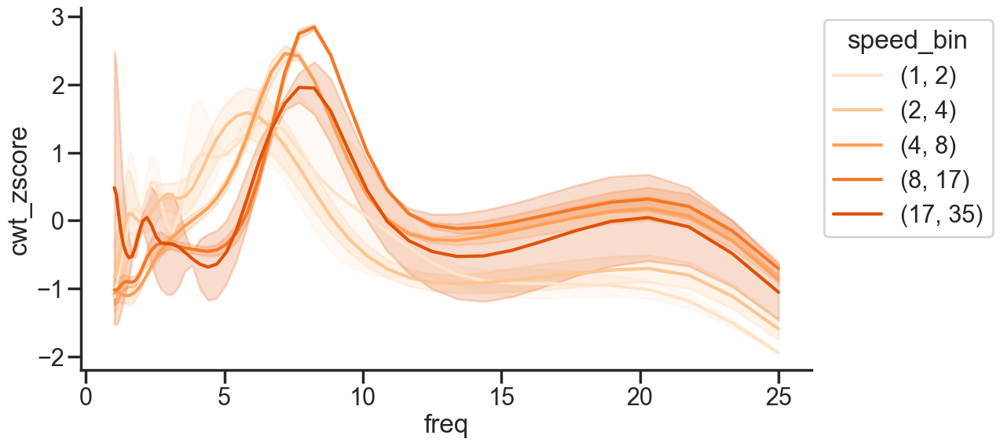

JA0181


C:\Users\lab\AppData\Local\Temp\ipykernel_18196\546969595.py:14: UserWarning: The palette list has more values (6) than needed (5), which may not be intended.
  sns.lineplot(data=_inp_plot, x="freq", y=y, hue="speed_bin",


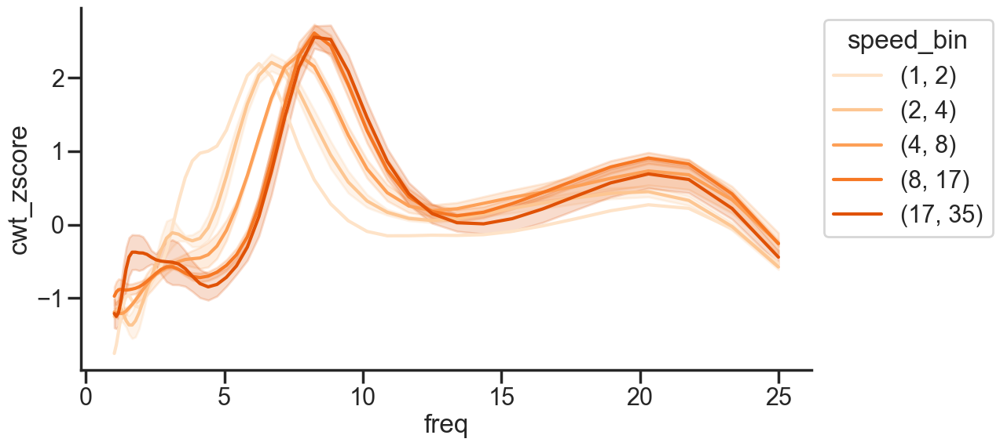

MC022


C:\Users\lab\AppData\Local\Temp\ipykernel_18196\546969595.py:14: UserWarning: The palette list has more values (6) than needed (5), which may not be intended.
  sns.lineplot(data=_inp_plot, x="freq", y=y, hue="speed_bin",


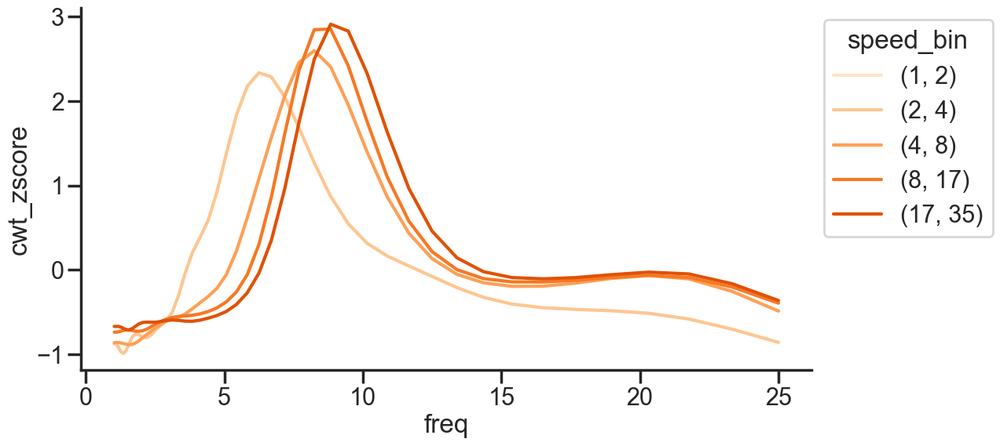

In [393]:
cond = 'light1'
data = df_hr_tf
y = 'cwt_zscore'
_inp_data = data[(data.theta_amp_ratio > 0.7) 
                  & (data.cond == cond) 
                  & (data.speed_bin != (0, 1))]

for m in _inp_data.animal_name.unique():
    print (m)
    f, ax = plt.subplots(figsize=(12, 6))
#     ax.set( yscale="log")

    _inp_plot = _inp_data[(_inp_data.animal_name == m)].dropna()
    sns.lineplot(data=_inp_plot, x="freq", y=y, hue="speed_bin", 
                 hue_order = [(1, 2), (2, 4), (4, 8), (8, 17), (17, 35)], 
                 errorbar=('se', 1), palette = d_pal[cond], ax = ax)
    sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
    plt.show()
# plt.savefig(f'MC022_thetapow_speed_{cond}.pdf', transparent=True)

C:\Users\lab\AppData\Local\Temp\ipykernel_11956\1282412145.py:13: UserWarning: The palette list has more values (6) than needed (5), which may not be intended.
  sns.lineplot(data=_inp_plot, x="freq", y=y, hue="speed_bin",


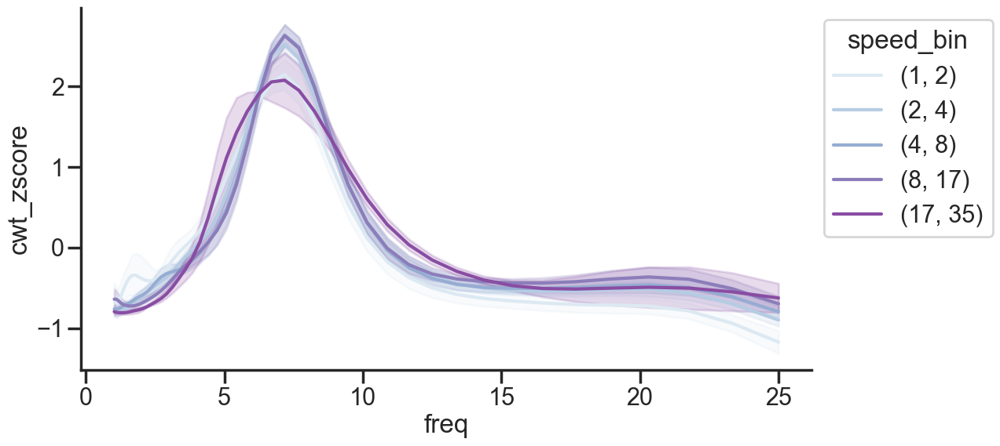

In [36]:
data = df_hr_tf
cond = 'darkHR1'
y = 'cwt_zscore'

_inp_data = data[(data.theta_amp_ratio > 0.7) 
                  & (data.cond == cond) 
                  & (data.speed_bin != (0, 1))]

f, ax = plt.subplots(figsize=(12, 6))
# ax.set( yscale="log")

_inp_plot = _inp_data
sns.lineplot(data=_inp_plot, x="freq", y=y, hue="speed_bin", 
             hue_order = [(1, 2), (2, 4), (4, 8), (8, 17), (17, 35)], 
             errorbar=('se', 1), palette = d_pal[cond], ax = ax)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))

# plt.savefig(f'line_hr_tf_{cond}_{y}.pdf', transparent=True)

(array([0, 1, 2, 3]),
 [Text(0, 0, '(1, 2)'),
  Text(1, 0, '(2, 4)'),
  Text(2, 0, '(4, 8)'),
  Text(3, 0, '(8, 17)')])

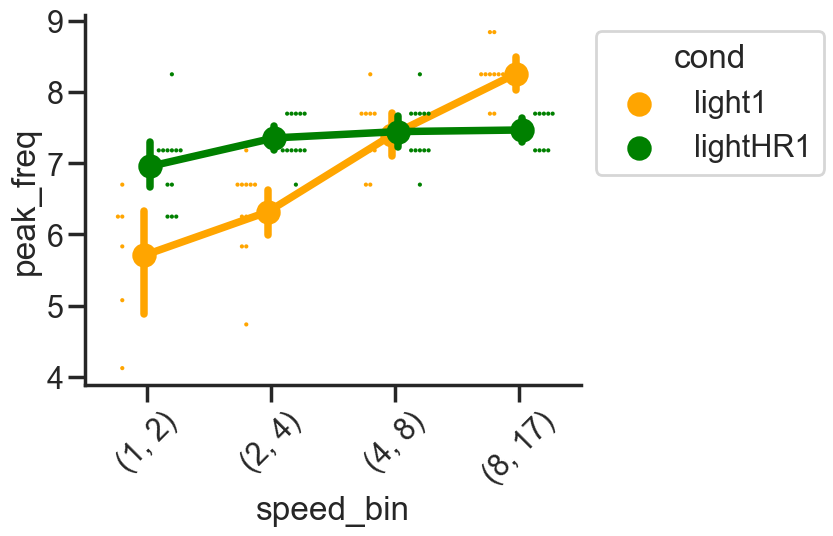

In [462]:
y = 'peak_freq'
coi = ['light1', 'lightHR1']; pal = ['orange', 'green']
# coi = ['dark1', 'darkHR1']; pal = ['grey', 'brown']

data = df_hr_tf[(df_hr_tf.cond.isin(coi))]
cond_ls = data.cond.unique()

_inp_plot = data[(data.cond.isin(cond_ls)) 
                  & (data.theta_amp_ratio > 0.7) 
                  & (data.speed_bin != (0, 1))
                  & (data.freq > 4) 
                  & (data.freq < 12) ].groupby(['cond','rec_session', 'rec_id', 'speed_bin'])[y].max().reset_index()

_inp_plot['speed_bin'] = _inp_plot['speed_bin'].astype('str')
plot = sns.swarmplot(data = _inp_plot, x = 'speed_bin', y = y, hue = 'cond', 
                     order = ['(1, 2)', '(2, 4)', '(4, 8)', '(8, 17)', ],
                     legend = False, dodge = True, size = 3, 
                     palette = pal)

sns.pointplot(data = _inp_plot, x = 'speed_bin', y = y, hue = 'cond', 
              palette = pal,
              order = ['(1, 2)', '(2, 4)', '(4, 8)', '(8, 17)', ],
              dodge = True)

sns.move_legend(plot, "upper left", bbox_to_anchor=(1, 1))
plt.xticks(rotation = 45)
# plt.savefig(f'point_hr_speed_{y}_{coi}.pdf', transparent=True)

In [463]:
_inp_plot.groupby(['speed_bin', 'cond']).describe()

peak_freq                                          \
                       count      mean       std       min       25%   
speed_bin cond                                                         
(1, 2)    light1         6.0  5.705013  0.947990  4.123462  5.265297   
          lightHR1      12.0  6.955857  0.571574  6.250000  6.586438   
(17, 35)  light1         9.0  8.145059  0.643204  6.698584  8.246924   
          lightHR1       1.0  7.179365       NaN  7.179365  7.179365   
(2, 4)    light1        12.0  6.318484  0.636344  4.736614  6.145364   
          lightHR1      12.0  7.354003  0.329293  6.698584  7.179365   
(4, 8)    light1        10.0  7.396080  0.493785  6.698584  7.179365   
          lightHR1      12.0  7.442966  0.411716  6.698584  7.179365   
(8, 17)   light1        10.0  8.254852  0.381531  7.694653  8.246924   
          lightHR1       9.0  7.465636  0.271581  7.179365  7.179365   

                                                  
                         50%       75%       max  
speed_bin cond                                    
(1, 2)    light1    6.040728  6.250000  6.698584  
          lightHR1  7.179365  7.179365  8.246924  
(17, 35)  light1    8.246924  8.246924  8.838835  
          lightHR1  7.179365  7.179365  7.179365  
(2, 4)    light1    6.474292  6.698584  7.179365  
          lightHR1  7.179365  7.694653  7.694653  
(4, 8)    light1    7.437009  7.694653  8.246924  
          lightHR1  7.437009  7.694653  8.246924  
(8, 17)   light1    8.246924  8.246924  8.838835  
          lightHR1  7.694653  7.694653  7.694653

In [465]:
for cond in cond_ls:
    print(cond)
    a1 = _inp_plot[(_inp_plot.speed_bin == '(1, 2)') & (_inp_plot.cond == cond)][y]
    a2 = _inp_plot[(_inp_plot.speed_bin == '(2, 4)') & (_inp_plot.cond == cond)][y]
    a3 = _inp_plot[(_inp_plot.speed_bin == '(4, 8)') & (_inp_plot.cond == cond)][y]
    a4 = _inp_plot[(_inp_plot.speed_bin == '(8, 17)') & (_inp_plot.cond == cond)][y]

    print(stats.kruskal(a1, a2, a3, a4))

light1
KruskalResult(statistic=29.546683092544914, pvalue=1.7188174015825663e-06)
lightHR1
KruskalResult(statistic=9.140426074754403, pvalue=0.027480950272657897)


In [458]:
pvals = []
for sb in speed_bins[1:-1]:
    print(sb)
    a1 = _inp_plot[(_inp_plot.speed_bin == str(sb)) & (_inp_plot.cond == coi[0])][y]
    b1 = _inp_plot[(_inp_plot.speed_bin == str(sb)) & (_inp_plot.cond == coi[1])][y]
    st, pval = stats.mannwhitneyu(a1, b1)
    pvals.append(pval)
    print(st, pval)
print('Benjamini/Hochberg (non-negative)')
print(multipletests(pvals, alpha=0.05, method='fdr_bh'))

(1, 2)
16.0 0.034069195144143936
(2, 4)
16.0 0.007698627281707499
(4, 8)
26.0 0.08056875653563067
(8, 17)
32.0 0.47992869214595724
Benjamini/Hochberg (non-negative)
(array([False,  True, False, False]), array([0.06813839, 0.03079451, 0.10742501, 0.47992869]), 0.012741455098566168, 0.0125)
